# Pneumonia Chest X-Ray Classification

**PRAICP-1012 · Standalone research notebook · Dual technical and client narrative**

## Executive Summary

**What problem were we solving?** Pneumonia-labelled X-rays must be identified while keeping unnecessary alerts manageable. The active research goal is at least 97% sensitivity, aiming 99%, and no more than 15% false positives among NORMAL images, preferably 10%.

**What did we do?** We audited uploaded archives, removed exact redundant training copies, used conservative proxy groups, trained a custom CNN and transfer-learning models, and retained sensitivity, ensemble, appearance and RAD-DINO experiments. Later experiments used only existing images and permitted public pretrained weights.

**What did we find?** The original frozen evaluation caught 389 of 390 pneumonia cases but falsely flagged 147 of 234 normal images. A later RAD-DINO CLS neural-head setting catches 99.23% with 14.53% false positives on that already-used benchmark; pooled development rates are 97.66% and 4.46%.

**What does it mean for the client?** The promising alternative avoids 113 of the original false alerts, at the cost of 2 additional missed pneumonia-labelled images in the exposed cohort. These are useful research trade-offs, not evidence for autonomous medical use.

**What should be done next?** Assess the candidate's stability across seeds and proxy-group folds, then consider native-resolution or anatomical-view experiments using the same images. Keep the benchmark explicitly exploratory.

**What are the main limitations?** One development fold reaches only 96.53% sensitivity; the alternative was highlighted after benchmark review. Actual patient identities and clinical labels were not adjudicated, and no fresh independent evaluation cohort exists.

### Problem Statement

The practical problem is a trade-off between missed pneumonia-labelled cases and unnecessary flags on NORMAL images. The unit observed is an image; the decision concerns an image-level research classification, not a confirmed patient diagnosis.

### Project Objectives

- Establish trustworthy image counts, labels, duplicate handling and split boundaries.
- Compare a transparent baseline and meaningful learned representations.
- Prioritize pneumonia sensitivity while measuring the NORMAL false-positive rate separately.
- Investigate transfer failures, uncertainty, error patterns and computation without hiding failed experiments.
- Deliver an auditable, dataset-only-input notebook with a client-readable conclusion.

### Environment, Data Sources, and Reproducibility Contract

**Purpose.** Separate historical evidence review from a new training run and state every required input.

**Method.** Imports and configuration are centralized below. Tables, figures, manifests, predictions, protocols and readable modeling source are embedded. Default Run All validates this evidence and recomputes metrics without companion files or deep-learning model loading.

**Inputs for fresh training.** Supply the original dataset images or ZIPs; install the declared scientific/deep-learning libraries and allow public pretrained-weight downloads. The notebook creates its own isolated working files. An expensive complete training replay was not repeated solely for restructuring.

### Research Boundary / Scope

The original development work preceded its frozen benchmark evaluation. Later false-alert, ensemble, remediation and RAD-DINO work occurred after benchmark exposure and is placed in a separate **post-evaluation exploratory research** section. No new patient images are introduced.

The retained finalized pipeline is the original frozen artifact. RAD-DINO CLS is a research alternative; it is not silently promoted to a prospective final winner. Model-file serialization/timing checks are recorded historical evidence in review mode. The live trained estimator is not claimed to be loaded when only saved predictions are reviewed.

### Reading the measures

- **Sensitivity / recall:** the fraction of provided pneumonia images correctly flagged.
- **False-positive rate (FPR):** the fraction of provided NORMAL images incorrectly flagged.
- **Precision:** the fraction of flagged images whose provided label is pneumonia.
- **False negative (FN) / false positive (FP):** a missed pneumonia image / an unnecessary alert on a normal image.
- **Calibration threshold:** a score cutoff chosen using designated calibration records; this does not prove clinical probability calibration.
- **Outer fold:** a group-separated assessment portion excluded from fitting and calibration in that comparison.
- **Proxy group:** a conservative filename/similarity link; it is not a verified patient identity.
- **AUC:** a ranking summary across cutoffs; a high AUC alone does not guarantee the required missed-case and alert rates.

In [1]:
import os, sys, io, json, hashlib, base64, lzma, zipfile, platform, tempfile, subprocess, shutil, struct
from pathlib import Path
from collections import defaultdict
from types import MappingProxyType
import numpy as np
import pandas as pd
from PIL import Image as PILImage
from scipy.stats import beta
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage
CONFIG=MappingProxyType({
    "seed":42,"run_fresh_training":False,"dataset_input":None,
    "minimum_sensitivity":.97,"desired_sensitivity":.99,"maximum_FPR":.15,"preferred_FPR":.10,
    "review_mode":"embedded historical evidence with independent metric recomputation",
    "fresh_weight_downloads":"declared public pretrained weights only; no new patient images"
})
np.random.seed(CONFIG["seed"])
pd.set_option("display.max_columns",20)
print("Python:",platform.python_version())
display(pd.Series(dict(CONFIG)).to_frame("central_configuration"))

Python: 3.12.14


,central_configuration
seed,42
run_fresh_training,False
dataset_input,None
minimum_sensitivity,0.97
desired_sensitivity,0.99
maximum_FPR,0.15
preferred_FPR,0.1
review_mode,embedded historical evidence with independent ...
fresh_weight_downloads,declared public pretrained weights only; no ne...


In [2]:
_EMBEDDED_ZIP_B64 = '...'
_EMBEDDED_ZIP_SHA256 = '6d548c1f8dfd1f11fd60a7e2725f76d01bf6b27aef3f6d6670bf7a90a6d38b7d'
_EMBEDDED_SHA256 = {'MILESTONE_STATUS.json': '498d4d306031145711c691a71e039f6858bf8c9a1f2e5b2ef8fbc6abe5a52de1', 'README.md': 'c43da05225907658d33c05ea34a434251819f8a64ad6ba6f0b022f72a50a78e9', 'data/audit/AUDIT_REPORT.md': '69cf333c2c17f62f2179584cf97cb4035e75f6eb2c8568c234bf9d83d2a26308', 'data/audit/duplicates.json': '6e84fe619bbd9f307407a3f46e18164f0c1c992816f02bf6c3f0751fc3fb7ad4', 'data/audit/image_manifest.csv': '9127fb85dafd3c743e1d061b78ea09ca3cd5b8e00911364911182b37045e5bc4', 'data/audit/summary.json': 'caeb4abda79eb843e2eb276daa87251d41a8a0304f9994510d91a7a281d785fe', 'data/manifests/exact_duplicate_actions.csv': 'e9aef2ec2d7e171d9c59cdf3d8ae9d76855d5ce8fae857b2cef0d0303636eab8', 'data/manifests/final_inventory.csv': 'ae6c5391afd9b8303114bc261440acecee44064b390fd5abf67df8385524e5c6', 'data/manifests/image_features.csv': '791a7a661bf776f0f1bba4a75c84f7ade1f8f7d75454d440e11ab33b55026970', 'data/manifests/legacy_validation.csv': '359ad7ca75762a7a7de8eadf8ea524a3567008ef82b0164bfe25aa8004c1604a', 'data/manifests/selected_inventory.csv': 'bbf56a9b902810b2e36ccf425a18617930cfc6f36c0a5eb148695dae363f16e0', 'data/manifests/test.csv': '06cb65a8447501694b310c0b0b5f94f9a8b7fcc88cdf3255ef6d5948eaca9af4', 'data/manifests/test_deduplicated_sensitivity.csv': 'cfb4627403f9faaa32e1ae6ee607a9730e327b572a84c43ba76fa37af9a3687b', 'data/manifests/train.csv': 'd50b39ed2be526631fef02af71de310576490a0662396ca1b04f3d7d38155add', 'data/manifests/training_exclusions.csv': 'cdb2975dbc97b51b00eb95cddcc6ceb6429f7197c795a266e2d704b2b9caccca', 'data/manifests/validation.csv': '19fe2ca3401a9e9ac74cd63b95b3653777691e5cb0c508e957a7b94cda4d97f0', 'data/templates/external_cohort_manifest_template.csv': '497ac30e0825095cae727475f485bfd6448e54b7a6300840121b9bf7d5fcfa77', 'data/templates/external_label_mapping_review.json': 'edde49e41dba1c139b8e56e8de5bcd2169d99fd205920f1b334343ee98f5d673', 'docs/DATA_DICTIONARY.md': '294b066aa2f6702d5098368194b9c01d7d8f60859198af3bdec83008b70aeb1d', 'docs/DISTRIBUTION_GAP_REMEDIATION_REPORT.md': 'eb5e30209c03a97dc4da488c9e762a6e2fc8954c418fbb9b590e40a5369cc1b3', 'docs/ENSEMBLE_DIVERSITY_AND_COMPUTE_REPORT.md': '012c658a964692a8bb48c38c1198cb04fd96642255e50e1b423ff06c91bbbd7b', 'docs/EXTERNAL_COHORT_HANDOFF.md': 'b91376b4a792cdddb183ac316e9715ef05da9b2e238b0e4ccfc6cce5af020f0c', 'docs/FALSE_ALERT_EXPERIMENT_REPORT.md': '44725cd4a6d08bc2f1c5738c659edbafe2807f528682ae1ba1366e07a42ee45e', 'docs/FINAL_PROJECT_REPORT.md': '90aebe52b9432c2e3267aab60be34690d065c67f3a18fcd955e70cffaf830da5', 'docs/FULL_PROJECT_STATUS_REPORT.md': 'f56ae0fb28042251b0495b9d6e7cac4f6b3f121ae5584657694e21aaa362435e', 'docs/GITHUB_PROJECT_SUMMARY.md': 'a87029e71fd43f2f539247f1e36f8aaeb238366679a59c0d39a89bc4b9963e91', 'docs/MILESTONE_2_REPORT.md': '853486f238d67f015ee38f4404fbf21035548d24aaea0bc1d595907038911cdb', 'docs/MILESTONE_3_REPORT.md': '2fbb96b1abccd1fa03884b7182b7dd7d8847b7c87abff41f03e679f3781e76b8', 'docs/MILESTONE_4_REPORT.md': 'c349894e16622bdceb0846e16852f14e57b11ffb8646b0a623002019042475e5', 'docs/MILESTONE_5_REPORT.md': 'a96d5dbff8f8bcd2f3ae83d59e87fd44d2c582b0108233ac29af05e44fbe2525', 'docs/MILESTONE_6_REPORT.md': 'd9f0bbc303561ccc19e9628de8a21494209db4e376c0da51fc08332f72c1da6c', 'docs/RAD_DINO_EXISTING_DATA_REPORT.md': 'e8723cf547d3c965b9be8f4f209c23f7bdbbd7081090e4bb772c68e57ecdefb8', 'docs/RESUME_AND_INTERVIEW_NOTES.md': '3619011c5375d8ce62a2fa03827f73849e7ee58257eca998f4e91ea1329d2a7b', 'models/cycle2/final/dense_hardneg_history.csv': 'f14b2a84eae0c616193963038557d292ff27a18c837e26c4aebba2fc0dc215e4', 'models/cycle2/final/dense_hardneg_summary.json': 'c989203345734795a1dfebbae4f785766eac14d53dafa23bf3814fa2edf4339e', 'models/cycle2/final/dense_logistic_summary.json': 'f25f8473fc3f25aad9e2cb77bf556bdaaa75ba2cce10bc7b32cec93b56c7dda7', 'models/cycle2/final/dense_mlp_history.csv': '76c65e9756789500a6c16963bdb542662b835bc8c7c6035a43470be3d6387a04', 'models/cycle2/final/dense_mlp_summary.json': '8b28e3911a29f643fb1c76f2a27d684e057f98c72a0cd4b5f400740e7d895064', 'models/cycle2/final/efficient_logistic_summary.json': '3bfeadb3c6640402f5bc745b6bae87da772737da5d1e5c73d99f6e7eb9b91970', 'models/cycle2/final/efficient_mlp_history.csv': '918d3b0519bfb7046314c08435a601541f1713f128189e2c2445b6e14f0df264', 'models/cycle2/final/efficient_mlp_summary.json': '680af4d6a35bc73f874132b4da1bf0f633e964f73fd3418cfef2da498932f5fd', 'models/cycle2/final/xrv_mlp_history.csv': '95f388458b3fbe6148de67e7632c75a136016934933092ccdf5ac5e6cba46ee0', 'models/cycle2/final/xrv_mlp_summary.json': 'bc0d4852fa4a3ef875e3139bbe3f001c28c56964d191ac8ff01f35ab069ab07b', 'models/cycle2/fold0/dense_hardneg_history.csv': '961ba0481c82301913cc9cdc0325aa9c24403f7cfef1cd4af9a615c1e9eaea58', 'models/cycle2/fold0/dense_hardneg_summary.json': '8fd770b1554263cf552d91885d701884be94cbdbd5bac99437cf40cb444fb35b', 'models/cycle2/fold0/dense_logistic_summary.json': '426a8df30c89096f5abb7b29d31ec236a251d66bed7be274f1d9b3ed8d8df980', 'models/cycle2/fold0/dense_mlp_history.csv': '0b7d07c665cdb86ccc08b8f5676103dbf2cc9accba7438e107f11a299aa722e8', 'models/cycle2/fold0/dense_mlp_summary.json': '38aa35fb031b2954cae76f6aaeb2ad58af573656607c0df0eca74a8217b82754', 'models/cycle2/fold0/efficient_logistic_summary.json': '7f05b1f06353ea8ecb18a65aec69555e686ff5a85c05bb5bdb84a2e6bf99da0a', 'models/cycle2/fold0/efficient_mlp_history.csv': 'ba9f3e55bda3d35e42cd5ce640af457f4e51f2f38427201ef68267e62651cab6', 'models/cycle2/fold0/efficient_mlp_summary.json': '942b8b465e5c7938d22d973c9fe59f69bbb050d002584a13dd31675df6854c7c', 'models/cycle2/fold0/xrv_mlp_history.csv': 'e35b702c387e1700cd4042feafaf8e478d1c3cb5332db71259edb14730f79513', 'models/cycle2/fold0/xrv_mlp_summary.json': 'bdcdbd0b456fc3479f1e4088ef80c6459fe3bff8d4f7affa8c5c02d36d509327', 'models/cycle2/fold1/dense_hardneg_history.csv': '73cb30a0051198a720de4d92ba2bd054047395d88de815d27055bf8dc7f6d7a8', 'models/cycle2/fold1/dense_hardneg_summary.json': '87ad372f0277f476afacd9fa1defa712166785fddf6774494777c5656cd49ce5', 'models/cycle2/fold1/dense_logistic_summary.json': 'cb4b69bd99b9e24f35f55c86423c727e73da15109df5fced7e4d96f045714a3e', 'models/cycle2/fold1/dense_mlp_history.csv': '95f663909fa81d6939dff1842364f23ac57cf019abfe705edee4baa0c369d3da', 'models/cycle2/fold1/dense_mlp_summary.json': '028fc30f4265d95da590d9ea3edfac396de02bd085595c82c67cc99951412908', 'models/cycle2/fold1/efficient_logistic_summary.json': '1e0bde8ba518f9c2cd9800388f8d79f41fb9e77b322df0764cad4858d9790cd7', 'models/cycle2/fold1/efficient_mlp_history.csv': '30f809854d4ce003eccf5d93be4a4e858abbac3942edd787c6b4a779830a099f', 'models/cycle2/fold1/efficient_mlp_summary.json': 'b379121221a7f6ea3054757499609343a1c7f68d158e11df0b1071c03ca639b8', 'models/cycle2/fold1/xrv_mlp_history.csv': '5f986195500195ebd704601675c2ea0b1c3c1b65147494d0bb1791600bc1b16b', 'models/cycle2/fold1/xrv_mlp_summary.json': '106f990b85cd8535c37dc56156fd1dbd792e7f59ba5934c2ccc8a3107eea761e', 'models/cycle2/fold2/dense_hardneg_history.csv': 'e9a7c62e86839b31427c8a24435b0ba1a6165e445a1ad8156b3b54ceb6d32b35', 'models/cycle2/fold2/dense_hardneg_summary.json': '88ba6656e817530b214c4dd6b4fec96053e0170c61bf3392fc544f48dd3dcd89', 'models/cycle2/fold2/dense_logistic_summary.json': 'c69f5fcfe665bc19002bdfe8d8304658b7af91c81df5ebc3ed44b16300de258f', 'models/cycle2/fold2/dense_mlp_history.csv': 'df32ea1d1fa6f2e7b9afdae5cda79adecaa7f6864cfd78bd4e99baa259d3e4a1', 'models/cycle2/fold2/dense_mlp_summary.json': '65fde4b18f4cb76c10f6ebf44d3f5cfa3506aaea6bcb4425ad8abb6f6730d983', 'models/cycle2/fold2/efficient_logistic_summary.json': '69b8d210a584e187b216b67c72cd26053a7a03c617b9be2cfe2d3abd18a735b8', 'models/cycle2/fold2/efficient_mlp_history.csv': '3682f1d7a3349b2412273f39b83d0e69a486a77de8c352adaa1eb2ebaee564a0', 'models/cycle2/fold2/efficient_mlp_summary.json': 'af21ff28780e90cd68b5d345363a57fd5ffbbab4f7941ebf36f7a5c24b11fe30', 'models/cycle2/fold2/xrv_mlp_history.csv': 'd21e32330eca96aed8b9a0cc4387f56f7e79eda73bd8ef4caaeab1edcc2ef251', 'models/cycle2/fold2/xrv_mlp_summary.json': 'd68bcc6cbe784563ee79c566ddd09bc6d2136c01b473047c85c9a6a553cd0f79', 'models/distribution_remediation/final/contrast_gray_padding_history.csv': '37f7bb9f7456ea63fbddd2b785cddc46e0531938297550c6457a5a3b640d753a', 'models/distribution_remediation/final/contrast_gray_padding_summary.json': '7b29b2e2bba299626718f60a9dbf3625ff9738a7863dc74987f67bcacb06d775', 'models/distribution_remediation/final/contrast_gray_weighted/normal_strata_weight_summary.json': '4ce562aa37afe4f651b7708c0b3a56397f01c4214a614ff1a1bcffd11ab89b15', 'models/distribution_remediation/final/contrast_gray_weighted/normal_strata_weights.csv': '5de9938bad4ce3a9e7204bfbd649e09a482edce99e2eb9646e0bb10ac0e9309d', 'models/distribution_remediation/final/contrast_gray_weighted_history.csv': 'abe773357dff461f9a2fa6ffcfaa8af8da02e76b7c12dbc15811bd6a5b75eb34', 'models/distribution_remediation/final/contrast_gray_weighted_summary.json': '6820488c9c1b3509dbdbbc26710188ce0fe1c86f17c0b2af0308b417f40e8b7e', 'models/distribution_remediation/final/gray_padding_history.csv': 'ae8ee505a7023350d96c8bd0744c261d5e49c921030d78cf259d179ba16d5cf3', 'models/distribution_remediation/final/gray_padding_summary.json': '3c1862c9afc0a2aac3f78260815f4931eb013181c1f4cfe244529d62e765ee10', 'models/distribution_remediation/final/normal_strata_weighted/normal_strata_weight_summary.json': '4ce562aa37afe4f651b7708c0b3a56397f01c4214a614ff1a1bcffd11ab89b15', 'models/distribution_remediation/final/normal_strata_weighted/normal_strata_weights.csv': '5de9938bad4ce3a9e7204bfbd649e09a482edce99e2eb9646e0bb10ac0e9309d', 'models/distribution_remediation/final/normal_strata_weighted_history.csv': '0df713b497345db9b36350febfa22b7a91b8a38c47941c52ccfbdddc127b1fef', 'models/distribution_remediation/final/normal_strata_weighted_summary.json': '646c64d564ac07178c01991c4d1ba0061a67502232322b91c59217685473e597', 'models/distribution_remediation/final/nuisance_view_training_history.csv': '0a43c7d8452f2f8619fdcc76112aa546b61d91dafac45baf9e8ff602f00c3adf', 'models/distribution_remediation/final/nuisance_view_training_summary.json': 'f4f84c729dd177ccd8fd5c299605234d5e3fff6b35ebafe90155f30c550c3224', 'models/distribution_remediation/fold0/contrast_gray_padding_history.csv': '4355b66e68179df3ffb46c05f1504d9984d739933073cf8de06566aee9a3612d', 'models/distribution_remediation/fold0/contrast_gray_padding_summary.json': '846eb2c0c35978a4cb74c3e881761411e2d3b5af5ba79950becc546e7ca5940d', 'models/distribution_remediation/fold0/contrast_gray_weighted/normal_strata_weight_summary.json': '6a19d6d01486d6378ab8acdf42b677c49f1766d22d5363b476df4d708e837a27', 'models/distribution_remediation/fold0/contrast_gray_weighted/normal_strata_weights.csv': '573c0837d47d0ff8b56a4b29b740f62b120a7ce1d3da6ac9e62e33eb3a694eaf', 'models/distribution_remediation/fold0/contrast_gray_weighted_history.csv': 'f0f9a0dc6320dd9b13a63e3a06107903f172a79f7e90425355dcda279b501031', 'models/distribution_remediation/fold0/contrast_gray_weighted_summary.json': '7109ad04dbbbb0d956bf442ac4a6b4f510765dddb47175da759fe62ec327011d', 'models/distribution_remediation/fold0/gray_padding_history.csv': 'f29f3534c67c29c7d6a77e0b4b30dcef93729a86da12add4fff6a57efe68b069', 'models/distribution_remediation/fold0/gray_padding_summary.json': '528d7bc02ad627646f401bc5525cfe737d458c12b3ea002524ec8a983a83b0e6', 'models/distribution_remediation/fold0/normal_strata_weighted/normal_strata_weight_summary.json': '6a19d6d01486d6378ab8acdf42b677c49f1766d22d5363b476df4d708e837a27', 'models/distribution_remediation/fold0/normal_strata_weighted/normal_strata_weights.csv': '573c0837d47d0ff8b56a4b29b740f62b120a7ce1d3da6ac9e62e33eb3a694eaf', 'models/distribution_remediation/fold0/normal_strata_weighted_history.csv': '9dc59c43a051d88edbb2bd44063caa7d16302111735784fea7266c320ca42e1e', 'models/distribution_remediation/fold0/normal_strata_weighted_summary.json': '109458c523d85e7c480955f7af8ca40f8c6f505a073b94775f5f9954799c437c', 'models/distribution_remediation/fold0/nuisance_view_training_history.csv': '3cf0714260cc5640344c57db83f35a5ea53494ba1fffa83fa18292114ece21b3', 'models/distribution_remediation/fold0/nuisance_view_training_summary.json': '02846f84c5b6b77df58cbc3b56317d862608eef3294ba9cf6d191f754043e669', 'models/distribution_remediation/fold1/contrast_gray_padding_history.csv': '303284c03d6f98f9c7a8b2a0b200ad5371b1da9c17b9b137423e46d5f3c6e482', 'models/distribution_remediation/fold1/contrast_gray_padding_summary.json': 'ebf9e871595d92bb7a49313b3c3bb2be1d3287cb9abd98ead0f2054d056f2b72', 'models/distribution_remediation/fold1/contrast_gray_weighted/normal_strata_weight_summary.json': '2bbe5dd905f637ab5e28c742a9c0a6528493283268a12b5e5aa1d0e5fab1651c', 'models/distribution_remediation/fold1/contrast_gray_weighted/normal_strata_weights.csv': '0391217b3f163eaf333a4d0ff490ae2cd4a39ff63d1ced739dc6944afab90132', 'models/distribution_remediation/fold1/contrast_gray_weighted_history.csv': 'a8d9450295fe668af98df9414c34310a633798234c168c50b227419a6bc8a8f7', 'models/distribution_remediation/fold1/contrast_gray_weighted_summary.json': '418c64c1a3b53bd3b7b42c850dd8a55be256509218cb92c9c9050fc4fa43906f', 'models/distribution_remediation/fold1/gray_padding_history.csv': 'fb0981ea1d8b73a253b5efcd07f060b8f6b1d8c9b1ddb9f2cfa9d8fa74b6fabf', 'models/distribution_remediation/fold1/gray_padding_summary.json': 'eada5cea75263c3adb27a18a1b4f5ae2f6af1c6c9b4155477513b483ab57f0f9', 'models/distribution_remediation/fold1/normal_strata_weighted/normal_strata_weight_summary.json': '2bbe5dd905f637ab5e28c742a9c0a6528493283268a12b5e5aa1d0e5fab1651c', 'models/distribution_remediation/fold1/normal_strata_weighted/normal_strata_weights.csv': '0391217b3f163eaf333a4d0ff490ae2cd4a39ff63d1ced739dc6944afab90132', 'models/distribution_remediation/fold1/normal_strata_weighted_history.csv': '77d0bb04cf12d7413ee2c5d9efb1030ca6742fc1d81323d36f4af34bb68312b8', 'models/distribution_remediation/fold1/normal_strata_weighted_summary.json': '66c30803c36368809b424bbc630a6059339bc46a18cbba8d7bb2342f6e7ec7ae', 'models/distribution_remediation/fold1/nuisance_view_training_history.csv': 'ae86ba3d1c2bab1c0d6bdf3356f03d6f110aebe03b8e79238f70b1f248381bbe', 'models/distribution_remediation/fold1/nuisance_view_training_summary.json': '572f5e84ddb69a626f28c7f6273052a3c9e278efc09e2048b5536b349b038913', 'models/distribution_remediation/fold2/contrast_gray_padding_history.csv': '8d49ffa8ad20e7687cb729fbd04aaba9925d1fc4679d78315f174b9f29cdb148', 'models/distribution_remediation/fold2/contrast_gray_padding_summary.json': 'dc63c5a1c906390a667e77f66316ad576faa08e4d10aee531b5827b09f695a18', 'models/distribution_remediation/fold2/contrast_gray_weighted/normal_strata_weight_summary.json': 'ae4ca95fe2078ec2dab1a171f447b0d203e7fd8d03a513da65654cb3670c3c69', 'models/distribution_remediation/fold2/contrast_gray_weighted/normal_strata_weights.csv': '5082250ab7f54f0f59d25bb8a32bff9d431253f0ad8305f254e5676c0fcb1cf3', 'models/distribution_remediation/fold2/contrast_gray_weighted_history.csv': '868819f3194b7a63fe1cb8bf2ca8c5aa0812179ec0991f178bad3316b4cfe131', 'models/distribution_remediation/fold2/contrast_gray_weighted_summary.json': 'f2b2a09c4dbfe8bfc838cff89ce2f6d1a54728e0e56de190db81fcf2da6c14ec', 'models/distribution_remediation/fold2/gray_padding_history.csv': 'af3a5a9c859c07e5dc4bc1dbdbb84ddaf6cf89a33d7dea64fc34f33a15a6e234', 'models/distribution_remediation/fold2/gray_padding_summary.json': '9414113e665260f1d0bd2ac79da60da8caf524a43661e51d19d196852507fef7', 'models/distribution_remediation/fold2/normal_strata_weighted/normal_strata_weight_summary.json': 'ae4ca95fe2078ec2dab1a171f447b0d203e7fd8d03a513da65654cb3670c3c69', 'models/distribution_remediation/fold2/normal_strata_weighted/normal_strata_weights.csv': '5082250ab7f54f0f59d25bb8a32bff9d431253f0ad8305f254e5676c0fcb1cf3', 'models/distribution_remediation/fold2/normal_strata_weighted_history.csv': '011b20f7217fa13dc018cac12083092fa5c2707b137898209fc949a486e8b8a3', 'models/distribution_remediation/fold2/normal_strata_weighted_summary.json': '102ae34bd570c5d5db0d21f286982e9ac9a2174500946b3ec4cba6fba92c989e', 'models/distribution_remediation/fold2/nuisance_view_training_history.csv': 'e28ab4ec94ed6f92bd908d1a731046eadcde72eae2d1730be89ee6f9f42765e9', 'models/distribution_remediation/fold2/nuisance_view_training_summary.json': '564b0fc5bf372919380e0b09dc19891aee565fc1322fba3756216772894ca478', 'models/ensemble_value/final/dense137_history.csv': '20c215f448e14b000ef022e253fb99fbf9569a5e6623d57c992ffc45cc686560', 'models/ensemble_value/final/dense137_summary.json': '9631ecd07f981304507a320259ece662db286edf330015e51921de988656b18d', 'models/ensemble_value/final/dense2026_history.csv': '6e916ef9f94688a2a1b2ac44d58ccb65aa0a723bf0a11493861a615e9636be8c', 'models/ensemble_value/final/dense2026_summary.json': 'f78a6f422fb098b8aa53d4d166d1f4422735c3e48e4e46a4663dcf523d684a95', 'models/ensemble_value/fold0/dense137_history.csv': 'a0ff49c310b29b871954d171b6b7ee90c7d2d3c8ab3d6850740b96b3cf206ee0', 'models/ensemble_value/fold0/dense137_summary.json': '3ec0894efa6adf15bfd6ae010e25a3adb299664705744f917aeac93c4a107a2c', 'models/ensemble_value/fold0/dense2026_history.csv': '846c7681eb5816d87b6052a5ef95173da837cfbc2e11f1873b329e623ae37863', 'models/ensemble_value/fold0/dense2026_summary.json': '4aac12a1be1ff82a85803f304c9ff78ac88dcddbff2f4753382a541f69121b9e', 'models/ensemble_value/fold1/dense137_history.csv': '73b215ab5e26d29dae4d84be434c5119bf645c1c44c4def00337f4f32eec1639', 'models/ensemble_value/fold1/dense137_summary.json': 'b3390c2377b8f53be3d6461f6ba998b8f8a08e7bc1543605df137a33511bd3ba', 'models/ensemble_value/fold1/dense2026_history.csv': '941243f035f300a8a12d52c3337c6e085a9d64a5df0b4c2c628f5126241473af', 'models/ensemble_value/fold1/dense2026_summary.json': 'a2e181326a8384b714a774e2eedc41de066f32ae6fa04eb5ff3f423289cd8340', 'models/ensemble_value/fold2/dense137_history.csv': '8197110df65225cdbb86042d7105527f0ec1439ff2d0aa2c4a8e528a8ef05b1c', 'models/ensemble_value/fold2/dense137_summary.json': 'ca03ab4a6f5115ec4f90073c84769666e95871514af5fb4e7b91d53aae52aaa8', 'models/ensemble_value/fold2/dense2026_history.csv': '15e23a2230f53a2945033f9ec0ba48ba019e3b79a11865aa1c6ad32a410de18b', 'models/ensemble_value/fold2/dense2026_summary.json': '915a4fd9b11a630cff1ff1c731810b1188e2e32e2bad488a2cfcc61abd81d825', 'models/rad_dino/ENCODER_LICENSE.txt': '18d3bb3458bb9dabcdf5e74dacf256a339b8a6486338ab09a97ba865d3214928', 'models/rad_dino/encoder_config.json': '89daf9751d9576d586dedf9543c1083211611fa3a36908db7a799b3ce7c68ede', 'models/rad_dino/final/rad_cls_logistic_summary.json': '6e44530f5bd79457599eb751608a46f6e98a472d88a9161ff71dd62b55a1d3cd', 'models/rad_dino/final/rad_cls_mlp_history.csv': '77696fb728a6f99b99ee928f1ec3576fbb8c61cd44d88ff84ccc5c1a9d872d19', 'models/rad_dino/final/rad_cls_mlp_summary.json': '53eea79373bf1d7c0f3e41f15118b456dd473e334c055ced4188298bb937420c', 'models/rad_dino/final/rad_global_local_logistic_summary.json': 'c1989665e5817954ce3ebed7fcf5f51714ce63216ab72917f1db19c61cce1b2d', 'models/rad_dino/final/rad_global_local_mlp_history.csv': 'dedf41c3eb2e570c0a08dfeb262816dbbefb414ed650cc70f1ed7868cc160e05', 'models/rad_dino/final/rad_global_local_mlp_summary.json': '529a2a259eebe1a74212f7a04f01b253d9ca43c6a2129a5e854d0c15a313e1c4', 'models/rad_dino/fold0/rad_cls_logistic_summary.json': '6e457fa1c965871eff930d71051a254305cfc03328447fe8446024dcc18436f5', 'models/rad_dino/fold0/rad_cls_mlp_history.csv': 'c8144480a9772d69c6e82551e7bc47362381974adfaf7c8251639719668ea687', 'models/rad_dino/fold0/rad_cls_mlp_summary.json': '04fb723847ecaf926689f1455678e55fc6253fd85b8101255c9453e40be9ef54', 'models/rad_dino/fold0/rad_global_local_logistic_summary.json': '88b6f92dfb9586cbc190ba8500d121e5cd692632e739bb7a528ae925b07870a0', 'models/rad_dino/fold0/rad_global_local_mlp_history.csv': 'ffc4d2b405103f2e080eb3ad503b5ec09423844aa4cae4a62f24d34f3418ae39', 'models/rad_dino/fold0/rad_global_local_mlp_summary.json': 'ef6551283dde3c2705c8d4f0924132316ce29c66f827364b250364f5c7871a2f', 'models/rad_dino/fold1/rad_cls_logistic_summary.json': '704a012edd2a58791e251f568ef725edacb75c6c5a0a95683e500012802c8489', 'models/rad_dino/fold1/rad_cls_mlp_history.csv': '0547d149fb5ede884962525c3acc36320b578e4a162991aa6e5c0108f4b1efcd', 'models/rad_dino/fold1/rad_cls_mlp_summary.json': '7c2ea722014348ccc3fff703e1235074254039e14d22d584c24becb59cc6c86a', 'models/rad_dino/fold1/rad_global_local_logistic_summary.json': '8eec1d9e0e76ca67a6b78ffaf5937afa0c67b8a0b61bce94bcafc9eda2ff656b', 'models/rad_dino/fold1/rad_global_local_mlp_history.csv': 'f6be1243a7fd65ccdf228572a1b969c363f68e5c92161377418f7947e5880994', 'models/rad_dino/fold1/rad_global_local_mlp_summary.json': 'ceab4a721a5a3d3a89807740db0b7a37c3538ce92e758e5e32b5bcbb3e3e8ac5', 'models/rad_dino/fold2/rad_cls_logistic_summary.json': '2527b3887620a715378ec46491e025bd9949c7f976c8e036eafbc530d1c339c3', 'models/rad_dino/fold2/rad_cls_mlp_history.csv': '1d292975987ce14486469964a09d3ffbcfd3adda2c2637eb9085a6ea218c68b1', 'models/rad_dino/fold2/rad_cls_mlp_summary.json': '509f6da260bc57f036e315f539c7d72a5a7184eb49b26ce0fcff1b3a4818ad14', 'models/rad_dino/fold2/rad_global_local_logistic_summary.json': 'b5ee0e33e5df02cda1e615f51d910d8be3bda922e85d7e8975554ff59eb78416', 'models/rad_dino/fold2/rad_global_local_mlp_history.csv': '0ae391fcb3321126aa0d571c6e2114e0870363406455ac293f55b1cbf2cf6126', 'models/rad_dino/fold2/rad_global_local_mlp_summary.json': 'f680d66d5e645a688cbb60aa82b4d22b081a2e4f8fd47eabf52688342ac4e279', 'models/rad_dino/official_preprocessor_config.json': 'c537fc995c30e2353f07253899618d60e9eae3d5f82473778602c007c6523b56', 'outputs/cnn_baseline/attempt_log.json': 'c5ac3e29b309bc9ee94e1fb325b1d67c4155871f28507e3da2c9fe44ab0bf402', 'outputs/cnn_baseline/history.csv': '7603f034b3114a99d0ad2557a9b089b8039450d830398da1480ba6263803b5a0', 'outputs/cnn_baseline/majority_comparator.json': '87104d54d941791f4c7ff8289c327e1401b2cba4dee1836bf0c596497024a441', 'outputs/cnn_baseline/model_architecture.json': '9f79cc0ed59eb099e821bc0b3dd55833a3a3d1ff9c8f77f3d07e0162d978b982', 'outputs/cnn_baseline/model_summary.txt': 'fcc902664f344d0be6842df0d27924a138592f36a7cad2e916f184713529682d', 'outputs/cnn_baseline/report_checks.json': '6e6f0ea215b09e00eabfb2b2e380994d71431c327ba3b56dbc5e12b4b5b0fc9f', 'outputs/cnn_baseline/run_summary.json': '2cd6682a86bf8d4efd6ca3266ea934e98a64526ebb0585e237fd0c3878ca131e', 'outputs/cnn_baseline/training_configuration.json': '42fb0974e3f491b8fa46a7a09f6b9d24f607cef9d0e6270fe3eeb8adf556f429', 'outputs/cnn_baseline/training_progress.json': '1a011a45f79c837a5ef3c05cbaef8e7d02f457d34314611096994852451824e8', 'outputs/cnn_baseline/validation_metrics.json': 'de58660bf6e0a75c382902cea428d4682bf95eb698341a6ae7b856bcd531d976', 'outputs/cnn_baseline/validation_predictions.csv': 'cc160d96636f661380443413e8215c5140b6b8e1c4755c832ae843c35468e00a', 'outputs/cycle2/USED_benchmark_comparison.csv': '9947ffe7a0aef58d5092c5e3750ff369729fe642a03be48053f1cc0c40732b80', 'outputs/cycle2/USED_benchmark_descriptive_intervals.json': '8d1da4c99f459e1ae5f1683726c53f49587d377dc2de8c163933dd27a6180f0f', 'outputs/cycle2/USED_benchmark_exact_dedup.csv': 'ea131f1065c3aac85750437e963717de305952e27c7f7fdc2617135392fd2343', 'outputs/cycle2/before_used_benchmark_lock.json': 'e10920ce6329767364537a80d62e8fd7d3d3c076fef73708c4244fd2186685d0', 'outputs/cycle2/benchmark_status.json': '47bb5dee0c9d6b17f937c027a9c8ec743048a1f7ac7629f789dd16b8eb7b1623', 'outputs/cycle2/border_stress_metrics.csv': '6f04fb8da9de1626f25556f44efbe443e72c7aa812bcabed5ac1ffebbc1d4b99', 'outputs/cycle2/border_stress_predictions.csv': '315533025564ea70787f879db0707c0a15dd5324cf670069578a0953b4d5b945', 'outputs/cycle2/border_stress_status.json': '1806b73a5db1934b103a2d66c41a9ac77ff20106487b93c21f61c259060dc651', 'outputs/cycle2/dense_hardneg_USED_benchmark_predictions.csv': '801947f7d6a5ac2f409fdeb92f70c5fb0fcda35a3ef6bc1734b03629feaf37d0', 'outputs/cycle2/dense_hardneg_primary_oof_predictions.csv': 'ba69c95d513e5dcdd393c1f35ef7a6b5fe7331a5204a40b5678385d5f79c98ab', 'outputs/cycle2/dense_logistic_USED_benchmark_predictions.csv': '110e662558b6e5669d8b548f13f98de2c6941e971c4f167f797170c2478c1610', 'outputs/cycle2/dense_logistic_primary_oof_predictions.csv': '2412f7246ffb54200b22bad55dc94e0722bc4553fce8e4e5a70a10a6c8418339', 'outputs/cycle2/dense_mlp_USED_benchmark_predictions.csv': '46f47734659d3bde064b28b5eb3aa184075bf3eed0273fa870fa95c384d3a448', 'outputs/cycle2/dense_mlp_primary_oof_predictions.csv': '49b78644f222a00b406df626cd870520c9f25f0d5e175c08b1fc522da09c0ca0', 'outputs/cycle2/densenet121_features.json': 'd976eb01aa6bd97d4d5e859f359dee6049dd17c9092ab6eb93ebd9642caee7dd', 'outputs/cycle2/development_restoration.json': '051232727a44741f13fb47ed76ea67c655552bc4613bb04f9b0620a33495780a', 'outputs/cycle2/efficient_logistic_USED_benchmark_predictions.csv': '2fecfff3fcadd3d4eb0678b9e49740debbc01ade2907cfab0bcbd3595db883c4', 'outputs/cycle2/efficient_logistic_primary_oof_predictions.csv': 'b4c2e21bc9b9f92ece76a472e64fa77661bcd6083f90b8fff89c4d8924f291b7', 'outputs/cycle2/efficient_mlp_USED_benchmark_predictions.csv': '27194b7038bef3989da0b1fb5daa03e8109e32fdd8329780fdde98f58def4235', 'outputs/cycle2/efficient_mlp_primary_oof_predictions.csv': '9f8046248cd6b971dcf8ca23a58a3973864225fdb2565f3df3bc87c41c0453ec', 'outputs/cycle2/efficientnet_b0_features.json': '2f01045935a6a429a4fcc6a3d9dc93ea343429d425c9b99b743f7288cdc60202', 'outputs/cycle2/ensemble_all3_USED_benchmark_predictions.csv': '0b8e999455ab11b768318f97dad03f7737cf91cb1adee24e5c6e9beb8a433604', 'outputs/cycle2/ensemble_all3_primary_oof_predictions.csv': '4bb9b080ad2d5a8ae9a74bba3f2a6e5e429bf98e38c879afb08467aaf082f3e2', 'outputs/cycle2/ensemble_dense_efficient_USED_benchmark_predictions.csv': '2fdc1dba8c25b53cbc061f771a9abc18366b085b26e930db38fd4ca85a144dd1', 'outputs/cycle2/ensemble_dense_efficient_primary_oof_predictions.csv': '06ca91a011b1281e79abca2c8bfce9cf5d57bb2b5dda067863e5fe05dd662dfb', 'outputs/cycle2/experiment_result_status.json': 'de88dc72dd8e622f6280a578c4cc384645553a798029721941a881d302880736', 'outputs/cycle2/feature_record_order.csv': '472acb8293684733c15b75bce5a41245a6b9aa65df12380f7a4e9ec9ead56f98', 'outputs/cycle2/figures/01_sensitivity_specificity.png': 'd811f63559e58cb8cef821b02c930e5b00d9b8531a08d4c518949083c8ea40dc', 'outputs/cycle2/figures/02_benchmark_errors.png': 'd9c245668ef07620917bd896aa4fbafd7c26261b1b38cb0791c2a9fc511b00b4', 'outputs/cycle2/figures/03_fold_variation.png': '373638d94c1b6d931df14a00e9d865fc3a2c79d402337326b4a2f9df0eab8d68', 'outputs/cycle2/figures/04_metadata_shift.png': '3ddb54824fa9285518f0d05c8eba39bd7fa80b2f6b4eb31f5dc86dde318f05e8', 'outputs/cycle2/final/calibration_thresholds.csv': 'fd434756fd307e0c8b6254c6ab7e167974c9b1475c41244810a452a772b3e072', 'outputs/cycle2/final/dense_hardneg_calibration_scores.csv': '5a465448a01cf9554f6d6c5a55f974f65a29d93733ffb374a10addd786d246ad', 'outputs/cycle2/final/dense_logistic_calibration_scores.csv': '69351af2545436a12dd571332cc49d5d10b7b8a42f5c2469020859d96adc21db', 'outputs/cycle2/final/dense_mlp_calibration_scores.csv': 'd879fb7996d3f8aec5e46b69f7f4125514b78d5e1c084ee8e606c99bb7a331ad', 'outputs/cycle2/final/efficient_logistic_calibration_scores.csv': 'c8447dd0202987ae1681291a3c605a4d84b0fa835dc0a7b248c0f9b711347ffa', 'outputs/cycle2/final/efficient_mlp_calibration_scores.csv': '986d1958b904d44a0478bf3d6fc09a7dca6aa20a8261a87330573e2f08752133', 'outputs/cycle2/final/ensemble_all3_calibration_scores.csv': '1c4e358d91c9e20e0c4e52dd780141316e6f5c114b7e3fc2e26bf0ea43de5b0d', 'outputs/cycle2/final/ensemble_dense_efficient_calibration_scores.csv': '195c87d0bf0550b295304ba90eb42e488cdf035139fa0c15b46e8c6bb2e81ad4', 'outputs/cycle2/final/training_only_hard_negatives.csv': 'aad8cd5d991090843e35e3910b792161ce55a2732cf2d07005133a391df584ec', 'outputs/cycle2/final/xrv_mlp_calibration_scores.csv': '88a38b0f525774997d8d660e2339d3b8f5521b2d506aa6055914fac8b1c88277', 'outputs/cycle2/fold0/calibration_thresholds.csv': '018683856c789df774862071c386b23906341c5a1676def74a72310bc22e5dfb', 'outputs/cycle2/fold0/dense_hardneg_calibration_scores.csv': '12b845fe052a3cc7adad9242c6701e2ed2cde047442859e0a41596506601facc', 'outputs/cycle2/fold0/dense_hardneg_outer_scores.csv': '04223a81d5ba22d7b819763cdfa55d67835d507239a93018edd816fcc352e2a4', 'outputs/cycle2/fold0/dense_logistic_calibration_scores.csv': '6d447f26a6d4d90c92cd312d1281f6490567520bada8cadbe4262d30f4885782', 'outputs/cycle2/fold0/dense_logistic_outer_scores.csv': 'c382702210d003f45bc028e05572cfbd1610ec467f7998da5acdf6f99d1c6dee', 'outputs/cycle2/fold0/dense_mlp_calibration_scores.csv': 'a5914bb9ab98664bb983c346d41997baddb3958f120cdb1427bc79134e1f6aac', 'outputs/cycle2/fold0/dense_mlp_outer_scores.csv': '54997921ca1f66fc9b5373cb0c7c77ab3bd69b90ee4563b045a9325f1a7034bc', 'outputs/cycle2/fold0/efficient_logistic_calibration_scores.csv': 'c921f98cf162aa19a6bfd91d1f9674cb8d8b8f28cd8363ee04e762654f109560', 'outputs/cycle2/fold0/efficient_logistic_outer_scores.csv': 'd55dd65d21b46979f11475e63dd2951dbeb8cf99482605768a7fb31551fc5d59', 'outputs/cycle2/fold0/efficient_mlp_calibration_scores.csv': 'c4c086e63b089c3bc640bc21e56c372f9f2fa07f40975e3406fb4439d7cca1ef', 'outputs/cycle2/fold0/efficient_mlp_outer_scores.csv': 'b6fdf9ea4a669fe710fd3484b696bf55e9f4071c5840319603460f08e284890a', 'outputs/cycle2/fold0/ensemble_all3_calibration_scores.csv': '4bd2911fdfefaaf6505361af66ff98126227472b6f17fc530f5bf1eb12e0d704', 'outputs/cycle2/fold0/ensemble_all3_outer_scores.csv': '6365fe7e4db9098314a1de36d581463c1441f52c089525ab929291d817d24e61', 'outputs/cycle2/fold0/ensemble_dense_efficient_calibration_scores.csv': 'a1d83351116bcdb7f6ea1600fc908dbc42d2f1242aa0fda1165d211fb0e4cd32', 'outputs/cycle2/fold0/ensemble_dense_efficient_outer_scores.csv': '48776c75f864ea1bb5d1a659ee1e527bdc5d763fa61bad10485807c4168c096b', 'outputs/cycle2/fold0/training_only_hard_negatives.csv': 'bbb96cc3b7b513ed5a18a78dfc4bf63bf76f5b73886fe3f429531cab5ed6ebcc', 'outputs/cycle2/fold0/xrv_mlp_calibration_scores.csv': '381e4d911e97c4150505a18d9506888e807e9dcf1f98c86f707e7e076173c1d5', 'outputs/cycle2/fold0/xrv_mlp_outer_scores.csv': '878487d5f3541f43195e85912e5244503ed24950020a72319d6d26e1e636b936', 'outputs/cycle2/fold1/calibration_thresholds.csv': '8ce51a43305b04f13f563c5ad2105cbc3ac01b9043fe106db55005947d6d8782', 'outputs/cycle2/fold1/dense_hardneg_calibration_scores.csv': '025e5375303acade022d8eb24735149e5545ae401d109f750be01405fb497dde', 'outputs/cycle2/fold1/dense_hardneg_outer_scores.csv': '46673a2c92d135fc42a5f08b04309fd6c48f9b063a5179d71e3df5f5eff79c84', 'outputs/cycle2/fold1/dense_logistic_calibration_scores.csv': 'f1a4cdbe07221e9d2a7f1b92388b0fd2c42d1b656d11a3d928695babb8e4816f', 'outputs/cycle2/fold1/dense_logistic_outer_scores.csv': '73f78fe9b0ce95a6a60f0c64701757dd60d80804a9f426e928b99d2e9a030a16', 'outputs/cycle2/fold1/dense_mlp_calibration_scores.csv': '44f82097698dffc5e033ea15e587e2a46c40c75134714175e1c2a56727ce64af', 'outputs/cycle2/fold1/dense_mlp_outer_scores.csv': 'f8a97bd07461c606df99d5f09daca781f68f162fa8ccd4af050ce27d072f3e61', 'outputs/cycle2/fold1/efficient_logistic_calibration_scores.csv': '64fe7b70d1b537ccb81e520fd9a5a8c5933080e4d6acf057cc8fcd74312f9be1', 'outputs/cycle2/fold1/efficient_logistic_outer_scores.csv': 'd87ff66abf4448b0483303e95cc03b9c9100a4b534d9450d84a882aef428a658', 'outputs/cycle2/fold1/efficient_mlp_calibration_scores.csv': 'b2b72941fbed61b9779431632a9c0c65ce3afff5283d3805f0800216dfd67baf', 'outputs/cycle2/fold1/efficient_mlp_outer_scores.csv': '6da8fa725858f830e66088a1edee42bc41e148fe759b6899667ef8ac562421de', 'outputs/cycle2/fold1/ensemble_all3_calibration_scores.csv': '53bc240a21fae5a04a5efea9c66429d44b98af732d5be7fb44154b6f14aa30d7', 'outputs/cycle2/fold1/ensemble_all3_outer_scores.csv': '0ae73c85be3835c7d860ecea71c8f262d5b06cbe190e2009eb1fc55367856a60', 'outputs/cycle2/fold1/ensemble_dense_efficient_calibration_scores.csv': '3d3f881c22323b607cb67590191eac45855521a7a4c13505aa45359b8e89d8be', 'outputs/cycle2/fold1/ensemble_dense_efficient_outer_scores.csv': 'bb20563493ede72a1645486c74921295de6fc6c878806a7d6555781b713219d3', 'outputs/cycle2/fold1/training_only_hard_negatives.csv': '0f09e57a2320369f676daa317ca02edec4a1991081d2570168a8b85eb9f0497d', 'outputs/cycle2/fold1/xrv_mlp_calibration_scores.csv': 'f78e18f6369162cef91cb3826e45b91e00e9ba6b26a2ffba875640682b93af30', 'outputs/cycle2/fold1/xrv_mlp_outer_scores.csv': 'b57b65567587b0c60f0a3ad974fab0a5ef19f5fc4d00e9860527ef163942118c', 'outputs/cycle2/fold2/calibration_thresholds.csv': '8efdacec2d6eaa26c0abb4d12362cbc4fa381e0a6057d0cd318ce9b1ab85b135', 'outputs/cycle2/fold2/dense_hardneg_calibration_scores.csv': 'ecb02e94d67ab472f1f0f9e011b29c93a16023f1b484c23474a4fef607967ec3', 'outputs/cycle2/fold2/dense_hardneg_outer_scores.csv': '6ec5637cbe350fc978a29587543c8ae16d7168c94eebab61d8be8dc046fe7898', 'outputs/cycle2/fold2/dense_logistic_calibration_scores.csv': '9abfd0d179e8910083b2e5c7912500f67ac031ed0f0690537c150de4c13a4f05', 'outputs/cycle2/fold2/dense_logistic_outer_scores.csv': 'bb7b6537bbc36885332000466638d257230c6e797e60ab08bd192b3c7798fed9', 'outputs/cycle2/fold2/dense_mlp_calibration_scores.csv': 'e85d3ead2c18fa80091a993fcc2e4654a4bb44de487b3c78d2cdbc1af72df10f', 'outputs/cycle2/fold2/dense_mlp_outer_scores.csv': 'd17ee49c32e2321e1cce1e282b476a00d1d19c19b022ea69144f6adcf16524be', 'outputs/cycle2/fold2/efficient_logistic_calibration_scores.csv': 'a57de2f9a566ccef726f4b7277f6943b77c2163b7d943a3e11d73b21fa14f3a8', 'outputs/cycle2/fold2/efficient_logistic_outer_scores.csv': 'd4b25a878e5602fc9a2b75cfe3cebe1dbbc98039c5d57186445ef25151623fff', 'outputs/cycle2/fold2/efficient_mlp_calibration_scores.csv': '9141ff4db153402c4d75c6439b971c9a16d8ebc12cbb5178d2573d42b1b15e51', 'outputs/cycle2/fold2/efficient_mlp_outer_scores.csv': 'ed7d5b88dfaab4073bd9e9c6aee0239f04f8c0f1fc402dbb0d001f9588a492ff', 'outputs/cycle2/fold2/ensemble_all3_calibration_scores.csv': '1abc9ed4c56f5d0ba607b0da01869c3dfdfb880050a711acb76227d7680be3f2', 'outputs/cycle2/fold2/ensemble_all3_outer_scores.csv': 'a7c84e1c8401e089057ff40e49ae8ce201f232810a5751ce5df527137fd3ccb2', 'outputs/cycle2/fold2/ensemble_dense_efficient_calibration_scores.csv': '49bf158e172ff4ff75eff22a127a2d0a3d56b23e242276686b08b87da10b053d', 'outputs/cycle2/fold2/ensemble_dense_efficient_outer_scores.csv': 'afa1ccf897f0c61919fa16c37db0b5e91d4cf70b6005bb8e6fa98d7725ae91ce', 'outputs/cycle2/fold2/training_only_hard_negatives.csv': '8911d285140328c814f0ef5ab1c0ad31e08e68e56bbb4cfbf26b7a1471840c0c', 'outputs/cycle2/fold2/xrv_mlp_calibration_scores.csv': '9c05e4fa13157846bac61667540c3716c8ae57d189f22311c28b6ac04954f211', 'outputs/cycle2/fold2/xrv_mlp_outer_scores.csv': 'a6666ea6aa11e4b7a6b46cf0e492e9bead6208bb6d356f2acd3077ddc40a2d53', 'outputs/cycle2/fold_assignments.csv': '98a6462461debfda5e863d7aa7f44e9390f8e46288b93a4956e52a09140b1150', 'outputs/cycle2/fold_diagnostics.csv': '40cb6b32716475ac45d10d2965802bc34101e20003e87128516ec1e0ce8c7e8a', 'outputs/cycle2/historical_errors_geometry.csv': 'b3c025128c1e1c0c2919ed6cf24dda2e4adc40c0d9bcba8da79f4e01d0a19168', 'outputs/cycle2/metadata_source_oof_predictions.csv': '19aba5623055b771c0fcbb4ec3ba3f40e0d846e8ba6654bcbf185bf232b04dbe', 'outputs/cycle2/nested_oof_comparison.csv': '59991a21a8c462a36b8c4535052de0564988c93a8dac2e7b44f53bcc1c8199be', 'outputs/cycle2/oof_selected_USED_benchmark_errors.csv': 'e624e9952eeb615433521b2fa933241648565b12f596e73fb6064a0d36fee41a', 'outputs/cycle2/oof_selected_USED_benchmark_predictions.csv': 'dcee6fd8990008db2420e0cb5cb9582460824dedf96021c541a795d229247925', 'outputs/cycle2/oof_selection.json': '5f11462e0ebb2421726c556149e2b636c1e3f7eca620003eef3a0ec8c6e12159', 'outputs/cycle2/outer_fold_results.csv': 'c67ee4ccf9ca1d1bb18bd54b3fa866894d08f9b464d06447e785455be180a52b', 'outputs/cycle2/paired_resource_comparison.csv': '12a2130122385994534e17decbb6cf9eca4ff9c69d8e1c2b32a2f29e0850af08', 'outputs/cycle2/portable_inference_checks.json': '91b65ae23a7a6ba30565d718b22aa91e0bd23f44e4caf833a9039af7d22492df', 'outputs/cycle2/protocol.json': 'b975b6336cc0599cb998827f849ed24193436f531dd896a1141c93a220e79c3d', 'outputs/cycle2/shift_audit_status.json': '2dd7abeefadd94e394995b11cde45115e00019c92a4c7690f14a1de21fd18bfe', 'outputs/cycle2/source_separation.json': 'bb2b96a5b5f7f73d84dcf4c9413b25e02aca8213e5ec96a38c709f5a64f43f4b', 'outputs/cycle2/split_feature_shift.csv': '51f7b64d610543d7777f95da9a34d270e94c47ada6366b11812c668f9a884c5e', 'outputs/cycle2/xrv_mlp_USED_benchmark_predictions.csv': '28dbf92eeb291586b15efc9ff6d74b8e6e621c1d7668c44c90b267386fa8b5f4', 'outputs/cycle2/xrv_mlp_primary_oof_predictions.csv': 'acc842650204e411946f2c02953defd9c4a43d0a86bf2eb368e49248dc87c1e0', 'outputs/cycle2/xrv_nih_features.json': 'aaf21dae9032099bd3dce3653f5d1efc9eef65f2369d5e912f31c5f85b363c79', 'outputs/distribution_remediation/USED_comparison.csv': '2dfff0625afc39743134fc981946232c4262376203d599034a80350f613a6aa4', 'outputs/distribution_remediation/answer_status.json': '6b54f6a39fafd7e4842d8ee516ba5046e2b48777e344207a0a52a9ab6f6369bc', 'outputs/distribution_remediation/before_used_benchmark_lock.json': '3e45bd169106a1e5e421b8a8d1bb1fc9774cf65e978d91f6b9c9d9634b29d6a5', 'outputs/distribution_remediation/contrast_gray_padding_OOF_0.99.csv': 'e34ddd5fc3123aa1b30e0ccf5f167ad9500d44ea06592b4c639d4d2d121c80b8', 'outputs/distribution_remediation/contrast_gray_padding_OOF_0.995.csv': '418f013a412a432523807dc8095c56eed0627b52bf1e5ab2b581e0cd9746a258', 'outputs/distribution_remediation/contrast_gray_padding_OOF_0.9975.csv': '91da12684c3cf3d179f1ad2e07fd627c463d960970e86a3d383dcbf7b6cdfdcb', 'outputs/distribution_remediation/contrast_gray_padding_USED_scores.csv': 'a8a4e6955e936dd9a154060eb7811c448cd157977c507e59097e1fe3e741caba', 'outputs/distribution_remediation/contrast_gray_padding_features.json': 'cfa7de65d3af21771b057278d2f3ec5d19543aa0cb053e0a040d7a8ac2c85986', 'outputs/distribution_remediation/contrast_gray_weighted_OOF_0.99.csv': '483e9a86d8c659bf854473f662adc9b4832a5342eefdb77a4c31023dfbe7e90b', 'outputs/distribution_remediation/contrast_gray_weighted_OOF_0.995.csv': 'a3f8447c468fef77d3a816612833921c746e668a499fd6cf1413f482ee36159a', 'outputs/distribution_remediation/contrast_gray_weighted_OOF_0.9975.csv': 'a8990240a5b3059113d031056290a1abcd64ee72a42c2750e39f6f739fe24d98', 'outputs/distribution_remediation/contrast_gray_weighted_USED_scores.csv': '4e8ffd9358ee82a9456f93580259ad1a1c4bcb3700adedc785de580052e08cbd', 'outputs/distribution_remediation/development_comparison.csv': '51e679934d905e61b1cb2f6edc9e2cca7fda9fed185c1e789641bb99048d606c', 'outputs/distribution_remediation/development_geometry_strata.csv': '40de947d11062259c96947f02dec37a3c34514b4ab859525da8dbac01744c157', 'outputs/distribution_remediation/embedding_source_separation.csv': '9ab3ba304e26f1d67ae52c82a4929f5479df457469b08ca2e9428789e971be45', 'outputs/distribution_remediation/exact_deduplicated_used_comparison.csv': 'c584d7ab9b0534ee94caf41103a7d55b28f2b8896cfaea4f34259ffc4431eb8d', 'outputs/distribution_remediation/external_intake_software_checks.json': '23238982e964d5551ec60e3796c1fb8d990ab645a023efe87b231dd08722cf1e', 'outputs/distribution_remediation/final/contrast_gray_padding_calibration_scores.csv': 'a6e11aeec340e173381b8fb6e269b6856c8a5c3c62b5b27c9a6cc6131b8ba97d', 'outputs/distribution_remediation/final/contrast_gray_weighted_calibration_scores.csv': 'bdf869a3c524c0125416a3ffe1836ef03ca49f63b9cf7df6e7a4b54a84f8ad79', 'outputs/distribution_remediation/final/gray_padding_calibration_scores.csv': 'e293feaca63fa51399dca22e21a90b4a7d327a929885207f6859f6fae3f22519', 'outputs/distribution_remediation/final/normal_strata_weighted_calibration_scores.csv': '348a6df758e52546c0fc0e69b32d0bb77a452ea9c5c2c6769259f78681e2e08a', 'outputs/distribution_remediation/final/nuisance_view_training_calibration_scores.csv': 'dc1bb9edc6ec1af4ccb036bd70680df628e2c08fa22dce0ec3535dde7f640a14', 'outputs/distribution_remediation/final/original_baseline_calibration_scores.csv': 'd879fb7996d3f8aec5e46b69f7f4125514b78d5e1c084ee8e606c99bb7a331ad', 'outputs/distribution_remediation/final/thresholds.csv': '038ba7b57000b257ea8d8e3831c97c21a0744a92c694746ad1a3711f63a59aa6', 'outputs/distribution_remediation/fold0/contrast_gray_padding_calibration_scores.csv': '507fa21696a14954b28532f4994bcb3ab62adab35b9a90b2fa163fa021f4996c', 'outputs/distribution_remediation/fold0/contrast_gray_padding_outer_scores.csv': 'f0acb3c3c8fe325654b07c5ced9cb64b8cca70fb4fce01835711d95dd9c93a21', 'outputs/distribution_remediation/fold0/contrast_gray_weighted_calibration_scores.csv': 'bbc9bab91f7b0332d360060f3280fd35dae10763e04c3c47d9cc0dd095741ceb', 'outputs/distribution_remediation/fold0/contrast_gray_weighted_outer_scores.csv': '150d988d3436af5ee35faf18d536cdbffa0ca09ee6160cd98a98a934a9206132', 'outputs/distribution_remediation/fold0/gray_padding_calibration_scores.csv': '0cf227899d2908e879518ca0ca763a516e81edcf49f1f59a560bb971165c2936', 'outputs/distribution_remediation/fold0/gray_padding_outer_scores.csv': '21771888fa6cbad416321d9334216524801877938eb1b2427ed2cc8841f30b54', 'outputs/distribution_remediation/fold0/normal_strata_weighted_calibration_scores.csv': '8dd72acfe50f202150234b907a1b439ca801e6fa511d05a8e8fab046caea40d4', 'outputs/distribution_remediation/fold0/normal_strata_weighted_outer_scores.csv': '945148f57ccda567411dc26a53d1fa0a958246aafd943221e6c8d41f9f99e4ce', 'outputs/distribution_remediation/fold0/nuisance_view_training_calibration_scores.csv': '536a03b271ba19e464cdec06a2f229cc1b1fa0b68b72219110c5604d8282ec34', 'outputs/distribution_remediation/fold0/nuisance_view_training_outer_scores.csv': '5edcaceac239c1d0cf12508ba28be80d926d1e2217f4fcc0ffefba011fbd7e80', 'outputs/distribution_remediation/fold0/original_baseline_calibration_scores.csv': 'a5914bb9ab98664bb983c346d41997baddb3958f120cdb1427bc79134e1f6aac', 'outputs/distribution_remediation/fold0/original_baseline_outer_scores.csv': '54997921ca1f66fc9b5373cb0c7c77ab3bd69b90ee4563b045a9325f1a7034bc', 'outputs/distribution_remediation/fold0/thresholds.csv': 'e04275a431304bdf2a76583aa7471905ca7d922dcc13a538ae7c7c63d7827051', 'outputs/distribution_remediation/fold1/contrast_gray_padding_calibration_scores.csv': '9150a410cab777bcca7005d0e23400163479cd11178e4b2b561648e25e260055', 'outputs/distribution_remediation/fold1/contrast_gray_padding_outer_scores.csv': '803fcc899e455451d49a380dfdafe3a35c65e3c6b02398268b58b93cab444b4a', 'outputs/distribution_remediation/fold1/contrast_gray_weighted_calibration_scores.csv': 'b2e4d4e7f9c44120f5fd9acb5107238361999bb8cb9bc59186c56bf2393b9337', 'outputs/distribution_remediation/fold1/contrast_gray_weighted_outer_scores.csv': '5c7045b021ea89f896fd9c29b09cb2f02aad2acf55f9edfe96a8bb735ba63f1e', 'outputs/distribution_remediation/fold1/gray_padding_calibration_scores.csv': 'bf9b7977882f79cfb389714c7c69c6bf08bf32b90393e12a9f3e0ac59f3bda11', 'outputs/distribution_remediation/fold1/gray_padding_outer_scores.csv': 'd6c37283cfc63ec25e4cdb3f91b873801b43705ed1c3819e32255aad4464601c', 'outputs/distribution_remediation/fold1/normal_strata_weighted_calibration_scores.csv': '98b6c4f7b87f6a58c48ec3e0686e975dabf119e93574fd7d27f9030ef815e60a', 'outputs/distribution_remediation/fold1/normal_strata_weighted_outer_scores.csv': '7b6a8cc161ef7e3ee212367aaaf7f25da8e673e38859a159f10f2bfc7f945b7a', 'outputs/distribution_remediation/fold1/nuisance_view_training_calibration_scores.csv': '10cf2a3565465ceccb9c62b587cb4acb17e2cc3d94516856df92ae1cfb00f36e', 'outputs/distribution_remediation/fold1/nuisance_view_training_outer_scores.csv': '20f9caff6df2b3da851a52d64fe1fce7d3689fd9928cea2cb9833ab211df5eea', 'outputs/distribution_remediation/fold1/original_baseline_calibration_scores.csv': '44f82097698dffc5e033ea15e587e2a46c40c75134714175e1c2a56727ce64af', 'outputs/distribution_remediation/fold1/original_baseline_outer_scores.csv': 'f8a97bd07461c606df99d5f09daca781f68f162fa8ccd4af050ce27d072f3e61', 'outputs/distribution_remediation/fold1/thresholds.csv': 'fbec4c2b9620d0697594ba46ccabed48b6be60310e21bec31da1d32f67ccfb5f', 'outputs/distribution_remediation/fold2/contrast_gray_padding_calibration_scores.csv': 'f34110386a6b4e0a11b5296e1bba5c2cb8edad53bb5caf17ab2f5d44d2bc7e69', 'outputs/distribution_remediation/fold2/contrast_gray_padding_outer_scores.csv': '0fbe116ee46711a5942d3251f82fff30438fca4a77a5113aba575fcf7dfc1ea9', 'outputs/distribution_remediation/fold2/contrast_gray_weighted_calibration_scores.csv': '007b5007d7a02bb30bdca29dc443df2ba12c59f6a8abfbd78781aad942222969', 'outputs/distribution_remediation/fold2/contrast_gray_weighted_outer_scores.csv': '8d7272b63c89c3353a55776dceca6ccbb1c24c3857adc55dd1dc105d2e3f9782', 'outputs/distribution_remediation/fold2/gray_padding_calibration_scores.csv': '65a15fc8548cfd98332a07b04d4621264692cc3602c2281997b70f43872dc7bf', 'outputs/distribution_remediation/fold2/gray_padding_outer_scores.csv': '5815ab9036124fc3909acc32c9765c58c1f158150cb329a7c3f4b54fd751e838', 'outputs/distribution_remediation/fold2/normal_strata_weighted_calibration_scores.csv': '711264d5e027fd7467b2b276afd86516f45c4af25f54f05fab4ac9d5c3ced224', 'outputs/distribution_remediation/fold2/normal_strata_weighted_outer_scores.csv': '51a58234fbe207db95c469178a820b318a1be7426049da104e13b82b9846e604', 'outputs/distribution_remediation/fold2/nuisance_view_training_calibration_scores.csv': '38a3349fc278fb31b4cb836c79995146a4f44b5c0f620fd0adad97da43da974d', 'outputs/distribution_remediation/fold2/nuisance_view_training_outer_scores.csv': 'af8d2db90d07a65881180dace956547612085062e3100cfc36663bcbcca7b3dc', 'outputs/distribution_remediation/fold2/original_baseline_calibration_scores.csv': 'e85d3ead2c18fa80091a993fcc2e4654a4bb44de487b3c78d2cdbc1af72df10f', 'outputs/distribution_remediation/fold2/original_baseline_outer_scores.csv': 'd17ee49c32e2321e1cce1e282b476a00d1d19c19b022ea69144f6adcf16524be', 'outputs/distribution_remediation/fold2/thresholds.csv': '5bbae17446138b4358f1172b0d5dee9cbf565749c87eb562d71ff95a19f2a6bd', 'outputs/distribution_remediation/gray_padding_OOF_0.99.csv': 'edaf4911d5f53f1417e96854eb344a06e474dc170aeefc2899b6d86c77720838', 'outputs/distribution_remediation/gray_padding_OOF_0.995.csv': 'd4f56f7917b1eb73b662f618dcae156d6f8671792abba6157190a236832759cc', 'outputs/distribution_remediation/gray_padding_OOF_0.9975.csv': 'd4f56f7917b1eb73b662f618dcae156d6f8671792abba6157190a236832759cc', 'outputs/distribution_remediation/gray_padding_USED_scores.csv': '0302de4320b8327c6a881f34874b66b2ad1eb778b0e4d54d15b9325d3900cde9', 'outputs/distribution_remediation/gray_padding_features.json': '7037b1e361d63cee32b0b41d8e252d8273db9dcda105ce8009b3a4956e83581f', 'outputs/distribution_remediation/input_recipe_examples.png': 'bbd7e6fd49da13676a3ad02c6bc1655f9a4318aa04ad6059a6857afe67238cdd', 'outputs/distribution_remediation/normal_gap_composition_diagnostic.csv': '3adbb52c4ef1c7896b05b1ba2a5ca42f068d637c6bd670e4d126fc4cb08d71ea', 'outputs/distribution_remediation/normal_strata_weighted_OOF_0.99.csv': 'b63b25b32804159781a98852d13ee4f714a49bb470796cf41654e88cc1d94be0', 'outputs/distribution_remediation/normal_strata_weighted_OOF_0.995.csv': 'e42b5035bd75e24f85d8c2da70762e47f93c9477d993463419ddeae22377ede7', 'outputs/distribution_remediation/normal_strata_weighted_OOF_0.9975.csv': '2a0fb7aa296dabec89ea32054b173b6e14d1c7a90b9deeca1e1f90c80b671868', 'outputs/distribution_remediation/normal_strata_weighted_USED_scores.csv': 'bd3aa63c3194199c4859b336766f2a4085291c05ffc277a2689aca0755672d63', 'outputs/distribution_remediation/nuisance_features.json': 'e9588c75b5a54cd17a56076a2c69618dd869a524338a5e0e736b52a8116bce3e', 'outputs/distribution_remediation/nuisance_view_training_OOF_0.99.csv': 'd4819844f267efd5f4cbdce8dc2f60032f094a034ffc9200c1cb9c5143d7aadb', 'outputs/distribution_remediation/nuisance_view_training_OOF_0.995.csv': 'd5db5fa69b2d0392e1005635893824fd11a52868537acc9167a87c992c614928', 'outputs/distribution_remediation/nuisance_view_training_OOF_0.9975.csv': '1d44a502a09cda4f4afbe4cba913ab54f66574735893e751c6c455b0f34fc7bd', 'outputs/distribution_remediation/nuisance_view_training_USED_scores.csv': 'ee025352106427f906cd947a6a5b2401c44bc777a84e28ac0274d0b55324e435', 'outputs/distribution_remediation/original_baseline_OOF_0.99.csv': '21207dee6c7910a5ef49e467ee3a6f5c8ed8330414bb0ecd7c05cd8381113437', 'outputs/distribution_remediation/original_baseline_OOF_0.995.csv': '702567dce124302fb6dcb60ef2403fdb76f971f3d78fdb0804a2048624b68f0c', 'outputs/distribution_remediation/original_baseline_OOF_0.9975.csv': 'd38379045158b4def9d8b83ddee3b57a9b2679fdc646bc796db0bbf9eb73ab39', 'outputs/distribution_remediation/original_baseline_USED_scores.csv': '1ea470943179201650daa12c8b75eb8ebab68fe95754f22d21b825c82e54ca13', 'outputs/distribution_remediation/original_model_normal_stratum_errors.csv': 'b2ae96200ea99a1bc475e9ef3d5f8f898ff49d81ef1fa1ed868b2847784e3bc6', 'outputs/distribution_remediation/paired_primary_error_changes.csv': '7e3c2d4c7bf8e0d55e61f4dd46d528d1383e71d945d19773efc1094417fe1e75', 'outputs/distribution_remediation/portable_inference_verification.json': '63f8065b74bcabe2da1bd9ddd97e9cb9d9b04ff96b944b05f7e390154b7d47a8', 'outputs/distribution_remediation/preprocessing_checks.json': '6bd81a01b041b9579fab86ac283d69d4492a581b31797de335f5e0c181fd0ca1', 'outputs/distribution_remediation/primary_error_comparison.png': '71b0b8e8b9b1dc9e3ccabe95ad6e4a53eb5f2aaedf17e9637fa306f30feef7af', 'outputs/distribution_remediation/protocol.json': 'f08e812336c03f471e275723be687ca5a8b80cc923fd2ff07ad683bc4b76265f', 'outputs/distribution_remediation/provenance_and_label_status.json': '8e0e5531dd6d8fb0a902356acfe0e7542242a9581ab392122af3f720fc4299ec', 'outputs/distribution_remediation/selected_candidate_error_review_queue.csv': 'f0789c3623bb51ffa691bf0fa76bb059c2b617bd3f398d1aee257b744afd222f', 'outputs/distribution_remediation/technical_label_and_group_audit.csv': '69d31f7dbac5a0b45f58c4a5cda711ad8c702a16147c21030ca3527f3b585785', 'outputs/distribution_remediation/transformed_input_descriptors.csv': '4790c78e41e23ff0b6212cd968f463369e0b44241a85c0e43b444cafd09c9aef', 'outputs/distribution_remediation/upstream_metadata_lookup_status.json': 'df367aa65c651b8311e6270795b29f0ac2e3d18ea251fff7f1b76aa275f180ba', 'outputs/eda/01_class_distribution.png': '20c6cc32cfce169f370a7ef00075781cf4cc59c570eb52838dcd8529b777642e', 'outputs/eda/02_geometry.png': '2177596e72fda3a7012051f92eadc5c470f82f1a5068448e4163a51f35da6422', 'outputs/eda/03_modes_and_file_sizes.png': '22184e14d3e6f4750a7ac1f652808eef3bd59fb346fe76b72e58dd71ada49fcf', 'outputs/eda/04_intensity_distributions.png': '7ca9714e1615d7da7cbd8e1efc191271a7b29f73ad0e7587d5f71a7892a216d3', 'outputs/eda/05_training_examples.png': 'c8fbada6d1f6dc22359d61fefbfb8f907bd8c24295936f73233da75690e03755', 'outputs/eda/06_similarity_candidates.png': 'a39ca871c5c966e2cfe4616c2a7bb2476cd15b1ef384121a47649aac8261089b', 'outputs/eda/07_augmentation_examples.png': '1d780bf9a194980de1963ca470e9ab090a470cd229636e6209806462300c6bc5', 'outputs/eda/eda_statistics.json': '8fcc791a2627370bc3cacf30e3ee6a497779bdb39457f6c53c03ba1e39ad602f', 'outputs/ensemble_value/USED_comparison.csv': '94b704d8df0b32206587638b6c0c2ce0c1cf8cbe01d8f9e378ffe75497b40118', 'outputs/ensemble_value/analysis_status.json': '1f0fe8e5ae51e031447b085d1ad57b1b277bcf3d28f91937ebf052e42732b9e8', 'outputs/ensemble_value/answer_status.json': '7682be7bd75c9af6567b5171227b47baa6cf4530a1d3d187331a599650753b6b', 'outputs/ensemble_value/before_benchmark_lock.json': 'cc27e91d60ed5186da27c0a0f62214adac9521979a880e1b878b9560c64262d5', 'outputs/ensemble_value/dense137_OOF_0.99.csv': '0a105dd52a8ff9216a912651105988f8a84eb4529379aff0bdb857a6b3791dfc', 'outputs/ensemble_value/dense137_OOF_0.995.csv': 'b3f3338383b94faa23d5d47a1c5a923f52f5593508032eb836f7c3deb370309f', 'outputs/ensemble_value/dense137_OOF_0.9975.csv': '20d348be9485b639c0e20a7a6e3e74913180785cc0d64fd05c3aad4479efe766', 'outputs/ensemble_value/dense137_USED_scores.csv': '1f2369889479d9247ff5d8d22c5e5d5ebbd9799840d6c856f67a3b39b91df901', 'outputs/ensemble_value/dense2026_OOF_0.99.csv': '261284fb67d4e59f88c927270c9449db72f37254bdcce17c46afe6e1e2eda820', 'outputs/ensemble_value/dense2026_OOF_0.995.csv': '11953ea8953c63c8bc5948fd9e75693be867a7999fdb8f3b63e5f5e5eeae7463', 'outputs/ensemble_value/dense2026_OOF_0.9975.csv': 'b883ef95abc96a3aa4390c9cdc26156d095a741bd6f85deb1c1db79a0d2b1364', 'outputs/ensemble_value/dense2026_USED_scores.csv': '9a8fb7fbce73b4224f063d04517196d95dd87ba2dd3d05c41a41f8b123ba1416', 'outputs/ensemble_value/dense42_OOF_0.99.csv': '55d28aa83f611fd1334b03ee18c27e01855201781c3883d4c9a262497ed830a2', 'outputs/ensemble_value/dense42_OOF_0.995.csv': '8abdc3e0845ac77ffe27a19991b5a4baeedd7b97984ccea4704ae8811ff7d4d3', 'outputs/ensemble_value/dense42_OOF_0.9975.csv': 'b829516286d324fffd108a70a3835d70ad1fdd245302caeca5bb76a06207b979', 'outputs/ensemble_value/dense42_USED_scores.csv': 'ef2ba866d1765272afede567a896847ebeb9a0b451ce67e5d4722e37339254f1', 'outputs/ensemble_value/dense_efficient_OOF_0.99.csv': '232882a88fee5eae6a578df427c07706bf58f7367f840563f5c6848db53da64d', 'outputs/ensemble_value/dense_efficient_OOF_0.995.csv': '9a5a7d623424414713d1f53c33137cb28cc71d4d367a603b0a7ff2c64cd115f1', 'outputs/ensemble_value/dense_efficient_OOF_0.9975.csv': '92b2207645a3598ad2da11d735d18a2553d40d8b63b4f59060bdf7c5db0c9a40', 'outputs/ensemble_value/dense_efficient_USED_scores.csv': '34e47a2e5a311a7b7a93b61bb671dc2ac93f3ead13d098b597c9ffc017eef92d', 'outputs/ensemble_value/dense_medical_OOF_0.99.csv': '5fa1768ad9aafdc9df88a70ab341e4b1070a2065e5abec18722865815efcd16e', 'outputs/ensemble_value/dense_medical_OOF_0.995.csv': '8283e40462af23b4175b18a2acb4a6dcf9e6929150f8bb66563843ceb7d83d3f', 'outputs/ensemble_value/dense_medical_OOF_0.9975.csv': 'cafaadbeefbe2bd30bcf12533d363d9e24d8566fd88c0bd5eed6669b30702414', 'outputs/ensemble_value/dense_medical_USED_scores.csv': '00387062151749627198bc506df32c83b5958c585d855d9abfb28575c9c0db93', 'outputs/ensemble_value/dense_seed_pair_OOF_0.99.csv': '768423df2f01718de092a772e2d5fbc8187310b7796497f09846f07e9b1b9a79', 'outputs/ensemble_value/dense_seed_pair_OOF_0.995.csv': 'ca251eb1bdea7171b161508656aa8a93ff63fb0c7569006e14e8e93b63776587', 'outputs/ensemble_value/dense_seed_pair_OOF_0.9975.csv': 'ca790de493814ca92930e4d203271420465556c01e0d9abdc800defe0576b9d8', 'outputs/ensemble_value/dense_seed_pair_USED_scores.csv': '9084ca2172c7236e47d328af568c7100c2040c36991e59c3315f4ec9e070da26', 'outputs/ensemble_value/dense_seed_triple_OOF_0.99.csv': '81e9f94c83c41f1d8f926a6d8d547a8d6400c05fc0b6faa365902f13de19dae8', 'outputs/ensemble_value/dense_seed_triple_OOF_0.995.csv': '7db356fa8631db2b47d99c0d967f5c3f14c00a89a8e72c92186c51e3b4b9aa3f', 'outputs/ensemble_value/dense_seed_triple_OOF_0.9975.csv': '1ba95fba0faf15a6d7c1d4dec403115431bf36fdc7d36720117cdfa99192ff63', 'outputs/ensemble_value/dense_seed_triple_USED_scores.csv': '23364394ff617a878182905ec47083dc8bdbc793289efe330b132c18a03c1676', 'outputs/ensemble_value/development_comparison.csv': '64befa766a2bbb93594c91623f6b98fc9daf80e11df15f260015b1587606edce', 'outputs/ensemble_value/efficient_OOF_0.99.csv': 'a7a4f022de4485cfa440cae67fd11666b79e625a3f40cdab7cb1b514058fa845', 'outputs/ensemble_value/efficient_OOF_0.995.csv': '7b8181c0b7de5643862d87f21af1e9b6b1c18d3a0e989d79daa6cf0a6ccea318', 'outputs/ensemble_value/efficient_OOF_0.9975.csv': 'd22d9a7459b0c70e1a10805ff9560832ec8fbee29bd43edf080a3cd23777b28c', 'outputs/ensemble_value/efficient_USED_scores.csv': '99ba0d0e317212e7a45398b23a239aa821f3a286d25e6db9b9225e38b200ccbc', 'outputs/ensemble_value/efficient_medical_OOF_0.99.csv': '5fbd4df74f3ccec279a6dce782cb45d26489fa869b8e09fe35bad20e30afdf0a', 'outputs/ensemble_value/efficient_medical_OOF_0.995.csv': '1c72a8585afadc522fea5eb72885f831b02f74f77427e49b2ff38157d13b8fa7', 'outputs/ensemble_value/efficient_medical_OOF_0.9975.csv': 'ee16d851df576d86d8ab927d5442a1a645f0b43f9b4cbd48a57d99fdc53f36d8', 'outputs/ensemble_value/efficient_medical_USED_scores.csv': '8ca69e1f91d84741679014b321f6ad7056aac873ada8c6baf97c6c8adafeae1a', 'outputs/ensemble_value/figures/01_score_diversity.png': 'a7e7a7cb1b3eba38dd01b68d688d6b2889dfad6040770f5428e9e557c3bbc25e', 'outputs/ensemble_value/figures/02_errors_and_cost.png': 'babd80292148f4a47d8dd01af0bacab866e389c2b1e73ee45c3e51da89ebb441', 'outputs/ensemble_value/figures/03_latency.png': '830680f1ca2fb965d42f2cf6ec103c31f02e7ea6094782532a0cfc73710d6a94', 'outputs/ensemble_value/figures/04_rescues_and_new_errors.png': '608bc80ee33e60444c852cbf680a500838329eee42c419cad95685fe4a9ad075', 'outputs/ensemble_value/final/dense137_calibration_scores.csv': '06eac4c07b6b79701d022fd85b20f68bf2170a5bcfe4e6d024cbd165c5558271', 'outputs/ensemble_value/final/dense2026_calibration_scores.csv': '94e6db2816244cbcc4e0d26b56723d2714b1f0713d35bad46ec8e7a5754dd247', 'outputs/ensemble_value/final/dense42_calibration_scores.csv': 'd879fb7996d3f8aec5e46b69f7f4125514b78d5e1c084ee8e606c99bb7a331ad', 'outputs/ensemble_value/final/dense_efficient_calibration_scores.csv': '195c87d0bf0550b295304ba90eb42e488cdf035139fa0c15b46e8c6bb2e81ad4', 'outputs/ensemble_value/final/dense_medical_calibration_scores.csv': '9de5b5c61d133e0028f7e60ae7d40ce8536fe5367c2c503e8270cbbdae296ffb', 'outputs/ensemble_value/final/dense_seed_pair_calibration_scores.csv': '48af6c76cd538760d45d7c92e25f074b8b95cd95a2648ba140e4eea62e7926f1', 'outputs/ensemble_value/final/dense_seed_triple_calibration_scores.csv': '03de978beb9e5e1874b7e21a77b3ebcf0b6be6c66a9418e2c0946798582279f1', 'outputs/ensemble_value/final/efficient_calibration_scores.csv': '986d1958b904d44a0478bf3d6fc09a7dca6aa20a8261a87330573e2f08752133', 'outputs/ensemble_value/final/efficient_medical_calibration_scores.csv': '3473f2c30fa95c0d14cc89958ce01c77f22e489f48fc98054370c58369d80d46', 'outputs/ensemble_value/final/heterogeneous_triple_calibration_scores.csv': '1c4e358d91c9e20e0c4e52dd780141316e6f5c114b7e3fc2e26bf0ea43de5b0d', 'outputs/ensemble_value/final/medical_calibration_scores.csv': '88a38b0f525774997d8d660e2339d3b8f5521b2d506aa6055914fac8b1c88277', 'outputs/ensemble_value/final/thresholds.csv': '2c44d2c7309a184c34f3741882ae97688705735967e4ff34dac5d0bdb2cf5312', 'outputs/ensemble_value/fold0/dense137_calibration_scores.csv': 'fbbe4873f1b2106659e51aca31a25b576b6d6b777e9bc1fb7f15498bec610e60', 'outputs/ensemble_value/fold0/dense137_outer_scores.csv': '5ed38a982a8a4a59fbeafff445136963b953d7e3f5ee3e7839dab28beeb44165', 'outputs/ensemble_value/fold0/dense2026_calibration_scores.csv': '948e8119e34607b81402369fdc74c6b833de3a4a54f89dac51b322ba0b4acb07', 'outputs/ensemble_value/fold0/dense2026_outer_scores.csv': '40cd8a5105c5935eda363dbe8a4d8023daee3eb56e46c6315a3a0b310e984f23', 'outputs/ensemble_value/fold0/dense42_calibration_scores.csv': 'a5914bb9ab98664bb983c346d41997baddb3958f120cdb1427bc79134e1f6aac', 'outputs/ensemble_value/fold0/dense42_outer_scores.csv': '54997921ca1f66fc9b5373cb0c7c77ab3bd69b90ee4563b045a9325f1a7034bc', 'outputs/ensemble_value/fold0/dense_efficient_calibration_scores.csv': 'a1d83351116bcdb7f6ea1600fc908dbc42d2f1242aa0fda1165d211fb0e4cd32', 'outputs/ensemble_value/fold0/dense_efficient_outer_scores.csv': '48776c75f864ea1bb5d1a659ee1e527bdc5d763fa61bad10485807c4168c096b', 'outputs/ensemble_value/fold0/dense_medical_calibration_scores.csv': 'af96cda2e9a82c37f742904ef8cd2bebb8caef56d60f7cdea0d5fe8abf0e0150', 'outputs/ensemble_value/fold0/dense_medical_outer_scores.csv': '3981e0adc5940d40c16ba36d1413fefb71254a6223f3550480966c190eac0720', 'outputs/ensemble_value/fold0/dense_seed_pair_calibration_scores.csv': '8a4b69af53bb70395806696d26ab2b42a36f9935755f4f2eed01934a9c429393', 'outputs/ensemble_value/fold0/dense_seed_pair_outer_scores.csv': 'cbb4c90446e4931760386628a38964c4bb75bbd1bc4887e6d979adc6a05b449c', 'outputs/ensemble_value/fold0/dense_seed_triple_calibration_scores.csv': 'a0349db7f09309557991b6a124d0b8e704a24a4ff54c6f710f1bdd31d834c166', 'outputs/ensemble_value/fold0/dense_seed_triple_outer_scores.csv': '0709ea09c59a11e87d4c1674ae4c58f8e00512b24f466d27437cecf773b7ef74', 'outputs/ensemble_value/fold0/efficient_calibration_scores.csv': 'c4c086e63b089c3bc640bc21e56c372f9f2fa07f40975e3406fb4439d7cca1ef', 'outputs/ensemble_value/fold0/efficient_medical_calibration_scores.csv': '50312c9c81dc3ab3657d1f05f9676f39b5d122841430743f3f6063054c87c5a8', 'outputs/ensemble_value/fold0/efficient_medical_outer_scores.csv': '885837067d62d2ac755f4388707529784faa8728bdeaadc5e212851324ca17de', 'outputs/ensemble_value/fold0/efficient_outer_scores.csv': 'b6fdf9ea4a669fe710fd3484b696bf55e9f4071c5840319603460f08e284890a', 'outputs/ensemble_value/fold0/heterogeneous_triple_calibration_scores.csv': '4bd2911fdfefaaf6505361af66ff98126227472b6f17fc530f5bf1eb12e0d704', 'outputs/ensemble_value/fold0/heterogeneous_triple_outer_scores.csv': '6365fe7e4db9098314a1de36d581463c1441f52c089525ab929291d817d24e61', 'outputs/ensemble_value/fold0/medical_calibration_scores.csv': '381e4d911e97c4150505a18d9506888e807e9dcf1f98c86f707e7e076173c1d5', 'outputs/ensemble_value/fold0/medical_outer_scores.csv': '878487d5f3541f43195e85912e5244503ed24950020a72319d6d26e1e636b936', 'outputs/ensemble_value/fold0/thresholds.csv': '5339510d075ea2aa3b33da5581d1c2afd782c47bec2b5803a36fbc71b20564b6', 'outputs/ensemble_value/fold1/dense137_calibration_scores.csv': '0220f55d2b50af29a8186a6e431a7485b7aa933dc6bf8a51586444af7d0275b1', 'outputs/ensemble_value/fold1/dense137_outer_scores.csv': '2b79f44c1024ff796756fa3f7d95991593e29946577f1e4646509b9788c80645', 'outputs/ensemble_value/fold1/dense2026_calibration_scores.csv': 'a46e1dd85af103e396f1cf5ecc4f97fc950e624542f97995c07e8a9c12f8985f', 'outputs/ensemble_value/fold1/dense2026_outer_scores.csv': 'd129b42d0bd9589a74952382990a2aabc452f6d7ad4547333a2a738abe59912a', 'outputs/ensemble_value/fold1/dense42_calibration_scores.csv': '44f82097698dffc5e033ea15e587e2a46c40c75134714175e1c2a56727ce64af', 'outputs/ensemble_value/fold1/dense42_outer_scores.csv': 'f8a97bd07461c606df99d5f09daca781f68f162fa8ccd4af050ce27d072f3e61', 'outputs/ensemble_value/fold1/dense_efficient_calibration_scores.csv': '3d3f881c22323b607cb67590191eac45855521a7a4c13505aa45359b8e89d8be', 'outputs/ensemble_value/fold1/dense_efficient_outer_scores.csv': 'bb20563493ede72a1645486c74921295de6fc6c878806a7d6555781b713219d3', 'outputs/ensemble_value/fold1/dense_medical_calibration_scores.csv': '246d9395147bbe869383d1abb20034dacd962f6f7deba0c82633786158758e4f', 'outputs/ensemble_value/fold1/dense_medical_outer_scores.csv': '46f8f23ad288e729d1f9decd573d2f2854f86af55d6a7f4a6773371bde711973', 'outputs/ensemble_value/fold1/dense_seed_pair_calibration_scores.csv': 'da0213111636b08a5567605c6b62be934bc50e97f18284938dea14dfb614f424', 'outputs/ensemble_value/fold1/dense_seed_pair_outer_scores.csv': '5c5389d236061c8334366375927289f8a32cb1ed4674ddab1317a1807ccc16d2', 'outputs/ensemble_value/fold1/dense_seed_triple_calibration_scores.csv': 'e56aad395682ebe04c344bec0d976c6ea51dce6f76b414d76fd113b9579ac131', 'outputs/ensemble_value/fold1/dense_seed_triple_outer_scores.csv': 'ccbee4779a12ddf5c4c5dcc60daf320eb39fc9411dd998110036977664439307', 'outputs/ensemble_value/fold1/efficient_calibration_scores.csv': 'b2b72941fbed61b9779431632a9c0c65ce3afff5283d3805f0800216dfd67baf', 'outputs/ensemble_value/fold1/efficient_medical_calibration_scores.csv': 'd623c3869c1a8dd456206c500ef958ad92d8052b3af3ec095fc57ce6fb91905a', 'outputs/ensemble_value/fold1/efficient_medical_outer_scores.csv': '1767ed6c5e752d9b68263af9a09a05dfc024b6d6832b5700875881d93aa9295b', 'outputs/ensemble_value/fold1/efficient_outer_scores.csv': '6da8fa725858f830e66088a1edee42bc41e148fe759b6899667ef8ac562421de', 'outputs/ensemble_value/fold1/heterogeneous_triple_calibration_scores.csv': '53bc240a21fae5a04a5efea9c66429d44b98af732d5be7fb44154b6f14aa30d7', 'outputs/ensemble_value/fold1/heterogeneous_triple_outer_scores.csv': '0ae73c85be3835c7d860ecea71c8f262d5b06cbe190e2009eb1fc55367856a60', 'outputs/ensemble_value/fold1/medical_calibration_scores.csv': 'f78e18f6369162cef91cb3826e45b91e00e9ba6b26a2ffba875640682b93af30', 'outputs/ensemble_value/fold1/medical_outer_scores.csv': 'b57b65567587b0c60f0a3ad974fab0a5ef19f5fc4d00e9860527ef163942118c', 'outputs/ensemble_value/fold1/thresholds.csv': 'a3e5b825245606908b9bffa1f2f56cfb945776741f053e0374f19c6db5897f2a', 'outputs/ensemble_value/fold2/dense137_calibration_scores.csv': 'fb032877c20e252c35cf326f9fb9e5f9e0c723c40772b45a37e199741b11fd1e', 'outputs/ensemble_value/fold2/dense137_outer_scores.csv': '8c999852558f65948537e4a9141c70afb233b1c67297739cbebaaefb1185b81b', 'outputs/ensemble_value/fold2/dense2026_calibration_scores.csv': '11418a15e3d0d528257d8866a16ef24d2edb6d84a8202f6d4f510420ac7cc4d1', 'outputs/ensemble_value/fold2/dense2026_outer_scores.csv': '00f33f8d863b155300a363885d209fd4c3e5fb9e767aefe27d9f7e7e189ef275', 'outputs/ensemble_value/fold2/dense42_calibration_scores.csv': 'e85d3ead2c18fa80091a993fcc2e4654a4bb44de487b3c78d2cdbc1af72df10f', 'outputs/ensemble_value/fold2/dense42_outer_scores.csv': 'd17ee49c32e2321e1cce1e282b476a00d1d19c19b022ea69144f6adcf16524be', 'outputs/ensemble_value/fold2/dense_efficient_calibration_scores.csv': '49bf158e172ff4ff75eff22a127a2d0a3d56b23e242276686b08b87da10b053d', 'outputs/ensemble_value/fold2/dense_efficient_outer_scores.csv': 'afa1ccf897f0c61919fa16c37db0b5e91d4cf70b6005bb8e6fa98d7725ae91ce', 'outputs/ensemble_value/fold2/dense_medical_calibration_scores.csv': 'ecd33d0554fe908ac3e03647edb474f7280b003a0c352b618763ca33fe5f0940', 'outputs/ensemble_value/fold2/dense_medical_outer_scores.csv': 'e9c73de7118091347dac252e8a8851dd0467aa03543d50d88bb352fbca27ef6c', 'outputs/ensemble_value/fold2/dense_seed_pair_calibration_scores.csv': '9266e6ac88d0db301a2a8b11c49847f9e5a7ed2781cc0fafad93998b0f7add2d', 'outputs/ensemble_value/fold2/dense_seed_pair_outer_scores.csv': '741bf2f352a7c33b3b1c7beb971205ab0df62ccf06c4d3bff52363a8cf6cdc0c', 'outputs/ensemble_value/fold2/dense_seed_triple_calibration_scores.csv': 'b92505d3d71e1a267884d0a6b3ee08ce6350b57fafb95c38aa82c9a3ceebd943', 'outputs/ensemble_value/fold2/dense_seed_triple_outer_scores.csv': '83070cbe76787ed6db8dd9f679317fb76a02cb5c1e7e775834a804105591b05f', 'outputs/ensemble_value/fold2/efficient_calibration_scores.csv': '9141ff4db153402c4d75c6439b971c9a16d8ebc12cbb5178d2573d42b1b15e51', 'outputs/ensemble_value/fold2/efficient_medical_calibration_scores.csv': 'aa849f7e6c78ef8bbf9ee9868a1393a16df2b7ac90d6ca8e17fc7301d14d9001', 'outputs/ensemble_value/fold2/efficient_medical_outer_scores.csv': '87a4b9201b9b5c11651dce256a54f52a44531fdf93e9bce0532a312aac7d68f1', 'outputs/ensemble_value/fold2/efficient_outer_scores.csv': 'ed7d5b88dfaab4073bd9e9c6aee0239f04f8c0f1fc402dbb0d001f9588a492ff', 'outputs/ensemble_value/fold2/heterogeneous_triple_calibration_scores.csv': '1abc9ed4c56f5d0ba607b0da01869c3dfdfb880050a711acb76227d7680be3f2', 'outputs/ensemble_value/fold2/heterogeneous_triple_outer_scores.csv': 'a7c84e1c8401e089057ff40e49ae8ce201f232810a5751ce5df527137fd3ccb2', 'outputs/ensemble_value/fold2/medical_calibration_scores.csv': '9c05e4fa13157846bac61667540c3716c8ae57d189f22311c28b6ac04954f211', 'outputs/ensemble_value/fold2/medical_outer_scores.csv': 'a6666ea6aa11e4b7a6b46cf0e492e9bead6208bb6d356f2acd3077ddc40a2d53', 'outputs/ensemble_value/fold2/thresholds.csv': '3485f9046dfc5c6aef76c3e45a002297573d0b085038911a6b4ff62be9b34260', 'outputs/ensemble_value/heterogeneous_triple_OOF_0.99.csv': '61713a36749063e599ff108d82a79797035b3e12e233499660b056592271a9ce', 'outputs/ensemble_value/heterogeneous_triple_OOF_0.995.csv': '552ba1497e10b630e7f278bea941f25f604335b4762bfcac870d26cca2c19db6', 'outputs/ensemble_value/heterogeneous_triple_OOF_0.9975.csv': 'a668b367f73b4fbf108163dc5768c0ba495546c7b0ebe4e03c29b6e7b05ad55a', 'outputs/ensemble_value/heterogeneous_triple_USED_scores.csv': '8f5e2ae79e85ae10ed9d7a79163aecaf6cc1a9760ea7e5a81a5ba1a6e1e5c995', 'outputs/ensemble_value/identical_score_negative_control.json': '8f1091af7278925d94ecfb50191aadc274ff3f063c41dfae951df431bf9b6dec', 'outputs/ensemble_value/medical_OOF_0.99.csv': 'c4634d9a66825f623fafd29ffdf5786ce6386c4081849a0db85f3280bbe7ce2b', 'outputs/ensemble_value/medical_OOF_0.995.csv': '3e2c952b814161ea16e73f6beacc283a198156d20920defdb754aae0a1678ca7', 'outputs/ensemble_value/medical_OOF_0.9975.csv': '46316ab71d98bcca5f2357ccdf8754c09ea7537db16936be016d54a5ff1096de', 'outputs/ensemble_value/medical_USED_scores.csv': '24f36ced85f100fcb84bd91efdfeff3808125697037207c548778cc24f281c2a', 'outputs/ensemble_value/oracle_diagnostics.csv': '67cd89ff911ba3a94af61e77a831534ed63b803937a500a283a38870ffa1725c', 'outputs/ensemble_value/paired_error_changes.csv': '06f09315576340db89329251f529cf6938d18e225737d0df8265bb78cf62ddf2', 'outputs/ensemble_value/paired_proxy_group_intervals.json': '248d113b929f2e142ff09924ff33003ab4dce9a2fbd2b9d26fa1b3939e0f9089', 'outputs/ensemble_value/pairwise_diversity.csv': '8ea7a3d0b38379751ee7f1e746910f476f6826bd54244cca30fd7766803eb4f7', 'outputs/ensemble_value/performance_and_cost_summary.csv': '7badf19e9a4c2bcc7e7034eea0773a8d3b314605ca4a83d8839b84773292294d', 'outputs/ensemble_value/protocol.json': 'e13b306cb29900bf4c9ba9bc28a76c4fb61bf2aa497d2ae5f99aa1100a7aa841', 'outputs/ensemble_value/resource_tradeoffs.csv': 'a1c3289bcf3febe082897662fb26d3e32ff45bffa43ef5f713a06a55b549800d', 'outputs/ensemble_value/timed_pipeline_verification.json': '12c55761cd9042e61230296b4fa827d70ef4d4a3d51347a41188f148fb54ed6f', 'outputs/ensemble_value/timing_environment.json': '84fa69ee5828b70e1a8be4a0e7c237dd9168e1a40ba837d673e0e2d1d37ba46a', 'outputs/ensemble_value/timing_repeats.csv': 'a7bd744a1146dc70cab5e46c01273d1f378f2be7a27a7e0057b0abbf88bf189a', 'outputs/ensemble_value/timing_summary.csv': '2205223db7d182191051ac3d655473b60ad225f46adaebe8dbc2eca0880038d2', 'outputs/evaluation/custom_cnn_validation_confusion.png': '57071780b133c9917f41885f79f17545f4a38417596f56cc5a0db0e1fa1db145', 'outputs/evaluation/custom_cnn_validation_metrics.csv': '84e46a5b2676b23028c614af09f1c4069478eae5b7df6b880ab921d24dd722db', 'outputs/evaluation/custom_cnn_validation_roc_pr.png': '503ab60793e80a4fec2f190f664023aa20a31494d969135802bd760673952861', 'outputs/evaluation/custom_cnn_validation_scores.png': '33922faf4f65dfbd7f9903edbb39112d5dd724ed6661254844467ba0b630ab25', 'outputs/evaluation/validation_leaderboard.csv': '6aaf5269290777a3fbb31e0fb2ed5a3f8c372734ab21aca6c49bceb633f0f719', 'outputs/final_test/analysis_checks.json': 'b9b3e2bc5f8ca3d8e473ebf63b4693e4a5c200a78969f41207bcf9b7759f1517', 'outputs/final_test/confidence_intervals.json': 'bedf307250b8ccb6ace84d17cb7fdd8bd308267553037e1c34673d448d057ee8', 'outputs/final_test/error_figure_cases.csv': 'c5386d1a34898f06b87d9ce1f1f7f6f32d0e0e95c8b503250b9413f417db11e9', 'outputs/final_test/evaluation_comparison.csv': '4c0645a1131770b7cba7f46708f8cfb9108008774a92059cf3deb1cc385a97e5', 'outputs/final_test/exact_deduplicated_predictions.csv': '1eb2af749f96aba33c676e4c69a7f4e6abae79f74bc05777dd3acb276960dbba', 'outputs/final_test/exact_deduplicated_test_classification_report.json': '7bab7c54d9049e6a19878cbf7d3b1c5f7f249a70a09e43243fbf9d5e16d0790b', 'outputs/final_test/figures/01_test_confusions.png': 'c3873bd766b5b8fd846d72180197a5baf8c69458fef89c49dd08c60121290226', 'outputs/final_test/figures/02_test_roc_pr.png': '4f2fdb61e45ed9569827ca7ffc84ca22edd4544ebfeb8b0c1a0d9b6c23c874d7', 'outputs/final_test/figures/03_validation_test_comparison.png': 'ef716bb06087aa899ade493145f616bb0a01a9ade391c80744fd2250599030a1', 'outputs/final_test/figures/04_test_scores.png': '460934cec1ce2731abbf3417381c781ed867f4418892c40997ac1d357d18ef73', 'outputs/final_test/figures/05_test_error_examples.png': 'ca12ae4cd640b065a7a04e169079d0b02f461c34f1723609860cd5481ea55cdc', 'outputs/final_test/original_test_classification_report.json': 'fbcdb1cd8b89e9e67cb612118cfdc9ea6a01447d9bb11b50916ef6de0eaf99b9', 'outputs/final_test/pre_evaluation_lock.json': '8f33596372f663b0bd06711fe5225f1ac869e96c0ba60c063791b702e4d935bf', 'outputs/final_test/primary_confidence_intervals.csv': 'a5c89cf4cbf024ab4def841e3f63232666c357873de120b3d07ca0f86e869de3', 'outputs/final_test/runtime_and_timing.json': '09f5c11f1a4373cb54df7619f07be8b334dd4b24298f15c6161e063216e1b287', 'outputs/final_test/scoring_receipt.json': '5a10dac31c2eb9562239f05b9b3c14a0554e7a4ae0f00186b4b1129dbda23a30', 'outputs/final_test/six_redundant_test_entries.csv': '4ac9c3fb44dd24e1b81f00fbe97102044965d9bade16da965c4121b2fb38d403', 'outputs/final_test/test_errors.csv': '217b05380e80d480aad9affa23eda08ae8dfc9b2dd2c6e59b7f2f1b3d50113de', 'outputs/final_test/test_false_negatives.csv': '01c0b5e78b050c54aba34108647fa283f355b8c076ba844856165733af4db30f', 'outputs/final_test/test_false_positives.csv': 'eb3b46733c11ef3bb5bf477733859297901adf4537442927d92a6696294f5ab6', 'outputs/final_test/test_metrics.json': '40c226e1fdd44c0c816d02e2286653eff11e230fc689027e2d61c0849c86328f', 'outputs/final_test/test_predictions.csv': '789a36caa0442595914059eecb2eb794bce4892b0279be4da44a1f0678e8884b', 'outputs/final_test/validation_test_comparison.csv': '132bb6214cf342d863e2fa132d9c0140154ad20bee65bebb596fb1922a93b0f6', 'outputs/optimization/all_thresholds.csv': 'dea6d2980802d8364faeb6a688a036ec48abb04b1f6f200340f896eeadbb7e78', 'outputs/optimization/candidate_operating_points.csv': '8488aa0f194d71818eb9c175fb30c54ccb4efe4a1257a949082f397586e3dff0', 'outputs/optimization/default_threshold_comparison.csv': '15910f3acac2aadfa915bc9d28d26e41e641df1e65368787b14d2a5862231724', 'outputs/optimization/dense_lr3e4_balanced/head_history.csv': 'a6bbb838b20976cc87673c3ba85551c8877ebc0de28d4ad4d09107b4ee7fd99f', 'outputs/optimization/dense_lr3e4_balanced/summary.json': '851dc68b07cec8f259f0187df70a96487bde17c3dc556273dec8ca7d6dd8b7d6', 'outputs/optimization/dense_lr3e4_balanced/validation_predictions.csv': 'b8cd15cbb2c057234ea094b57b0bc589a9ce1e85687fd2ea0c6bb41e6bfb69ae', 'outputs/optimization/dense_lr3e4_positive2/head_history.csv': '4ce5c89defa502a3ef1b20164c04761588b96411daa847fcc688e1da2524f2ea', 'outputs/optimization/dense_lr3e4_positive2/summary.json': '2633014dc8b96887761a2c5a144b1c99cfdb0dda847b8fafbd02d95fcb034678', 'outputs/optimization/dense_lr3e4_positive2/validation_predictions.csv': 'c903a00615eea27e680894452c1314afcdd98a688c87933e11e6fcbd166fd254', 'outputs/optimization/dense_lr3e4_unweighted/head_history.csv': 'e110428de6d40ddab332b8c3c5a11cb75c5e947dbc90d5c827076319563e01e7', 'outputs/optimization/dense_lr3e4_unweighted/summary.json': 'abf7fd095f8d4b6b16d84509560291ca77f137135edef2447d8627612c3ac2c5', 'outputs/optimization/dense_lr3e4_unweighted/validation_predictions.csv': '05823a5e1efaef40d4cac7b83819392fc2ebd0b88f4c6bd079c5359f18e3357c', 'outputs/optimization/error_geometry_summary.csv': '6e51491557951b31eeb8536325d471ac4c2ffaf127641d84803f4a9b0762f2f9', 'outputs/optimization/explanation_checks.json': '9f73a486d73956ea7c3c6e924eae0b6b2feae19695ec892a6b3b98442ca7eb87', 'outputs/optimization/figures/01_threshold_tradeoff.png': 'f9807d47488591227f126cfa136f092d9d313d1d50ba60b944ef1dd019b620c3', 'outputs/optimization/figures/02_threshold_confusions.png': '385484f0503fbc27f47a30ec03e4db3b485bdf399fe5ceef7571dc4efaa82cde', 'outputs/optimization/figures/03_targeted_training.png': '0d15a121dd82ecdd1c2c5ec24068945014d4d79a55432d396b47ad58b112d004', 'outputs/optimization/figures/04_score_distribution.png': '06b4e0a6bc8342a02cb58229bdd577fa9b9742420fd58c289d52c8c030ecaf43', 'outputs/optimization/frozen_selection.json': 'cce7fa307aa33a01a13d99d9c2787883f3ccac3c266dc502e3fdb51d9d06c947', 'outputs/optimization/gradcam/0c96f0a993ba3517b8c4.npy': 'd6d4271d6fece49e4feba6194e5ff3a4d76b96fdbb8cfd6abdf740a59c814f49', 'outputs/optimization/gradcam/0df2fe8ec8d36430dbca.npy': '91c6f4d2d6d8746351c16a4f0aae810f645ae7330fd3b30a60d825a51341738e', 'outputs/optimization/gradcam/161d6e92c3fe270c9883.npy': 'e6d82b3e9cc0451a5ea945f8b81d52878ecd1f5afb3fff5f097a96968c3610b4', 'outputs/optimization/gradcam/2a424cc8ffa8a910964a.npy': '260e1d4c25bc872f4c3051335891287cf8a37980b149790d691cd35658864059', 'outputs/optimization/gradcam/54efaed267785f6975eb.npy': '49c4c9b92f121620889a9f8f9361bfdb742bef9fc8a82a3d4a57f14088ae753c', 'outputs/optimization/gradcam/d6aded6669bc79fdad35.npy': '3e3e8c95dbdcb5501d2d831ec54ef21e780535ee2df7c33a47e178036d591fdb', 'outputs/optimization/gradcam/fae8dacb0101f93e42d8.npy': 'cccbd7e30fb0d03e4b09d6a6d7ce6f0088740a7157e06e23463c00c91f00123e', 'outputs/optimization/gradcam/fb9492bb341dc18f49ce.npy': '024011bb59355a7c4960b10ebf4758a69c1f942ec840b5ca535db745bd0d02fa', 'outputs/optimization/gradcam/validation_gradcam.png': '2231b4543c7bcd54a676316a4a24920804b49a1ac62f6c74a1f298d96b21a5f0', 'outputs/optimization/illustrative_cost_analysis.csv': '75e647227eb16193f4f38fbfb036c5d919b84ae012b89296b63d4db6c42fa6b6', 'outputs/optimization/protocol.json': '8cb6753a66b785b858a26a733a95dddaec9a5c9681760b34b79480d6fb4779a2', 'outputs/optimization/selected_validation_predictions.csv': '18bd0629dffe478768d6792d4f6bc1f1c70b3f8ab0245a50968ed697d352963e', 'outputs/optimization/sensitivity_target_tradeoffs.csv': '6aa120872e5c32f6ae1af6de9c70ff670a178fe1e3775a0c53dc7341f1e372eb', 'outputs/optimization/specificity_floor_sensitivity.csv': '3d89b01d3852b9ef528a1d038f02daf8d39b19b6aa900afd9b3a8a9294bb6e6a', 'outputs/optimization/targeted_training_results.csv': 'd9461329eb19ac63cf27b11005a941b480239181c0ab08dbd6ea9a99a0290823', 'outputs/optimization/validation_errors.csv': 'c5fcfce0b35bc68c789b53b6e8ddaaeac8931632de749be80d2a3132e8710796', 'outputs/preprocessing/pipeline_checks.json': '02188deb2fae03418fb87e0d9e88a01f33146a377ea0498643b04fe7806f5334', 'outputs/quality/audit_reconciliation.json': 'e3c4a63149b66ba4f3793bb3fd92b507b52deaf912ca8d583e931b769225cb48', 'outputs/quality/cycle2_final_verification.json': 'a9d15d7de855e1324030e4fe36e90e26d054815974df26c85fca9f8695bfe6d7', 'outputs/quality/cycle2_notebook_preservation.json': '2124eac7dd20475a7198f1b5cb807c0263d161c2d6616da0fc0eb3a5c1a2d009', 'outputs/quality/distribution_remediation_final_verification.json': '8cd38fd4a2b803dcba72fd566fead3d64e2f12f8c5d95ad5c0673903c5c662f1', 'outputs/quality/distribution_remediation_notebook_preservation.json': '760ded14df92397e0902ff4f1c32f1d7e88e73ab2af10b1227ecb8969dde69c1', 'outputs/quality/ensemble_value_final_verification.json': 'b3223355edbf2c7b79326ca04823fe5b17399a8f0f90a102bd8c5d16d3a48709', 'outputs/quality/ensemble_value_notebook_preservation.json': 'f50de736212475c49067fc86ff6e3d00544d89373586b717b081d63d48ca832a', 'outputs/quality/frozen_protocol.json': '1b3c5bff79f32532bf79aa7220f27fb04636c7bb618efd74c6245da6f952e35b', 'outputs/quality/image_feature_status.json': '4fdc3dcc993b0e136e8c845bfa9f5cb64b5d53d35d4ba3d60bd46ee8afe89295', 'outputs/quality/milestone2_status.json': '182ad9df497f20f136074064776d50d2b77301cc8776b14f6f277135bdd66a6e', 'outputs/quality/milestone3_notebook_preservation.json': 'f9eca4890b0aa5eeb23ebb3ec4e28c717da816e871146d837be99374470d1598', 'outputs/quality/milestone3_status.json': 'f64719d7f703063bda9622dc0664fa2c55fd7e7d503f2f9f3802fb1b411a6d3b', 'outputs/quality/milestone4_final_verification.json': '828db95a7dcf320194b09f2c02191a6bb25eb88a9d8143a1aad8aa7f583ee509', 'outputs/quality/milestone4_image_restoration.json': 'bca0c986052bea94f5d55812c40c4d83e4d65360b4bca822dc1e39384cae023a', 'outputs/quality/milestone4_notebook_preservation.json': '2f7873cb8a1adb2bc3ceb2b4d7657432f04386564396b3797eb0076864e4e665', 'outputs/quality/milestone4_status.json': '85a32732d942dc6610323ce073bd669c60d07a5b68e64d9e18a4a5f432699b53', 'outputs/quality/milestone5_final_verification.json': '06ab849f34df3f0b2ffe1adc51b3eddde44913f1a673158d0b1f4e27ee7b0d01', 'outputs/quality/milestone5_notebook_preservation.json': '2e21c8a483b65a99d3493f01598e02c745516113d419902882d99628abb41a37', 'outputs/quality/milestone5_status.json': 'd0d4d50b21e8c51b927f050b756b218999ad0dedbee7751b9b94e1fd35756d78', 'outputs/quality/milestone6_final_verification.json': '209821af770aa873b898bf756627d7f79192eb3895acbd386ae160d923584389', 'outputs/quality/milestone6_notebook_preservation.json': '61caf74be22784cf3a53a89c87313fefc740341184194e14a0d04c9450796863', 'outputs/quality/near_duplicate_candidates.csv': '02cca6ee5436b46539c1d4329ffb5effe861fd864a934949d23dabd5648430bf', 'outputs/quality/near_duplicate_status.json': '58b72b0170d903c2c9dc042924053cd57e0557ddc3fd858d044c9c25dd2c459e', 'outputs/quality/notebook_execution.json': '9c479958d0225ee59dc16d8021ed1526e6fd8a3fbe50c341f9364091685a1f6b', 'outputs/quality/original_milestone6_delivery_checksums.json': '7582099a8a6ad93d90ccf585f380ad5350e054b8ef2cc3c9ff8618e1886659f0', 'outputs/quality/original_milestone6_status.json': '799fbbcc15122bb4308d0145e4334b9579a821a6f7fefc83fa78159bc46b9cb6', 'outputs/quality/patient_proxy_overlap.csv': 'ce5e99babf133333d0a273c5914cf61e0f096130d47fc509328f56fc31141a0a', 'outputs/quality/prior_cycle2_project_status.json': '66f226fabcf832e66514adf171eeacea56614d00ba42ffe3c3eb6a81c313ac60', 'outputs/quality/prior_distribution_project_status.json': '73cc89e254f3ca8ec2e6b5341c125bfea92a0eccc1fc387e22d94ae0b524af37', 'outputs/quality/prior_ensemble_project_status.json': '98e8202989ddfc7fc670170c53b3b91b951f079c56bf9945085c6eed44de81ff', 'outputs/quality/rad_final_verification.json': '63e35b6b999d3b7ae244cf7fcb65df286e4213d5c656a438a1456d5cc9295bf3', 'outputs/quality/rad_notebook_preservation.json': 'a8beaa08007b2004049498c32efb11f187a2c832ee29646b16b0023a0a8550ba', 'outputs/quality/run_environment.json': '6b8f48250438f7ae027f6431ca07f6ebe7141e3f896f4eaf16f6453eafd149e0', 'outputs/quality/similarity_spot_check.csv': '6e6941a394c7460c8129d0ba7b9c5d63f43af6cf23c84431784b499524ca418e', 'outputs/quality/split_checks.json': '1ddac86e4be75a31c54977df876e5d31454bae0a9f87394ee06f58261308394f', 'outputs/rad_dino/USED_comparison.csv': '17b225a0c5b998dc481b3915c69084a9dd85ff5c48ddb1f3c8a7fa5a61bbdf36', 'outputs/rad_dino/answer_status.json': 'b247ea0f107deebd810fd5ffa78b25e6b4f98699b2ef1584234765cd13b1b877', 'outputs/rad_dino/audit_gallery_cases.csv': 'd0e1e495f3e6ac8395106e758e45b5d62ac1411bfb49884f30e8653492e78c4c', 'outputs/rad_dino/before_used_benchmark_lock.json': '4135fe146ca65bd3560ca8fdc8e8147567bd13737ed8a86ce0a7cea1bf1ef0aa', 'outputs/rad_dino/contrast_gray_padding_OOF_0.97.csv': 'b7eb86d9e3f8115a984f4971607987c361051b21c315deea926fd8da13a10c85', 'outputs/rad_dino/contrast_gray_padding_OOF_0.98.csv': 'db37ef73461de2f9a08a1113577356fe289f7d1262d9731a89dcc6787bec8009', 'outputs/rad_dino/contrast_gray_padding_OOF_0.99.csv': 'de1dd193223afba7b7211bf99dcf7c07b43b3083ebc9acc3b3d62d1d37597e85', 'outputs/rad_dino/contrast_gray_padding_USED_scores.csv': 'fc46436c9bec4dc6c46374e691a1947b0be0066183b3d801e6c2d25724b74d66', 'outputs/rad_dino/contrast_gray_weighted_OOF_0.97.csv': '111f1bd3a1c4d39eed36d315d480eb6a640d9073a51ced3ffa54879a89b2317a', 'outputs/rad_dino/contrast_gray_weighted_OOF_0.98.csv': 'af0fe76fae734efbe32d3272cc8a91c93a81e8339c593826cc6dcc2cc9a38b27', 'outputs/rad_dino/contrast_gray_weighted_OOF_0.99.csv': 'cc656d046f87b4eb2f060346dee8423e00c6c3f494a3a33656ab67037a2ec4fa', 'outputs/rad_dino/contrast_gray_weighted_USED_scores.csv': '9be8bf92bb2a974c8c2e6ad87d8acca5c7cdf7cd97b89c6a6e2d946e797fb64a', 'outputs/rad_dino/deduplicated_used_comparison.csv': '834c9628d8360d517f9a40ba7b40569580ef0b3709bb2696a7e2340cbec2409d', 'outputs/rad_dino/descriptive_intervals.json': 'd8ee97d0b78ec6f090674ff9891d9579b807eb68ec0fd4c31a7ab7530fbb0e8e', 'outputs/rad_dino/development_comparison.csv': 'bd68d212c3fa2050e191113bfd30b8d4c64ce151d95fa80cd35f0f4422379c88', 'outputs/rad_dino/development_error_consensus.csv': '5ab8e708496eb46b621c5b82e68235aa60b4e23c220801a9948e8425e7845faf', 'outputs/rad_dino/development_error_strata.csv': '01a905a4cea7b6350314c2bca776e07e507b5a9ee6314e1a1d7c669622a3b686', 'outputs/rad_dino/error_audit_status.json': '2aaebbf383654fc25fd2fab1a6c8bb22f113e45b9507fac20d656035d28c9ca3', 'outputs/rad_dino/features.json': 'e27d1d209c956a3a1e502c322a29aa2b70e6dc48b067e6aa1b5c2f58c819fa9d', 'outputs/rad_dino/final/rad_cls_logistic_calibration_scores.csv': '73b2518122ddfc9eec2bd40d475ebf149b5c9fd783924a630d0f8b0d4269ab04', 'outputs/rad_dino/final/rad_cls_mlp_calibration_scores.csv': '88541cc4fc8d406fa0c8778a3901022ecc2215b46038056d8928404e445b31b0', 'outputs/rad_dino/final/rad_global_local_logistic_calibration_scores.csv': '7e6a55ecdc6696f91c980bc23ccb33f96d56adfb10597856202e8b27dd0ac98f', 'outputs/rad_dino/final/rad_global_local_mlp_calibration_scores.csv': 'c2ce1ac73f7d658cfc05d4165538d51731ea9a7416601ec4591a17289951f2d7', 'outputs/rad_dino/final/thresholds.csv': '9625b91fd005e3451368fb1a60bbb89de0b22559d21387ba1c1eadac39eaa1ea', 'outputs/rad_dino/fold0/rad_cls_logistic_calibration_scores.csv': 'fc8b0c8ee64ef3c3fb84445c437e9fecd89f6be4e0eae12a9549adaf429904c1', 'outputs/rad_dino/fold0/rad_cls_logistic_outer_scores.csv': '02e43dbdd51de65e38c5dd5d47d60b807b7f6d49f3b134933e5d03b7fd0abc49', 'outputs/rad_dino/fold0/rad_cls_mlp_calibration_scores.csv': '4324b377d349e1edfd31c1916571cadda7098a2fcc81dd4fdd3ada1b3a06d74b', 'outputs/rad_dino/fold0/rad_cls_mlp_outer_scores.csv': '711395bcc1b4d203cc98e7ed92061a043fb760368285ecd86d0839b4213944bf', 'outputs/rad_dino/fold0/rad_global_local_logistic_calibration_scores.csv': '39fa17f2573cff4714c2b7b011f42de18d61bbffc1c7137368a32e73aa4b022c', 'outputs/rad_dino/fold0/rad_global_local_logistic_outer_scores.csv': '03d93ceeddc1af9d656e9589061b6401023e7917a2eaef94202ad13a5cffd430', 'outputs/rad_dino/fold0/rad_global_local_mlp_calibration_scores.csv': '56074580db1d17acc39e962ade6aa7e3befb2ccb6d19ed657b05517c0d65d443', 'outputs/rad_dino/fold0/rad_global_local_mlp_outer_scores.csv': '7fa200c4881dff0c81b1398c9085e74db833895ddbbeeb6720ba451553687f95', 'outputs/rad_dino/fold0/thresholds.csv': 'f6c24e3eb60998e6ae67c936e055bfda31f7c7bbe7032425ccd5ab88f1e3f00d', 'outputs/rad_dino/fold1/rad_cls_logistic_calibration_scores.csv': 'bcfeff730f4f07edeb487307400d33e117627d4111c5eb4029fc36267dfbe0e7', 'outputs/rad_dino/fold1/rad_cls_logistic_outer_scores.csv': 'a9923ee605db0d7a0b9383f83324534b31c87841edcc7e5e774f09311dd64862', 'outputs/rad_dino/fold1/rad_cls_mlp_calibration_scores.csv': 'd07bb2c1654ba0024489c7cad799d069b6cf0ab28e50cca55d9a3974e2ebadae', 'outputs/rad_dino/fold1/rad_cls_mlp_outer_scores.csv': 'd1039528af6996ffb937522c763b2193c7f5510bef45f04673a8fb45ccc1ef57', 'outputs/rad_dino/fold1/rad_global_local_logistic_calibration_scores.csv': '0d84171e30da450dc6a278f2c66b0b4b9dcf1ee4d2759700885e0497f488e29a', 'outputs/rad_dino/fold1/rad_global_local_logistic_outer_scores.csv': 'a17c52af9bcee24ea4c3abf110217b0ceba4d4ffc4eb7f4c1fcd124685fccdd8', 'outputs/rad_dino/fold1/rad_global_local_mlp_calibration_scores.csv': '84ca5da92c4f7a26916cc45840442bb8cbc603697fab8da998c5d0e45edec77c', 'outputs/rad_dino/fold1/rad_global_local_mlp_outer_scores.csv': 'c3fb6660edff0e6ae86692835e286666a0b42ac3ff0ceb930f021385aa62e639', 'outputs/rad_dino/fold1/thresholds.csv': 'c49f5ded3f01ebe614b31203544e92b603aa632b13437258eea21bb337204347', 'outputs/rad_dino/fold2/rad_cls_logistic_calibration_scores.csv': 'f963685933dd32609d1a4d5ed12cb4f625a069e51662b03e48f9dd42521a62dc', 'outputs/rad_dino/fold2/rad_cls_logistic_outer_scores.csv': '1acf4f6df21adf5e846282777d6013e33a38f8544bfa02f72b7a290540411385', 'outputs/rad_dino/fold2/rad_cls_mlp_calibration_scores.csv': '9e00910824e015f89538f3052a639e51ca5701fcac6e7857799e15fff37ed281', 'outputs/rad_dino/fold2/rad_cls_mlp_outer_scores.csv': '54149a37ce7882ca2095a71072baa6b13816edb71b4f29df7d87de08b8ae3865', 'outputs/rad_dino/fold2/rad_global_local_logistic_calibration_scores.csv': 'd3fa5aaccf3f4cc98e2220490e338f288c596c34fb499e0bbfeac5745802cabf', 'outputs/rad_dino/fold2/rad_global_local_logistic_outer_scores.csv': '610b21afde2035afe10be2b74024a56397c0a3081a0890842530f92a2170d704', 'outputs/rad_dino/fold2/rad_global_local_mlp_calibration_scores.csv': '78c36514495b9bbb3b7eddcade0625fe906662bbc7e43a0cf9224796ac3c4c70', 'outputs/rad_dino/fold2/rad_global_local_mlp_outer_scores.csv': 'cfa7648918ec6ffa095daec489ba24800774eedcce24a6e4d6e7ed50e136fd68', 'outputs/rad_dino/fold2/thresholds.csv': 'bba9520039a55bd28693ff258da8a5c2921e08e2f9fc52d51e7db28b7fe64698', 'outputs/rad_dino/fold_operating_points.csv': '023b7eaa22400c6498cbf413dc303a601034f2255624ca46a610c0766b75285c', 'outputs/rad_dino/gray_padding_OOF_0.97.csv': '90968aa43bb973fabb05ea8c6c725727d40cc001eb8f6e45792c895b472c1ed4', 'outputs/rad_dino/gray_padding_OOF_0.98.csv': 'aac2923ce1efd3c2dfdfd9160d0049fd1a4cb2db4d1a7f6bb09ee92dce4fd800', 'outputs/rad_dino/gray_padding_OOF_0.99.csv': 'd4682eddb68077f18164cdca88d14d1150445a85b82302b74030e98ca2a6daf6', 'outputs/rad_dino/gray_padding_USED_scores.csv': 'e5413ec8edf4d8bbe8b65e786bb9454f2a6158538635530599674968fdef74aa', 'outputs/rad_dino/inference_verification.json': 'c795cac165d2a85e956fe4ca6963d8af5c9968287d4435d5815c610d1e81b64d', 'outputs/rad_dino/metadata_only_disease_OOF.csv': '3f4298f21ba5af4c2e931ea2bf124f2a538bfd987e0802737b9f7c67049024e0', 'outputs/rad_dino/normal_strata_weighted_OOF_0.97.csv': '8825d74a46cd860b74062cb0a67a2003dacd2ef9dce26d30c197b16c76893787', 'outputs/rad_dino/normal_strata_weighted_OOF_0.98.csv': '8901eeb2ee9ef54c99fcd0076dd6f7fe47832734675d2108fe858c292ecec660', 'outputs/rad_dino/normal_strata_weighted_OOF_0.99.csv': 'dcaba3b25b05b656e2d7c00dd60440586c9900b3891492779e6214ff573fbe53', 'outputs/rad_dino/normal_strata_weighted_USED_scores.csv': '50c9ebfe8e6caec07f718194268a56c620121e6b2da8002a148eb44195466397', 'outputs/rad_dino/nuisance_view_training_OOF_0.97.csv': 'fab093d83fa30f96b63980c72d28cfdfe4135a2f83f92eae5f120bc92a36b056', 'outputs/rad_dino/nuisance_view_training_OOF_0.98.csv': '2c2a137e69cf24154fa752ba5bd383b58cff34b54ccbbec409ead470a385a240', 'outputs/rad_dino/nuisance_view_training_OOF_0.99.csv': '7acf0ad50167410442f316ea6ab6dbc8811b3e7e27b00069980727d99c499872', 'outputs/rad_dino/nuisance_view_training_USED_scores.csv': '9d4035e7f77c6764c288e6f2f1569e694f37d1e1e2dc7cc2877e89ca34bab8a2', 'outputs/rad_dino/operating_point_comparison.png': '9bcdbce76b0c31ccc6a438f151bed1b59041bbf923a28d3efa40ac95fb3b44b8', 'outputs/rad_dino/original_baseline_OOF_0.97.csv': 'a6c5762e29e5a930dd9094307aca960705d04d650655bffbb199b902307296fe', 'outputs/rad_dino/original_baseline_OOF_0.98.csv': '4d84ec4a91548c619b1cd9f62d7768a2a9102d6717fcd045d4625ee2129941e0', 'outputs/rad_dino/original_baseline_OOF_0.99.csv': '55d28aa83f611fd1334b03ee18c27e01855201781c3883d4c9a262497ed830a2', 'outputs/rad_dino/original_baseline_USED_scores.csv': 'b4b0b2c0617bbf9c33fd91fa1bf3a91148100758b689ba3f2710a8f6b841e3d6', 'outputs/rad_dino/paired_development_changes.csv': '61f3039b058dd792c6c31388f811df30eb408a00b331dd660dfd8f068f7b5d40', 'outputs/rad_dino/persistent_error_examples.png': 'f73eeab3391123c2314203e6264d53f27ed766ac256dd794a32780f42f81a43c', 'outputs/rad_dino/pretrained_identity.json': '4866564375ad00d7764155db7eb1cb90689b2479066eeee7fa7693416736b9df', 'outputs/rad_dino/pretraining_provenance_check.json': 'f66edf7c844addee902ab4a0cdae41f32a292d7954d739156908a40c80e0f5d3', 'outputs/rad_dino/protocol.json': 'fc4d262e8c3b372a96364c6909cd430c956ab40fb5e20baff5cd1063413b58b3', 'outputs/rad_dino/rad_cls_logistic_OOF_0.97.csv': 'b2425a920fbb3e9af813bfeee591813775871e55de054c8d773276c468f9a70e', 'outputs/rad_dino/rad_cls_logistic_OOF_0.98.csv': '7e5a3d023a6f07d38d32e12a1fce0815ffc78f34195229ca9e8d029953c1cc50', 'outputs/rad_dino/rad_cls_logistic_OOF_0.99.csv': '5bc712de4e660348b314e6f8e5ed99cc9cf54115546bc73c1ca6c5d7f8ae0a7c', 'outputs/rad_dino/rad_cls_logistic_USED_scores.csv': '38d86ce3a7db0c59057863cb73d1d42e7e3387440909bed12dbd2642e7b37f03', 'outputs/rad_dino/rad_cls_mlp_OOF_0.97.csv': '06ea72e3e872edf17402555cbb5784557c5e8879e77f9ebfd2e60810eabe9b2f', 'outputs/rad_dino/rad_cls_mlp_OOF_0.98.csv': 'c4fc3a5f9359ea3e6aaaa7d86a84fb1a65405c696e07f245fd1e44dddd5541b6', 'outputs/rad_dino/rad_cls_mlp_OOF_0.99.csv': 'dc525a3ac3bc056613aea938393fb17e140bb7fe5879dc925cefa27ce203e0a4', 'outputs/rad_dino/rad_cls_mlp_USED_scores.csv': '7d08d2961b15c741ef903d6e91f7db11dde206ee01ab29825439064bf18b0c19', 'outputs/rad_dino/rad_global_local_logistic_OOF_0.97.csv': 'bd4b7bc7f6d91c52bed55c3579caa4654eb802735543a07f50a663ee91a10004', 'outputs/rad_dino/rad_global_local_logistic_OOF_0.98.csv': '17a769808bc9ea2762274eaac307429079fa3c398d3f08277c38327ea63f4ae2', 'outputs/rad_dino/rad_global_local_logistic_OOF_0.99.csv': '4d69e079d8d1246efb1fb224ef6f1ceb0332771d07e4aca9871081f7d8f151e3', 'outputs/rad_dino/rad_global_local_logistic_USED_scores.csv': 'a3d275a52be73fcaae07ac1b7fa30fca168907d543352156218324b9a3ce7215', 'outputs/rad_dino/rad_global_local_mlp_OOF_0.97.csv': 'c2154ffeedb6a66f3dfe5f370a201c75e2286267a2584aa5e7223f0cca0cf0b7', 'outputs/rad_dino/rad_global_local_mlp_OOF_0.98.csv': 'bb5fdc7d22bdbbb175f5341ae071cf8bbb5344789fdb830282d8547696e12d3d', 'outputs/rad_dino/rad_global_local_mlp_OOF_0.99.csv': 'e3c302b8198361dc091e98279e972f2f7f8adb53840565e2ad8943b52a5ca74c', 'outputs/rad_dino/rad_global_local_mlp_USED_scores.csv': '71eea9c53d858761fc57b39ba8a59dcd4079cbbaffe77192d37c6c5f8a55dd9c', 'outputs/rad_dino/reference_precheck.csv': 'd0913abbfc5a285318fa1c10f524c336a7a11d03053f8bd7a25ab03d853c27af', 'outputs/rad_dino/retrospective_lead.json': '561424dc6f22e58a7d1e36e302894a833447881843833c55cf0acfded5a8da05', 'outputs/rad_dino/runtime_environment.json': 'bfc3a96aa44a1018552ea4cfd9cb58510fa53d9fcb6f37e0917be0c6dc9c711f', 'outputs/rad_dino/split_verification.json': '77922e9cc8f0a65328ada1f826fd61f92b41e1eef8ed3a7a1393b17e1dcacc7e', 'outputs/rad_dino/unreviewed_persistent_cases.csv': '315c3ab1e43f1e27c28baecf56e51ad9038b240e23638bbd2eb609f45ce7e212', 'outputs/training_curves/custom_cnn_history.png': '487d7dd5b9e4f3c1c517449d785881ba9e970ab1f4ef0f825f59c7c11e52723b', 'outputs/transfer_learning/architecture_leaderboard.csv': '0c9d2844f24c182f5ac4e8697bd9cde58f4af00470a01497d9355783a39e786f', 'outputs/transfer_learning/comparison_checks.json': 'c53c29eb2d698a8038f6183436f5966a6b57a7a0395f732724f1f77932100237', 'outputs/transfer_learning/densenet121/fine_tune_history.csv': '54fc9111df9db493f98be6f8ae44dd3cb5745e8e7ef33901a7c3124c4df2fabc', 'outputs/transfer_learning/densenet121/fine_tune_metrics.json': '6c9d81d2ee9a71545f88770027a83fc5f9f747041536300159f0b7f8d9a6922a', 'outputs/transfer_learning/densenet121/fine_tune_summary.json': '62c66137100045d5e24fcd3da547af12649799feb16203d25011a2cf74ccacd7', 'outputs/transfer_learning/densenet121/fine_tune_validation_predictions.csv': '8f1dd2811bb9f24b0fac687bb7b83f9a0d97d4a5ba992186e2c586a9c483c4c8', 'outputs/transfer_learning/densenet121/frozen_metrics.json': '1620b24fbabb4a0fbfe0577675b8691f676013e99ac163ba182c1a96008c73e9', 'outputs/transfer_learning/densenet121/frozen_summary.json': '7775dd2ecaaae1f1e4c83ab7d7de07adb1f11d6703eab2c486c557fbb66aa259', 'outputs/transfer_learning/densenet121/frozen_validation_predictions.csv': 'bc6cae6975c854a66fdb1afbe09e67b1d652336ce697a55dad97a722adee8db5', 'outputs/transfer_learning/densenet121/head_history.csv': '458dbbc85b85d571e70d57be804e5d46f7443d1c3c46258fa8eef035f07fc3ca', 'outputs/transfer_learning/densenet121/training_augmented_features.json': '697af7bc2c9b8308e3fca334cddb2c8d6dacbb699ce733256226e3bddd1083dc', 'outputs/transfer_learning/densenet121/training_original_features.json': '4ec5ce76f811c8f7bed319f485cdbb4bb8c5267c3e52df5631295de169949825', 'outputs/transfer_learning/densenet121/validation_original_features.json': 'd8d512a538222297a829b4976fbc542fcc09c1d6162cdb4710d62abb74e51eb5', 'outputs/transfer_learning/efficientnet_b0/frozen_metrics.json': 'b29e0bdef5fc0c2d79859bd58c429e39a3c651c7de1cbbc4600ecc730043d63b', 'outputs/transfer_learning/efficientnet_b0/frozen_summary.json': '21bb753256d3aeffccd69f5d89d4f84e9d49cbe3dcb65886345035414c693659', 'outputs/transfer_learning/efficientnet_b0/frozen_validation_predictions.csv': 'd4ea3f1e2cfd49d92071ae305b67f1d18c1a4101bff3e63fffe7ab37bd09a3f0', 'outputs/transfer_learning/efficientnet_b0/head_history.csv': '02e47d834f3a10ddee8c35fa0c7a97cdbc5d065c911fc5aa23e5a304536c1a8e', 'outputs/transfer_learning/efficientnet_b0/training_augmented_features.json': 'afd9e0bfe010b7a5fd3f12ca5791da18923a958f83e55bb406c0a90640764a29', 'outputs/transfer_learning/efficientnet_b0/training_original_features.json': '66133b3de2ff9f18070db3ee4a98bcc4ca44c81dcb7010f38ea3628cde2f28f4', 'outputs/transfer_learning/efficientnet_b0/validation_original_features.json': '00cc8809a0bc63c403ade24d5c4ae8f01146e8ba1aaead89915ccddc72cf9f32', 'outputs/transfer_learning/experiment_results.csv': 'f41f36fba8929d9e62f261d42a1fbd1e80733e92ec6856ac15014f1dd4b87d8d', 'outputs/transfer_learning/figures/01_architecture_metrics.png': '50ce77a306ed09938be5dd30cdaa7f707140f194f60022947870385546be4d4a', 'outputs/transfer_learning/figures/02_roc_pr_comparison.png': 'aff2b6ede9bfc8e9bef2e3f6447961ac29aa87023e63eeb69a38dab998ef809f', 'outputs/transfer_learning/figures/03_head_training_curves.png': '7841ad0246cdad2b5e6fb51d42242c6ca8e1b198cd8aa8380e4495061114956d', 'outputs/transfer_learning/figures/04_validation_confusions.png': '363bf1df72861db1c521f10155a68b5f5ffcf51c055446b65e5730fae28445d1', 'outputs/transfer_learning/figures/05_selective_fine_tuning.png': '3f3fdcb8d618149f393ba3103551f5f1fce018d1f5dee18366ec15d7d84bcc4b', 'outputs/transfer_learning/fine_tune_selection.json': 'd156664478462a3eff8db782c5c6456c30c0acc7320d4d389a88bbe6523728fb', 'outputs/transfer_learning/mobilenet_v2/frozen_metrics.json': '7a53eb94e9c0e558afc517dd53744c488d0cc9eba22e68606533cfc7f2adf636', 'outputs/transfer_learning/mobilenet_v2/frozen_summary.json': 'a4c184226de18adf5b90de6390fdf10aa48d663d352588a05c7a9e5d3f146aa3', 'outputs/transfer_learning/mobilenet_v2/frozen_validation_predictions.csv': '8c18364579c8c9d07f479f09b70f76cff1dd5c71c8512e04c6d20737032d9c5b', 'outputs/transfer_learning/mobilenet_v2/head_history.csv': 'da16c6cbcd122c4ba0a3e967e421f675dff740752151eaae19e2438280ab164b', 'outputs/transfer_learning/mobilenet_v2/training_augmented_features.json': 'eec7755aa48f2e58bee95efc02f798e2d053bf3b8fd10d09d64402c27ee4762e', 'outputs/transfer_learning/mobilenet_v2/training_original_features.json': 'a711092b302ea40554510757c5093c9d3cad934913a603fd08d07cb4e964db0f', 'outputs/transfer_learning/mobilenet_v2/validation_original_features.json': '816e284c8e1370379b4680d547087a91c1523467db6725cc9c1d2533e0c470b0', 'outputs/transfer_learning/pretrained_weight_files.json': '842920f54b1d8d2d5d2831bc2e8cbc53a63cc74ce32ef283f30674f3fdc430b6', 'outputs/transfer_learning/protocol.json': '48ca55a4217d0de91e90476f80a44fe0d08defd0fb057fd40bcffd682efdaf5b', 'outputs/transfer_learning/runtime_environment.json': '76dbc4cb453e7f80e295d27ba6633b2c03ca8cad0e35844f606111639bc16545', 'requirements-cycle2.txt': 'e0d5cacd103397f3638381d5184aa155803eb936d5e89331ff0c4a845a8a96c9', 'requirements-rad-dino.txt': '7d7b6d45bf88e3f5fd40c406666b6d6a23da5b9c32f109edbc742ddba799c50c', 'requirements.txt': '4599847cb75fba8d8a7e594c1f1a973db7009af88b5c5a407069a9dab1196bd8'}

In [3]:
_blob=base64.b64decode(_EMBEDDED_ZIP_B64)
assert hashlib.sha256(_blob).hexdigest()==_EMBEDDED_ZIP_SHA256
with zipfile.ZipFile(io.BytesIO(lzma.decompress(_blob))) as archive:
    EVIDENCE={name:archive.read(name) for name in archive.namelist()}
assert set(EVIDENCE)==set(_EMBEDDED_SHA256)
for name,data in EVIDENCE.items():assert hashlib.sha256(data).hexdigest()==_EMBEDDED_SHA256[name],name
del _blob
def TEXT(key):return EVIDENCE[key].decode("utf-8")
def J(key):return json.loads(TEXT(key))
def T(key,**kwargs):
    kwargs.setdefault("float_precision","round_trip")
    return pd.read_csv(io.BytesIO(EVIDENCE[key]),**kwargs)
def F(key,width=1000):display(DisplayImage(data=EVIDENCE[key],width=width))
def chart(figure):
    buffer=io.BytesIO();figure.savefig(buffer,format="png",dpi=120,bbox_inches="tight")
    display(DisplayImage(data=buffer.getvalue()));plt.close(figure)
def counts(y,q):
    tn,fp,fn,tp=map(int,confusion_matrix(y,q,labels=[0,1]).ravel())
    return dict(tn=tn,fp=fp,fn=fn,tp=tp,sensitivity=tp/(tp+fn),FPR=fp/(tn+fp),
                specificity=tn/(tn+fp),precision=tp/(tp+fp) if tp+fp else 0,
                f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0,accuracy=(tp+tn)/(tp+tn+fp+fn))
def exact_interval(k,n):
    return (0. if k==0 else float(beta.ppf(.025,k,n-k+1)),
            1. if k==n else float(beta.ppf(.975,k+1,n-k)))
def explain_confusion(frame,prediction,title):
    y=frame.label_id.to_numpy();q=np.asarray(prediction)
    result=counts(y,q)
    display(pd.Series(result).to_frame(title))
    display(pd.DataFrame(classification_report(y,q,target_names=["NORMAL","PNEUMONIA"],output_dict=True,zero_division=0)).T)
    fig,ax=plt.subplots(figsize=(4.8,4));matrix=confusion_matrix(y,q,labels=[0,1]);ax.imshow(matrix,cmap="Blues")
    for (i,j),value in np.ndenumerate(matrix):ax.text(j,i,str(value),ha="center",va="center")
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["NORMAL","PNEUMONIA"],yticklabels=["NORMAL","PNEUMONIA"],
           xlabel="Predicted label",ylabel="Provided label",title=title)
    chart(fig)
    return result
print("Hash-verified embedded evidence items:",len(EVIDENCE))
display(pd.Series(J("outputs/rad_dino/runtime_environment.json")["packages"]).to_frame("historical_RAD_runtime"))

Hash-verified embedded evidence items: 781


,historical_RAD_runtime
torch,2.7.1+cpu
transformers,4.57.1
safetensors,0.8.0
huggingface-hub,0.36.2
tensorflow,2.20.0
keras,3.15.1
numpy,2.2.6
pandas,2.2.3
scipy,1.17.0
scikit-learn,1.8.0


#### Inference
The evidence and source are carried by this file. Reviewing them is different from fitting new models; package and pretrained-weight requirements are explicit.

#### Decision
Default to reproducible evidence review and require an explicit fresh-training choice. Keep all new outputs separate from embedded history.

## Stage 1 — Data Preparation and Quality Assessment

### Data loading, source integrity and initial inspection

**Purpose.** Check that the image inventory supports the claimed classes and counts.

**Method / code.** Validate embedded evidence hashes, inspect schema/types and retain original archive CRC/readability records. A portable optional ZIP audit is defined here for dataset-only checks.

In [4]:
source=T("data/manifests/selected_inventory.csv",keep_default_na=False)
audit_record=J("data/audit/summary.json")
assert len(source)==5856 and source.pixel_sha256.nunique()==5824
assert set(source.label)=={"NORMAL","PNEUMONIA"}
assert source.label_id.eq(source.label.map({"NORMAL":0,"PNEUMONIA":1})).all()
assert source.groupby("pixel_sha256").label.nunique().max()==1
schema=pd.DataFrame({"dtype":source.dtypes.astype(str),"missing":source.isna().sum()+source.eq("").sum()})
display(schema);display(pd.crosstab(source.original_split,source.label))
display(pd.DataFrame(audit_record["archives"]))
def audit_dataset_zip(dataset_zip):
    dataset_zip=Path(dataset_zip)
    pixel_counts=defaultdict(int);readable=0;errors=[];labels=defaultdict(int);image_count=0
    with zipfile.ZipFile(dataset_zip) as archive:
        bad=archive.testzip()
        if bad is not None:raise ValueError("ZIP CRC failed: "+bad)
        for info in archive.infolist():
            if info.is_dir() or Path(info.filename).suffix.lower() not in [".jpg",".jpeg",".png"]:continue
            image_count+=1
            try:
                data=archive.read(info)
                with PILImage.open(io.BytesIO(data)) as image:
                    image.load();rgb=image.convert("RGB")
                    digest=hashlib.sha256(struct.pack(">II",image.width,image.height)+rgb.tobytes()).hexdigest()
                    pixel_counts[digest]+=1;readable+=1
                path="/"+info.filename.replace(chr(92),"/").upper()
                label="PNEUMONIA" if "/PNEUMONIA/" in path else "NORMAL" if "/NORMAL/" in path else "UNKNOWN"
                labels[label]+=1
            except Exception as error:errors.append({"member":info.filename,"error":str(error)})
    return {"images":image_count,"readable":readable,"unique_pixels":len(pixel_counts),
            "extra_pixel_copies":sum(n-1 for n in pixel_counts.values()),"labels_from_directories":dict(labels),
            "errors":errors,"CRC_pass":True,"clinical_label_validation":False,"patient_identity_verified":None}

,dtype,missing
archive,object,0
member_index,int64,0
member,object,0
split,object,0
label,object,0
bytes,int64,0
readable,bool,0
sha256,object,0
pixel_sha256,object,0
width,int64,0


label,NORMAL,PNEUMONIA
original_split,,
test,234,390
train,1341,3875
validation,8,8


,archive,size_bytes,sha256,errors,counts,image_candidates,readable,non_image_members,unsafe_paths,duplicate_member_names,crc_pass,verified_by_identical_archive_sha256
0,PNEUMONIA(1).zip,329107039,2ece5755cfaa4fb7a0eeffeb8546b8c90babf725935817...,[],{'PNEUMONIA': 3875},3875,3875,[PNEUMONIA/.DS_Store],[],[],True,NaN
1,test(1).zip,77629936,2c6cda86a6b0e126cb7d16ec3970f39a5e82dbefb32727...,[],"{'NORMAL': 234, 'PNEUMONIA': 390}",624,624,[test/.DS_Store],[],[],True,NaN
2,test.zip,77629936,2c6cda86a6b0e126cb7d16ec3970f39a5e82dbefb32727...,[],"{'NORMAL': 234, 'PNEUMONIA': 390}",624,624,[test/.DS_Store],[],[],True,NaN
3,train normal 1(1).zip,277308668,b47737f977815abc7472f8834e453590654e2e7ca4121d...,[],{'NORMAL': 474},474,474,[],[],[],True,NaN
4,train normal 1.zip,425916202,3fad01a21127e02910b2d6c3f63cc5a8a6bab34230aca0...,[],{'NORMAL': 723},723,723,[],[],[],True,NaN
5,train normal 2(1).zip,236434533,98405b0ec67cf00891610632f6ee6014b4e85055647a85...,[],{'NORMAL': 360},360,360,[],[],[],True,NaN
6,train normal 2.zip,389913230,75c27dade5d64f7594f0f5c8cf485d26b31113e64a13b9...,[],{'NORMAL': 618},618,618,[],[],[],True,NaN
7,train normal 3.zip,148607556,5c8c78a6641186970a3202048ec88fdb767229239d6ea9...,[],{'NORMAL': 249},249,249,[],[],[],True,NaN
8,train normal 4.zip,153478719,399dd465043ca812d05e2f20db6431c5509503cf3894d7...,[],{'NORMAL': 258},258,258,[],[],[],True,NaN
9,validation.zip,2954933,74b1d5787a4ecff62d26c3a5e0361e718d9bb81cb6a92a...,[],"{'NORMAL': 8, 'PNEUMONIA': 8}",16,16,"[val/.DS_Store, val/NORMAL/.DS_Store, val/PNEU...",[],[],True,NaN


#### Inference
The selected set contains 5,856 entries and 5,824 exact-unique pixel images. Labels are technically consistent; image readability and naming do not establish medical correctness.

#### Decision
Retain source identities and the provided binary ontology. Flag unknown clinical/patient comparisons instead of assigning agreement.

### Data quality, cleaning and feature safety

**Purpose.** Identify duplicate copies, invalid measurements, missing metadata and leakage risks before fitting.

**Method / code.** Recompute duplicate actions and role overlaps; audit numeric bounds and unknown identity status. Temporal checks are explicitly inapplicable because reliable acquisition timestamps are unavailable.

In [5]:
copies=source.record_id.ne(source.groupby(["original_split","pixel_sha256"]).record_id.transform("first"))
assert copies.sum()==32
assert (copies & source.original_split.eq("train")).sum()==26
train=T("data/manifests/train.csv",keep_default_na=False)
validation=T("data/manifests/validation.csv",keep_default_na=False)
test=T("data/manifests/test.csv",keep_default_na=False)
assert (len(train),len(validation),len(test))==(3973,700,624)
overlap=[]
for name_a,a,name_b,b in [("fit",train,"calibration",validation),("fit",train,"test",test),("calibration",validation,"test",test)]:
    for field in ["record_id","pixel_sha256","patient_proxy","leakage_group"]:
        count=len(set(a[field])&set(b[field]));assert count==0
        overlap.append([name_a,name_b,field,count])
display(pd.DataFrame(overlap,columns=["role_a","role_b","identifier","overlap"]))
features=T("data/manifests/image_features.csv",dtype={"phash64":str,"dhash64":str})
assert source.width.gt(0).all() and source.height.gt(0).all()
assert features.intensity_mean_256.between(0,255).all()
assert features.black_fraction_256.between(0,1).all()
quality=pd.DataFrame([
 ["Exact copies",f"{int(copies.sum())} extra selected entries; {int((copies & source.original_split.eq('train')).sum())} in training","Remove redundant training copies;retain original benchmark plus deduplicated sensitivity analysis"],
 ["Label consistency","No exact-pixel label conflict","Keep supplied labels;no clinical relabeling"],
 ["Near duplicates",str(J("outputs/quality/near_duplicate_status.json")["candidate_pairs"])+" uncertain perceptual links","Conservatively co-group;do not call them proven copies"],
 ["Actual patient/site/age","UNKNOWN / not verified","Proxy disjointness is limited evidence"],
 ["Temporal frequency/order/gaps","NOT APPLICABLE / no reliable timestamps","Do not claim chronological validation"],
 ["Clinical image adequacy/outliers","UNKNOWN without qualified review","Describe extremes;do not silently remove difficult cases"]
],columns=["check","evidence/status","action"])
display(quality);display(pd.crosstab(pd.concat([train,validation,test],ignore_index=True).final_split,pd.concat([train,validation,test],ignore_index=True).label))

,role_a,role_b,identifier,overlap
0,fit,calibration,record_id,0
1,fit,calibration,pixel_sha256,0
2,fit,calibration,patient_proxy,0
3,fit,calibration,leakage_group,0
4,fit,test,record_id,0
5,fit,test,pixel_sha256,0
6,fit,test,patient_proxy,0
7,fit,test,leakage_group,0
8,calibration,test,record_id,0
9,calibration,test,pixel_sha256,0


,check,evidence/status,action
0,Exact copies,32 extra selected entries; 26 in training,Remove redundant training copies;retain origin...
1,Label consistency,No exact-pixel label conflict,Keep supplied labels;no clinical relabeling
2,Near duplicates,115 uncertain perceptual links,Conservatively co-group;do not call them prove...
3,Actual patient/site/age,UNKNOWN / not verified,Proxy disjointness is limited evidence
4,Temporal frequency/order/gaps,NOT APPLICABLE / no reliable timestamps,Do not claim chronological validation
5,Clinical image adequacy/outliers,UNKNOWN without qualified review,Describe extremes;do not silently remove diffi...


label,NORMAL,PNEUMONIA
final_split,,
test,234,390
train,1106,2867
validation,195,505


#### Inference
Known duplicate and proxy links are controlled across roles, but true patient independence remains unknown. Removing extreme images based on model errors would bias evaluation.

#### Decision
Keep frozen roles and conservative grouping. Do not treat missing clinical metadata as a negative finding or automatically correct labels.

### Plain-English Summary

**What problem were we solving?**  
We needed trustworthy images and separation before training.

**What did we find?**  
Exact training copies were removed, but actual patient identities and medical label correctness remain unverified.

**What did we build or do?**  
We checked image records, label consistency, numeric bounds and overlap between roles.

**Why did we do it this way?**  
This prevents known leakage without pretending unknown identities are verified.

**What should we do next?**  
Use the frozen image groups and retain the original data-quality limitations.

## Stage 2 — Exploratory Data Analysis

### Class balance and the consequence of an accuracy-only target

**Purpose.** Question: could a model appear successful by favoring the more common label?

**Method / code.** Count classes in development roles and compare the trivial majority decision; the chart directly informs sensitivity/FPR evaluation.

,development_images
label,
NORMAL,1301
PNEUMONIA,3372


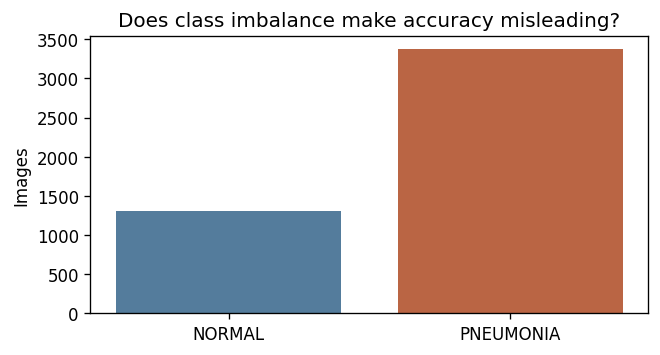

,training_majority_baseline
tn,0.000000
fp,195.000000
fn,0.000000
tp,505.000000
sensitivity,1.000000
FPR,1.000000
specificity,0.000000
precision,0.721429
f1,0.838174
accuracy,0.721429


In [6]:
development=pd.concat([train,validation],ignore_index=True).merge(features,on="record_id",validate="one_to_one")
development["aspect_ratio"]=development.width/development.height
class_counts=development.label.value_counts().reindex(["NORMAL","PNEUMONIA"])
display(class_counts.to_frame("development_images"))
fig,ax=plt.subplots(figsize=(6,3));ax.bar(class_counts.index,class_counts.values,color=["#547c9c","#ba6544"])
ax.set(ylabel="Images",title="Does class imbalance make accuracy misleading?")
chart(fig)
majority_class=int(train.label_id.mode().iloc[0])
display(pd.Series(counts(validation.label_id,np.full(len(validation),majority_class))).to_frame("training_majority_baseline"))

#### Inference
Finding: pneumonia is more common in the development pool. So what: a high-sensitivity majority prediction can produce a false alert on every normal image.

#### Decision
Modeling implication: use pneumonia sensitivity and normal-case FPR as separate acceptance conditions; retain majority and CNN baselines.

### Geometry and intensity relationships within development data

**Purpose.** Question: do image shape and intensity differ by label enough to influence representation choices?

**Method / code.** Summarize native geometry/intensity and plot class-specific aspect ratios and contrast. These are associations, not evidence of disease causation.

width               height               aspect_ratio            \
            min  median   max    min  median   max          min    median   
label                                                                       
NORMAL      912  1638.0  2916    672  1325.0  2663     0.877220  1.222052   
PNEUMONIA   384  1168.0  2772    127   776.0  2304     0.835391  1.492332   

                    intensity_mean_256                          \
                max                min      median         max   
label                                                            
NORMAL     1.807923          73.297134  122.206360  169.692368   
PNEUMONIA  3.378788          66.178116  123.091988  221.542374   

          intensity_std_256                       black_fraction_256  \
                        min     median        max                min   
label                                                                  
NORMAL            37.786320  61.124470  82.696136                0.0   
PNEUMONIA         19.916037  54.383862  87.270584                0.0   

                               
             median       max  
label                          
NORMAL     0.076447  0.279480  
PNEUMONIA  0.007988  0.330109

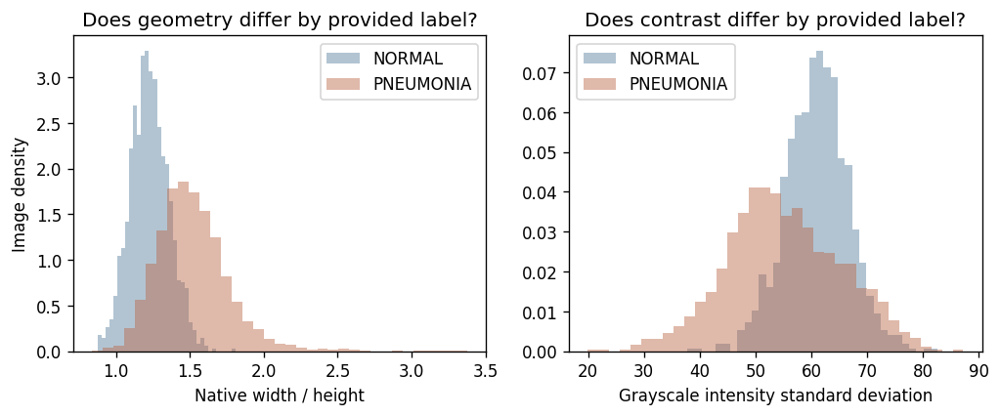

,aspect_ratio,intensity_std_256
label,,
NORMAL,1.222052,61.124470
PNEUMONIA,1.492332,54.383862


In [7]:
display(development.groupby("label")[["width","height","aspect_ratio","intensity_mean_256","intensity_std_256","black_fraction_256"]].agg(["min","median","max"]))
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for label,color in [("NORMAL","#547c9c"),("PNEUMONIA","#ba6544")]:
    group=development[development.label==label]
    axes[0].hist(group.aspect_ratio,bins=35,density=True,alpha=.45,label=label,color=color)
    axes[1].hist(group.intensity_std_256,bins=35,density=True,alpha=.45,label=label,color=color)
axes[0].set(xlabel="Native width / height",ylabel="Image density",title="Does geometry differ by provided label?")
axes[1].set(xlabel="Grayscale intensity standard deviation",title="Does contrast differ by provided label?")
for ax in axes:ax.legend()
chart(fig)
display(development.groupby("label")[["aspect_ratio","intensity_std_256"]].median())

#### Inference
Finding: geometry and intensity distributions differ by provided label. So what: a classifier might exploit acquisition-related patterns, anatomy or pathology; these measurements cannot distinguish those causes.

#### Decision
Modeling implication: preserve the full image field, compare controlled input recipes, audit errors by appearance groups and test different representations.

### Descriptive EDA summary and domain-specific limits

**Purpose.** Question: which data gaps affect the interpretation of model success?

**Method / code.** Connect available measurements and unavailable clinical metadata to the experimental design rather than presenting an image gallery as proof.

In [8]:
eda_implications=pd.DataFrame([
 ["Unequal class frequency","Accuracy can hide the costs of normal-case alerts","Report FN and FP with class-specific denominators"],
 ["Different shape/intensity distributions","Possible nuisance information or population differences","Test appearance ablations;avoid causal claims"],
 ["Unverified patient/source metadata","Patient and hospital transfer cannot be established","Use proxy groups;state limits"],
 ["No reliable acquisition times","Temporal transfer cannot be assessed","Temporal checks marked not applicable"],
 ["Image-level provided labels","Medical adjudication is absent","Treat model/label disagreement as unreviewed"]
],columns=["evidence","practical meaning","modeling implication"])
display(eda_implications)

,evidence,practical meaning,modeling implication
0,Unequal class frequency,Accuracy can hide the costs of normal-case alerts,Report FN and FP with class-specific denominators
1,Different shape/intensity distributions,Possible nuisance information or population di...,Test appearance ablations;avoid causal claims
2,Unverified patient/source metadata,Patient and hospital transfer cannot be establ...,Use proxy groups;state limits
3,No reliable acquisition times,Temporal transfer cannot be assessed,Temporal checks marked not applicable
4,Image-level provided labels,Medical adjudication is absent,Treat model/label disagreement as unreviewed


#### Inference
Useful EDA changes the representation and validation questions; it does not prove the underlying clinical explanation.

#### Decision
Preserve the limitations in every later interpretation and avoid presenting image-level metrics as verified patient outcomes.

### Plain-English Summary

**What problem were we solving?**  
We needed to know what patterns could make a model look better than it is.

**What did we find?**  
The classes are imbalanced and image appearance differs by label.

**What did we build or do?**  
We examined class counts, image shape and contrast using development data.

**Why did we do it this way?**  
These checks show why accuracy alone and an attractive image gallery are insufficient.

**What should we do next?**  
Use class-specific error metrics and test whether apparent gains survive group-separated assessment.

## Stage 3 — Methodology and Baseline Development

### Evaluation strategy, success criteria and experimental boundaries

**Purpose.** Define the decision rule and error costs before comparing methods.

**Method / code.** Declare separate historical and active objectives, group-aware roles, calibration policy and computational scope.

In [9]:
evaluation_contract=pd.DataFrame([
 ["Primary acceptance","Pneumonia sensitivity >=97%,aiming99%,with NORMAL FPR <=15%"],
 ["Preferred target","Sensitivity >=99% and NORMAL FPR <=10%"],
 ["Secondary metrics","FN,FP,specificity,precision,F1,balanced accuracy,ROC-AUC and PR metrics"],
 ["False-negative cost","High qualitative priority;no invented monetary value"],
 ["False-positive cost","Unnecessary review/resources;acceptable ceiling15% of NORMAL cases"],
 ["Threshold policy","Choose from inner-calibration labels only;never search exposed benchmark thresholds"],
 ["Validation","Frozen stratified/proxy-group roles;three outer folds with separate fitting/calibration groups for later comparisons"],
 ["Historical pre-test priority","Original optimization minimized FN subject to >=90% calibration specificity"],
 ["Compute","Generalization takes priority over cost;historical CPU scope is reported explicitly"],
 ["Preprocessing","Fit learned transforms/scalers on fitting data only;per-image deterministic normalization uses only that image"]
],columns=["item","declared policy"])
display(evaluation_contract)
display(pd.Series(J("outputs/quality/frozen_protocol.json")).to_frame("original_frozen_data_contract"))
display(T("outputs/cycle2/fold_diagnostics.csv"))

,item,declared policy
0,Primary acceptance,"Pneumonia sensitivity >=97%,aiming99%,with NOR..."
1,Preferred target,Sensitivity >=99% and NORMAL FPR <=10%
2,Secondary metrics,"FN,FP,specificity,precision,F1,balanced accura..."
3,False-negative cost,High qualitative priority;no invented monetary...
4,False-positive cost,Unnecessary review/resources;acceptable ceilin...
5,Threshold policy,Choose from inner-calibration labels only;neve...
6,Validation,Frozen stratified/proxy-group roles;three oute...
7,Historical pre-test priority,Original optimization minimized FN subject to ...
8,Compute,Generalization takes priority over cost;histor...
9,Preprocessing,Fit learned transforms/scalers on fitting data...


,original_frozen_data_contract
project_id,PRAICP-1012
seed,42
split_selection,256 GroupShuffleSplit candidates; size/prevale...
test_use_rule,"No predictions, architecture selection, thresh..."
geometry,"{'height': 224, 'width': 224, 'channels': 3, '..."
augmentation,"{'rotation_degrees': 5, 'translation_fraction'..."
perceptual_thresholds,"{'phash_max': 4, 'dhash_max': 6, 'candidates_a..."
real_patient_independence_verified,False
files_sha256,{'data/manifests/exact_duplicate_actions.csv':...


,fold,fit,calibration,outer,fit_positive,calibration_positive,outer_positive,groups_disjoint
0,0,2493,623,1557,1799,450,1123,True
1,1,2491,623,1559,1798,449,1125,True
2,2,2493,623,1557,1798,450,1124,True


#### Inference
The current 97–99% goal differs from the earlier 99.75% calibration priority. Calibration targets are not guaranteed rates on assessment data.

#### Decision
Keep both protocols explicit and do not rewrite the historical target or use the exposed benchmark for tuning.

### Custom CNN baseline and initial comparison

**Purpose.** Establish a trained reference beyond the majority classifier.

**Method / code.** Review actual histories and independently recompute validation confusion counts, precision, recall and F1 from embedded scores.

,CNN validation baseline
tn,174.000000
fp,21.000000
fn,34.000000
tp,471.000000
sensitivity,0.932673
FPR,0.107692
specificity,0.892308
precision,0.957317
f1,0.944835
accuracy,0.921429


,precision,recall,f1-score,support
NORMAL,0.836538,0.892308,0.863524,195.000000
PNEUMONIA,0.957317,0.932673,0.944835,505.000000
accuracy,0.921429,0.921429,0.921429,0.921429
macro avg,0.896928,0.912490,0.904179,700.000000
weighted avg,0.923672,0.921429,0.922184,700.000000


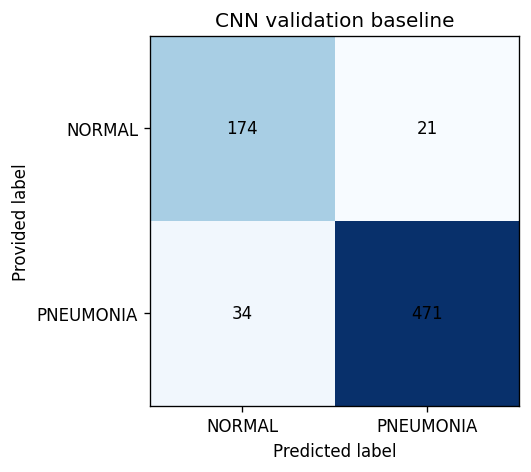

,epoch,epoch_seconds,learning_rate_used,accuracy,loss,pr_auc,precision,roc_auc,sensitivity,val_accuracy,val_loss,val_pr_auc,val_precision,val_roc_auc,val_sensitivity,learning_rate
0,1,53.104350,0.0010,0.861817,0.310275,0.969522,0.893682,0.925045,0.917684,0.921429,0.200828,0.988946,0.957317,0.971313,0.932673,0.0010
1,2,23.049632,0.0010,0.905109,0.241310,0.980714,0.932292,0.954437,0.936519,0.721429,0.707450,0.990975,0.721429,0.979203,1.000000,0.0010
2,3,24.002109,0.0010,0.921722,0.204280,0.985226,0.944986,0.967248,0.946634,0.722857,1.340322,0.884066,0.722461,0.825382,1.000000,0.0010
3,4,23.999546,0.0005,0.935313,0.172040,0.991577,0.956933,0.977782,0.953261,0.757143,0.539472,0.981072,0.748148,0.970008,1.000000,0.0005
4,5,23.934813,0.0005,0.938334,0.163323,0.991964,0.956794,0.979627,0.957796,0.721429,1.735384,0.791849,0.721429,0.658517,1.000000,0.0005


,recorded_training_configuration
seed,42
input_shape,"[224, 224, 3]"
batch_size,32
maximum_epochs,15
filters,"[16, 32, 64, 128]"
first_conv_stride,2
dense_units,64
head_dropout,0.4
optimizer,Adam
initial_learning_rate,0.001


,method,tn,fp,fn,tp,sensitivity,FPR,specificity,precision,f1,accuracy
0,training-majority baseline,0,195,0,505,1.000000,1.000000,0.000000,0.721429,0.838174,0.721429
1,custom CNN,174,21,34,471,0.932673,0.107692,0.892308,0.957317,0.944835,0.921429


In [10]:
cnn_predictions=T("outputs/cnn_baseline/validation_predictions.csv")
cnn_metrics=explain_confusion(cnn_predictions,cnn_predictions.pneumonia_probability>=.5,"CNN validation baseline")
recorded=J("outputs/cnn_baseline/validation_metrics.json")
assert all(cnn_metrics[k]==recorded[k] for k in ["tn","fp","fn","tp"])
display(T("outputs/cnn_baseline/history.csv"))
display(pd.Series(J("outputs/cnn_baseline/training_configuration.json")).to_frame("recorded_training_configuration"))
display(pd.DataFrame([
 {"method":"training-majority baseline",**counts(validation.label_id,np.full(len(validation),majority_class))},
 {"method":"custom CNN",**cnn_metrics}
]))

#### Inference
The CNN improves normal-case discrimination over the majority rule, but its missed pneumonia cases remain material under the sensitivity priority. The confusion matrix makes both error costs visible.

#### Decision
Retain the CNN as a fixed reference and compare transfer-learning candidates using the same frozen development roles.

### Plain-English Summary

**What problem were we solving?**  
We needed a fair way to judge useful performance before chasing a large accuracy number.

**What did we find?**  
A trained baseline separates the classes better than the trivial majority prediction but still makes costly mistakes.

**What did we build or do?**  
We defined the sensitivity/FPR targets, split rules, threshold policy and baseline comparison.

**Why did we do it this way?**  
Separate class-specific metrics show both missed cases and unnecessary alerts.

**What should we do next?**  
Compare meaningful representations and choose settings using development data only.

## Stage 4 — Validation and Refinement

This stage describes the **original pre-test** transfer and sensitivity-refinement work. The reserved benchmark labels were not used for these choices. Experiments conducted after benchmark exposure appear later and are explicitly exploratory.

### Candidate representations and the selective fine-tuning experiment

**Purpose.** Test whether pretrained representations improve the baseline under a matched comparison.

**Method / code.** Review MobileNetV2, EfficientNetB0 and DenseNet121 results, feature-cache identity checks and the single declared fine-tuning attempt.

In [11]:
transfer_results=T("outputs/transfer_learning/experiment_results.csv")
display(transfer_results)
display(T("outputs/transfer_learning/architecture_leaderboard.csv"))
display(pd.Series(J("outputs/transfer_learning/comparison_checks.json")).to_frame("recorded_comparison_checks"))
display(pd.Series(J("outputs/transfer_learning/fine_tune_selection.json")).to_frame("pre_test_selection"))
validation_candidates=[]
for architecture in ["mobilenet_v2","efficientnet_b0","densenet121"]:
    frame=T("outputs/transfer_learning/"+architecture+"/frozen_validation_predictions.csv")
    validation_candidates.append({"architecture":architecture,**counts(frame.label_id,frame.pneumonia_probability>=.5)})
candidate_counts=pd.DataFrame(validation_candidates)
candidate_counts["individual_inference"]=candidate_counts.apply(
    lambda r:f"This validation rule misses {int(r.fn)} pneumonia images and flags {int(r.fp)} normals; threshold0.5 is not the optimized sensitivity rule.",axis=1)
candidate_counts["decision"]="Retain evidence for pre-test sensitivity calibration;no benchmark-based selection."
display(candidate_counts)

,model,architecture,phase,parameters,model_path,training_seconds,n,threshold,accuracy,pneumonia_sensitivity,...,f1,balanced_accuracy,roc_auc,average_precision,pr_auc_trapezoidal,binary_crossentropy,tn,fp,fn,tp
0,custom_cnn,Custom CNN,from_scratch,106481,models/custom_cnn_baseline/baseline.keras,148.125903,700,0.5,0.921429,0.932673,...,0.944835,0.912490,0.971272,0.988944,0.988932,0.200828,174,21,34,471
1,mobilenet_v2,MobileNetV2,frozen_head,2422081,models/transfer_learning/mobilenet_v2/frozen.k...,104.932014,700,0.5,0.965714,0.970297,...,0.976096,0.962072,0.995715,0.998356,0.998355,0.083756,186,9,15,490
2,efficientnet_b0,EfficientNetB0,frozen_head,4213668,models/transfer_learning/efficientnet_b0/froze...,136.529492,700,0.5,0.971429,0.972277,...,0.980040,0.970754,0.996984,0.998886,0.998885,0.066417,189,6,14,491
3,densenet121,DenseNet121,frozen_head,7168833,models/transfer_learning/densenet121/frozen.keras,383.402040,700,0.5,0.970000,0.982178,...,0.979269,0.960320,0.997319,0.998989,0.998988,0.061721,183,12,9,496
4,densenet121,DenseNet121,selective_fine_tune,7168833,models/transfer_learning/densenet121/fine_tune...,1084.583651,700,0.5,0.974286,0.976238,...,0.982072,0.972734,0.997370,0.999014,0.999014,0.062208,189,6,12,493


,validation_bce_rank,model,architecture,phase,parameters,model_path,training_seconds,n,threshold,accuracy,...,f1,balanced_accuracy,roc_auc,average_precision,pr_auc_trapezoidal,binary_crossentropy,tn,fp,fn,tp
0,1,densenet121,DenseNet121,frozen_head,7168833,models/transfer_learning/densenet121/frozen.keras,383.402040,700,0.5,0.970000,...,0.979269,0.960320,0.997319,0.998989,0.998988,0.061721,183,12,9,496
1,2,efficientnet_b0,EfficientNetB0,frozen_head,4213668,models/transfer_learning/efficientnet_b0/froze...,136.529492,700,0.5,0.971429,...,0.980040,0.970754,0.996984,0.998886,0.998885,0.066417,189,6,14,491
2,3,mobilenet_v2,MobileNetV2,frozen_head,2422081,models/transfer_learning/mobilenet_v2/frozen.k...,104.932014,700,0.5,0.965714,...,0.976096,0.962072,0.995715,0.998356,0.998355,0.083756,186,9,15,490
3,4,custom_cnn,Custom CNN,from_scratch,106481,models/custom_cnn_baseline/baseline.keras,148.125903,700,0.5,0.921429,...,0.944835,0.912490,0.971272,0.988944,0.988932,0.200828,174,21,34,471


,recorded_comparison_checks
all_experiment_metrics_recomputed,True
validation_row_order_and_labels_match,True
identical_feature_views_across_backbones,{'training_original': {'identical_across_model...
backbones_frozen_and_unchanged,True
candidate_selected_by_frozen_validation_bce,densenet121
fine_tune_bn_state_unchanged,True
provisional_validation_bce_leader,densenet121
test_evaluated,False
all_checks_passed,True


,pre_test_selection
rule,minimum frozen-head validation binary cross-en...
selected_model,densenet121
frozen_validation_bce,0.061721
test_used,False
fine_tuning_budget_epochs,3
fine_tuning_lr,0.00001


,architecture,tn,fp,fn,tp,sensitivity,FPR,specificity,precision,f1,accuracy,individual_inference,decision
0,mobilenet_v2,186,9,15,490,0.970297,0.046154,0.953846,0.981964,0.976096,0.965714,This validation rule misses 15 pneumonia image...,Retain evidence for pre-test sensitivity calib...
1,efficientnet_b0,189,6,14,491,0.972277,0.030769,0.969231,0.987928,0.980040,0.971429,This validation rule misses 14 pneumonia image...,Retain evidence for pre-test sensitivity calib...
2,densenet121,183,12,9,496,0.982178,0.061538,0.938462,0.976378,0.979269,0.970000,This validation rule misses 9 pneumonia images...,Retain evidence for pre-test sensitivity calib...


#### Inference
Different representations improve the validation trade-off, but the limited fine-tuning attempt did not improve its monitored validation loss. That failure is retained rather than hidden.

#### Decision
Retain both frozen and fine-tuned evidence; use the declared development-selection policy rather than selecting by test performance.

### Threshold implications, training variants and error diagnosis

**Purpose.** Reduce missed pneumonia without ignoring false alerts.

**Method / code.** Compare actual class-weight/lower-learning-rate variants, calibration threshold sweeps and Grad-CAM verification. Inspect the provided-label errors without relabeling them.

,candidate,class_weight,learning_rate,epochs,best_epoch,seconds,n,threshold,accuracy,pneumonia_sensitivity,...,f1,balanced_accuracy,roc_auc,average_precision,pr_auc_trapezoidal,binary_crossentropy,tn,fp,fn,tp
0,dense_lr3e4_unweighted,NaN,0.0003,14,11,10.190913,700,0.5,0.975714,0.982178,...,0.983152,0.970576,0.997207,0.998948,0.998947,0.061471,187,8,9,496
1,dense_lr3e4_balanced,"{'0': 1.796112115732369, '1': 0.6928845483083362}",0.0003,13,10,8.384558,700,0.5,0.971429,0.972277,...,0.980040,0.970754,0.997238,0.998962,0.998961,0.066128,189,6,14,491
2,dense_lr3e4_positive2,"{'0': 1.0, '1': 2.0}",0.0003,15,12,10.872584,700,0.5,0.974286,0.982178,...,0.982178,0.968012,0.997248,0.998961,0.998960,0.060976,186,9,9,496


,candidate,threshold,fn,fp,tn,tp,sensitivity,specificity,binary_crossentropy
0,dense_lr3e4_positive2,0.238386,2,18,177,503,0.996040,0.907692,0.060976
1,efficientnet_b0,0.159117,3,15,180,502,0.994059,0.923077,0.066417
2,dense_lr3e4_unweighted,0.197500,3,18,177,502,0.994059,0.907692,0.061471
3,mobilenet_v2,0.143485,3,18,177,502,0.994059,0.907692,0.083756
4,densenet121,0.233528,3,19,176,502,0.994059,0.902564,0.061721
5,densenet121_fine_tuned,0.127084,3,19,176,502,0.994059,0.902564,0.062208
6,dense_lr3e4_balanced,0.131544,4,18,177,501,0.992079,0.907692,0.066128
7,custom_cnn,0.567172,40,19,176,465,0.920792,0.902564,0.200828


,target_sensitivity,candidate,threshold,fn,fp,tn,tp,sensitivity,specificity,binary_crossentropy
0,0.990,custom_cnn,0.168996,5,80,115,500,0.990099,0.589744,0.200828
1,0.990,mobilenet_v2,0.174583,4,17,178,501,0.992079,0.912821,0.083756
2,0.990,efficientnet_b0,0.218995,5,13,182,500,0.990099,0.933333,0.066417
3,0.990,densenet121,0.244584,4,18,177,501,0.992079,0.907692,0.061721
4,0.990,densenet121_fine_tuned,0.174317,5,17,178,500,0.990099,0.912821,0.062208
5,0.990,dense_lr3e4_unweighted,0.219462,4,17,178,501,0.992079,0.912821,0.061471
6,0.990,dense_lr3e4_balanced,0.149670,5,17,178,500,0.990099,0.912821,0.066128
7,0.990,dense_lr3e4_positive2,0.280469,5,16,179,500,0.990099,0.917949,0.060976
8,0.995,custom_cnn,0.122284,2,115,80,503,0.996040,0.410256,0.200828
9,0.995,mobilenet_v2,0.076747,2,21,174,503,0.996040,0.892308,0.083756


,Selected pre-test validation rule
tn,177.000000
fp,18.000000
fn,2.000000
tp,503.000000
sensitivity,0.996040
FPR,0.092308
specificity,0.907692
precision,0.965451
f1,0.980507
accuracy,0.971429


,precision,recall,f1-score,support
NORMAL,0.988827,0.907692,0.946524,195.000000
PNEUMONIA,0.965451,0.996040,0.980507,505.000000
accuracy,0.971429,0.971429,0.971429,0.971429
macro avg,0.977139,0.951866,0.963515,700.000000
weighted avg,0.971963,0.971429,0.971040,700.000000


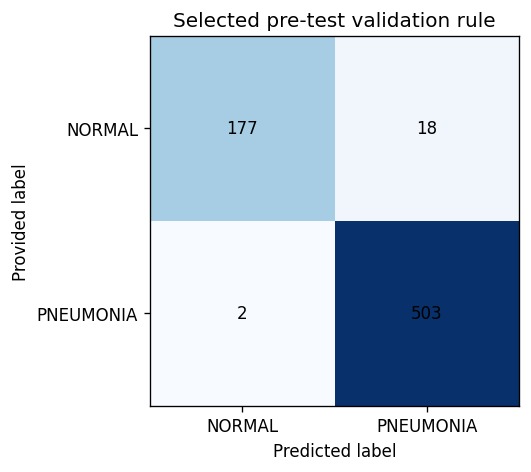

,pre_test_frozen_selection
candidate,dense_lr3e4_positive2
model_path,models/optimization/selected_full.keras
model_sha256,c732a0773fd4d8ea739804e9fc88c0c03fb12e4854d24b...
preprocessing,densenet121
threshold,0.216406
comparison_operator,>=
pneumonia_label,1
image_geometry,224x224 RGB bilinear antialiased aspect-preser...
protocol_sha256,8cb6753a66b785b858a26a733a95dddaec9a5c9681760b...
selection_validation_predictions_sha256,c903a00615eea27e680894452c1314afcdd98a688c8793...


,record_id,label,label_id,patient_proxy,leakage_group,pneumonia_probability,prediction,outcome,image_path,width,height,mode,aspect_ratio
0,2a424cc8ffa8a910964a,PNEUMONIA,1,pneumonia_person_635,2a424cc8ffa8a910964a,0.129019,0,FN,data/raw_images/2a424cc8ffa8a910964a.jpeg,1431,1058,L,1.352552
1,54efaed267785f6975eb,PNEUMONIA,1,pneumonia_person_706,54efaed267785f6975eb,0.034474,0,FN,data/raw_images/54efaed267785f6975eb.jpeg,1474,1044,L,1.411877
2,cf5eb6e331964d76d972,NORMAL,0,IM_302,cf5eb6e331964d76d972,0.648170,1,FP,data/raw_images/cf5eb6e331964d76d972.jpeg,1430,1128,L,1.267730
3,fb9492bb341dc18f49ce,NORMAL,0,IM_480,fb9492bb341dc18f49ce,0.239214,1,FP,data/raw_images/fb9492bb341dc18f49ce.jpeg,2218,2183,L,1.016033
4,06c525dc5b085fa5fdcb,NORMAL,0,NORMAL2-IM_659,06c525dc5b085fa5fdcb,0.968889,1,FP,data/raw_images/06c525dc5b085fa5fdcb.jpeg,1438,1187,L,1.211457
5,0dc524b9a643e3d9fc42,NORMAL,0,NORMAL2-IM_705,0dc524b9a643e3d9fc42,0.379937,1,FP,data/raw_images/0dc524b9a643e3d9fc42.jpeg,1960,1648,L,1.189320
6,cfcf559c35617027aa49,NORMAL,0,NORMAL2-IM_723,cfcf559c35617027aa49,0.646625,1,FP,data/raw_images/cfcf559c35617027aa49.jpeg,1168,960,L,1.216667
7,b10ab6a0b40ff15d9ce8,NORMAL,0,NORMAL2-IM_793,b10ab6a0b40ff15d9ce8,0.437555,1,FP,data/raw_images/b10ab6a0b40ff15d9ce8.jpeg,2179,1604,L,1.358479
8,731dee86866c27a0b8c3,NORMAL,0,NORMAL2-IM_872,731dee86866c27a0b8c3,0.807018,1,FP,data/raw_images/731dee86866c27a0b8c3.jpeg,1156,804,L,1.437811
9,d92356551a4f804246fb,NORMAL,0,NORMAL2-IM_1214,d92356551a4f804246fb,0.825564,1,FP,data/raw_images/d92356551a4f804246fb.jpeg,1392,1232,L,1.129870


,historical_explanation_checks
all_700_full_model_predictions_match,True
all_700_threshold_decisions_match,True
max_score_absolute_difference,0.0
cases,"[{'record_id': '2a424cc8ffa8a910964a', 'outcom..."
test_evaluated,False


In [12]:
display(T("outputs/optimization/targeted_training_results.csv"))
display(T("outputs/optimization/candidate_operating_points.csv"))
display(T("outputs/optimization/sensitivity_target_tradeoffs.csv"))
original_freeze=J("outputs/optimization/frozen_selection.json")
optimization_predictions=T("outputs/optimization/selected_validation_predictions.csv")
optimized_metrics=explain_confusion(optimization_predictions,optimization_predictions.pneumonia_probability>=original_freeze["threshold"],"Selected pre-test validation rule")
assert optimized_metrics["fn"]==2 and optimized_metrics["fp"]==18
display(pd.Series(original_freeze).to_frame("pre_test_frozen_selection"))
display(T("outputs/optimization/validation_errors.csv").head(12))
display(pd.Series(J("outputs/optimization/explanation_checks.json")).to_frame("historical_explanation_checks"))

#### Inference
The original selected rule achieved high validation sensitivity with controlled validation alerts. Attention near margins/padding was observed, but explanation maps do not establish causal shortcuts or clinical lesion localization.

#### Decision
Freeze the complete original pipeline before its single reserved evaluation. Do not adjust its threshold using benchmark outcomes.

### Plain-English Summary

**What problem were we solving?**  
We needed fewer missed pneumonia cases while keeping normal-image alerts manageable.

**What did we find?**  
Transfer learning and sensitivity-focused thresholds improved validation behavior; the tested fine-tune did not improve its monitored loss.

**What did we build or do?**  
We compared candidates, thresholds and error patterns before freezing the original method.

**Why did we do it this way?**  
A failed experiment is useful evidence, and threshold changes always affect both types of mistake.

**What should we do next?**  
Evaluate the frozen original method once on the reserved benchmark and report any transfer failure honestly.

## Stage 5 — Final Out-of-Sample Evaluation

### Exact frozen configuration and historical reserved evaluation

**Purpose.** Evaluate the original finalized preprocessing, model and threshold consistently.

**Method / code.** Verify the historical model/configuration/prediction provenance, then recount outcomes from the exact embedded prediction bytes. The estimator is not loaded during evidence review.

Pneumonia ROC-AUC: 0.9563883410037256
Average precision: 0.9701156191855934


,Original frozen benchmark evaluation
tn,87.000000
fp,147.000000
fn,1.000000
tp,389.000000
sensitivity,0.997436
FPR,0.628205
specificity,0.371795
precision,0.725746
f1,0.840173
accuracy,0.762821


,precision,recall,f1-score,support
NORMAL,0.988636,0.371795,0.540373,234.000000
PNEUMONIA,0.725746,0.997436,0.840173,390.000000
accuracy,0.762821,0.762821,0.762821,0.762821
macro avg,0.857191,0.684615,0.690273,624.000000
weighted avg,0.824330,0.762821,0.727748,624.000000


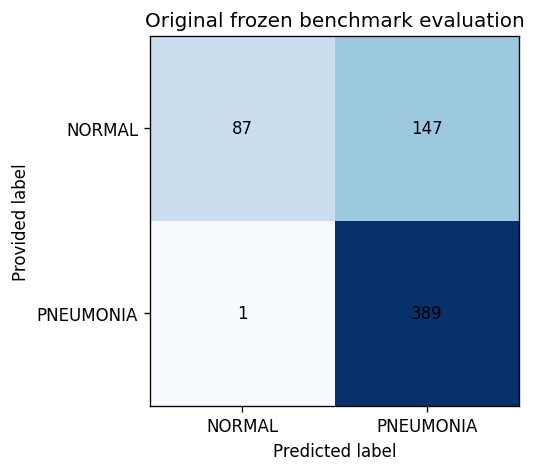

,finalized_pipeline_reference
model_sha256,c732a0773fd4d8ea739804e9fc88c0c03fb12e4854d24b...
preprocessing,densenet121
threshold,0.216406
comparison_operator,>=
provenance_scope,historically verified trained artifact;not loa...


,historical_scoring_receipt
completed,True
test_records,624
predictions_sha256,789a36caa0442595914059eecb2eb794bce4892b0279be...
frozen_config_unchanged,True
model_unchanged,True
test_based_retuning,False
scoring_passes,1


In [13]:
original_freeze=J("outputs/optimization/frozen_selection.json")
original_lock=J("outputs/final_test/pre_evaluation_lock.json")
receipt=J("outputs/final_test/scoring_receipt.json")
assert original_lock["model_sha256"]==original_freeze["model_sha256"]
assert hashlib.sha256(EVIDENCE["outputs/optimization/frozen_selection.json"]).hexdigest()==original_lock["frozen_selection_sha256"]
assert hashlib.sha256(EVIDENCE["outputs/final_test/test_predictions.csv"]).hexdigest()==receipt["predictions_sha256"]
assert receipt["model_unchanged"] and receipt["frozen_config_unchanged"] and not receipt["test_based_retuning"]
FINAL_PIPELINE_REFERENCE=MappingProxyType({
 "model_sha256":original_freeze["model_sha256"],"preprocessing":original_freeze["preprocessing"],
 "threshold":original_freeze["threshold"],"comparison_operator":original_freeze["comparison_operator"],
 "provenance_scope":"historically verified trained artifact;not loaded during review"})
FINAL_PIPELINE_ID=hashlib.sha256(json.dumps(dict(FINAL_PIPELINE_REFERENCE),sort_keys=True).encode()).hexdigest()
FINAL_PREDICTIONS=T("outputs/final_test/test_predictions.csv")
assert np.array_equal(FINAL_PREDICTIONS.prediction,(FINAL_PREDICTIONS.pneumonia_probability>=FINAL_PIPELINE_REFERENCE["threshold"]).astype(int))
final_metrics=explain_confusion(FINAL_PREDICTIONS,FINAL_PREDICTIONS.prediction,"Original frozen benchmark evaluation")
assert (final_metrics["tn"],final_metrics["fp"],final_metrics["fn"],final_metrics["tp"])==(87,147,1,389)
display(pd.Series(dict(FINAL_PIPELINE_REFERENCE)).to_frame("finalized_pipeline_reference"))
display(pd.Series(receipt).to_frame("historical_scoring_receipt"))
print("Pneumonia ROC-AUC:",roc_auc_score(FINAL_PREDICTIONS.label_id,FINAL_PREDICTIONS.pneumonia_probability))
print("Average precision:",average_precision_score(FINAL_PREDICTIONS.label_id,FINAL_PREDICTIONS.pneumonia_probability))

#### Inference
The original rule catches 389 of 390 pneumonia-labelled images but flags 147 of 234 normal images. The strong validation specificity did not transfer; the false-alert burden is excessive.

#### Decision
Keep this exact historical result and finalized artifact identity. Do not turn post-test research into another supposedly untouched final evaluation.

### Uncertainty, duplicate sensitivity analysis and final-evaluation inference

**Purpose.** Describe sampling uncertainty without overstating independence.

**Method / code.** Show exact image-level intervals as descriptive, and recompute the exact-unique-image sensitivity analysis. No actual patient registry is available for validated patient-level inference.

In [14]:
sensitivity_interval=exact_interval(final_metrics["tp"],final_metrics["tp"]+final_metrics["fn"])
FPR_interval=exact_interval(final_metrics["fp"],final_metrics["fp"]+final_metrics["tn"])
display(pd.DataFrame([
 ["Pneumonia sensitivity",final_metrics["sensitivity"],*sensitivity_interval],
 ["NORMAL false-positive rate",final_metrics["FPR"],*FPR_interval]
],columns=["metric","point_estimate","descriptive_95_low","descriptive_95_high"]))
unique_test=FINAL_PREDICTIONS.drop_duplicates("pixel_sha256")
assert len(unique_test)==618
display(pd.Series(counts(unique_test.label_id,unique_test.prediction)).to_frame("exact_unique_sensitivity_analysis"))
display(T("outputs/final_test/validation_test_comparison.csv"))
print("Intervals are image-level descriptions;group dependence and repeated research selection are not corrected.")

Intervals are image-level descriptions;group dependence and repeated research selection are not corrected.


,metric,point_estimate,descriptive_95_low,descriptive_95_high
0,Pneumonia sensitivity,0.997436,0.985797,0.999935
1,NORMAL false-positive rate,0.628205,0.562834,0.690283


,exact_unique_sensitivity_analysis
tn,87.000000
fp,144.000000
fn,1.000000
tp,386.000000
sensitivity,0.997416
FPR,0.623377
specificity,0.376623
precision,0.728302
f1,0.841876
accuracy,0.765372


,partition,n,accuracy,pneumonia_sensitivity,specificity,precision,negative_predictive_value,f1,roc_auc,average_precision,fp,fn,tn,tp
0,Validation (development),700,0.971429,0.996040,0.907692,0.965451,0.988827,0.980507,0.997248,0.998961,18,2,177,503
1,Original test (primary),624,0.762821,0.997436,0.371795,0.725746,0.988636,0.840173,0.956388,0.970116,147,1,87,389
2,Exact-unique test (secondary),618,0.765372,0.997416,0.376623,0.728302,0.988636,0.841876,0.955871,0.969825,144,1,87,386


#### Inference
Removing exact copies does not close the transfer gap or create an independent cohort. The small benchmark and unverified patient structure limit the certainty of the missed-case rate.

#### Decision
Treat the original evaluation as a completed research finding, preserve its limitations and retain a new-independent-evaluation dependency for future generalization claims.

### Plain-English Summary

**What problem were we solving?**  
We needed to know how the finalized original method worked beyond its calibration data.

**What did we find?**  
It caught 389 of 390 pneumonia images, but incorrectly flagged 147 of 234 normal images.

**What did we build or do?**  
We evaluated the exact frozen rule and checked uncertainty and duplicate sensitivity.

**Why did we do it this way?**  
A fixed pipeline exposes transfer failure that validation scores alone can hide.

**What should we do next?**  
Keep the result unchanged and label all later reuse of this benchmark as exploratory.

## Post-evaluation exploratory research — exposed benchmark

The following work was carried out **after** the original reserved evaluation. Settings used development/calibration roles, but earlier benchmark findings informed the research agenda. These comparisons must not be described as another untouched final test or placed inside the original pre-test refinement stage.

### Independent representation experiments and threshold trade-offs

**Purpose.** Determine whether different learned features correct the false-alert problem.

**Method / code.** Keep all eight declared candidates, grouped outer/calibration roles and historical target settings. Compare original-image frozen representations, medical pretraining, logistic heads and hard-negative weighting.

,candidate,target_sensitivity,sensitivity,specificity,fn,fp,tn,tp,n,accuracy,target_met_on_outer_oof
0,dense_mlp,0.9975,0.993179,0.849347,23,196,1105,3349,4673,0.953135,False
1,dense_mlp,0.9950,0.989620,0.905457,35,123,1178,3337,4673,0.966189,False
2,dense_mlp,0.9900,0.986655,0.914681,45,111,1190,3327,4673,0.966617,False
3,efficient_mlp,0.9975,0.994662,0.789393,18,274,1027,3354,4673,0.937513,False
4,efficient_mlp,0.9950,0.993772,0.828593,21,223,1078,3351,4673,0.947785,False
5,efficient_mlp,0.9900,0.989917,0.873943,34,164,1137,3338,4673,0.957629,False
6,xrv_mlp,0.9975,0.997034,0.661030,10,441,860,3362,4673,0.903488,False
7,xrv_mlp,0.9950,0.992883,0.812452,24,244,1057,3348,4673,0.942649,False
8,xrv_mlp,0.9900,0.991103,0.859339,30,183,1118,3342,4673,0.954419,True
9,dense_hardneg,0.9975,0.992883,0.834743,24,215,1086,3348,4673,0.948855,False


,candidate,development_target,n,threshold,accuracy,pneumonia_sensitivity,specificity,precision,f1,balanced_accuracy,roc_auc,average_precision,pr_auc_trapezoidal,binary_crossentropy,tn,fp,fn,tp
0,dense_mlp,0.9975,624,0.099326,0.745192,0.997436,0.324786,0.711152,0.830309,0.661111,0.946932,0.961339,0.961263,0.634218,76,158,1,389
1,dense_mlp,0.9950,624,0.107252,0.746795,0.997436,0.329060,0.712454,0.831197,0.663248,0.946932,0.961339,0.961263,0.634218,77,157,1,389
2,dense_mlp,0.9900,624,0.182737,0.764423,0.994872,0.380342,0.727955,0.840737,0.687607,0.946932,0.961339,0.961263,0.634218,89,145,2,388
3,efficient_mlp,0.9975,624,0.037657,0.693910,1.000000,0.183761,0.671256,0.803296,0.591880,0.953353,0.968481,0.968427,0.654989,43,191,0,390
4,efficient_mlp,0.9950,624,0.049042,0.700321,1.000000,0.200855,0.675910,0.806618,0.600427,0.953353,0.968481,0.968427,0.654989,47,187,0,390
5,efficient_mlp,0.9900,624,0.225244,0.758013,0.997436,0.358974,0.721707,0.837460,0.678205,0.953353,0.968481,0.968427,0.654989,84,150,1,389
6,xrv_mlp,0.9975,624,0.018803,0.695513,1.000000,0.188034,0.672414,0.804124,0.594017,0.954843,0.970014,0.969967,0.455989,44,190,0,390
7,xrv_mlp,0.9950,624,0.031530,0.719551,1.000000,0.252137,0.690265,0.816754,0.626068,0.954843,0.970014,0.969967,0.455989,59,175,0,390
8,xrv_mlp,0.9900,624,0.172265,0.804487,0.994872,0.487179,0.763780,0.864143,0.741026,0.954843,0.970014,0.969967,0.455989,114,120,2,388
9,dense_hardneg,0.9975,624,0.111995,0.698718,0.997436,0.200855,0.675347,0.805383,0.599145,0.946318,0.961218,0.961143,0.570034,47,187,1,389


,candidate,individual_inference,decision
0,dense_mlp,Outer assessment: 23 misses and 196 false aler...,Keep as exploratory comparison;judge target at...
3,efficient_mlp,Outer assessment: 18 misses and 274 false aler...,Keep as exploratory comparison;judge target at...
6,xrv_mlp,Outer assessment: 10 misses and 441 false aler...,Keep as exploratory comparison;judge target at...
9,dense_hardneg,Outer assessment: 24 misses and 215 false aler...,Keep as exploratory comparison;judge target at...
12,dense_logistic,Outer assessment: 14 misses and 177 false aler...,Keep as exploratory comparison;judge target at...
15,efficient_logistic,Outer assessment: 14 misses and 302 false aler...,Keep as exploratory comparison;judge target at...
18,ensemble_dense_efficient,Outer assessment: 17 misses and 184 false aler...,Keep as exploratory comparison;judge target at...
21,ensemble_all3,Outer assessment: 8 misses and 171 false alert...,Keep as exploratory comparison;judge target at...


,recorded_study_status
candidates_completed,8
outer_folds,3
final_fit_stages,1
trained_MLP_heads,16
trained_logistic_heads,8
learned_ensemble_weights,False
oof_selected_candidate,ensemble_all3
oof_target_achieved_by_any_candidate,True
selected_USED_benchmark_primary_result,"{'candidate': 'ensemble_all3', 'development_ta..."
retrospective_fewest_FP_among_candidates_with_FN_le1,"{'candidate': 'ensemble_all3', 'development_ta..."


,label,records,metadata_only_group_oof_source_auc,features,interpretation
0,NORMAL,1535,0.857059,"[log_width, log_height, aspect_ratio, rgb_mode...",Distinguishability of development vs USED test...
1,PNEUMONIA,3762,0.634440,"[log_width, log_height, aspect_ratio, rgb_mode...",Distinguishability of development vs USED test...


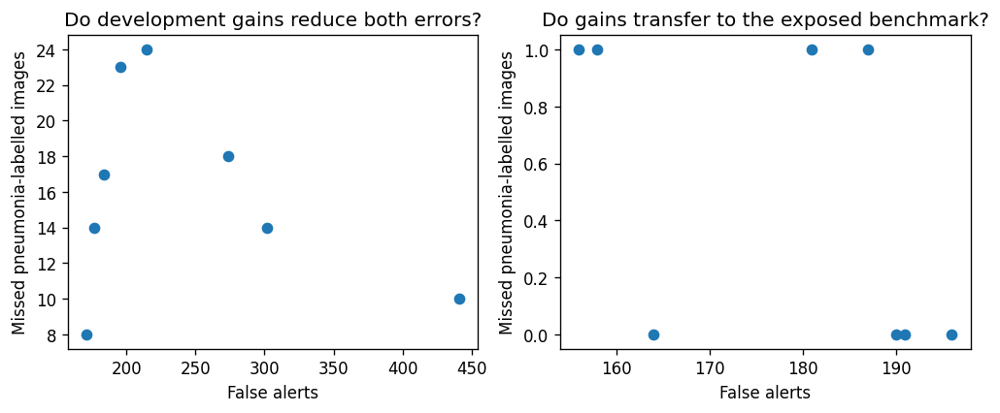

In [15]:
exploratory_development=T("outputs/cycle2/nested_oof_comparison.csv")
exploratory_benchmark=T("outputs/cycle2/USED_benchmark_comparison.csv")
display(exploratory_development);display(exploratory_benchmark)
individual=exploratory_development[np.isclose(exploratory_development.target_sensitivity,.9975)].copy()
individual["individual_inference"]=individual.apply(lambda r:f"Outer assessment: {int(r.fn)} misses and {int(r.fp)} false alerts; achieved sensitivity {r.sensitivity*100:.3f}%.",axis=1)
individual["decision"]="Keep as exploratory comparison;judge target attainment and paired errors,not accuracy alone."
display(individual[["candidate","individual_inference","decision"]])
display(pd.Series(J("outputs/cycle2/experiment_result_status.json")).to_frame("recorded_study_status"))
display(pd.DataFrame(J("outputs/cycle2/source_separation.json")))
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
a=exploratory_development[np.isclose(exploratory_development.target_sensitivity,.9975)]
b=exploratory_benchmark[np.isclose(exploratory_benchmark.development_target,.9975)]
axes[0].scatter(a.fp,a.fn);axes[1].scatter(b.fp,b.fn)
for ax,title in zip(axes,["Do development gains reduce both errors?","Do gains transfer to the exposed benchmark?"]):
    ax.set(xlabel="False alerts",ylabel="Missed pneumonia-labelled images",title=title)
chart(fig)

#### Inference
Different representations provide complementary internal behavior, but strong internal performance does not consistently carry over. The hard-negative variant and border intervention did not deliver the intended improvement.

#### Decision
Retain the failures and every target setting. Do not choose a new operational winner by repeatedly inspecting this benchmark.

### Ensemble complementarity, timing and dependence-aware descriptions

**Purpose.** Measure whether corrected errors justify extra computation.

**Method / code.** Compare independent seed heads and heterogeneous backbones using actual paired corrections/new errors and controlled warm timing. Retain descriptive proxy-group bootstrap intervals without claiming verified-patient inference.

,pipeline,target,fn,fp,tn,tp,sensitivity,specificity,n,target_met
0,dense42,0.9975,23,196,1105,3349,0.993179,0.849347,4673,False
1,dense42,0.9950,35,123,1178,3337,0.989620,0.905457,4673,False
2,dense42,0.9900,45,111,1190,3327,0.986655,0.914681,4673,False
3,dense137,0.9975,31,189,1112,3341,0.990807,0.854727,4673,False
4,dense137,0.9950,32,156,1145,3340,0.990510,0.880092,4673,False
5,dense137,0.9900,51,103,1198,3321,0.984875,0.920830,4673,False
6,dense2026,0.9975,31,181,1120,3341,0.990807,0.860876,4673,False
7,dense2026,0.9950,35,146,1155,3337,0.989620,0.887779,4673,False
8,dense2026,0.9900,54,109,1192,3318,0.983986,0.916218,4673,False
9,efficient,0.9975,18,274,1027,3354,0.994662,0.789393,4673,False


,pipeline,target,n,threshold,accuracy,pneumonia_sensitivity,specificity,precision,f1,balanced_accuracy,roc_auc,average_precision,pr_auc_trapezoidal,binary_crossentropy,tn,fp,fn,tp
0,dense42,0.9975,624,0.099326,0.745192,0.997436,0.324786,0.711152,0.830309,0.661111,0.946932,0.961339,0.961263,0.634218,76,158,1,389
1,dense42,0.9950,624,0.107252,0.746795,0.997436,0.329060,0.712454,0.831197,0.663248,0.946932,0.961339,0.961263,0.634218,77,157,1,389
2,dense42,0.9900,624,0.182737,0.764423,0.994872,0.380342,0.727955,0.840737,0.687607,0.946932,0.961339,0.961263,0.634218,89,145,2,388
3,dense137,0.9975,624,0.179422,0.738782,0.994872,0.311966,0.706740,0.826411,0.653419,0.948137,0.964221,0.964158,0.700035,73,161,2,388
4,dense137,0.9950,624,0.194637,0.741987,0.994872,0.320513,0.709324,0.828175,0.657692,0.948137,0.964221,0.964158,0.700035,75,159,2,388
5,dense137,0.9900,624,0.322230,0.762821,0.994872,0.376068,0.726592,0.839827,0.685470,0.948137,0.964221,0.964158,0.700035,88,146,2,388
6,dense2026,0.9975,624,0.163132,0.717949,0.997436,0.252137,0.689716,0.815514,0.624786,0.942560,0.957311,0.957221,0.718347,59,175,1,389
7,dense2026,0.9950,624,0.224987,0.733974,0.994872,0.299145,0.702899,0.823779,0.647009,0.942560,0.957311,0.957221,0.718347,70,164,2,388
8,dense2026,0.9900,624,0.388175,0.764423,0.994872,0.380342,0.727955,0.840737,0.687607,0.942560,0.957311,0.957221,0.718347,89,145,2,388
9,efficient,0.9975,624,0.037657,0.693910,1.000000,0.183761,0.671256,0.803296,0.591880,0.953353,0.968481,0.968427,0.654989,43,191,0,390


,pipeline,batch_size,median_ms_per_image,p25_ms_per_image,p75_ms_per_image,median_seconds_per_batch,repeats,backbone_forwards,heads
0,dense137,1,60.035006,59.377271,62.348514,0.060035,15,1,1
1,dense137,16,25.220605,24.306129,25.331908,0.403530,5,1,1
2,dense2026,1,61.955420,60.033131,63.082396,0.061955,15,1,1
3,dense2026,16,25.916915,25.022246,26.515815,0.414671,5,1,1
4,dense42,1,61.374615,58.654627,63.797767,0.061375,15,1,1
5,dense42,16,25.854345,25.586558,25.908622,0.413670,5,1,1
6,dense_efficient,1,94.588002,91.902218,96.620836,0.094588,15,2,2
7,dense_efficient,16,38.840071,38.141617,39.251627,0.621441,5,2,2
8,dense_medical,1,181.497456,176.649691,184.122744,0.181497,15,2,2
9,dense_medical,16,113.273427,107.308874,115.065913,1.812375,5,2,2


,cohort,target,ensemble,reference,is_development_single_reference,normal_false_alerts_corrected,normal_false_alerts_introduced,pneumonia_misses_rescued,pneumonia_misses_introduced,net_FP_avoided,net_FN_avoided,net_positive_calls_avoided,FP_ensemble,FN_ensemble,FP_reference,FN_reference
0,development,0.9975,dense_seed_pair,dense42,False,15,18,2,5,-3,-3,0,199,26,196,23
1,development,0.9975,dense_seed_pair,dense137,False,5,15,5,0,-10,5,-15,199,26,189,31
2,development,0.9975,dense_seed_pair,medical,True,304,62,7,23,242,-16,258,199,26,441,10
3,development,0.9975,dense_seed_triple,dense42,False,15,13,1,4,2,-3,5,194,26,196,23
4,development,0.9975,dense_seed_triple,dense137,False,7,12,5,0,-5,5,-10,194,26,189,31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,USED_benchmark,0.9900,heterogeneous_triple,efficient,False,32,3,1,1,29,0,29,121,1,150,1
122,USED_benchmark,0.9900,heterogeneous_triple,medical,True,20,21,1,0,-1,1,-2,121,1,120,2
123,USED_benchmark,0.9900,heterogeneous_triple,dense_efficient,False,17,3,0,0,14,0,14,121,1,135,1
124,USED_benchmark,0.9900,heterogeneous_triple,dense_medical,False,11,12,0,0,-1,0,-1,121,1,120,1


,cohort,target,label_id,model_a,model_b,n,score_pearson,error_phi,both_wrong,a_wrong_b_correct,a_correct_b_wrong,decision_disagreements
0,development,0.9975,0,dense42,dense137,1301,0.972070,0.881317,173,23,16,39
1,development,0.9975,1,dense42,dense137,3372,0.974362,0.822575,22,1,9,10
2,development,0.9975,0,dense42,dense2026,1301,0.968591,0.848964,164,32,17,49
3,development,0.9975,1,dense42,dense2026,3372,0.976396,0.860327,23,0,8,8
4,development,0.9975,0,dense42,efficient,1301,0.654377,0.446477,126,70,148,218
5,development,0.9975,1,dense42,efficient,3372,0.647048,0.290617,6,17,12,29
6,development,0.9975,0,dense42,medical,1301,0.463993,0.279455,128,68,313,381
7,development,0.9975,1,dense42,medical,3372,0.502908,0.194268,3,20,7,27
8,development,0.9975,0,dense137,dense2026,1301,0.965239,0.893167,168,21,13,34
9,development,0.9975,1,dense137,dense2026,3372,0.976440,0.837213,26,5,5,10


,descriptive_proxy_group_bootstrap
development/0.9975/dense_seed_triple_vs_medical,{'fp_rate_difference_95': [-0.2169995667718627...
development/0.9975/dense_seed_triple_vs_dense42,{'fp_rate_difference_95': [-0.0098412159062234...
development/0.9975/heterogeneous_triple_vs_medical,{'fp_rate_difference_95': [-0.2339601304439301...
development/0.9975/heterogeneous_triple_vs_dense42,{'fp_rate_difference_95': [-0.0345865843854920...
development/0.995/dense_seed_triple_vs_efficient,{'fp_rate_difference_95': [-0.0897971141581632...
development/0.995/dense_seed_triple_vs_dense42,{'fp_rate_difference_95': [-0.0007570022710068...
development/0.995/heterogeneous_triple_vs_efficient,{'fp_rate_difference_95': [-0.1293841803522667...
development/0.995/heterogeneous_triple_vs_dense42,{'fp_rate_difference_95': [-0.0458244051500866...
development/0.99/dense_seed_triple_vs_medical,{'fp_rate_difference_95': [-0.0805654251734445...
development/0.99/dense_seed_triple_vs_dense42,{'fp_rate_difference_95': [-0.0107094311065841...


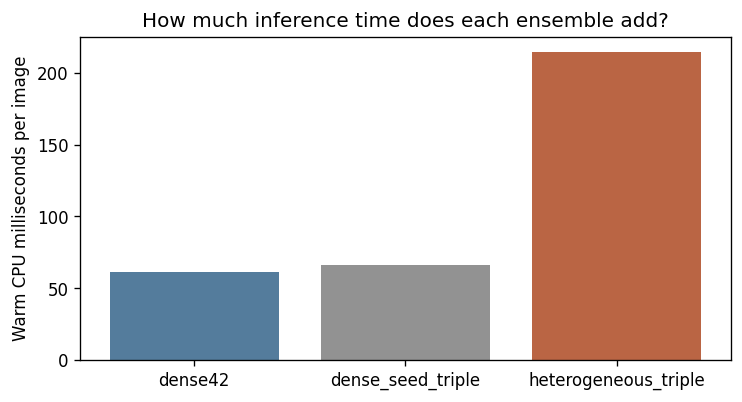

,same_score_threshold_control
0,"{'cohort': 'development', 'records': 4673, 'ta..."
1,"{'cohort': 'development', 'records': 4673, 'ta..."
2,"{'cohort': 'development', 'records': 4673, 'ta..."
3,"{'cohort': 'USED_benchmark', 'records': 624, '..."
4,"{'cohort': 'USED_benchmark', 'records': 624, '..."
5,"{'cohort': 'USED_benchmark', 'records': 624, '..."


In [16]:
ensemble_development=T("outputs/ensemble_value/development_comparison.csv")
ensemble_benchmark=T("outputs/ensemble_value/USED_comparison.csv")
timing=T("outputs/ensemble_value/timing_summary.csv")
display(ensemble_development);display(ensemble_benchmark);display(timing)
display(T("outputs/ensemble_value/paired_error_changes.csv"))
display(T("outputs/ensemble_value/pairwise_diversity.csv").head(12))
display(pd.Series(J("outputs/ensemble_value/paired_proxy_group_intervals.json")).to_frame("descriptive_proxy_group_bootstrap"))
batch_one=timing[timing.batch_size==1].set_index("pipeline")
fig,ax=plt.subplots(figsize=(7,3.5))
names=["dense42","dense_seed_triple","heterogeneous_triple"]
ax.bar(names,batch_one.loc[names,"median_ms_per_image"],color=["#547c9c","#929292","#ba6544"])
ax.set(ylabel="Warm CPU milliseconds per image",title="How much inference time does each ensemble add?")
chart(fig)
display(pd.Series(J("outputs/ensemble_value/identical_score_negative_control.json")).to_frame("same_score_threshold_control"))

#### Inference
The same-backbone seed ensemble offered little useful error improvement. Heterogeneous representations corrected some internal errors at higher measured compute cost, while benchmark transfer remained weak. The plotted latency is a recorded measurement, not a new service-speed guarantee.

#### Decision
Prefer evidence of complementary errors over model count. Report gross corrections and introduced misses, and keep resource arithmetic conditional on real costs.

### Appearance and coverage ablations with meaningful failed results

**Purpose.** Test whether padding, contrast or training-normal coverage repairs the gap.

**Method / code.** Review all six single-backbone pipelines at every declared target, source distinguishability and normal-stratum diagnostics.

,candidate,target,fn,fp,tn,tp,sensitivity,specificity,target_met
0,original_baseline,0.9975,23,196,1105,3349,0.993179,0.849347,False
1,original_baseline,0.9950,35,123,1178,3337,0.989620,0.905457,False
2,original_baseline,0.9900,45,111,1190,3327,0.986655,0.914681,False
3,gray_padding,0.9975,27,209,1092,3345,0.991993,0.839354,False
4,gray_padding,0.9950,27,209,1092,3345,0.991993,0.839354,False
5,gray_padding,0.9900,42,116,1185,3330,0.987544,0.910838,False
6,contrast_gray_padding,0.9975,18,229,1072,3354,0.994662,0.823982,False
7,contrast_gray_padding,0.9950,24,183,1118,3348,0.992883,0.859339,False
8,contrast_gray_padding,0.9900,37,131,1170,3335,0.989027,0.899308,False
9,normal_strata_weighted,0.9975,27,163,1138,3345,0.991993,0.874712,False


,candidate,target,n,threshold,accuracy,pneumonia_sensitivity,specificity,precision,f1,balanced_accuracy,roc_auc,average_precision,pr_auc_trapezoidal,binary_crossentropy,tn,fp,fn,tp
0,original_baseline,0.9975,624,0.099326,0.745192,0.997436,0.324786,0.711152,0.830309,0.661111,0.946932,0.961339,0.961263,0.634218,76,158,1,389
1,original_baseline,0.9950,624,0.107252,0.746795,0.997436,0.329060,0.712454,0.831197,0.663248,0.946932,0.961339,0.961263,0.634218,77,157,1,389
2,original_baseline,0.9900,624,0.182737,0.764423,0.994872,0.380342,0.727955,0.840737,0.687607,0.946932,0.961339,0.961263,0.634218,89,145,2,388
3,gray_padding,0.9975,624,0.068860,0.724359,0.997436,0.269231,0.694643,0.818947,0.633333,0.953364,0.967638,0.967579,0.525842,63,171,1,389
4,gray_padding,0.9950,624,0.178702,0.767628,0.997436,0.384615,0.729831,0.842904,0.691026,0.953364,0.967638,0.967579,0.525842,90,144,1,389
5,gray_padding,0.9900,624,0.186150,0.767628,0.997436,0.384615,0.729831,0.842904,0.691026,0.953364,0.967638,0.967579,0.525842,90,144,1,389
6,contrast_gray_padding,0.9975,624,0.089779,0.705128,0.997436,0.217949,0.680070,0.808732,0.607692,0.951392,0.967222,0.967166,0.636999,51,183,1,389
7,contrast_gray_padding,0.9950,624,0.173083,0.741987,0.997436,0.316239,0.708561,0.828541,0.656838,0.951392,0.967222,0.967166,0.636999,74,160,1,389
8,contrast_gray_padding,0.9900,624,0.316499,0.770833,0.997436,0.393162,0.732580,0.844734,0.695299,0.951392,0.967222,0.967166,0.636999,92,142,1,389
9,normal_strata_weighted,0.9975,624,0.172294,0.743590,0.997436,0.320513,0.709854,0.829424,0.658974,0.951698,0.965486,0.965423,0.641615,75,159,1,389


,candidate,individual_inference,decision
0,original_baseline,23 misses/196 false alerts: changing one error...,Retain failed ablation;do not adopt from expos...
3,gray_padding,27 misses/209 false alerts: changing one error...,Retain failed ablation;do not adopt from expos...
6,contrast_gray_padding,18 misses/229 false alerts: changing one error...,Retain failed ablation;do not adopt from expos...
9,normal_strata_weighted,27 misses/163 false alerts: changing one error...,Retain failed ablation;do not adopt from expos...
12,nuisance_view_training,37 misses/148 false alerts: changing one error...,Retain failed ablation;do not adopt from expos...
15,contrast_gray_weighted,22 misses/223 false alerts: changing one error...,Retain failed ablation;do not adopt from expos...


,recipe,label_id,records,source_OOF_AUC,max_iterations,purpose
0,original,0,1535,0.953235,59,Partition distinguishability of frozen image f...
1,original,1,3762,0.632667,110,Partition distinguishability of frozen image f...
2,gray_padding,0,1535,0.949680,62,Partition distinguishability of frozen image f...
3,gray_padding,1,3762,0.644534,106,Partition distinguishability of frozen image f...
4,contrast_gray_padding,0,1535,0.954926,63,Partition distinguishability of frozen image f...
5,contrast_gray_padding,1,3762,0.645302,111,Partition distinguishability of frozen image f...


,stratifier,validation_observed_FPR,used_benchmark_observed_FPR,expected_FPR_if_only_composition_changed,used_normal_coverage,interpretation
0,namespace,0.092308,0.628205,0.100032,1.0,"Descriptive standardization,not a causal attri..."
1,aspect_band,0.092308,0.628205,0.075341,1.0,"Descriptive standardization,not a causal attri..."


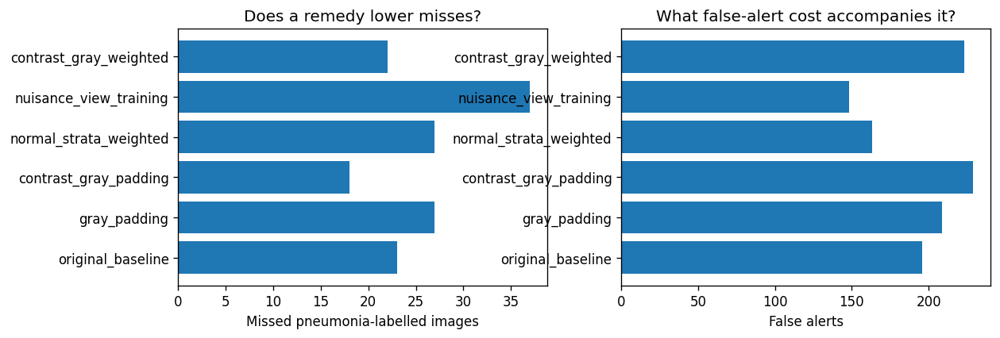

In [17]:
remediation_development=T("outputs/distribution_remediation/development_comparison.csv")
remediation_benchmark=T("outputs/distribution_remediation/USED_comparison.csv")
display(remediation_development);display(remediation_benchmark)
individual=remediation_development[np.isclose(remediation_development.target,.9975)].copy()
individual["individual_inference"]=individual.apply(lambda r:f"{int(r.fn)} misses/{int(r.fp)} false alerts: changing one error type must be weighed against the other.",axis=1)
individual["decision"]="Retain failed ablation;do not adopt from exposed-benchmark appearance."
display(individual[["candidate","individual_inference","decision"]])
display(T("outputs/distribution_remediation/embedding_source_separation.csv"))
display(T("outputs/distribution_remediation/normal_gap_composition_diagnostic.csv"))
a=remediation_development[np.isclose(remediation_development.target,.9975)]
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].barh(a.candidate,a.fn);axes[1].barh(a.candidate,a.fp)
axes[0].set(xlabel="Missed pneumonia-labelled images",title="Does a remedy lower misses?")
axes[1].set(xlabel="False alerts",title="What false-alert cost accompanies it?")
chart(fig)

#### Inference
Some recipes lower false alerts while increasing misses; others reduce misses while increasing alerts. Normal feature source-AUC stays around 0.95, but source predictability does not identify a causal shortcut or establish disease performance.

#### Decision
Preserve the bounded failure finding. Repeating these unchanged transformations is not evidence that the gap has been solved.

### RAD-DINO refinement at the revised operating goal

**Purpose.** Test a different representation using the same existing images.

**Method / code.** Compare global-token and combined global/mean-patch features with neural/logistic heads at 97%,98%,99% calibration targets. The 224-pixel full-field recipe is explicit; native 518-pixel inference is untested.

Original locked winner: rad_global_local_logistic
Original winner's benchmark rates:


,candidate,target,fn,fp,tn,tp,sensitivity,FPR,specificity,goal_met,preferred_goal_met
0,original_baseline,0.97,103,50,1251,3269,0.969454,0.038432,0.961568,False,False
1,original_baseline,0.98,73,72,1229,3299,0.978351,0.055342,0.944658,True,False
2,original_baseline,0.99,45,111,1190,3327,0.986655,0.085319,0.914681,True,False
3,gray_padding,0.97,83,66,1235,3289,0.975386,0.050730,0.949270,True,False
4,gray_padding,0.98,75,71,1230,3297,0.977758,0.054573,0.945427,True,False
5,gray_padding,0.99,42,116,1185,3330,0.987544,0.089162,0.910838,True,False
6,contrast_gray_padding,0.97,105,52,1249,3267,0.968861,0.039969,0.960031,False,False
7,contrast_gray_padding,0.98,72,79,1222,3300,0.978648,0.060723,0.939277,True,False
8,contrast_gray_padding,0.99,37,131,1170,3335,0.989027,0.100692,0.899308,True,False
9,normal_strata_weighted,0.97,92,57,1244,3280,0.972716,0.043812,0.956188,True,False


,candidate,target,threshold,fn,fp,tn,tp,sensitivity,FPR,specificity,goal_met,preferred_goal_met
0,original_baseline,0.97,0.514816,2,107,127,388,0.994872,0.457265,0.542735,False,False
1,original_baseline,0.98,0.471749,2,113,121,388,0.994872,0.482906,0.517094,False,False
2,original_baseline,0.99,0.182737,2,145,89,388,0.994872,0.619658,0.380342,False,False
3,gray_padding,0.97,0.349176,1,123,111,389,0.997436,0.525641,0.474359,False,False
4,gray_padding,0.98,0.349176,1,123,111,389,0.997436,0.525641,0.474359,False,False
5,gray_padding,0.99,0.186150,1,144,90,389,0.997436,0.615385,0.384615,False,False
6,contrast_gray_padding,0.97,0.586896,1,110,124,389,0.997436,0.470085,0.529915,False,False
7,contrast_gray_padding,0.98,0.389167,1,138,96,389,0.997436,0.589744,0.410256,False,False
8,contrast_gray_padding,0.99,0.316499,1,142,92,389,0.997436,0.606838,0.393162,False,False
9,normal_strata_weighted,0.97,0.696811,3,102,132,387,0.992308,0.435897,0.564103,False,False


,candidate,individual_inference,decision
2,original_baseline,98.665% sensitivity and 8.53% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...
5,gray_padding,98.754% sensitivity and 8.92% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...
8,contrast_gray_padding,98.903% sensitivity and 10.07% NORMAL FPR on p...,Meets pooled current point-estimate floor;not ...
11,normal_strata_weighted,98.665% sensitivity and 8.30% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...
14,nuisance_view_training,98.606% sensitivity and 7.15% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...
17,contrast_gray_weighted,99.051% sensitivity and 11.76% NORMAL FPR on p...,Meets pooled current point-estimate floor;not ...
20,rad_cls_logistic,98.339% sensitivity and 8.69% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...
23,rad_cls_mlp,98.369% sensitivity and 8.69% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...
26,rad_global_local_logistic,99.259% sensitivity and 3.23% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...
29,rad_global_local_mlp,98.903% sensitivity and 2.69% NORMAL FPR on po...,Meets pooled current point-estimate floor;not ...


,original_development_only_selection
selected_candidate,rad_global_local_logistic
selected_target,0.99
any_development_goal_met,True
selection_reason,Minimum FN thenFP among >=97%sensitivity and<=...
protocol_sha256,fc4d262e8c3b372a96364c6909cd430c956ab40fb5e20b...
final_thresholds_sha256,9625b91fd005e3451368fb1a60bbb89de0b22559d21387...
artifacts_sha256,{'models/rad_dino/final/rad_cls_logistic.jobli...
new_images,0
used_benchmark_for_selection,False
fresh_confirmation,False


,technical_error_audit
development_images,4673
reference_pipelines,6
calibration_target_for_audit,0.99
persistent_error_definition,"Wrong in at least4of6 existing pipelines, each..."
persistent_NORMAL_errors,100
persistent_PNEUMONIA_errors,30
metadata_only_outer_AUC,0.961297
metadata_fields,"[width, height, intensity_mean_256, intensity_..."
interpretation,Geometry/intensity association is not proof of...
clinical_labels_changed,0


,Exploratory RAD-DINO CLS alternative
tn,200.000000
fp,34.000000
fn,3.000000
tp,387.000000
sensitivity,0.992308
FPR,0.145299
specificity,0.854701
precision,0.919240
f1,0.954377
accuracy,0.940705


,precision,recall,f1-score,support
NORMAL,0.985222,0.854701,0.915332,234.000000
PNEUMONIA,0.919240,0.992308,0.954377,390.000000
accuracy,0.940705,0.940705,0.940705,0.940705
macro avg,0.952231,0.923504,0.934855,624.000000
weighted avg,0.943983,0.940705,0.939735,624.000000


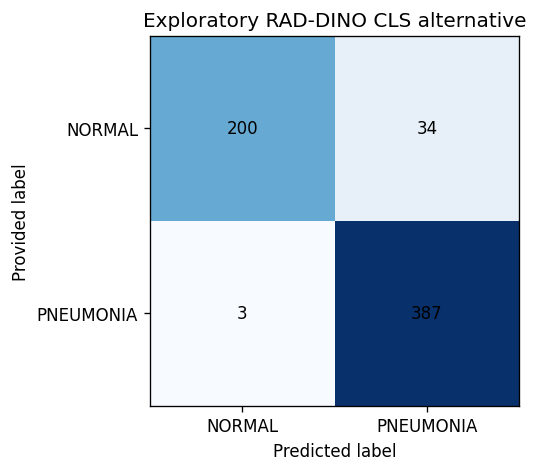

,candidate,target,fold,fn,fp,tn,tp,sensitivity,FPR,specificity,goal_met,preferred_goal_met
66,rad_cls_mlp,0.98,0,14,26,408,1109,0.987533,0.059908,0.940092,True,False
67,rad_cls_mlp,0.98,1,39,15,419,1086,0.965333,0.034562,0.965438,False,False
68,rad_cls_mlp,0.98,2,26,17,416,1098,0.976868,0.039261,0.960739,True,False


,metric,descriptive_95_low,descriptive_95_high
0,sensitivity,0.977685,0.998411
1,NORMAL FPR,0.102769,0.197080


,candidate,target,threshold,fn,fp,tn,tp,sensitivity,FPR,specificity,goal_met,preferred_goal_met
26,rad_global_local_logistic,0.99,0.618495,3,69,165,387,0.992308,0.294872,0.705128,False,False


In [18]:
rad_development=T("outputs/rad_dino/development_comparison.csv")
rad_benchmark=T("outputs/rad_dino/USED_comparison.csv")
rad_lock=J("outputs/rad_dino/before_used_benchmark_lock.json")
lead=J("outputs/rad_dino/retrospective_lead.json")
display(rad_development);display(rad_benchmark)
individual=rad_development[np.isclose(rad_development.target,.99)].copy()
individual["individual_inference"]=individual.apply(lambda r:f"{r.sensitivity*100:.3f}% sensitivity and {r.FPR*100:.2f}% NORMAL FPR on pooled development;fold and transfer checks still required.",axis=1)
individual["decision"]=individual.goal_met.map({True:"Meets pooled current point-estimate floor;not independent confirmation.",False:"Does not meet pooled current point-estimate floor."})
display(individual[["candidate","individual_inference","decision"]])
display(pd.Series(rad_lock).to_frame("original_development_only_selection"))
display(pd.Series(J("outputs/rad_dino/error_audit_status.json")).to_frame("technical_error_audit"))
lead_benchmark_predictions=T("outputs/rad_dino/"+lead["candidate"]+"_USED_scores.csv")
lead_metrics=explain_confusion(lead_benchmark_predictions,lead_benchmark_predictions.score>=lead["final_threshold"],"Exploratory RAD-DINO CLS alternative")
fold_results=T("outputs/rad_dino/fold_operating_points.csv")
lead_folds=fold_results[(fold_results.candidate==lead["candidate"])&np.isclose(fold_results.target,lead["calibration_target"])]
display(lead_folds)
display(pd.DataFrame([
 ["sensitivity",*exact_interval(lead_metrics["tp"],lead_metrics["tp"]+lead_metrics["fn"])],
 ["NORMAL FPR",*exact_interval(lead_metrics["fp"],lead_metrics["fp"]+lead_metrics["tn"])]
],columns=["metric","descriptive_95_low","descriptive_95_high"]))
assert lead_folds.sensitivity.min()<CONFIG["minimum_sensitivity"]
assert not lead["replaces_locked_selection"]
print("Original locked winner:",rad_lock["selected_candidate"])
print("Original winner's benchmark rates:")
display(rad_benchmark[(rad_benchmark.candidate==rad_lock["selected_candidate"])&np.isclose(rad_benchmark.target,rad_lock["selected_target"])])

#### Inference
The retrospective CLS neural-head setting reaches 97.66% sensitivity/4.46% FPR in pooled development and 99.23%/14.53% on the exposed cohort. One fold is below 97%; the FPR uncertainty interval extends above 15%. The original development-selected winner has a higher benchmark FPR.

#### Decision
Keep this as a promising research alternative, not a prospectively confirmed final selection. Test stability using the existing data before further architectural changes.

### Result-integrity verification across all exploratory comparisons

**Purpose.** Check that every comparison table agrees with individual scores and its locked threshold.

**Method / code.** Independently recount all 210 operating points from embedded data rather than trusting the saved summary rows.

In [19]:
VERIFIED_POINTS=[]
def check_point(cohort,candidate,target,d,q,reference):
    m=counts(d.label_id,q)
    assert len(d)==d.record_id.nunique()==(4673 if cohort=="OOF" else 624)
    for k in ["tn","fp","fn","tp"]: assert m[k]==int(reference[k]),(cohort,candidate,target,k)
    VERIFIED_POINTS.append(dict(cohort=cohort,candidate=candidate,target=target,**m))
for folder,candidate_col,targets_col,cuts_file in [
    ("ensemble_value","pipeline","target","final/thresholds.csv"),
    ("distribution_remediation","candidate","target","final/thresholds.csv"),
    ("rad_dino","candidate","target","final/thresholds.csv")]:
    prefix="outputs/"+folder+"/"
    dev=T(prefix+"development_comparison.csv");used=T(prefix+"USED_comparison.csv")
    cuts=T(prefix+cuts_file)
    for _,r in dev.iterrows():
        name=r[candidate_col];target=float(r[targets_col]);d=T(prefix+f"{name}_OOF_{target}.csv")
        check_point("OOF",name,target,d,d.prediction,r)
    for _,r in used.iterrows():
        name=r[candidate_col];target=float(r[targets_col]);d=T(prefix+f"{name}_USED_scores.csv")
        cut=cuts[(cuts[candidate_col]==name)&np.isclose(cuts[targets_col],target)].iloc[0].threshold
        check_point("USED",name,target,d,d.score>=cut,r)
prefix="outputs/cycle2/"
dev=T(prefix+"nested_oof_comparison.csv");used=T(prefix+"USED_benchmark_comparison.csv")
for _,r in dev.iterrows():
    parts=[]
    for fold in range(3):
        path=prefix+f"fold{fold}/";d=T(path+r.candidate+"_outer_scores.csv")
        cuts=T(path+"calibration_thresholds.csv")
        cut=cuts[(cuts.candidate==r.candidate)&np.isclose(cuts.target_sensitivity,r.target_sensitivity)].iloc[0].threshold
        d["prediction"]=(d.score>=cut).astype(int);parts.append(d)
    d=pd.concat(parts,ignore_index=True)
    check_point("OOF",r.candidate,r.target_sensitivity,d,d.prediction,r)
cuts=T(prefix+"final/calibration_thresholds.csv")
for _,r in used.iterrows():
    d=T(prefix+r.candidate+"_USED_benchmark_predictions.csv")
    cut=cuts[(cuts.candidate==r.candidate)&np.isclose(cuts.target_sensitivity,r.development_target)].iloc[0].threshold
    check_point("USED",r.candidate,r.development_target,d,d.score>=cut,r)
assert len(VERIFIED_POINTS)==210
print("PASS: independently recounted",len(VERIFIED_POINTS),"operating points.")
display(pd.DataFrame(VERIFIED_POINTS).groupby("cohort").size().to_frame("verified_points"))

PASS: independently recounted 210 operating points.


,verified_points
cohort,
OOF,105
USED,105


#### Inference
All confusion counts are checked against their corresponding score and threshold records. This establishes internal numerical consistency, not unbiased new-population performance.

#### Decision
Preserve the audit trail and distinguish repeated-data research from independent confirmation.

### Plain-English Summary

**What problem were we solving?**  
We needed to reduce excessive false alerts using only the images already available.

**What did we find?**  
A RAD-DINO alternative meets pooled point-estimate targets, but one fold catches only 96.53% of pneumonia cases.

**What did we build or do?**  
We compared representations, ensembles, input changes and operating thresholds while keeping failed experiments.

**Why did we do it this way?**  
Different approaches reveal different error patterns; repeated benchmark exposure limits what these comparisons can prove.

**What should we do next?**  
Check the promising neural head across seeds and group splits; do not call the benchmark untouched again.

## Stage 6 — Practical Output and Case Studies

### Finalized-method predictions and workload interpretation

**Purpose.** Show what the original finalized rule produces for individual images.

**Method / code.** Use only its exact recorded prediction frame and pipeline identity for this stage. These are image-level research scores, not calibrated clinical risks.

In [20]:
FINAL_CASES=FINAL_PREDICTIONS.copy()
FINAL_CASES["pipeline_id"]=FINAL_PIPELINE_ID
FINAL_CASES["research_score"]=FINAL_CASES.pneumonia_probability
ranked=FINAL_CASES.sort_values(["research_score","record_id"],ascending=[False,True])
display(ranked[["record_id","label","research_score","prediction","outcome","pipeline_id"]].head(12))
positive_calls=int(FINAL_CASES.prediction.sum())
display(pd.Series({
 "images":len(FINAL_CASES),"positive_calls_requiring_review":positive_calls,
 "true_pneumonia_flags":final_metrics["tp"],"false_normal_flags":final_metrics["fp"],
 "missed_pneumonia_images":final_metrics["fn"],
 "interpretation":"Research outputs;no new clinical risk calibration or deployment claim"
}).to_frame("practical_workload"))
assert FINAL_CASES.pipeline_id.nunique()==1

,record_id,label,research_score,prediction,outcome,pipeline_id
265,12f9c1c1cbd980a4661a,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
266,1df6bc76d86dee41832c,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
262,9e3c13cb2630f23212e7,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
343,b1f96811ed666dcf6397,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
318,2bda590bd835ee30700a,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
396,954aa06628757b5940a0,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
562,48cc9aba74c9e7f81d59,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
269,696518037a63a685d04c,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
261,8aa230c9a7a06280ea03,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...
312,956b13d034696015d194,PNEUMONIA,1.0,1,TP,604dd6ef3d2c31bb293729e0b58e66a82cf5fbed776df6...


,practical_workload
images,624
positive_calls_requiring_review,536
true_pneumonia_flags,389
false_normal_flags,147
missed_pneumonia_images,1
interpretation,Research outputs;no new clinical risk calibrat...


#### Inference
The original model sends most benchmark images to the positive class, including many normal images. A useful practical report must expose review workload rather than presenting sensitivity alone.

#### Decision
Use the outputs for research inspection and error review. Do not recommend autonomous diagnosis or claim resource savings without real workflow costs.

### Representative errors, explanations and case traceability

**Purpose.** Make the error types inspectable without implying that visual inspection adjudicates disease.

**Method / code.** Join recorded gallery IDs to the same final-model prediction frame, and display the saved original error examples. Case studies do not switch to another model or threshold.

Case status: clinically unreviewed;same frozen artifact identity and decisions as final evaluation.


,record_id,label,research_score,prediction,outcome
29,0372ccf7c55c06342fe9,NORMAL,0.314190,1,FP
56,0bbf66dc684804142649,NORMAL,0.999791,1,FP
66,0225c78d6b5e3c37caf2,NORMAL,0.988854,1,FP
147,09333f6a4de0fecab295,NORMAL,0.998647,1,FP
149,00bb39043e47b07c789d,NORMAL,0.968942,1,FP
156,0457095d31b31d29fa55,NORMAL,0.582441,1,FP
391,36e7991d6402945544be,PNEUMONIA,0.019598,0,FN


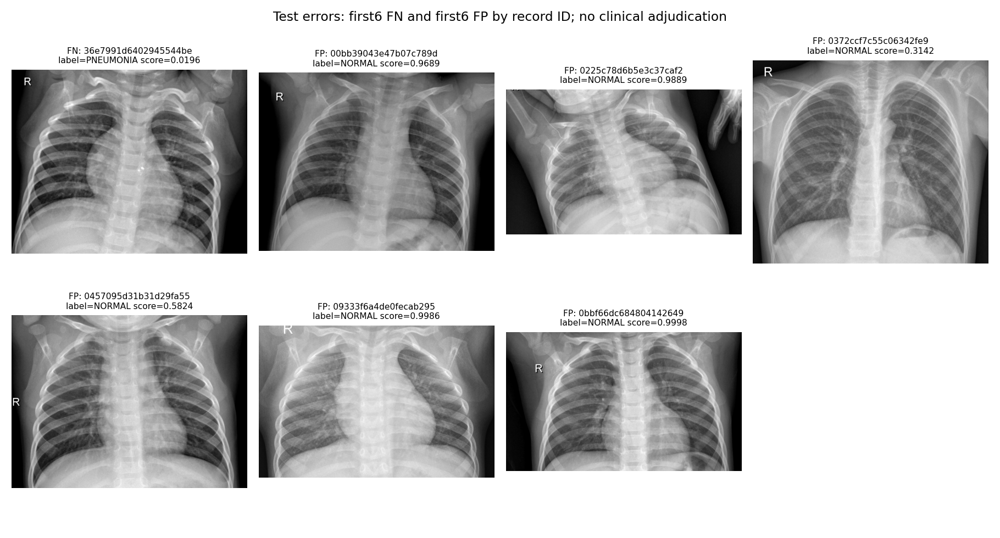

In [21]:
gallery=T("outputs/final_test/error_figure_cases.csv")
assert set(gallery.record_id).issubset(set(FINAL_CASES.record_id))
case_studies=FINAL_CASES[FINAL_CASES.record_id.isin(gallery.record_id)].copy()
assert case_studies.pipeline_id.eq(FINAL_PIPELINE_ID).all()
reference=FINAL_PREDICTIONS.set_index("record_id").loc[case_studies.record_id]
assert np.array_equal(case_studies.prediction.to_numpy(),reference.prediction.to_numpy())
assert np.array_equal(case_studies.pneumonia_probability.to_numpy(),reference.pneumonia_probability.to_numpy())
display(case_studies[["record_id","label","research_score","prediction","outcome"]])
F("outputs/final_test/figures/05_test_error_examples.png")
print("Case status: clinically unreviewed;same frozen artifact identity and decisions as final evaluation.")

#### Inference
Question: what do the finalized rule's errors look like? The examples illustrate false negatives and false positives from the same pipeline, but their appearance cannot validate labels or prove why the model failed.

#### Decision
Keep cases unreviewed until qualified assessment. Preserve Grad-CAM's limitation as a coarse explanation rather than validated lesion localization.

### Plain-English Summary

**What problem were we solving?**  
We needed to translate model metrics into individual flags and review workload.

**What did we find?**  
The original finalized model produces many unnecessary positive calls despite catching nearly all provided pneumonia images.

**What did we build or do?**  
We showed score-ranked records and representative errors tied to its exact pipeline identity.

**Why did we do it this way?**  
A practical output must use the same method as evaluation and reveal the burden of mistakes.

**What should we do next?**  
Use these records for research review and keep the newer RAD-DINO alternative separately labelled.

## Stage 7 — Project Findings

### Final findings, limitations and future scope

**Purpose.** Make a defensible decision from the complete evidence.

**Method / code.** Summarize the original transfer failure and later candidate evidence; keep population, labeling, uncertainty and computational limitations explicit.

In [22]:
findings=pd.DataFrame([
 ["Data quality","Exact training copies removed;known groups kept disjoint","True patient/site/clinical identity remains unknown"],
 ["Original final rule",f"{final_metrics['tp']} pneumonia flags;{final_metrics['fn']} misses;{final_metrics['fp']} false normal alerts","Excessive normal false-alert burden"],
 ["Representation research","RAD-DINO CLS alternative meets pooled point targets","Retrospective attention;one fold below97%;benchmark exposed"],
 ["Compute","Recorded ensemble gains require more CPU work","No new RAD latency measurement or invented financial benefit"],
 ["Clinical interpretation","Provided labels and image-level task only","No independent clinical validation or label adjudication"],
 ["Next work","Repeat seeds/group assessment;consider518/anatomical views","Existing data only;no promised generalization guarantee"]
],columns=["area","finding","decision boundary"])
display(findings)

,area,finding,decision boundary
0,Data quality,Exact training copies removed;known groups kep...,True patient/site/clinical identity remains un...
1,Original final rule,389 pneumonia flags;1 misses;147 false normal ...,Excessive normal false-alert burden
2,Representation research,RAD-DINO CLS alternative meets pooled point ta...,Retrospective attention;one fold below97%;benc...
3,Compute,Recorded ensemble gains require more CPU work,No new RAD latency measurement or invented fin...
4,Clinical interpretation,Provided labels and image-level task only,No independent clinical validation or label ad...
5,Next work,Repeat seeds/group assessment;consider518/anat...,Existing data only;no promised generalization ...


#### Inference
The work supports a promising current-data direction and a reproducible error analysis. It does not establish a clinically safe system or universal transfer across unseen hospitals.

#### Decision
Retain the original finalized artifact as historical final evaluation, carry the CLS neural head forward as a research candidate, and prioritize stability over extra model count.

### Plain-English Summary

**What problem were we solving?**  
We needed a clear project conclusion without hiding the trade-offs.

**What did we find?**  
We found a major reduction in false alerts for a research alternative, but consistency and independent generalization remain unresolved.

**What did we build or do?**  
We retained successful and failed experiments, uncertainty, provenance and practical cases.

**Why did we do it this way?**  
A sound decision requires more than the best observed accuracy or a single favorable benchmark row.

**What should we do next?**  
Run a declared stability study on the candidate using the existing images and preserve the exposed-benchmark limitation.

## Reproducibility Implementation and Execution Contract

### Embedded modeling implementation

**Purpose.** Provide readable implementation for all model-training, feature, calibration, diagnostic and reporting routines without supplied companion scripts.

**Method / code.** The following cells register the complete scientific source and the transfer-training orchestrator. Hashes and syntax are checked. Notebook-build, archive-packaging and obsolete maintenance scripts have been removed from the active implementation appendix; meaningful scientific experiments remain.

These are source definitions, not claims that their historical training has just been rerun. Generated working files for an optional new fit are created by this notebook itself. Module imports inside registered source belong to isolated model namespaces; review imports and configuration remain centralized above.

In [23]:
SOURCE_TEXT={}
SOURCE_SHA256={}
def register_source(name,text,digest):
    assert hashlib.sha256(text.encode()).hexdigest()==digest,name
    compile(text,name,"exec")
    SOURCE_TEXT[name]=text;SOURCE_SHA256[name]=digest

In [24]:
register_source('run_milestone4.py', """\"\"\"Run the three frozen transfer comparisons, then fine-tune one validation candidate.\"\"\"
import argparse
import json
from pathlib import Path
import subprocess
import sys

ROOT=Path(__file__).resolve().parent


def run(cache):
    names=['mobilenet_v2','efficientnet_b0','densenet121']
    for name in names:
        subprocess.run([sys.executable,str(ROOT/'src/transfer_learning.py'),'--phase','frozen',
                        '--model',name,'--feature-cache',str(cache)],check=True)
    summaries=[json.loads((ROOT/f'outputs/transfer_learning/{name}/frozen_summary.json').read_text()) for name in names]
    chosen=min(summaries,key=lambda x:(x['validation_metrics']['binary_crossentropy'],x['model']))
    selection={'rule':'minimum frozen-head validation binary cross-entropy; not maximum accuracy',
               'selected_model':chosen['model'],'frozen_validation_bce':chosen['validation_metrics']['binary_crossentropy'],
               'test_used':False,'fine_tuning_budget_epochs':3,'fine_tuning_lr':1e-5}
    (ROOT/'outputs/transfer_learning/fine_tune_selection.json').write_text(json.dumps(selection,indent=2))
    print('FINE_TUNE_SELECTION',json.dumps(selection),flush=True)
    subprocess.run([sys.executable,str(ROOT/'src/transfer_learning.py'),'--phase','fine_tune',
                    '--model',chosen['model'],'--feature-cache',str(cache)],check=True)
    print('MILESTONE_4_TRAINING_COMPLETE',flush=True)


if __name__=='__main__':
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--feature-cache',type=Path,default=ROOT.parent/'transfer_feature_cache')
    run(p.parse_args().feature_cache)
""", 'de28fc4f66bc9e84646a3dd4977448c7a273a1fb3fd597fb468c52200eff6041')

In [25]:
register_source('src/baseline_reporting.py', """\"\"\"Observed CNN validation figures and milestone report; no test evaluation.\"\"\"
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve,precision_recall_curve,confusion_matrix

from eda import style
from cnn_baseline import metrics_from_predictions

ROOT=Path(__file__).resolve().parents[1]


def create_reports():
    out=ROOT/'outputs/cnn_baseline'
    summary=json.loads((out/'run_summary.json').read_text())
    config=json.loads((out/'training_configuration.json').read_text())
    metrics=json.loads((out/'validation_metrics.json').read_text())
    comparator=json.loads((out/'majority_comparator.json').read_text())
    predictions=pd.read_csv(out/'validation_predictions.csv')
    history=pd.read_csv(out/'history.csv')
    validation=pd.read_csv(ROOT/'data/manifests/validation.csv')
    assert predictions.record_id.tolist()==validation.record_id.tolist()
    assert predictions.label_id.tolist()==validation.label_id.tolist()
    calculated=metrics_from_predictions(predictions.label_id,predictions.pneumonia_probability)
    for name in ['accuracy','pneumonia_sensitivity','specificity','precision','f1','balanced_accuracy','roc_auc','average_precision','pr_auc_trapezoidal','binary_crossentropy']:
        assert abs(calculated[name]-metrics[name])<1e-6,name
    assert metrics['tn']+metrics['fp']==195 and metrics['fn']+metrics['tp']==505
    assert len(predictions)==700
    assert config['threshold']==0.5 and not summary['test_evaluated']
    assert abs(metrics['binary_crossentropy']-history.val_loss.min())<1e-4
    style()
    curves=ROOT/'outputs/training_curves';curves.mkdir(parents=True,exist_ok=True)
    evaluation=ROOT/'outputs/evaluation';evaluation.mkdir(parents=True,exist_ok=True)
    fig,axes=plt.subplots(1,3,figsize=(15,4.4))
    for ax,key,title in [(axes[0],'loss','Binary cross-entropy'),(axes[1],'accuracy','Accuracy'),(axes[2],'roc_auc','ROC-AUC (Keras approximation)')]:
        ax.plot(history.epoch,history[key],marker='o',markersize=3,color='#287b8e',label='Training, stochastic')
        ax.plot(history.epoch,history['val_'+key],marker='o',markersize=3,color='#bd653c',label='Validation, inference')
        ax.axvline(summary['best_epoch'],ls='--',color='#52687b',lw=1,label='Selected by validation BCE' if key=='loss' else None)
        ax.set(xlabel='Completed epoch',ylabel=title,title=title);ax.grid(alpha=.15);ax.legend(frameon=False,fontsize=8)
    fig.suptitle('Custom CNN baseline — observed training history',fontsize=18,fontweight='bold',y=1.04)
    fig.text(.5,-.05,'Training metrics include augmentation, dropout and batch statistics. Validation uses deterministic inference; the curves are not identical protocols.',ha='center',fontsize=9)
    fig.tight_layout();fig.savefig(curves/'custom_cnn_history.png',dpi=150,bbox_inches='tight');plt.close(fig)

    cm=np.asarray(metrics['confusion_matrix'])
    fig,ax=plt.subplots(figsize=(6.2,5.3))
    ax.imshow(cm,cmap='Blues')
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=25,color='white' if cm[i,j]>cm.max()/2 else '#182d40')
    ax.set_xticks([0,1],['NORMAL','PNEUMONIA']);ax.set_yticks([0,1],['NORMAL','PNEUMONIA'])
    ax.set(xlabel='Predicted label',ylabel='Supplied label',title='Validation confusion matrix · threshold 0.5')
    fig.text(.5,.02,f'n = 700 · False negatives = {metrics["fn"]} · False positives = {metrics["fp"]}',ha='center')
    fig.tight_layout(rect=(0,.05,1,1));fig.savefig(evaluation/'custom_cnn_validation_confusion.png',dpi=150,bbox_inches='tight');plt.close(fig)

    fpr,tpr,_=roc_curve(predictions.label_id,predictions.pneumonia_probability)
    precision,recall,_=precision_recall_curve(predictions.label_id,predictions.pneumonia_probability)
    fig,axes=plt.subplots(1,2,figsize=(11,4.6))
    axes[0].plot(fpr,tpr,color='#287b8e',lw=2,label=f'ROC-AUC = {metrics["roc_auc"]:.4f}')
    axes[0].plot([0,1],[0,1],ls='--',color='#89949a',label='Random ranking reference')
    axes[0].scatter([1-metrics['specificity']],[metrics['pneumonia_sensitivity']],color='#bd653c',s=35,label='Threshold 0.5')
    axes[0].set(xlabel='False positive rate',ylabel='Pneumonia sensitivity',title='Validation ROC curve')
    axes[1].plot(recall,precision,color='#287b8e',lw=2,label=f'Average precision = {metrics["average_precision"]:.4f}')
    prevalence=float(predictions.label_id.mean())
    axes[1].axhline(prevalence,ls='--',color='#89949a',label=f'Prevalence reference = {prevalence:.3f}')
    axes[1].scatter([metrics['pneumonia_sensitivity']],[metrics['precision']],color='#bd653c',s=35,label='Threshold 0.5')
    axes[1].set(xlabel='Pneumonia recall',ylabel='Pneumonia precision',title='Validation precision–recall curve')
    for ax in axes:ax.set_xlim(-.02,1.02);ax.set_ylim(-.02,1.02);ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.15)
    fig.suptitle('Validation ranking performance — not test results',fontsize=17,fontweight='bold',y=1.04)
    fig.tight_layout();fig.savefig(evaluation/'custom_cnn_validation_roc_pr.png',dpi=150,bbox_inches='tight');plt.close(fig)

    fig,ax=plt.subplots(figsize=(8,4.3))
    for label,color in [('NORMAL','#287b8e'),('PNEUMONIA','#bd653c')]:
        v=predictions[predictions.label.eq(label)].pneumonia_probability
        ax.hist(v,bins=np.linspace(0,1,31),histtype='step',density=True,lw=2,color=color,label=label)
    ax.axvline(.5,color='#52687b',ls='--',label='Fixed threshold 0.5')
    ax.set(xlabel='Model score for PNEUMONIA',ylabel='Density within supplied class',title='Validation score distributions')
    ax.legend(frameon=False);ax.grid(alpha=.15)
    fig.tight_layout();fig.savefig(evaluation/'custom_cnn_validation_scores.png',dpi=150,bbox_inches='tight');plt.close(fig)

    rows=[]
    for label,key in [('Accuracy','accuracy'),('Pneumonia sensitivity','pneumonia_sensitivity'),('Specificity','specificity'),('Precision','precision'),('F1','f1'),('Balanced accuracy','balanced_accuracy'),('ROC-AUC','roc_auc'),('Average precision','average_precision'),('PR-AUC, trapezoidal','pr_auc_trapezoidal'),('Binary cross-entropy','binary_crossentropy')]:
        rows.append({'metric':label,'validation_value':metrics[key]})
    pd.DataFrame(rows).to_csv(evaluation/'custom_cnn_validation_metrics.csv',index=False)
    report=f'''# Milestone 3 — Custom CNN Baseline

Project PRAICP-1012. This phase extends the completed audit and data-preparation notebook. Results below are measured validation results; the test set has not been evaluated.

## Data and controls

The frozen Milestone 2 manifests contain 3,973 training and 700 new validation images. Their source hashes were checked before training. The reserved 624-image test set, 618-image test sensitivity subset and 16-image original validation partition were not used for training or scoring in this milestone. The same cautious filename/similarity grouping limitations remain: true patient identity is unverified, and similarity candidates are unconfirmed.

## Architecture and training

This is a randomly initialized, {summary['parameters']:,}-parameter CNN with four Conv2D → BatchNormalization → ReLU → MaxPooling blocks (16, 32, 64 and 128 channels), block dropout, global average pooling, a 64-unit dense head, dropout 0.4 and a sigmoid output. The first convolution uses stride 2 to control CPU computation. Input images retain the shared 224 × 224 RGB geometry and custom-CNN division by 255. Training uses the previously validated mild augmentation.

A global seed-42 training permutation avoids class-ordered input, followed by a bounded 128-image shuffle. A disk cache stores deterministic resized inputs before stochastic augmentation; it is omitted from the deliverable and can be rebuilt. No full-resolution image collection is loaded into RAM. Adam starts at 0.001 with unweighted binary cross-entropy and batch size 32. Maximum budget is {summary['maximum_epochs']} epochs; early stopping monitors validation BCE with patience 4 and min_delta 0.0001, while plateau reduction halves learning rate after two non-improving epochs, down to 0.00001. No class weighting, sampling experiment, architecture search or threshold search was performed.

The actual run completed {summary['epochs_completed']} epochs in {summary['elapsed_training_seconds']/60:.2f} minutes on CPU. Epoch {summary['best_epoch']} had minimum recorded validation BCE and its saved checkpoint was explicitly reloaded. This minimum-BCE checkpoint is the baseline artifact, not a final project model.

## Validation results at fixed threshold 0.5

| Metric | Value |
|---|---:|
'''
    for row in rows:report+=f'| {row["metric"]} | {row["validation_value"]:.6f} |\\n'
    report+=f'''
Confusion matrix, rows = supplied NORMAL/PNEUMONIA labels and columns = predictions: {metrics['confusion_matrix']}. There are {metrics['tn']} true negatives, {metrics['fp']} false positives, {metrics['fn']} false negatives and {metrics['tp']} true positives.

Average precision is reported separately from trapezoidal PR-AUC. Both use complete validation prediction rankings. Epoch-level Keras AUC metrics are threshold-grid approximations and may differ slightly from the post-run scikit-learn ranking metrics.

The majority label is chosen from training only. Always predicting that label scores validation accuracy {comparator['validation_accuracy']:.6f} and balanced accuracy {comparator['validation_balanced_accuracy']:.6f}; its confusion matrix is {comparator['validation_confusion_matrix']}. This contextualizes accuracy without claiming that high sensitivity alone is sufficient.

## Interpretation and limitations

Training/validation curves are included, with the selected epoch marked. Validation BCE increased from {history.val_loss.iloc[0]:.6f} in the first epoch to {history.val_loss.iloc[-1]:.6f} in the last; last-epoch validation accuracy was {history.val_accuracy.iloc[-1]:.6f}. Meanwhile training accuracy increased from {history.accuracy.iloc[0]:.6f} to {history.accuracy.iloc[-1]:.6f}. This is a materially unstable validation trajectory. Checkpoint restoration avoids reporting the degraded last epoch as the baseline, but does not resolve that instability. Its cause was not isolated; overfitting, batch-normalization inference statistics, input shifts and optimizer dynamics are hypotheses rather than established explanations. No follow-up parameter search was performed in this milestone.

Training metrics are measured under dropout, augmentation and batch-normalization batch statistics; validation is deterministic inference. Their difference is not a clean, matched-protocol estimate of overfitting. Predictions and all reported metrics are generated from the restored checkpoint. A serialization round trip produced matching predictions on a real validation batch.

This is one seed and one data split. The validation set was used to select a checkpoint and drive callbacks, so its scores are development estimates, not unbiased final performance. No confidence intervals or calibration claims are made. Clinical labels and true patient identities remain unverified. The conservative quarantine policy changes the development sample; acquisition shortcuts and external generalization remain open questions.

## Reproduction and deliverables

The model is in `models/custom_cnn_baseline/baseline.keras`; `best.keras` is the minimum-validation-loss checkpoint. `outputs/cnn_baseline/` contains configuration, architecture, model summary, epoch history, validation predictions, metrics, comparator and elapsed time. `outputs/training_curves/` and `outputs/evaluation/` contain the figures. Original Milestone 1–2 notebook cells and their outputs are retained, followed by new Milestone 3 sections.

From the project root after reconstructing working images, run `python src/cnn_baseline.py --epochs 15 --cache-dir /path/to/local/cache`. The script refuses to overwrite a completed baseline; move an existing completed run aside before deliberately starting a new experiment. Actual model-fitting is not triggered by opening or reviewing the notebook.

## Next milestone

Milestone 4 compares MobileNetV2, EfficientNetB0 and DenseNet121 using the same frozen training/validation membership. Class-weighting, threshold tuning and broader error analysis remain planned work. Keep the final test set reserved until the selected model and threshold are frozen.

## Callback references

- https://keras.io/api/callbacks/early_stopping/
- https://keras.io/api/callbacks/reduce_lr_on_plateau/
- https://keras.io/api/callbacks/model_checkpoint/
'''
    (ROOT/'docs/MILESTONE_3_REPORT.md').write_text(report)
    checks={'metrics_recomputed_from_saved_predictions':True,'validation_row_order_matches_manifest':True,
            'confusion_counts_match_class_sizes':True,'reserved_test_scored':False,'fixed_threshold':0.5,
            'selected_checkpoint_predictions_finite':True,'serialized_predictions_match':summary['serialized_predictions_match'],
            'all_checks_passed':True}
    (out/'report_checks.json').write_text(json.dumps(checks,indent=2))
    print(json.dumps(metrics,indent=2))
    return metrics


if __name__=='__main__':create_reports()
""", '67a74844d3a484f2c420d897d2e50d24686a5cb64c8d234f6b48d5e9f257daab')

In [26]:
register_source('src/cnn_baseline.py', """\"\"\"Milestone 3: one from-scratch CNN baseline on frozen development manifests.\"\"\"
from __future__ import annotations

import argparse
import hashlib
import json
import os
import time
from pathlib import Path

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
os.environ.setdefault('TF_DETERMINISTIC_OPS','1')
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (accuracy_score,average_precision_score,balanced_accuracy_score,
                             confusion_matrix,f1_score,log_loss,precision_score,recall_score,
                             roc_auc_score,precision_recall_curve,auc)

from input_pipeline import configure,make_dataset,decode_resize,resolve_image_paths,augmentation,preprocess

ROOT=Path(__file__).resolve().parents[1]
CONFIG={'seed':42,'input_shape':[224,224,3],'batch_size':32,'maximum_epochs':15,
        'filters':[16,32,64,128],'first_conv_stride':2,'dense_units':64,'head_dropout':0.4,
        'optimizer':'Adam','initial_learning_rate':0.001,'loss':'binary_crossentropy',
        'class_weight':None,'threshold':0.5,'threshold_tuned':False,
        'checkpoint_monitor':'val_loss','early_stopping_patience':4,
        'early_stopping_min_delta':0.0001,'reduce_lr_patience':2,'reduce_lr_factor':0.5,
        'minimum_learning_rate':0.00001,'batchnorm_momentum':0.9,
        'input_cache':'optional per-image disk cache before shuffle/augmentation; no full-resolution RAM preload',
        'test_evaluated':False,'pretrained_weights':False}


def json_write(path,value):
    path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,indent=2,default=lambda v:v.item() if isinstance(v,np.generic) else str(v)))


def build_model():
    inputs=tf.keras.Input(shape=tuple(CONFIG['input_shape']),name='rgb_224_rescaled_0_1')
    x=inputs
    for i,filters in enumerate(CONFIG['filters']):
        x=tf.keras.layers.Conv2D(filters,3,strides=2 if i==0 else 1,padding='same',use_bias=False,name=f'conv_{i+1}')(x)
        x=tf.keras.layers.BatchNormalization(momentum=CONFIG['batchnorm_momentum'],name=f'bn_{i+1}')(x)
        x=tf.keras.layers.Activation('relu',name=f'relu_{i+1}')(x)
        x=tf.keras.layers.MaxPooling2D(2,name=f'pool_{i+1}')(x)
        x=tf.keras.layers.Dropout(0.1+i*0.05,name=f'block_dropout_{i+1}')(x)
    x=tf.keras.layers.GlobalAveragePooling2D(name='global_average_pool')(x)
    x=tf.keras.layers.Dense(CONFIG['dense_units'],activation='relu',name='dense_64')(x)
    x=tf.keras.layers.Dropout(CONFIG['head_dropout'],name='head_dropout')(x)
    output=tf.keras.layers.Dense(1,activation='sigmoid',name='pneumonia_probability')(x)
    model=tf.keras.Model(inputs,output,name='custom_cnn_baseline')
    model.compile(optimizer=tf.keras.optimizers.Adam(CONFIG['initial_learning_rate']),
                  loss='binary_crossentropy',metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),
                  tf.keras.metrics.AUC(name='roc_auc',curve='ROC'),
                  tf.keras.metrics.AUC(name='pr_auc',curve='PR'),
                  tf.keras.metrics.Precision(name='precision'),tf.keras.metrics.Recall(name='sensitivity')])
    return model


def verify_frozen_inputs():
    protocol=json.loads((ROOT/'outputs/quality/frozen_protocol.json').read_text())
    # Prior source/manifest identities stay frozen; the baseline adds a new module only.
    for path,digest in protocol['files_sha256'].items():
        assert hashlib.sha256((ROOT/path).read_bytes()).hexdigest()==digest,path
    train=pd.read_csv(ROOT/'data/manifests/train.csv',keep_default_na=False)
    val=pd.read_csv(ROOT/'data/manifests/validation.csv',keep_default_na=False)
    assert len(train)==3973 and len(val)==700
    assert set(train.final_split)=={'train'} and set(val.final_split)=={'validation'}
    for col in ['record_id','pixel_sha256','patient_proxy','leakage_group']:
        assert not set(train[col])&set(val[col]),col
    return train,val


def cached_dataset(frame,training,cache_dir):
    \"\"\"Disk-cache deterministic resized images, then shuffle paths/data before augmentation.\"\"\"
    paths=resolve_image_paths(frame,ROOT)
    for p in paths:
        if not Path(p).is_file():raise FileNotFoundError(p)
    ds=tf.data.Dataset.from_tensor_slices((paths,frame.label_id.to_numpy(dtype=np.int32)))
    ds=ds.map(decode_resize,num_parallel_calls=2,deterministic=True)
    # Cache key binds order, file identities and the fixed preprocessing code.
    signature=hashlib.sha256((''.join(frame.record_id)+''.join(frame.sha256)+
        hashlib.sha256((ROOT/'src/input_pipeline.py').read_bytes()).hexdigest()).encode()).hexdigest()[:16]
    cache_dir.mkdir(parents=True,exist_ok=True)
    ds=ds.cache(str(cache_dir/('train_' if training else 'validation_'))+signature)
    if training:
        # Decoded shuffle buffer is intentionally small (~74 MiB), unlike a path shuffle.
        ds=ds.shuffle(128,seed=CONFIG['seed'],reshuffle_each_iteration=True)
    ds=ds.batch(CONFIG['batch_size'],drop_remainder=False)
    if training:
        aug=augmentation(CONFIG['seed'])
        ds=ds.map(lambda x,y:(preprocess(aug(x,training=True),'custom_cnn'),y),num_parallel_calls=1,deterministic=True)
    else:ds=ds.map(lambda x,y:(preprocess(x,'custom_cnn'),y),num_parallel_calls=2,deterministic=True)
    options=tf.data.Options();options.experimental_deterministic=True
    options.threading.private_threadpool_size=2;options.threading.max_intra_op_parallelism=2
    return ds.with_options(options).prefetch(2)


class Progress(tf.keras.callbacks.Callback):
    def __init__(self,directory):super().__init__();self.directory=directory;self.rows=[]
    def on_epoch_begin(self,epoch,logs=None):
        self.start=time.perf_counter()
        self.lr=float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        print(f'BEGIN epoch {epoch+1}/{CONFIG["maximum_epochs"]}',flush=True)
    def on_train_batch_end(self,batch,logs=None):
        if (batch+1)%25==0:print(f'  batch {batch+1}/125, loss={logs.get("loss",float("nan")):.4f}',flush=True)
    def on_epoch_end(self,epoch,logs=None):
        row={'epoch':epoch+1,'epoch_seconds':time.perf_counter()-self.start,'learning_rate_used':self.lr,
             **{k:float(v) for k,v in (logs or {}).items()}}
        self.rows.append(row)
        pd.DataFrame(self.rows).to_csv(self.directory/'history.csv',index=False)
        json_write(self.directory/'training_progress.json',{'completed_epochs':epoch+1,'latest':row})
        print('EPOCH_RESULT '+json.dumps(row),flush=True)


def metrics_from_predictions(y,p,threshold=0.5):
    y=np.asarray(y,dtype=np.int32);p=np.asarray(p,dtype=float)
    assert len(y)==len(p) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    pred=(p>=threshold).astype(np.int32)
    tn,fp,fn,tp=map(int,confusion_matrix(y,pred,labels=[0,1]).ravel())
    precision,recall,_=precision_recall_curve(y,p)
    return {'n':len(y),'threshold':threshold,'accuracy':accuracy_score(y,pred),
            'pneumonia_sensitivity':recall_score(y,pred,zero_division=0),'specificity':tn/(tn+fp),
            'precision':precision_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,pred),'roc_auc':roc_auc_score(y,p),
            'average_precision':average_precision_score(y,p),'pr_auc_trapezoidal':auc(recall,precision),
            'binary_crossentropy':log_loss(y,p,labels=[0,1]),
            'tn':tn,'fp':fp,'fn':fn,'tp':tp,'confusion_matrix':[[tn,fp],[fn,tp]]}


def run(max_epochs=15,cache_dir=None):
    CONFIG['maximum_epochs']=int(max_epochs)
    configure(CONFIG['seed'])
    # Keep the M2 pipeline source untouched; record the execution-specific CPU setting.
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    out=ROOT/'outputs/cnn_baseline';out.mkdir(parents=True,exist_ok=True)
    models=ROOT/'models/custom_cnn_baseline';models.mkdir(parents=True,exist_ok=True)
    if (out/'run_summary.json').exists():
        raise FileExistsError('A completed baseline already exists. Archive it before requesting a new experiment.')
    train,val=verify_frozen_inputs()
    # Source manifests are class-ordered. Globally permute training rows before a
    # bounded decoded-image shuffle, otherwise early batches would be class-pure.
    train=train.sample(frac=1,random_state=CONFIG['seed']).reset_index(drop=True)
    configuration={**CONFIG,'training_images':len(train),'validation_images':len(val),
                   'tensorflow':tf.__version__,'keras':tf.keras.__version__,
                   'gpu_count':len(tf.config.list_physical_devices('GPU')),
                   'intra_op_threads':tf.config.threading.get_intra_op_parallelism_threads(),
                   'manifest_sha256':{s:hashlib.sha256((ROOT/f'data/manifests/{s}.csv').read_bytes()).hexdigest() for s in ['train','validation','test']},
                   'source_sha256':hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
                   'disk_cache_enabled':cache_dir is not None,
                   'initial_training_order':'global pandas permutation with seed 42 before cache/bounded shuffle',
                   'training_shuffle_buffer':128 if cache_dir else min(len(train),2048)}
    # The test manifest is hashed for provenance only; no test images are opened here.
    json_write(out/'training_configuration.json',configuration)
    model=build_model()
    lines=[];model.summary(print_fn=lambda s:lines.append(s))
    (out/'model_summary.txt').write_text('\\n'.join(lines))
    (out/'model_architecture.json').write_text(model.to_json())
    if cache_dir:
        train_ds=cached_dataset(train,True,cache_dir)
        val_ds=cached_dataset(val,False,cache_dir)
    else:
        train_ds=make_dataset(train,training=True,root=ROOT)
        val_ds=make_dataset(val,training=False,root=ROOT)
    progress=Progress(out)
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(str(models/'best.keras'),monitor='val_loss',mode='min',save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss',mode='min',patience=CONFIG['early_stopping_patience'],
                                        min_delta=CONFIG['early_stopping_min_delta'],restore_best_weights=True,verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',mode='min',factor=.5,patience=2,min_lr=1e-5,verbose=1),
        tf.keras.callbacks.TerminateOnNaN(),progress]
    started=time.perf_counter()
    print('TRAINING_CONFIG '+json.dumps(configuration),flush=True)
    model.fit(train_ds,validation_data=val_ds,epochs=max_epochs,callbacks=callbacks,verbose=0,shuffle=False)
    elapsed=time.perf_counter()-started
    # Explicitly reload minimum-val-loss checkpoint, independent of early-stop min_delta.
    best=tf.keras.models.load_model(models/'best.keras')
    p=best.predict(val_ds,verbose=0).reshape(-1)
    evaluation=metrics_from_predictions(val.label_id,p,CONFIG['threshold'])
    predictions=val[['record_id','label','label_id','patient_proxy','leakage_group']].copy()
    predictions['pneumonia_probability']=p
    predictions['prediction_at_0_5']=(p>=.5).astype(int)
    predictions['correct']=predictions.prediction_at_0_5.eq(predictions.label_id)
    predictions.to_csv(out/'validation_predictions.csv',index=False)
    # Serialization check: compare restored inference with an independent reload on a real batch.
    x,_=next(iter(val_ds));p1=best(x,training=False).numpy()
    reloaded=tf.keras.models.load_model(models/'best.keras');p2=reloaded(x,training=False).numpy()
    assert np.allclose(p1,p2,atol=1e-7)
    best.save(models/'baseline.keras')
    history=pd.read_csv(out/'history.csv')
    best_epoch=int(history.loc[history.val_loss.idxmin(),'epoch'])
    # Fixed comparator: choose the majority class using training composition only.
    majority=int(train.label_id.value_counts().idxmax())
    majority_prediction=np.full(len(val),majority,dtype=np.int32)
    majority_confusion=confusion_matrix(val.label_id,majority_prediction,labels=[0,1]).tolist()
    comparator={'chosen_from':'training labels only','predicted_label':majority,
                'validation_accuracy':accuracy_score(val.label_id,majority_prediction),
                'validation_balanced_accuracy':balanced_accuracy_score(val.label_id,majority_prediction),
                'validation_confusion_matrix':majority_confusion}
    json_write(out/'validation_metrics.json',evaluation)
    json_write(out/'majority_comparator.json',comparator)
    summary={'status':'completed','epochs_completed':len(history),'maximum_epochs':max_epochs,'best_epoch':best_epoch,
             'checkpoint_rule':'minimum validation BCE, no threshold search','elapsed_training_seconds':elapsed,
             'parameters':model.count_params(),'model_file_bytes':(models/'baseline.keras').stat().st_size,
             'serialized_predictions_match':True,'validation_images':len(val),'validation_metrics':evaluation,
             'test_evaluated':False,'training_data_full_pass_per_epoch':True,
             'notes':'One unweighted seed-42 baseline; no architecture or threshold tuning. History training metrics include augmentation/dropout; validation is inference mode.'}
    json_write(out/'run_summary.json',summary)
    print('BASELINE_COMPLETE '+json.dumps(summary),flush=True)
    return summary


if __name__=='__main__':
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--epochs',type=int,default=15)
    parser.add_argument('--cache-dir',type=Path,default=None)
    args=parser.parse_args();run(args.epochs,args.cache_dir)
""", '471ef5dbd670a1fe3f546dacd5996f821812c9628a87ff2cd359ad2107b0022e')

In [27]:
register_source('src/cycle2_border_stress.py', """\"\"\"Fixed diagnostic perturbation; never selected as a new input recipe using these results.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import tensorflow as tf
from cycle2_common import *
from input_pipeline import configure,preprocess
from cnn_baseline import metrics_from_predictions

def run():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    _,val,_,test,_=frames();config=read(ROOT/'outputs/optimization/frozen_selection.json');assert sha(ROOT/config['model_path'])==config['model_sha256']
    model=tf.keras.models.load_model(ROOT/config['model_path'],compile=False);rows=[];outputs=[]
    for cohort,frame,original in [('validation',val,ROOT/'outputs/optimization/selected_validation_predictions.csv'),('used_benchmark',test,ROOT/'outputs/final_test/test_predictions.csv')]:
        orig=pd.read_csv(original);assert orig.record_id.tolist()==frame.record_id.tolist();scores=[]
        for start in range(0,len(frame),32):
            images=[]
            for row in frame.iloc[start:start+32].itertuples():
                raw=tf.io.decode_jpeg(tf.io.read_file(str(ROOT/row.image_path)),channels=3);h=tf.shape(raw)[0];w=tf.shape(raw)[1];top=h//10;left=w//10
                crop=tf.image.crop_to_bounding_box(raw,top,left,h-2*top,w-2*left)
                images.append(tf.image.resize_with_pad(crop,224,224,method='bilinear',antialias=True))
            p=model(preprocess(tf.stack(images),'densenet121'),training=False).numpy().reshape(-1);scores.extend(p.astype(float))
        m=metrics_from_predictions(frame.label_id,scores,config['threshold']);original_prediction=(orig.pneumonia_probability.to_numpy()>=config['threshold']).astype(int);changed=(np.asarray(scores)>=config['threshold']).astype(int)
        rows.append({'cohort':cohort,'perturbation':'fixed10percent_native_border_trim_each_side_then_original_resize_pad','flipped_decisions':int(np.sum(original_prediction!=changed)),'median_absolute_score_change':float(np.median(abs(np.asarray(scores)-orig.pneumonia_probability))),**{k:v for k,v in m.items() if k!='confusion_matrix'}})
        outputs.extend([{'cohort':cohort,'record_id':a,'label_id':int(b),'original_score':float(c),'perturbed_score':float(d),'original_prediction':int(e),'perturbed_prediction':int(f)} for a,b,c,d,e,f in zip(frame.record_id,frame.label_id,orig.pneumonia_probability,scores,original_prediction,changed)])
        print('BORDER_STRESS_COMPLETED',cohort,rows[-1],flush=True)
    pd.DataFrame(rows).to_csv(OUT/'border_stress_metrics.csv',index=False);pd.DataFrame(outputs).to_csv(OUT/'border_stress_predictions.csv',index=False,float_format='%.17g')
    write(OUT/'border_stress_status.json',{'executed':True,'crop_fraction_prespecified':.1,'new_production_preprocessing_selected':False,'interpretation':'Perturbation can remove anatomy/change scale as well as margins. Sensitivity to it is not causal proof of reliance on borders or a medically valid fix.'})
if __name__=='__main__':run()
""", 'c5c78aa309127e1b7c6030ef1834055610689fa065867b353c53b75b5daabfef')

In [28]:
register_source('src/cycle2_common.py', """\"\"\"Shared record identities and experiment-only output paths; historical artifacts are immutable.\"\"\"
import hashlib,json
from pathlib import Path
import numpy as np
import pandas as pd
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'outputs/cycle2';MODELS=ROOT/'models/cycle2';CACHE=ROOT.parent/'cycle2_feature_cache'
def sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def read(p):return json.loads(Path(p).read_text())
def write(p,obj):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);p.write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if isinstance(x,np.generic) else str(x)))
def frames():
    train=pd.read_csv(ROOT/'data/manifests/train.csv',keep_default_na=False);val=pd.read_csv(ROOT/'data/manifests/validation.csv',keep_default_na=False);test=pd.read_csv(ROOT/'data/manifests/test.csv',keep_default_na=False)
    dev=pd.concat([train,val],ignore_index=True).sort_values('record_id').reset_index(drop=True);dev['cohort']='development'
    test['cohort']='used_benchmark';allrows=pd.concat([dev,test],ignore_index=True)
    assert len(dev)==4673 and len(test)==624 and len(allrows)==5297 and allrows.record_id.is_unique
    return train,val,dev,test,allrows

def prepare():
    from sklearn.model_selection import StratifiedGroupKFold
    OUT.mkdir(parents=True,exist_ok=True);MODELS.mkdir(exist_ok=True,parents=True);CACHE.mkdir(exist_ok=True)
    train,val,dev,test,allrows=frames();assign=dev[['record_id','label','label_id','leakage_group']].copy()
    outer=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=42);rows=[]
    for fold,(inside,outside) in enumerate(outer.split(dev,dev.label_id,dev.leakage_group)):
        inner=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42)
        f,c=next(inner.split(dev.iloc[inside],dev.label_id.iloc[inside],dev.leakage_group.iloc[inside]));fit=inside[f];calib=inside[c]
        roles=np.full(len(dev),'outer',dtype=object);roles[fit]='fit';roles[calib]='calibration';assign[f'fold{fold}_role']=roles
        for a,b in [(fit,calib),(fit,outside),(calib,outside)]:
            for col in ['record_id','pixel_sha256','patient_proxy','leakage_group']:assert not set(dev.iloc[a][col])&set(dev.iloc[b][col]),(fold,col)
        rows.append({'fold':fold,'fit':len(fit),'calibration':len(calib),'outer':len(outside),'fit_positive':int(dev.label_id.iloc[fit].sum()),'calibration_positive':int(dev.label_id.iloc[calib].sum()),'outer_positive':int(dev.label_id.iloc[outside].sum()),'groups_disjoint':True})
    assign.to_csv(OUT/'fold_assignments.csv',index=False);pd.DataFrame(rows).to_csv(OUT/'fold_diagnostics.csv',index=False)
    allrows[['record_id','cohort','label_id','sha256']].to_csv(OUT/'feature_record_order.csv',index=False)
    print(pd.DataFrame(rows).to_string(index=False),flush=True)
if __name__=='__main__':prepare()
""", '5d79de6c71927ae15e3d4f0fccc58c434aa9b650f9b0b08e57441dba2bcaa683')

In [29]:
register_source('src/cycle2_extract_tf.py', """\"\"\"Extract fixed original-image features from previously saved, unchanged ImageNet backbones.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import argparse,gc,time,hashlib
import numpy as np
import tensorflow as tf
from cycle2_common import *
from input_pipeline import configure,make_dataset

def extract(name):
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    _,_,_,_,frame=frames();path=CACHE/f'{name}.npz';meta=OUT/f'{name}_features.json'
    if path.exists() and meta.exists():print('EXISTING_VERIFIED_FEATURES',name,flush=True);return
    start=time.perf_counter();full=tf.keras.models.load_model(ROOT/f'models/transfer_learning/{name}/frozen.keras',compile=False);base=full.layers[1];base.trainable=False
    before=hashlib.sha256(b''.join(v.numpy().tobytes() for v in base.weights)).hexdigest()
    @tf.function(reduce_retracing=True)
    def forward(x):return base(x,training=False)
    xs=[];ys=[]
    for batch,(x,y) in enumerate(make_dataset(frame,mode=name,training=False),1):
        f=forward(x).numpy();assert np.isfinite(f).all();xs.append(f);ys.extend(y.numpy().reshape(-1).astype(int))
        if batch%10==0:print('FEATURE_PROGRESS',name,batch,len(ys),'of5297',flush=True)
    features=np.concatenate(xs);assert ys==frame.label_id.tolist()
    assert before==hashlib.sha256(b''.join(v.numpy().tobytes() for v in base.weights)).hexdigest()
    np.savez_compressed(path,features=features,record_ids=frame.record_id.to_numpy(dtype=str),labels=np.array(ys))
    write(meta,{'backbone':name,'source_model_sha256':sha(ROOT/f'models/transfer_learning/{name}/frozen.keras'),'features':list(features.shape),'cache_sha256':sha(path),'seconds':time.perf_counter()-start,'backbone_weights_unchanged':True,'view':'original only, no augmentation','test_records_used_for_training':False,'preprocessing':'existing frozen input_pipeline mode '+name})
    print('FEATURES_DONE',name,features.shape,flush=True)
if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('name',choices=['densenet121','efficientnet_b0']);a=p.parse_args();extract(a.name)
""", '4f9cce150c9e23616d9694558baeccea15105d73a52c0ed7705719b4e242999d')

In [30]:
register_source('src/cycle2_extract_xrv.py', """\"\"\"Official NIH-only TorchXRayVision feature extractor with its documented input recipe.\"\"\"
import time,hashlib
from pathlib import Path
import numpy as np
from PIL import Image
import torch
import torchxrayvision as xrv
from cycle2_common import *
def main():
    torch.set_num_threads(4);torch.set_num_interop_threads(2);torch.manual_seed(42)
    _,_,_,_,frame=frames();path=CACHE/'xrv_nih.npz';meta=OUT/'xrv_nih_features.json'
    if path.exists() and meta.exists():assert sha(path)==read(meta)['cache_sha256'];return
    start=time.perf_counter();model=xrv.models.DenseNet(weights='densenet121-res224-nih');model.eval()
    for p in model.parameters():p.requires_grad_(False)
    def weight_hash():return hashlib.sha256(b''.join(v.detach().numpy().tobytes() for v in model.state_dict().values())).hexdigest()
    before=weight_hash();crop=xrv.datasets.XRayCenterCrop();resize=xrv.datasets.XRayResizer(224)
    arrays=[]
    with torch.inference_mode():
        for batch,startrow in enumerate(range(0,len(frame),16),1):
            images=[]
            for row in frame.iloc[startrow:startrow+16].itertuples():
                with Image.open(ROOT/row.image_path) as im:raw=np.asarray(im.convert('L'))
                raw=xrv.datasets.normalize(raw,255)[None,:,:];raw=resize(crop(raw));images.append(raw.astype(np.float32))
            x=torch.from_numpy(np.stack(images));f=model.features2(x).detach().cpu().numpy();assert np.isfinite(f).all();arrays.append(f)
            if batch%20==0:print('XRV_FEATURE_PROGRESS',min(startrow+16,len(frame)),len(frame),flush=True)
    f=np.concatenate(arrays);assert before==weight_hash();np.savez_compressed(path,features=f,record_ids=frame.record_id.to_numpy(dtype=str),labels=frame.label_id.to_numpy())
    # Portable safe state dictionary, not a pickled custom model object.
    artifact=MODELS/'xrv_nih_state_dict.pt';torch.save(model.state_dict(),artifact)
    write(meta,{'backbone':'TorchXRayVision DenseNet121 NIH-only','features':list(f.shape),'cache_sha256':sha(path),'state_dict_sha256':sha(artifact),'upstream_checkpoint_sha256':sha(model.weights_filename_local),'upstream_weights_url':xrv.models.model_urls['densenet121-res224-nih']['weights_url'],'torch':torch.__version__,'torchxrayvision':xrv.__version__,'seconds':time.perf_counter()-start,'backbone_weights_unchanged':True,'preprocessing':'PILgrayscale, XRVnormalize(maxval255)to[-1024,1024],XRayCenterCrop,XRayResizer224','comparison_limitation':'Different pretrained population/framework and input recipe: practical pipeline comparison, not isolated evidence that pretraining alone causes differences','pretraining_overlap_status':'NIH-only checkpoint excludes named Kaggle/all-data weight mixture, but actual participant/image overlap with user archives cannot be verified from supplied provenance','new_external_evaluation_cohort':False})
    print('XRV_FEATURES_DONE',f.shape,flush=True)
if __name__=='__main__':main()
""", 'de2a4a3736d248e219a45baecaeaf4aa1770b536765b2f644f656001dc993bea')

In [31]:
register_source('src/cycle2_inference.py', """\"\"\"Experimental image-to-score inference for the locked cycle2 components. No fitting/tuning.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import gc
import numpy as np
import pandas as pd
from cycle2_common import *
ARCH={'dense_mlp':'densenet121','dense_hardneg':'densenet121','dense_logistic':'densenet121','efficient_mlp':'efficientnet_b0','efficient_logistic':'efficientnet_b0','xrv_mlp':'xrv_nih'}
PARTS={'ensemble_dense_efficient':['dense_mlp','efficient_mlp'],'ensemble_all3':['dense_mlp','efficient_mlp','xrv_mlp']}
def image_features(frame,arch):
    import tensorflow as tf
    if arch!='xrv_nih':
        from input_pipeline import make_dataset
        frame=frame.copy()
        if 'label_id' not in frame:frame['label_id']=0
        full=tf.keras.models.load_model(ROOT/f'models/transfer_learning/{arch}/frozen.keras',compile=False);base=full.layers[1]
        arrays=[base(x,training=False).numpy() for x,_ in make_dataset(frame,mode=arch,training=False)]
        del base,full;tf.keras.backend.clear_session();gc.collect();return np.concatenate(arrays)
    from PIL import Image
    import torch,torchxrayvision as xrv
    torch.set_num_threads(4);model=xrv.models.DenseNet(weights=None)
    state=torch.load(MODELS/'xrv_nih_state_dict.pt',map_location='cpu',weights_only=True)
    # The pretrained model has a numeric operating-point buffer; the bare
    # constructor registers None, which strict state loading otherwise skips.
    # It is unused by features2, but reconstruct it to preserve the full state.
    model.op_threshs=torch.empty_like(state['op_threshs'])
    model.load_state_dict(state);model.input_resolution=224;model.eval()
    crop=xrv.datasets.XRayCenterCrop();resize=xrv.datasets.XRayResizer(224);arrays=[]
    with torch.inference_mode():
        for start in range(0,len(frame),16):
            images=[]
            for row in frame.iloc[start:start+16].itertuples():
                with Image.open(ROOT/row.image_path) as im:raw=np.asarray(im.convert('L'))
                images.append(resize(crop(xrv.datasets.normalize(raw,255)[None,:,:])).astype(np.float32))
            arrays.append(model.features2(torch.from_numpy(np.stack(images))).cpu().numpy())
    del model;gc.collect();return np.concatenate(arrays)

def predict_all(frame):
    import tensorflow as tf,joblib
    lock=read(OUT/'before_used_benchmark_lock.json')
    for name,digest in lock['artifacts_sha256'].items():assert sha(ROOT/name)==digest
    assert sha(OUT/'final/calibration_thresholds.csv')==lock['threshold_table_sha256']
    features={arch:image_features(frame,arch) for arch in ['densenet121','efficientnet_b0','xrv_nih']};scores={}
    for name,arch in ARCH.items():
        path=MODELS/'final'/(name+('.joblib' if name.endswith('logistic') else '.keras'))
        if name.endswith('logistic'):scores[name]=joblib.load(path).predict_proba(features[arch])[:,1]
        else:
            model=tf.keras.models.load_model(path,compile=False);scores[name]=model(features[arch],training=False).numpy().reshape(-1).astype(float);del model
    for name,parts in PARTS.items():scores[name]=np.mean([scores[p] for p in parts],axis=0)
    return pd.DataFrame(scores,index=frame.index)

def predict_images(frame,candidate=None,target=.9975):
    candidate=candidate or read(OUT/'before_used_benchmark_lock.json')['selected_candidate']
    table=pd.read_csv(OUT/'final/calibration_thresholds.csv',float_precision='round_trip');row=table[(table.candidate==candidate)&np.isclose(table.target_sensitivity,target)].iloc[0]
    # Compute only the needed components for a single candidate to avoid loading unrelated pipelines.
    import tensorflow as tf,joblib
    lock=read(OUT/'before_used_benchmark_lock.json')
    for name,digest in lock['artifacts_sha256'].items():assert sha(ROOT/name)==digest
    assert sha(OUT/'final/calibration_thresholds.csv')==lock['threshold_table_sha256']
    parts=PARTS.get(candidate,[candidate]);features={arch:image_features(frame,arch) for arch in {ARCH[n] for n in parts}};scores=[]
    for name in parts:
        p=MODELS/'final'/(name+('.joblib' if name.endswith('logistic') else '.keras'))
        if name.endswith('logistic'):value=joblib.load(p).predict_proba(features[ARCH[name]])[:,1]
        else:value=tf.keras.models.load_model(p,compile=False)(features[ARCH[name]],training=False).numpy().reshape(-1).astype(float)
        scores.append(value)
    score=np.mean(scores,axis=0);return pd.DataFrame({'pneumonia_score':score,'prediction':(score>=row.threshold).astype(int),'threshold':row.threshold},index=frame.index)
""", 'df3a811764e31697fb0fdf79d9a2bf55bb47df03998f00344ab5906ecf975d40')

In [32]:
register_source('src/cycle2_reporting.py', """\"\"\"Informal, detailed reports for the full project and the post-test experiments.\"\"\"
import json,re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from cycle2_common import *
def table(df):
    def v(x):return f'{x:.6g}' if isinstance(x,(float,np.floating)) else str(x).replace('|','/').replace('\\n',' ')
    return '\\n'.join(['| '+' | '.join(map(str,df.columns))+' |','| '+' | '.join(['---']*len(df.columns))+' |',*['| '+' | '.join(map(v,row))+' |' for row in df.itertuples(index=False,name=None)]])
def friendly_spacing(text):
    words=['all','the','of','with','on','from','for','over','around','among','only','original','used','benchmark','development','normal','pneumonia','epoch','fold','FN','FP','TN','TP','AUC','sensitivity','specificity','Adam','weight','than','corrected','introducing','to','contains','contained','representing','removed','quarantined','left','separately','beyond','fitted','trained','received','produced','top','images','image','near','about']
    for word in words:
        text=re.sub(r'(?i)\\b('+word+r')(?=\\d)',r'\\1 ',text)
    text=re.sub(r'(?<=\\d)(?=MiB|ms|epochs|folds|images|records|extra|source|development|training|test|new|normal|pneumonia|outer|inner)', ' ',text)
    protected={}
    def protect(match):
        key='PROTECTEDTOKEN'+chr(65+len(protected)//26)+chr(65+len(protected)%26)
        protected[key]=match.group(0);return key
    text=re.sub(r'`[^`]*`|ensemble_all3|DenseNet121|EfficientNetB0|MobileNetV2|\\bM[1-6]\\b|\\bF1\\b|\\d+(?:\\.\\d+)?[eE][+-]?\\d+',protect,text)
    text=re.sub(r'(?<=[A-Za-z])(?=\\d)|(?<=\\d)(?=[A-Za-z])|(?<=%)(?=[A-Za-z0-9])',' ',text)
    for key,value in protected.items():text=text.replace(key,value)
    text=re.sub(r'(?m)^(#{1,6} .+)\\n(?=\\S)',r'\\1\\n\\n',text)
    text=re.sub(r'(?m)^(?!- )([^\\n]+)\\n(?=- )',r'\\1\\n\\n',text)
    return text
def run():
    figure=OUT/'figures';figure.mkdir(exist_ok=True)
    status=read(OUT/'experiment_result_status.json');old=read(ROOT/'outputs/final_test/test_metrics.json')['original_test'];oof=pd.read_csv(OUT/'nested_oof_comparison.csv');bench=pd.read_csv(OUT/'USED_benchmark_comparison.csv');primary=bench[np.isclose(bench.development_target,.9975)];oofprimary=oof[np.isclose(oof.target_sensitivity,.9975)];folds=pd.read_csv(OUT/'outer_fold_results.csv');resource=pd.read_csv(OUT/'paired_resource_comparison.csv');stress=pd.read_csv(OUT/'border_stress_metrics.csv');source=read(OUT/'source_separation.json');shift=pd.read_csv(OUT/'split_feature_shift.csv');selection=read(OUT/'oof_selection.json');selected=primary[primary.candidate==selection['candidate']].iloc[0];winner=status['retrospective_fewest_FP_among_candidates_with_FN_le1'];metadata=read(OUT/'xrv_nih_features.json')
    candidate_order=primary.candidate.tolist();fig,axes=plt.subplots(1,2,figsize=(12,6))
    for ax,data,title,sens in [(axes[0],oofprimary,'Group-separated development OOF','sensitivity'),(axes[1],primary,'Already-used benchmark: exploratory','pneumonia_sensitivity')]:
        for i,name in enumerate(candidate_order):
            r=data[data.candidate==name].iloc[0];ax.scatter(r.specificity*100,r[sens]*100,s=70,label=f'{i+1}: {name}');ax.annotate(str(i+1),(r.specificity*100,r[sens]*100),fontsize=9,xytext=(5,(i%3-1)*12),textcoords='offset points')
        ax.axhline(99.75,ls='--',c='grey');ax.axvline(90,ls='--',c='grey');ax.set(xlabel='Specificity (%)',ylabel='Sensitivity (%)',title=title);ax.grid(alpha=.2)
    fig.suptitle('Same primary development target; fold/validation thresholds, never test-tuned');handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',ncol=4,fontsize=8);fig.tight_layout(rect=(0,.13,1,.96));fig.savefig(figure/'01_sensitivity_specificity.png',dpi=170);plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,5));x=np.arange(len(primary));ax.bar(x-.17,primary.fp,.34,label='False positives',color='steelblue');ax.bar(x+.17,primary.fn,.34,label='False negatives',color='darkorange');ax.axhline(147,ls='--',c='grey',label='Original 147 FP');ax.set(xticks=x,xticklabels=primary.candidate,ylabel='Images',title='Used benchmark error counts at locked primary thresholds');ax.tick_params(axis='x',rotation=25);ax.legend();fig.tight_layout();fig.savefig(figure/'02_benchmark_errors.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    for name,g in folds.groupby('candidate'):
        axes[0].plot(g.fold,g.sensitivity*100,'o-',label=name);axes[1].plot(g.fold,g.specificity*100,'o-',label=name)
    axes[0].axhline(99.75,ls='--',c='grey');axes[0].set(xlabel='Outer fold',ylabel='Sensitivity (%)',xticks=[0,1,2],title='Primary-target sensitivity variation');axes[1].set(xlabel='Outer fold',ylabel='Specificity (%)',xticks=[0,1,2],title='Primary-target specificity variation');axes[1].legend(fontsize=7)
    fig.tight_layout();fig.savefig(figure/'03_fold_variation.png',dpi=160);plt.close(fig)
    normal=shift[shift.label=='NORMAL'].sort_values('standardized_mean_difference',key=lambda s:s.abs(),ascending=False)
    fig,ax=plt.subplots(figsize=(9,4));g=normal.head(7);ax.barh(g.feature,g.standardized_mean_difference);ax.axvline(0,c='grey');ax.set(xlabel='Standardized mean difference: used test minus development',title='Normal-image split differences; descriptive, not causal');fig.tight_layout();fig.savefig(figure/'04_metadata_shift.png',dpi=160);plt.close(fig)
    if winner:
        delta=147-int(winner['fp']);delta_text=f'{abs(delta)} '+('fewer' if delta>=0 else 'more')+' false alerts than the original147'
        retrospective=f"Among the eight frozen candidates, **{winner['candidate']}** had the fewest false alerts while keeping the observed used-benchmark FN count at one or below: **FN{int(winner['fn'])}, FP{int(winner['fp'])}, sensitivity{winner['pneumonia_sensitivity']:.2%}, specificity{winner['specificity']:.2%}**. That is {delta_text}. This is a retrospective description on an already-seen benchmark, not a newly validated winner or a reason to overwrite the pre-benchmark choice."
    else:retrospective='None of the eight candidates kept the observed used-benchmark FN count at one or below at its locked primary threshold. So the precise keep-the-misses-the-same request was not achieved in this comparison.'
    secondary=status['retrospective_best_across_all24_prespecified_operating_points_FN_le1']
    secondary_lead='No prespecified operating point kept the used-benchmark miss count at one or below.'
    if secondary:
        improvement=147-int(secondary['fp'])
        secondary_lead=f"Across all24 prespecified operating points, the retrospective lead is **{secondary['candidate']} at the{secondary['development_target']:.2%} development target**, threshold{secondary['threshold']:.8f}: **FN{int(secondary['fn'])}, FP{int(secondary['fp'])}, sensitivity{secondary['pneumonia_sensitivity']:.2%}, specificity{secondary['specificity']:.2%}**. It has{improvement} fewer false alarms than the original147 ({improvement/147:.2%} reduction in false alarms), with the same observed one miss. For this sample, positive calls fall from536 to{int(secondary['tp']+secondary['fp'])}, a{(536-secondary['tp']-secondary['fp'])/536:.2%} reduction in that workload proxy. This secondary target was declared in advance, but identifying it as the preferred operating point after seeing benchmark results is retrospective. **The frozen primary threshold/choice was not replaced.** Keeping one miss here does not establish the same missed-case rate on new data."
    target_claim='At least one candidate met the pooled outer-fold99.75% target.' if selection['any_candidate_met_outer_target'] else 'No candidate met99.75% sensitivity on pooled outer held-out decisions. That is important: meeting the calibration target did not guarantee meeting it on unseen fold groups.'
    resource_claim='At least one candidate reached specificity>=90% with FN<=1 on the USED benchmark. That remains exploratory and needs independent confirmation.' if status['goal_specificity_at_least90_and_FN_le1_met_by_any_on_used_benchmark'] else 'None reached both specificity>=90% and FN<=1 on the USED benchmark at its locked primary threshold. The full resource/sensitivity objective is therefore still unmet.'
    chosen_resource=resource[resource.candidate==selection['candidate']].iloc[0]
    old_fp_corrected=int(chosen_resource.old_FP_corrected);new_fp=int(chosen_resource.new_FP_introduced)
    exp=f'''# False-alert experiment — the detailed, informal report

Big bro, here is what we actually tested and what the numbers say. We did not stop at suggesting another architecture. We ran the bounded experiment, kept the failures, and left the original six-milestone result intact.

## What we were trying to fix
The original model missed only1/390 pneumonia-labelled test images but raised147 false alarms among234 normal images. That is99.74% sensitivity and37.18% specificity. Calling almost63% of the normal images positive is a substantial resource problem, even when missed pneumonia is the main concern.

For this cycle, we declared a99.75% research sensitivity target before fitting. We also recorded99.5% and99% targets to make the cost of extra sensitivity visible. The resource goal was false-positive rate<=10% (specificity>=90%). Neither number is a validated clinical requirement, and we cannot promise the same one-miss count on a new cohort.

## First finding: the normal images are measurably different across splits
A simple classifier using only native geometry and intensity measurements could distinguish development NORMAL images from old-test NORMAL images with group-out-of-fold AUC **{source[0]['metadata_only_group_oof_source_auc']:.3f}**. Within pneumonia it was **{source[1]['metadata_only_group_oof_source_auc']:.3f}**. This classifier predicts which partition an image came from, not whether it has pneumonia.

For normal images, the median aspect ratio was approximately1.222 in development versus1.353 in the used benchmark. The largest metadata differences included aspect ratio and dark-pixel fraction. We therefore have evidence of a split-distribution difference. We do **not** have evidence identifying a particular hospital, age group, label problem or causal shortcut. Those fields were not supplied and have not been invented.

## What we ran
We extracted original-image frozen features from all4673 existing development records, with624 old-benchmark records cached separately for later scoring. No disease head fitted those624 records. We used three backbones: our unchanged ImageNet DenseNet121, unchanged ImageNet EfficientNetB0, and a real NIH-only chest-X-ray-pretrained TorchXRayVision DenseNet121. Random weights were not substituted.

The medical backbone used its own documented grayscale,[-1024,1024] normalization, center-crop and224-pixel resize recipe. The ImageNet backbones kept the original padded RGB recipe. This is a comparison of practical pipelines, not proof that pretraining alone causes a difference. NIH-only weights avoid the named mixed Kaggle/all-dataset checkpoint, but actual participant/image overlap cannot be established from the supplied provenance. Medical pretraining is not an external validation cohort.

The eight candidates were:
- DenseNet features + matched neural head, unweighted.
- EfficientNet features + matched neural head, unweighted.
- Chest-X-ray-pretrained features + matched neural head, unweighted.
- DenseNet + training-only hard-negative weighting.
- DenseNet features + standardized logistic regression.
- EfficientNet features + standardized logistic regression.
- Fixed equal-probability DenseNet/EfficientNet ensemble.
- Fixed equal-probability ensemble of the three neural-head pipelines.

Across three outer folds plus one final-fit stage, this produced **16 trained neural heads and8 fitted logistic heads**. The ensembles have fixed means, not optimized weights. Neural heads used Dense128/ReLU, Dropout0.3, sigmoid, Adam0.0003, up to15 epochs and minimum unweighted calibration-BCE checkpoints. Logistic regression used C1, max_iter2000; its scaler was fitted only on fitting records. No broad parameter sweep or new full-backbone fine-tuning was added.

This cycle deliberately used one original feature view per image and no augmentation, consistently across new candidates. That isolates a bounded frozen-feature comparison but differs from the earlier original-plus-augmentation training protocol. These are not eight wholly different architectures or exhaustive best-possible models.

## How we kept model fitting and assessment separated
The4673-record development pool was split with three StratifiedGroupKFold outer folds using the previously frozen leakage groups. Within each outer training partition, another group split reserved around20% for checkpoint/threshold calibration. A candidate's threshold was chosen there to maximize specificity at the declared sensitivity target; the outer group scores were then assessed at that threshold. Every candidate shared the same roles. Record IDs, exact pixels, filename proxies and grouping components were checked disjoint between the roles.

Hard-negative mining used only NORMAL fitting records. The highest-scoring20% received training weight3; a fresh matched head was fitted from the same initialization. No calibration, outer-fold or old-test errors were mined into training.

The development pool was already involved in earlier project decisions, so this remains internal exploratory evidence. Group proxies are also not verified patient IDs. This design improves the experiment discipline; it does not manufacture an untouched external cohort.

## Development results at the primary target

{table(oofprimary[['candidate','sensitivity','specificity','fn','fp','target_met_on_outer_oof']])}

{target_claim}

The candidate selected **before** used-benchmark scoring was **{selection['candidate']}**. The selection rule chose fewer FP among candidates meeting the pooled outer target; if none met it, it chose fewer FN then FP and recorded the target failure. Fold-to-fold results and thresholds are saved rather than reduced to one flattering number.

## Locked exploratory comparison on the already-used benchmark
We refitted all candidates on the original3973 training images and used the original700 validation images for their final checkpoint/thresholds. We then locked the candidate choice, all model hashes and the complete threshold table before calculating any new old-benchmark metric. The original test has already influenced our knowledge of the problem, so these are **USED-benchmark results**, not a second clean final test.

{table(primary[['candidate','threshold','pneumonia_sensitivity','specificity','fn','fp','accuracy','roc_auc']])}

The preselected candidate **{selection['candidate']}** gives FN{int(selected.fn)}/390 and FP{int(selected.fp)}/234 here, with sensitivity{selected.pneumonia_sensitivity:.2%} and specificity{selected.specificity:.2%}. It corrected{old_fp_corrected} of the original147 false alarms while introducing{new_fp} false alarms among the original87 true negatives. Total positive calls changed from536 to{int(chosen_resource.new_positive_calls)}/624. Positive calls are a workload proxy, not a measured clinical workflow or cost saving.

{retrospective}

At the primary target, none of the eight candidates reduced false alarms below the original147 while retaining one miss or fewer. That is a negative primary result, not a successful replacement.

{secondary_lead}

{resource_claim}

## What happens if we relax the sensitivity target a little?
For the preselected candidate, these are different thresholds chosen on development calibration, not thresholds searched on test:

{table(bench[bench.candidate==selection['candidate']][['development_target','threshold','pneumonia_sensitivity','specificity','fn','fp']])}

The full prespecified comparison is shown below; these are USED-benchmark results, not independently confirmed operating points:

{table(bench[['candidate','development_target','threshold','pneumonia_sensitivity','specificity','fn','fp']])}

The full24-row table is also retained as a CSV for all candidates and targets. A lower development target is a research trade-off, not permission to accept additional medical misses. Whether the extra misses are acceptable would need a justified use case and independently validated evidence.

## The border/geometry stress test
We also applied a fixed10% native border trim on each side and then the original resize/pad pipeline to the old frozen M5 model. This was declared as a diagnostic, not chosen after seeing outcomes.

{table(stress[['cohort','flipped_decisions','median_absolute_score_change','pneumonia_sensitivity','specificity','fn','fp']])}

The trim increased old-benchmark false positives from147 to222, although the single miss became a positive call. It also increased validation false positives from18 to143. This diagnostic therefore failed as a resource-saving fix. Cropping changes scale and may remove anatomy as well as borders. Changes here do not prove that borders caused the failure and do not validate cropping as a remedy. We did not adopt the crop as new production preprocessing.

## What worked, what failed and what needs caution
The three-model ensemble was the only candidate to meet the pooled primary outer sensitivity target:99.76%, with86.86% specificity. Its locked primary used-benchmark result was worse than the original model in false alerts. Medical pretraining alone, the logistic alternatives and the tested hard-negative weighting rule did not solve the primary resource objective. The hard-negative variant had187 primary false positives versus158 for the unweighted DenseNet neural head, at one observed miss each; that particular mining/weighting recipe was not helpful here. This does not prove every form of hard-negative training will fail.

The secondary ensemble setting is a limited lead:121 false alerts instead of147 with one observed miss, but that still flags51.71% of normal images. It also requires three backbone forward passes, not one. We have not measured a complete clinical workflow or shown that extra model computation is offset by real resource savings. A17.69% decrease in false alerts is only a4.85% decrease in positive calls in this pneumonia-heavy sample. We should not oversell that.

## What we did not do or claim
We did not add new external normal images, obtain verified patient/site metadata, adjudicate labels with a radiologist, optimize an uncertainty/review workflow, or acquire a new independent evaluation cohort. Temperature scaling was not treated as a way to improve ranking at matched sensitivity: a monotonic score rescaling cannot create that separation. We have not tested every possible CNN, ensemble or training schedule. The agreed bounded cycle is complete; clinical validation is not.

## My assessment
The useful result is the actual comparison, not the mere presence of more models. We now know how neural versus logistic heads, training-only hard negatives, medical pretraining and fixed ensembles behave under the same declared split/threshold rules. The source-shift diagnostic and fold variation also show why the original validation score was not enough.

We should keep the original M6 result as the historical final-test result and retain this entire cycle as post-test exploratory development. Any candidate worth pursuing needs verified source/patient separation, more representative normal examples and a fresh appropriate evaluation cohort before we call the resource problem solved. An apparent improvement on these624 already-seen images is a lead, not the finish line.

Technical sources used for implementation: TorchXRayVision model documentation https://mlmed.org/torchxrayvision/models.html ; source repository https://github.com/mlmed/torchxrayvision ; scikit-learn group splits https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html .
'''
    full=f'''# Full pneumonia project — informal status report

Big bro, the research project is complete as an end-to-end implementation, and the second experiment cycle is now complete too. The important distinction is that a completed project does not automatically mean we have a model that solves the practical problem. Here is the full picture, including the awkward parts.

## What the project set out to do
We built a binary NORMAL/PNEUMONIA chest-X-ray classifier, starting from uploaded ZIP archives and ending with trained models, reproducible preprocessing, validation/test predictions, error analysis, explanations and reports. You correctly pushed us to prioritize missed pneumonia while also recognizing that excessive false alerts waste resources.

## Status of the original six milestones

| Milestone | Status | What actually happened |
|---|---|---|
|1. Archive audit|Completed|11 archives checked; integrity/readability passed; repeated uploads and duplicate images recorded|
|2. EDA and preparation|Completed|Exact deduplication, conservative grouping/quarantine, frozen manifests, geometry/intensity checks and preprocessing|
|3. Custom CNN|Completed|One from-scratch baseline trained; unstable later epochs retained in the report|
|4. Transfer learning|Completed|MobileNetV2, EfficientNetB0, DenseNet121 and one bounded selective fine-tune executed|
|5. Optimization/explanations|Completed|Three additional heads, validation-only threshold comparison, full error lists, verified Grad-CAM and model/configuration freeze|
|6. Final reserved test|Completed|One original test pass at the frozen configuration; all errors, uncertainty and exact-duplicate sensitivity reported|
|Post-test false-alert experiments|Completed, exploratory|Eight candidates, three outer group folds, hard-negative mining, medical pretraining, logistic heads, ensembles and split/border diagnostics|

## The data story
Seven selected source archives contained5856 image entries representing5824 exact-pixel identities. Thirty duplicate groups accounted for32 extra copies. All11 audited ZIPs passed integrity/readability; that says the files are usable, not that every clinical label is correct.

From the5216 source training entries we removed26 redundant exact copies and precautionarily quarantined517 other records linked by the conservative grouping graph to a reserved partition. That left4673 development records:3973 training (1106 normal/2867 pneumonia) and700 new validation (195/505). The original624 test entries (234/390) were kept for primary evaluation;618 exact-pixel representatives were frozen for a secondary check. The tiny legacy16-image validation partition was kept separately and was not used as a credible substitute for an external test.

The near-duplicate screen flagged115 uncertain similarity pairs, not115 proven duplicates. Filename counters helped grouping but are not verified patient identities. So the engineering overlap checks passed under the implemented rules; actual patient independence remains unproven. Those are different claims, and the reports keep that distinction.

## What the original models achieved
The custom CNN reached validation accuracy92.14%, sensitivity93.27%, specificity89.23%, FN34 and FP21 at0.5. Its best validation-loss checkpoint was epoch1, with later instability documented. We then trained matched heads on three ImageNet backbones. Frozen DenseNet had FN9/FP12; EfficientNet FN14/FP6; MobileNet FN15/FP9 on the same700 validation images. The limited DenseNet fine-tune changed the trade-off but did not improve validation BCE. That failed loss improvement was retained.

After your false-negative concern, we declared a sensitivity-focused validation rule. The pneumonia-weight2 DenseNet head at threshold0.21640599 gave FN2/505 and FP18/195:99.60% sensitivity,90.77% specificity. We froze its exact model hash, numeric preprocessing and threshold before opening the final test scores.

## Where the real problem showed up
The original624-image reserved test produced **FN1/390, FP147/234, sensitivity99.74%, specificity37.18%, accuracy76.28%, F1{old['f1']:.2%}, ROC-AUC{old['roc_auc']:.4f}**. It caught389 pneumonia-labelled images but also flagged147 normal-labelled images. That is the main project limitation, not a footnote.

The618-image exact-unique check barely changed it: FN1/387, FP144/231 and specificity37.66%. So the six redundant copies are not the explanation. The model's low missed-case count is encouraging in a narrow sense, but its false-alert burden is far too high relative to the declared research goal. We did not retune the threshold on that final test to make the headline look better.

## What the new cycle added
The new experiments use the existing development data with separate fitting, inner-calibration and outer-assessment groups. Three frozen backbones, neural/logistic heads, hard-negative training and fixed ensembles were compared. The medical checkpoint loaded successfully and was actually run; it was not just listed as future work. We trained16 neural heads and8 logistic models over three outer folds plus final fits.

A metadata-only diagnostic found a strong partition signal among normal images: source AUC{source[0]['metadata_only_group_oof_source_auc']:.3f}. Normal aspect ratio and dark-pixel fractions differ between development and used test. That is evidence worth investigating, but does not identify the true medical/acquisition cause.

The development-selected candidate is **{selection['candidate']}**. Its exploratory used-benchmark result is **FN{int(selected.fn)}/390, FP{int(selected.fp)}/234, sensitivity{selected.pneumonia_sensitivity:.2%}, specificity{selected.specificity:.2%}**. {target_claim}

{retrospective}

At the primary target, none of the eight candidates reduced false alarms below the original147 while retaining one miss or fewer. That is a negative primary result, not a successful replacement.

{secondary_lead}

{resource_claim}

The original M6 test is now already used. These extra results are post-test experiments, not a newly independent confirmation. The complete experiment report explains all eight candidates, fold results, secondary sensitivity targets, paired error changes and border stress results.

## What is solid about the project
We have traceable source/member hashes, actual executed models, preserved failed runs, explicit data-exclusion rules, architecture-specific preprocessing, recorded training histories, full row-level scores/errors, uncertainty, a reproducible model/threshold freeze and a complete executed notebook. The original test result is preserved even though it is uncomfortable. That is the kind of honest experimental record we can explain in an interview.

The repository summary and resume notes must include sensitivity **and specificity** when presenting results. A99.74% sensitivity-only headline would hide the major failure. We have no deployed clinical service, approved diagnostic system, external clinical-validation claim or radiologist-validated explanation to advertise.

## What remains unresolved
- A fresh, representative evaluation cohort has not been supplied or acquired.
- Actual patient identities, acquisition/site information and clinical label adjudication remain unavailable.
- The training/validation source mix is not proven representative of the eventual use population.
- Calibration, a safe review workflow and real resource/cost savings have not been validated.
- An observed small FN count does not guarantee the same count on future images.

## My honest status call
**Implementation and the agreed bounded experiments: complete. A reliably validated low-miss, low-alert solution: not established.**

For an educational portfolio, this is a substantial completed project with a real generalization investigation, rather than just a notebook printing accuracy. For a practical medical tool, further representative data and independent evaluation are essential. The next serious investment should be better evidence about the data and the intended population—not blindly adding increasingly large networks until an already-seen benchmark looks good.

All earlier notebook cells and saved outputs are preserved. The updated package includes the two reports, complete experiment tables, fitted heads/backbone references, group assignments, diagnostic outputs and verification records. Original images and recomputable feature caches remain outside the distributable package.
'''
    (ROOT/'docs/FALSE_ALERT_EXPERIMENT_REPORT.md').write_text(friendly_spacing(exp));(ROOT/'docs/FULL_PROJECT_STATUS_REPORT.md').write_text(friendly_spacing(full))
    print('TWO_INFORMAL_REPORTS_GENERATED',flush=True)
if __name__=='__main__':run()
""", '2ff965f15d2b7ad1890109acec1ad8cb4c7c36dce874b7f67907d8e0e0d5d75b')

In [33]:
register_source('src/cycle2_restore.py', """\"\"\"Restore frozen development records without replacing historical restoration evidence.\"\"\"
import argparse,zipfile
from cycle2_common import *
def restore(directory):
    train,val,dev,test,allrows=frames();audits=read(ROOT/'data/audit/summary.json')['archives'];done=[]
    for name,g in dev.groupby('archive'):
        matches=list(Path(directory).rglob(name));assert len(matches)==1,(name,matches)
        path=matches[0];a=next(r for r in audits if r['archive']==name);assert sha(path)==a['sha256']
        with zipfile.ZipFile(path) as z:
            infos=z.infolist()
            for r in g.itertuples():
                info=infos[r.member_index];assert info.filename==r.member;b=z.read(info);assert hashlib.sha256(b).hexdigest()==r.sha256
                dest=ROOT/r.image_path;dest.parent.mkdir(parents=True,exist_ok=True);dest.write_bytes(b)
        done.append({'archive':name,'records':len(g),'archive_and_member_hashes_verified':True});print('DEVELOPMENT_RESTORED',name,len(g),flush=True)
    write(OUT/'development_restoration.json',{'development_records':len(dev),'archives':done,'historical_artifacts_changed':False})
if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('directory');args=p.parse_args();restore(args.directory)
""", '3c11213288872b3ff22bc3e2223367fa6a40cca43b1c1a87fffa2996556566ee')

In [34]:
register_source('src/cycle2_results.py', """\"\"\"Comparative diagnostics after locked models/thresholds; no post-benchmark selection.\"\"\"
import numpy as np
import pandas as pd
from scipy.stats import beta
from cycle2_common import *
from cnn_baseline import metrics_from_predictions

def ci(k,n):return [0. if k==0 else float(beta.ppf(.025,k,n-k+1)),1. if k==n else float(beta.ppf(.975,k+1,n-k))]
def run():
    original=pd.read_csv(ROOT/'outputs/final_test/test_predictions.csv',float_precision='round_trip');frozen=read(OUT/'before_used_benchmark_lock.json');table=pd.read_csv(OUT/'USED_benchmark_comparison.csv');primary=table[np.isclose(table.development_target,.9975)].copy();changes=[];intervals={};dd=[];folds=[]
    reps=pd.read_csv(ROOT/'data/manifests/test_deduplicated_sensitivity.csv');chosen=frozen['selected_candidate']
    for name in primary.candidate:
        d=pd.read_csv(OUT/(name+'_USED_benchmark_predictions.csv'),float_precision='round_trip');assert d.record_id.tolist()==original.record_id.tolist()
        y=d.label_id.to_numpy();old=original.prediction.to_numpy();new=d.primary_prediction.to_numpy()
        changes.append({'candidate':name,'old_FP_corrected':int(np.sum((y==0)&(old==1)&(new==0))),'new_FP_introduced':int(np.sum((y==0)&(old==0)&(new==1))),'old_FN_rescued':int(np.sum((y==1)&(old==0)&(new==1))),'new_pneumonia_misses_introduced':int(np.sum((y==1)&(old==1)&(new==0))),'old_positive_calls':int(old.sum()),'new_positive_calls':int(new.sum()),'net_change_in_positive_calls':int(new.sum()-old.sum())})
        row=primary[primary.candidate==name].iloc[0];intervals[name]={'sensitivity_exact95':ci(int(row.tp),int(row.tp+row.fn)),'specificity_exact95':ci(int(row.tn),int(row.tn+row.fp)),'limitation':'USED benchmark; post-test research, image-level descriptive intervals only, no new independent validation claim'}
        q=d[d.record_id.isin(reps.record_id)];cut=float(d.primary_threshold.iloc[0]);m=metrics_from_predictions(q.label_id,q.score,cut);dd.append({'candidate':name,**{k:v for k,v in m.items() if k!='confusion_matrix'}})
        if name==chosen:
            data=d.copy();data['outcome']=np.where(data.label_id==1,np.where(data.primary_prediction==1,'TP','FN'),np.where(data.primary_prediction==1,'FP','TN'));data[data.outcome.isin(['FN','FP'])].to_csv(OUT/'oof_selected_USED_benchmark_errors.csv',index=False,float_format='%.17g')
            data.to_csv(OUT/'oof_selected_USED_benchmark_predictions.csv',index=False,float_format='%.17g')
        oof=pd.read_csv(OUT/(name+'_primary_oof_predictions.csv'),float_precision='round_trip')
        for fold,g in oof.groupby('fold'):
            y=g.label_id.to_numpy();p=g.prediction.to_numpy();tn=int(np.sum((y==0)&(p==0)));fp=int(np.sum((y==0)&(p==1)));fn=int(np.sum((y==1)&(p==0)));tp=int(np.sum((y==1)&(p==1)))
            folds.append({'candidate':name,'fold':int(fold),'fn':fn,'fp':fp,'tp':tp,'tn':tn,'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'threshold':float(g.threshold.iloc[0])})
    pd.DataFrame(changes).to_csv(OUT/'paired_resource_comparison.csv',index=False);pd.DataFrame(dd).to_csv(OUT/'USED_benchmark_exact_dedup.csv',index=False);pd.DataFrame(folds).to_csv(OUT/'outer_fold_results.csv',index=False);write(OUT/'USED_benchmark_descriptive_intervals.json',intervals)
    # This label is expressly retrospective. It cannot change the pre-benchmark choice.
    same_misses=primary[primary.fn<=1].sort_values(['fp','fn','candidate']);best=same_misses.iloc[0].to_dict() if len(same_misses) else None
    selected=primary[primary.candidate==chosen].iloc[0].to_dict();oof_selection=read(OUT/'oof_selection.json')
    all_points=table[table.fn<=1].sort_values(['fp','fn','candidate','development_target'])
    best_across_targets=all_points.iloc[0].to_dict() if len(all_points) else None
    result={'candidates_completed':8,'outer_folds':3,'final_fit_stages':1,'trained_MLP_heads':16,'trained_logistic_heads':8,'learned_ensemble_weights':False,'oof_selected_candidate':chosen,'oof_target_achieved_by_any_candidate':oof_selection['any_candidate_met_outer_target'],'selected_USED_benchmark_primary_result':selected,'retrospective_fewest_FP_among_candidates_with_FN_le1':best,'retrospective_result_not_used_to_change_selection':True,'new_independent_evaluation_available':False,'all_models_and_thresholds_locked_before_used_benchmark_metrics':True,'goal_specificity_at_least90_and_FN_le1_met_by_any_on_used_benchmark':bool(((primary.specificity>=.9)&(primary.fn<=1)).any()),'honesty_note':'Any apparent used-benchmark improvement is exploratory; the original M6 result and all test exposure remain recorded.'}
    result['retrospective_best_across_all24_prespecified_operating_points_FN_le1']=best_across_targets
    result['primary_candidates_beat_original147FP_with_FN_le1']=bool(((primary.fp<147)&(primary.fn<=1)).any())
    result['all24_operating_points_goal_met']=bool(((table.specificity>=.9)&(table.fn<=1)).any())
    write(OUT/'experiment_result_status.json',result);print(result,flush=True)
if __name__=='__main__':run()
""", '0c4f08f0014d43debd0c2730a98c08ed68b07f3c2c32e7ee7d4d427162bd3b05')

In [35]:
register_source('src/cycle2_shift_audit.py', """\"\"\"Post-test split-shift diagnostics; source classification is not pneumonia classification.\"\"\"
from cycle2_common import *
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

def run():
    _,_,dev,test,frame=frames();features=pd.read_csv(ROOT/'data/manifests/image_features.csv');frame=frame.merge(features,on='record_id',validate='one_to_one')
    frame['log_width']=np.log(frame.width);frame['log_height']=np.log(frame.height);frame['aspect_ratio']=frame.width/frame.height;frame['rgb_mode']=(frame['mode']=='RGB').astype(int)
    cols=['log_width','log_height','aspect_ratio','rgb_mode','intensity_mean_256','intensity_std_256','intensity_p01_256','intensity_p99_256','black_fraction_256','white_fraction_256']
    assert np.isfinite(frame[cols].to_numpy()).all()
    summaries=[];separation=[];source_predictions=[]
    for label in ['NORMAL','PNEUMONIA']:
        g=frame[frame.label==label].copy().reset_index(drop=True);y=(g.cohort=='used_benchmark').astype(int).to_numpy();X=g[cols].to_numpy()
        for col in cols:
            a=g[g.cohort=='development'][col];b=g[g.cohort=='used_benchmark'][col]
            summaries.append({'label':label,'feature':col,'development_n':len(a),'used_test_n':len(b),'development_mean':float(a.mean()),'used_test_mean':float(b.mean()),'development_median':float(a.median()),'used_test_median':float(b.median()),'standardized_mean_difference':float((b.mean()-a.mean())/np.sqrt((a.var()+b.var())/2)) if (a.var()+b.var())>0 else 0.,'ks_statistic':float(ks_2samp(a,b).statistic)})
        cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=42);p=np.zeros(len(g))
        for fold,(fit,holdout) in enumerate(cv.split(X,y,g.leakage_group)):
            assert not set(g.leakage_group.iloc[fit])&set(g.leakage_group.iloc[holdout])
            model=make_pipeline(StandardScaler(),LogisticRegression(C=1,class_weight='balanced',max_iter=2000,random_state=42));model.fit(X[fit],y[fit]);p[holdout]=model.predict_proba(X[holdout])[:,1]
        separation.append({'label':label,'records':len(g),'metadata_only_group_oof_source_auc':roc_auc_score(y,p),'features':cols,'interpretation':'Distinguishability of development vs USED test within supplied class, not evidence of disease performance or a causal/hospital explanation'})
        source_predictions.extend([{'record_id':r,'label':label,'is_used_test':int(a),'source_score':float(b)} for r,a,b in zip(g.record_id,y,p)])
    pd.DataFrame(summaries).to_csv(OUT/'split_feature_shift.csv',index=False);pd.DataFrame(source_predictions).to_csv(OUT/'metadata_source_oof_predictions.csv',index=False);write(OUT/'source_separation.json',separation)
    # Saved M5validation and M6test scores at the original frozen threshold only.
    original=[pd.read_csv(ROOT/'outputs/optimization/selected_validation_predictions.csv'),pd.read_csv(ROOT/'outputs/final_test/test_predictions.csv')];records=[]
    for cohort,d in zip(['validation','used_benchmark'],original):
        d['cohort']=cohort
        for outcome,g in d.groupby('outcome'):records.append({'cohort':cohort,'outcome':outcome,'n':len(g),'median_native_width':g.width.median(),'median_native_height':g.height.median(),'median_aspect':(g.width/g.height).median(),'median_pneumonia_score':g.pneumonia_probability.median()})
    pd.DataFrame(records).to_csv(OUT/'historical_errors_geometry.csv',index=False)
    write(OUT/'shift_audit_status.json',{'executed':True,'causal_confounder_identified':False,'actual_patient_ids_available':False,'source_hospital_or_acquisition_metadata_available':False,'test_source_classifier_used_for_disease_training':False,'notes':'Group proxies and image-level metadata are available; no age/site/DICOM/clinical adjudication has been invented.'})
    print('SOURCE_SEPARATION',json.dumps(separation),flush=True)
if __name__=='__main__':run()
""", '613df1dead750cfb560000d6377408748a0f7abf03afc7b52a0db6da61a1d5a8')

In [36]:
register_source('src/cycle2_training.py', """\"\"\"Matched inner-calibration/outer-group-fold experiment plus locked exploratory benchmark.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import gc,math,time,argparse
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from cycle2_common import *
from input_pipeline import configure
from transfer_learning import head_for,compile_model
from cnn_baseline import metrics_from_predictions
BASES=['dense_mlp','efficient_mlp','xrv_mlp','dense_hardneg','dense_logistic','efficient_logistic']
ENSEMBLES={'ensemble_dense_efficient':['dense_mlp','efficient_mlp'],'ensemble_all3':['dense_mlp','efficient_mlp','xrv_mlp']}
ARCH={'dense_mlp':'densenet121','dense_hardneg':'densenet121','dense_logistic':'densenet121','efficient_mlp':'efficientnet_b0','efficient_logistic':'efficientnet_b0','xrv_mlp':'xrv_nih'}
TARGETS=[.9975,.995,.99]
def threshold(y,p,target):
    y=np.asarray(y);p=np.asarray(p,dtype=float);fp,tp,t=roc_curve(y,p,drop_intermediate=False);N=int(np.sum(y==0));P=int(np.sum(y==1));items=[]
    for a,b,c in zip(fp,tp,t):
        if not np.isfinite(c):continue
        fn=P-int(round(b*P));nfp=int(round(a*N))
        if fn/P<=1-target+1e-12:items.append((nfp,fn,-c,c))
    _,_,_,boundary=min(items);mask=p>=boundary;included=p[mask];excluded=p[~mask]
    cut=float((included.min()+excluded.max())/2) if len(excluded) else max(0.,float(included.min()/2))
    assert np.array_equal(p>=cut,mask)
    return cut

def ds(X,y,training=False,weights=None):
    y=np.asarray(y,dtype=np.float32).reshape(-1,1)
    data=tf.data.Dataset.from_tensor_slices((X,y) if weights is None else (X,y,np.asarray(weights,dtype=np.float32)))
    if training:data=data.shuffle(len(X),seed=42,reshuffle_each_iteration=True)
    opts=tf.data.Options();opts.threading.private_threadpool_size=2;opts.threading.max_intra_op_parallelism=2
    return data.batch(32).with_options(opts).prefetch(2)

def load_features():
    _,_,_,_,frame=frames();result={}
    for arch in ['densenet121','efficientnet_b0','xrv_nih']:
        path=CACHE/f'{arch}.npz';meta=read(OUT/f'{arch}_features.json');assert sha(path)==meta['cache_sha256']
        with np.load(path) as a:
            assert a['record_ids'].tolist()==frame.record_id.tolist();assert a['labels'].tolist()==frame.label_id.tolist();result[arch]=a['features']
    return result

def fit_head(candidate,X,y,fit,cal,folder,weights=None):
    folder.mkdir(parents=True,exist_ok=True);path=folder/(candidate+('.joblib' if candidate.endswith('logistic') else '.keras'))
    if path.exists() and (folder/(candidate+'_summary.json')).exists():
        return joblib.load(path) if candidate.endswith('logistic') else tf.keras.models.load_model(path,compile=False)
    started=time.perf_counter()
    if candidate.endswith('logistic'):
        model=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000,random_state=42));model.fit(X[fit],y[fit]);joblib.dump(model,path)
        write(folder/(candidate+'_summary.json'),{'candidate':candidate,'fit_records':len(fit),'calibration_records':len(cal),'seconds':time.perf_counter()-started,'max_iter':2000,'n_iter':int(model[-1].n_iter_.max()),'sample_weight':None,'scaler_fit_role':'fitonly'})
        return model
    tf.keras.utils.set_random_seed(42);model=head_for(X.shape[1]);compile_model(model,.0003)
    cb=[tf.keras.callbacks.ModelCheckpoint(str(path),monitor='val_loss',save_best_only=True),tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,min_delta=.0001),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',patience=2,factor=.5,min_lr=1e-5),tf.keras.callbacks.TerminateOnNaN()]
    h=model.fit(ds(X[fit],y[fit],True,weights),validation_data=ds(X[cal],y[cal]),epochs=15,callbacks=cb,verbose=0)
    pd.DataFrame({'epoch':np.arange(1,len(h.history['loss'])+1),**h.history}).to_csv(folder/(candidate+'_history.csv'),index=False)
    write(folder/(candidate+'_summary.json'),{'candidate':candidate,'fit_records':len(fit),'calibration_records':len(cal),'seconds':time.perf_counter()-started,'epochs':len(h.history['loss']),'best_epoch':int(np.argmin(h.history['val_loss'])+1),'training_sample_weight':None if weights is None else {'ordinary':1,'mined_normal':3,'boosted':int(np.sum(weights>1))},'feature_augmentation':False})
    return tf.keras.models.load_model(path,compile=False)

def predict(model,X):
    if hasattr(model,'predict_proba'):return model.predict_proba(X)[:,1]
    return model.predict(ds(X,np.zeros(len(X))),verbose=0).reshape(-1).astype(float)

def fit_stage(stage,fit,cal,hold,features,frame):
    folder=MODELS/stage;out=OUT/stage;out.mkdir(parents=True,exist_ok=True)
    y=frame.label_id.to_numpy();models={};scores={};thresholds=[]
    assert max(fit)<4673 and max(cal)<4673
    assert not set(fit)&set(cal) and not set(frame.leakage_group.iloc[fit])&set(frame.leakage_group.iloc[cal])
    for name in BASES:
        X=features[ARCH[name]];weights=None
        if name=='dense_hardneg':
            assert 'dense_mlp' in models
            pfit=predict(models['dense_mlp'],X[fit]);normal=np.flatnonzero(y[fit]==0);n=int(math.ceil(.2*len(normal)))
            hard=normal[np.argsort(-pfit[normal],kind='stable')[:n]];weights=np.ones(len(fit),np.float32);weights[hard]=3
            mined=frame.iloc[fit[hard]][['record_id','label','cohort']].copy();mined['source_training_score']=pfit[hard];mined['sample_weight']=3
            assert set(mined.label)=={'NORMAL'} and set(mined.cohort)=={'development'}
            assert not set(mined.record_id)&set(frame.record_id.iloc[cal]) and not set(mined.record_id)&set(frame.record_id.iloc[hold])
            mined.to_csv(out/'training_only_hard_negatives.csv',index=False,float_format='%.17g')
        model=fit_head(name,X,y,fit,cal,folder,weights);models[name]=model
        scores[name]={'calibration':predict(model,X[cal]),'outer':predict(model,X[hold]) if len(hold) else np.array([])}
        print('FIT_COMPLETED',stage,name,flush=True)
    for name,parts in ENSEMBLES.items():scores[name]={role:np.mean([scores[p][role] for p in parts],axis=0) for role in ['calibration','outer']}
    for name,ss in scores.items():
        c=frame.iloc[cal][['record_id','label_id']].copy();c['score']=ss['calibration'];c.to_csv(out/(name+'_calibration_scores.csv'),index=False,float_format='%.17g')
        if len(hold):
            d=frame.iloc[hold][['record_id','label_id']].copy();d['score']=ss['outer'];d.to_csv(out/(name+'_outer_scores.csv'),index=False,float_format='%.17g')
        for target in TARGETS:
            cut=threshold(y[cal],ss['calibration'],target);m=metrics_from_predictions(y[cal],ss['calibration'],cut)
            thresholds.append({'stage':stage,'candidate':name,'target_sensitivity':target,'threshold':cut,'calibration_fn':m['fn'],'calibration_fp':m['fp'],'calibration_sensitivity':m['pneumonia_sensitivity'],'calibration_specificity':m['specificity']})
    pd.DataFrame(thresholds).to_csv(out/'calibration_thresholds.csv',index=False,float_format='%.17g')
    del models;tf.keras.backend.clear_session();gc.collect()

def train():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    features=load_features();train,val,dev,test,frame=frames();assign=pd.read_csv(OUT/'fold_assignments.csv');assert assign.record_id.tolist()==dev.record_id.tolist()
    for fold in range(3):
        roles=assign[f'fold{fold}_role'].to_numpy();fit=np.flatnonzero(roles=='fit');cal=np.flatnonzero(roles=='calibration');hold=np.flatnonzero(roles=='outer')
        stage=f'fold{fold}'
        if not (OUT/stage/'calibration_thresholds.csv').exists():fit_stage(stage,fit,cal,hold,features,frame)
    # Select using OOF decisions only, before final fit or any old-benchmark score.
    rows=[];all_names=BASES+list(ENSEMBLES)
    for name in all_names:
        for target in TARGETS:
            parts=[]
            for fold in range(3):
                stage=f'fold{fold}';d=pd.read_csv(OUT/stage/(name+'_outer_scores.csv'),float_precision='round_trip');tt=pd.read_csv(OUT/stage/'calibration_thresholds.csv',float_precision='round_trip')
                row=tt[(tt.candidate==name)&np.isclose(tt.target_sensitivity,target)].iloc[0];d['threshold']=row.threshold;d['prediction']=(d.score>=row.threshold).astype(int);d['fold']=fold;parts.append(d)
            combined=pd.concat(parts,ignore_index=True);assert len(combined)==4673 and combined.record_id.nunique()==4673
            y=combined.label_id.to_numpy();q=combined.prediction.to_numpy();tn=int(np.sum((y==0)&(q==0)));fp=int(np.sum((y==0)&(q==1)));fn=int(np.sum((y==1)&(q==0)));tp=int(np.sum((y==1)&(q==1)))
            rows.append({'candidate':name,'target_sensitivity':target,'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'fn':fn,'fp':fp,'tn':tn,'tp':tp,'n':len(y),'accuracy':(tn+tp)/len(y),'target_met_on_outer_oof':tp/(tp+fn)>=target})
            if target==.9975:combined.to_csv(OUT/(name+'_primary_oof_predictions.csv'),index=False,float_format='%.17g')
    board=pd.DataFrame(rows);board.to_csv(OUT/'nested_oof_comparison.csv',index=False)
    primary=board[np.isclose(board.target_sensitivity,.9975)];eligible=primary[primary.target_met_on_outer_oof]
    ranked=eligible.sort_values(['fp','fn','candidate']) if len(eligible) else primary.sort_values(['fn','fp','candidate'])
    chosen=ranked.iloc[0].candidate
    write(OUT/'oof_selection.json',{'candidate':chosen,'primary_target':.9975,'any_candidate_met_outer_target':bool(len(eligible)),'selection_evidence':'3 outer folds; threshold within each learned only from its inner calibration groups','old_benchmark_used_to_choose':False,'fresh_independent_evaluation_available':False,'protocol_sha256':sha(OUT/'protocol.json')})
    fit=np.flatnonzero(frame.record_id.isin(train.record_id));cal=np.flatnonzero(frame.record_id.isin(val.record_id));assert len(fit)==3973 and len(cal)==700
    # Empty holdout: no old-test head inference occurs before the final lock.
    if not (OUT/'final'/'calibration_thresholds.csv').exists():fit_stage('final',fit,cal,np.array([],dtype=int),features,frame)
    artifacts={str(p.relative_to(ROOT)):sha(p) for p in (MODELS/'final').glob('*') if p.suffix in ['.keras','.joblib']}
    artifacts.update({str(ROOT.joinpath('models/transfer_learning',n,'frozen.keras').relative_to(ROOT)):sha(ROOT/'models/transfer_learning'/n/'frozen.keras') for n in ['densenet121','efficientnet_b0']})
    artifacts['models/cycle2/xrv_nih_state_dict.pt']=sha(MODELS/'xrv_nih_state_dict.pt')
    write(OUT/'before_used_benchmark_lock.json',{'selected_candidate':chosen,'selection_sha256':sha(OUT/'oof_selection.json'),'threshold_table_sha256':sha(OUT/'final/calibration_thresholds.csv'),'protocol_sha256':sha(OUT/'protocol.json'),'artifacts_sha256':artifacts,'old_benchmark_labels_used_for_fit_or_selection':False,'original_benchmark_already_used_in_M6':True,'purpose':'Exploratory retrospective comparison only; no new final-test claim'})
    print('ALL_HEADS_AND_FINAL_LOCK_COMPLETED',chosen,flush=True)

def benchmark():
    configure(42);features=load_features();train,val,dev,test,frame=frames();idx=np.arange(4673,5297);y=test.label_id.to_numpy();lock=read(OUT/'before_used_benchmark_lock.json');cuts=pd.read_csv(OUT/'final/calibration_thresholds.csv',float_precision='round_trip')
    for path,digest in lock['artifacts_sha256'].items():assert sha(ROOT/path)==digest,path
    assert sha(OUT/'final/calibration_thresholds.csv')==lock['threshold_table_sha256']
    scores={};rows=[]
    for name in BASES:
        path=MODELS/'final'/(name+('.joblib' if name.endswith('logistic') else '.keras'));model=joblib.load(path) if name.endswith('logistic') else tf.keras.models.load_model(path,compile=False)
        scores[name]=predict(model,features[ARCH[name]][idx]);del model;tf.keras.backend.clear_session();gc.collect()
    for name,parts in ENSEMBLES.items():scores[name]=np.mean([scores[n] for n in parts],axis=0)
    for name,p in scores.items():
        d=test[['record_id','label','label_id','pixel_sha256']].copy();d['score']=p
        for target in TARGETS:
            cut=cuts[(cuts.candidate==name)&np.isclose(cuts.target_sensitivity,target)].iloc[0].threshold;m=metrics_from_predictions(y,p,cut)
            rows.append({'candidate':name,'development_target':target,**{k:v for k,v in m.items() if k!='confusion_matrix'}})
            if target==.9975:d['primary_prediction']=(p>=cut).astype(int);d['primary_threshold']=cut
        d.to_csv(OUT/(name+'_USED_benchmark_predictions.csv'),index=False,float_format='%.17g')
    pd.DataFrame(rows).to_csv(OUT/'USED_benchmark_comparison.csv',index=False)
    write(OUT/'benchmark_status.json',{'completed':True,'used_benchmark':True,'fresh_evaluation':False,'candidates':len(scores),'thresholds_per_candidate':3,'no_test_threshold_search':True,'oof_selected_candidate':lock['selected_candidate'],'selection_not_changed_after_benchmark':True})
    print(pd.DataFrame(rows)[lambda d:np.isclose(d.development_target,.9975)][['candidate','pneumonia_sensitivity','specificity','fn','fp']].to_string(index=False),flush=True)
if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('phase',choices=['train','benchmark']);args=p.parse_args();globals()[args.phase]()
""", 'fd686e1a65b93dbf2eb49afe74efbfc2ef151ca0fe05ecc2bc627fdabbcfc548')

In [37]:
register_source('src/data_preparation.py', """\"\"\"Milestone 2 data preparation. Never edits source archives or trains models.\"\"\"
from __future__ import annotations

import argparse
import hashlib
import io
import json
import os
import re
import shutil
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from scipy.fft import dctn
from sklearn.model_selection import GroupShuffleSplit

ROOT = Path(__file__).resolve().parents[1]
SEED = 42
PHASH_MAX = 4
DHASH_MAX = 6
SELECTED = ['PNEUMONIA(1).zip', 'train normal 1(1).zip', 'train normal 2(1).zip',
            'train normal 3.zip', 'train normal 4.zip', 'test(1).zip', 'validation.zip']


def save_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)))


def output_dirs(root=ROOT):
    for name in ['data/manifests', 'outputs/eda', 'outputs/preprocessing', 'outputs/quality', 'notebooks', 'models']:
        (root / name).mkdir(parents=True, exist_ok=True)


def patient_proxy(member):
    \"\"\"Filename-derived proxies, not verified identifiers. Keep disease out of identity.\"\"\"
    name = Path(member).name
    m = re.match(r'person(\\d+)_(bacteria|virus)_', name, re.I)
    if m:
        # Disease suffixes may namespace counters, but that is unverified. Merge conservatively.
        return f'pneumonia_person_{int(m[1])}', f'person{int(m[1])}_{m[2].lower()}', 'unverified_person_counter'
    m = re.match(r'(NORMAL2-IM|IM)-(\\d+)-', name, re.I)
    if m:
        return f'{m[1].upper()}_{int(m[2])}', '', 'unverified_normal_counter'
    return '', '', 'unparsed'


def reconcile_audit(root=ROOT):
    \"\"\"Reconcile saved tables, without rerunning the ZIP integrity audit.\"\"\"
    output_dirs(root)
    audit = root / 'data/audit'
    summary = json.loads((audit / 'summary.json').read_text())
    dup = json.loads((audit / 'duplicates.json').read_text())
    full = pd.read_csv(audit / 'image_manifest.csv', keep_default_na=False)
    df = full[full.archive.isin(SELECTED)].sort_values(['archive', 'member', 'member_index']).copy().reset_index(drop=True)
    assert len(df) == summary['totals']['selected_image_count'] == 5856
    assert df['readable'].astype(str).str.lower().eq('true').all()
    assert set(df.archive) == set(SELECTED)
    assert df.groupby('pixel_sha256').label.nunique().max() == 1
    assert df.groupby('pixel_sha256').split.nunique().max() == 1
    df['record_id'] = [hashlib.sha256(f'{a}|{i}|{m}'.encode()).hexdigest()[:20]
                       for a, i, m in zip(df.archive, df.member_index, df.member)]
    assert df.record_id.is_unique
    df['original_split'] = df['split']
    df['label_id'] = df.label.map({'NORMAL': 0, 'PNEUMONIA': 1})
    df['image_path'] = 'data/raw_images/' + df.record_id + '.jpeg'
    proxies = [patient_proxy(m) for m in df.member]
    df[['patient_proxy', 'subtype_counter', 'proxy_evidence']] = pd.DataFrame(proxies, index=df.index)
    missing = df.patient_proxy.eq('')
    df.loc[missing, 'patient_proxy'] = 'unknown_' + df.loc[missing, 'pixel_sha256']
    df['duplicate_representative_id'] = df.groupby(['original_split', 'pixel_sha256']).record_id.transform('first')
    df['is_exact_redundant_copy'] = df.record_id.ne(df.duplicate_representative_id)
    df['action'] = 'eligible'
    df.loc[(df.original_split == 'train') & df.is_exact_redundant_copy, 'action'] = 'exclude_training_exact_duplicate'
    df.loc[df.original_split == 'test', 'action'] = 'reserved_test_keep_original'
    df.loc[df.original_split == 'validation', 'action'] = 'legacy_validation_reserved'
    groups = int(df.groupby(['original_split', 'pixel_sha256']).size().gt(1).sum())
    extras = int(df.is_exact_redundant_copy.sum())
    assert groups == len(dup['selected_set_pixel_duplicates']) == 30
    assert extras == 32
    assert int(((df.original_split == 'train') & df.is_exact_redundant_copy).sum()) == 26
    assert int(((df.original_split == 'test') & df.is_exact_redundant_copy).sum()) == 6
    overlap_rows = []
    for a, b in [('train', 'test'), ('train', 'validation'), ('test', 'validation')]:
        shared = set(df[df.original_split.eq(a)].patient_proxy) & set(df[df.original_split.eq(b)].patient_proxy)
        for proxy in sorted(shared):
            aa = df[df.original_split.eq(a) & df.patient_proxy.eq(proxy)]
            bb = df[df.original_split.eq(b) & df.patient_proxy.eq(proxy)]
            overlap_rows.append({'split_a': a, 'split_b': b, 'patient_proxy': proxy,
                                 'images_a': len(aa), 'images_b': len(bb),
                                 'subtypes_a': '|'.join(sorted(set(aa.subtype_counter))),
                                 'subtypes_b': '|'.join(sorted(set(bb.subtype_counter)))})
    pd.DataFrame(overlap_rows, columns=['split_a','split_b','patient_proxy','images_a','images_b','subtypes_a','subtypes_b']).to_csv(root/'outputs/quality/patient_proxy_overlap.csv', index=False)
    reconciliation = {'saved_audit_reused': True, 'zip_audit_rerun': False,
                      'selected_images': len(df), 'unique_pixels': int(df.pixel_sha256.nunique()),
                      'duplicate_groups': groups, 'extra_exact_copies': extras,
                      'training_exact_exclusions': 26, 'test_extra_copies_retained': 6,
                      'filename_proxy_coverage': float((~missing).mean()),
                      'train_test_shared_unverified_proxies': sum(r['split_a']=='train' and r['split_b']=='test' for r in overlap_rows),
                      'verified_patient_identities': False, 'handover_discrepancies': []}
    df.to_csv(root/'data/manifests/selected_inventory.csv', index=False)
    df[df.is_exact_redundant_copy].to_csv(root/'data/manifests/exact_duplicate_actions.csv', index=False)
    save_json(root/'outputs/quality/audit_reconciliation.json', reconciliation)
    print(json.dumps(reconciliation, indent=2))
    return df


def _bits_hex(bits):
    return f'{int.from_bytes(np.packbits(bits.ravel()).tobytes(), "big"):016x}'


def image_features(archive_dir, root=ROOT):
    \"\"\"Stream each selected image. Hash-bind copies to the prior audit; compute new features.\"\"\"
    df = pd.read_csv(root/'data/manifests/selected_inventory.csv', keep_default_na=False)
    raw = root/'data/raw_images'
    raw.mkdir(parents=True, exist_ok=True)
    records = []
    for archive, group in df.groupby('archive', sort=True):
        candidates = list(Path(archive_dir).rglob(archive))
        if len(candidates) != 1:
            raise FileNotFoundError(f'Expected one {archive} beneath archive directory; found {len(candidates)}')
        with zipfile.ZipFile(candidates[0]) as z:
            infos = z.infolist()
            for r in group.to_dict('records'):
                info = infos[int(r['member_index'])]
                assert info.filename == r['member']
                data = z.read(info)
                assert hashlib.sha256(data).hexdigest() == r['sha256'], r['record_id']
                target = root/r['image_path']
                target.write_bytes(data)  # Separate, byte-identical working copy; archive untouched.
                with Image.open(io.BytesIO(data)) as im:
                    im.load()
                    gray = im.convert('L')
                    small = np.asarray(gray.resize((256,256), Image.Resampling.BILINEAR), dtype=np.float32)
                    a32 = np.asarray(gray.resize((32,32), Image.Resampling.LANCZOS), dtype=np.float32)
                    low = dctn(a32, type=2, norm='ortho')[:8,:8]
                    bits = low > np.median(low.ravel()[1:]); bits[0,0] = False
                    a9 = np.asarray(gray.resize((9,8), Image.Resampling.LANCZOS), dtype=np.int16)
                    p = {'record_id': r['record_id'], 'phash64': _bits_hex(bits),
                         'dhash64': _bits_hex(a9[:,1:] > a9[:,:-1]),
                         'intensity_mean_256': float(small.mean()), 'intensity_std_256': float(small.std()),
                         'intensity_p01_256': float(np.percentile(small,1)),
                         'intensity_p99_256': float(np.percentile(small,99)),
                         'black_fraction_256': float((small<=1).mean()),
                         'white_fraction_256': float((small>=254).mean())}
                    records.append(p)
        print(f'Feature extraction and working copies: {archive}, {len(group)} images', flush=True)
    features = pd.DataFrame(records)
    features.to_csv(root/'data/manifests/image_features.csv', index=False)
    save_json(root/'outputs/quality/image_feature_status.json', {'decoded_images':len(features), 'sha256_bound_to_audit':True,
              'intensity_measurement':'grayscale image resized to 256x256, equal weight per image',
              'phash':'63 AC-sensitive bits in a 64-bit container; DCT-II 32x32 -> top-left 8x8; DC bit forced zero',
              'dhash':'horizontal 9x8 grayscale differences; 64 bits', 'sources_modified':False})
    return features


def near_duplicate_scan(root=ROOT):
    df = pd.read_csv(root/'data/manifests/selected_inventory.csv', keep_default_na=False)
    features = pd.read_csv(root/'data/manifests/image_features.csv', dtype={'phash64':str,'dhash64':str})
    # Scan one representative per exact-pixel group. Retain original split provenance.
    unique = df.merge(features, on='record_id').drop_duplicates('pixel_sha256').sort_values('record_id').reset_index(drop=True)
    p = np.array([int(x,16) for x in unique.phash64], dtype=np.uint64)
    d = np.array([int(x,16) for x in unique.dhash64], dtype=np.uint64)
    lut = np.array([i.bit_count() for i in range(256)], dtype=np.uint8)
    out = []
    for i in range(len(unique)-1):
        xor = np.bitwise_xor(p[i],p[i+1:]).view(np.uint8).reshape(-1,8)
        dist = lut[xor].sum(axis=1)
        js = np.flatnonzero(dist<=PHASH_MAX)+i+1
        for j in js:
            dd = int(int(d[i]^d[j]).bit_count())
            if dd>DHASH_MAX: continue
            a,b = unique.iloc[i],unique.iloc[j]
            out.append({'record_a':a.record_id,'record_b':b.record_id,
                        'split_a':a.original_split,'split_b':b.original_split,
                        'label_a':a.label,'label_b':b.label,
                        'phash_distance':int(dist[j-i-1]),'dhash_distance':dd,
                        'same_patient_proxy':a.patient_proxy==b.patient_proxy,
                        'status':'unconfirmed_similarity_candidate_no_automatic_deletion'})
    cols=['record_a','record_b','split_a','split_b','label_a','label_b','phash_distance','dhash_distance','same_patient_proxy','status']
    pairs = pd.DataFrame(out, columns=cols).sort_values(['phash_distance','dhash_distance','record_a','record_b'])
    pairs.to_csv(root/'outputs/quality/near_duplicate_candidates.csv', index=False)
    status={'unique_pixel_representatives_scanned':len(unique),'possible_unordered_pairs':len(unique)*(len(unique)-1)//2,
            'phash_max_distance':PHASH_MAX,'dhash_max_distance':DHASH_MAX,'candidate_pairs':len(pairs),
            'cross_original_split_candidate_pairs':int(pairs.split_a.ne(pairs.split_b).sum()),
            'cross_label_candidate_pairs':int(pairs.label_a.ne(pairs.label_b).sum()),
            'confirmed_near_duplicates':None,'all_candidates_manually_adjudicated':False,
            'interpretation':'Similarity screen only. Group candidates conservatively for splitting; do not equate anatomy similarity with duplication.'}
    save_json(root/'outputs/quality/near_duplicate_status.json',status)
    print(json.dumps(status,indent=2))
    return pairs


class UnionFind:
    def __init__(self, ids):self.parent={x:x for x in ids}
    def find(self,a):
        while self.parent[a]!=a:
            self.parent[a]=self.parent[self.parent[a]];a=self.parent[a]
        return a
    def union(self,a,b):
        a,b=self.find(a),self.find(b)
        if a!=b:self.parent[max(a,b)]=min(a,b)


def final_splits(root=ROOT):
    df=pd.read_csv(root/'data/manifests/selected_inventory.csv',keep_default_na=False)
    near=pd.read_csv(root/'outputs/quality/near_duplicate_candidates.csv',keep_default_na=False)
    uf=UnionFind(df.record_id)
    for field in ['pixel_sha256','patient_proxy']:
        for ids in df.groupby(field).record_id:
            ids=list(ids[1])
            for x in ids[1:]:uf.union(ids[0],x)
    for a,b in zip(near.record_a,near.record_b):uf.union(a,b)
    df['leakage_group']=df.record_id.map(uf.find)
    reserved_groups=set(df[df.original_split.isin(['test','validation'])].leakage_group)
    reserved_proxies=set(df[df.original_split.isin(['test','validation'])].patient_proxy)
    df['direct_reserved_proxy_link']=df.patient_proxy.isin(reserved_proxies) & df.original_split.eq('train')
    df['component_linked_to_reserved']=df.leakage_group.isin(reserved_groups)
    eligible=df.original_split.eq('train') & ~df.is_exact_redundant_copy.astype(str).str.lower().eq('true')
    df.loc[eligible & df.leakage_group.isin(reserved_groups),'action']='quarantine_reserved_proxy_or_similarity_link'
    eligible &= ~df.leakage_group.isin(reserved_groups)
    pool=df[eligible].copy()
    assert pool.label.nunique()==2
    # Deterministic group splits. Optimize sample size and prevalence only, never model outcomes.
    splitter=GroupShuffleSplit(n_splits=256,test_size=0.15,random_state=SEED)
    choices=[]
    for tr,va in splitter.split(pool,groups=pool.leakage_group):
        train,val=pool.iloc[tr],pool.iloc[va]
        if val.label.nunique()<2 or train.label.nunique()<2:continue
        score=abs(len(val)/len(pool)-0.15)+abs(val.label_id.mean()-pool.label_id.mean())
        choices.append((score,tuple(val.record_id),tr,va))
    score,_,tr,va=min(choices,key=lambda x:(x[0],x[1]))
    df['final_split']='excluded'
    df.loc[df.original_split.eq('test'),'final_split']='test'
    df.loc[df.original_split.eq('validation'),'final_split']='legacy_validation'
    df.loc[pool.iloc[tr].index,'final_split']='train'
    df.loc[pool.iloc[va].index,'final_split']='validation'
    df.loc[df.final_split.eq('train'),'action']='include_training'
    df.loc[df.final_split.eq('validation'),'action']='include_new_validation'
    df['test_dedup_sensitivity_keep']=df.original_split.eq('test') & ~df.is_exact_redundant_copy.astype(str).str.lower().eq('true')
    df.to_csv(root/'data/manifests/final_inventory.csv',index=False)
    for split in ['train','validation','test','legacy_validation']:
        df[df.final_split.eq(split)].to_csv(root/f'data/manifests/{split}.csv',index=False)
    df[df.test_dedup_sensitivity_keep].to_csv(root/'data/manifests/test_deduplicated_sensitivity.csv',index=False)
    df[df.final_split.eq('excluded')].to_csv(root/'data/manifests/training_exclusions.csv',index=False)
    check=validate_splits(root)
    save_json(root/'outputs/quality/split_checks.json',check)
    print(json.dumps(check,indent=2))
    return df


def validate_splits(root=ROOT):
    df=pd.read_csv(root/'data/manifests/final_inventory.csv',keep_default_na=False)
    subsets={s:df[df.final_split.eq(s)] for s in ['train','validation','test','legacy_validation']}
    checks={}
    for a,b in [('train','validation'),('train','test'),('validation','test'),('train','legacy_validation'),('validation','legacy_validation')]:
        for col in ['record_id','pixel_sha256','patient_proxy','leakage_group']:
            value=len(set(subsets[a][col])&set(subsets[b][col]))
            checks[f'{a}_vs_{b}_{col}_overlap']=value
            assert value==0,(a,b,col,value)
    assert len(subsets['test'])==624
    source=pd.read_csv(root/'data/manifests/selected_inventory.csv',keep_default_na=False)
    assert set(source[source.original_split.eq('test')].record_id)==set(subsets['test'].record_id)
    assert not subsets['train'].pixel_sha256.duplicated().any()
    assert not subsets['validation'].pixel_sha256.duplicated().any()
    result={'checks_passed':True,'overlap_counts':checks,
            'split_counts':{s:{str(k):int(v) for k,v in x.label.value_counts().items()} for s,x in subsets.items()},
            'training_exclusion_reasons':{str(k):int(v) for k,v in df[df.final_split.eq('excluded')].action.value_counts().items()},
            'new_validation_fraction':len(subsets['validation'])/(len(subsets['train'])+len(subsets['validation'])),
            'validation_pneumonia_fraction':float(subsets['validation'].label_id.mean()),
            'training_pneumonia_fraction':float(subsets['train'].label_id.mean()),
            'test_reserved_images':624,'test_unique_sensitivity_images':int(df.test_dedup_sensitivity_keep.astype(str).str.lower().eq('true').sum()),
            'patient_level_independence_verified':False,
            'group_policy':'connected components of broad filename proxies, exact pixels and unconfirmed dual-hash similarity candidates; quarantine training components linked to either reserved partition'}
    return result


def main():
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--stage',choices=['manifest','features','near','split','all'],default='all')
    p.add_argument('--archive-dir',type=Path,default=Path(os.environ.get('PNEUMONIA_ARCHIVE_DIR','archives')))
    a=p.parse_args()
    if a.stage in ['manifest','all']:reconcile_audit()
    if a.stage in ['features','all']:image_features(a.archive_dir)
    if a.stage in ['near','all']:near_duplicate_scan()
    if a.stage in ['split','all']:final_splits()


if __name__=='__main__':main()
""", 'a918ab7cab368b3cbef3cab10e326fe1f7982e4124c0f64810911f05f4689eb2')

In [38]:
register_source('src/download_rad_encoder.py', """\"\"\"Fetch only pinned public pretrained weights/config, never a new image dataset.\"\"\"
from pathlib import Path
import hashlib,json,requests
ROOT=Path(__file__).resolve().parents[1]
def download(destination=None):
    identity=json.loads((ROOT/"outputs/rad_dino/pretrained_identity.json").read_text());destination=Path(destination or ROOT.parent/"rad_pretrained");destination.mkdir(exist_ok=True,parents=True)
    for name in ["config.json","preprocessor_config.json","model.safetensors"]:
        path=destination/name;expected=identity["files"][name]["sha256"]
        if path.exists() and hashlib.sha256(path.read_bytes()).hexdigest()==expected:continue
        with requests.get(f"https://huggingface.co/{identity['repository']}/resolve/{identity['revision']}/{name}",stream=True,timeout=(30,120)) as r:
            r.raise_for_status();temporary=path.with_suffix(path.suffix+".part")
            with temporary.open("wb") as f:
                for block in r.iter_content(1024*1024):f.write(block)
        if hashlib.sha256(temporary.read_bytes()).hexdigest()!=expected:raise ValueError("Downloaded identity mismatch: "+name)
        temporary.replace(path);print("Verified",name,flush=True)
    return destination
if __name__=="__main__":download()
""", '2596c97f0e114e23d387fea93dd129c68d9b28747558281854a114701a49261e')

In [39]:
register_source('src/eda.py', """\"\"\"Create milestone figures from observed data. Test images are not model-development examples.\"\"\"
from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT=Path(__file__).resolve().parents[1]
COLORS={'NORMAL':'#287b8e','PNEUMONIA':'#bd653c'}


def style():
    plt.rcParams.update({'figure.facecolor':'#faf8f3','axes.facecolor':'#faf8f3','text.color':'#182d40',
        'axes.labelcolor':'#182d40','axes.edgecolor':'#bac2c7','xtick.color':'#44515c','ytick.color':'#44515c',
        'font.size':11,'axes.titlesize':13,'axes.titleweight':'bold','axes.spines.top':False,'axes.spines.right':False,
        'savefig.facecolor':'#faf8f3','figure.dpi':110})


def save(fig,name,root=ROOT):
    fig.savefig(root/'outputs/eda'/name,dpi=160,bbox_inches='tight')
    plt.close(fig)


def figures(root=ROOT):
    style()
    df=pd.read_csv(root/'data/manifests/final_inventory.csv',keep_default_na=False)
    f=pd.read_csv(root/'data/manifests/image_features.csv',dtype={'phash64':str,'dhash64':str})
    merged=df.merge(f,on='record_id',validate='one_to_one')
    dev=merged[merged.final_split.isin(['train','validation'])].copy()
    dev['aspect_ratio']=dev.width/dev.height
    labels=['NORMAL','PNEUMONIA']
    fig,axes=plt.subplots(1,2,figsize=(12,4.7))
    for ax,field,names,title in [(axes[0],'original_split',['train','validation','test'],'Original selected dataset'),
                                (axes[1],'final_split',['train','validation','test'],'Final development protocol')]:
        table=pd.crosstab(df[field],df.label).reindex(index=names,columns=labels,fill_value=0)
        bottom=np.zeros(3)
        for label in labels:
            values=table[label].to_numpy()
            ax.bar(names,values,bottom=bottom,color=COLORS[label],label=label,width=.62)
            for i,v in enumerate(values):
                if v>45:ax.text(i,bottom[i]+v/2,f'{v:,}',ha='center',va='center',color='white',fontweight='bold')
            bottom+=values
        for i,n in enumerate(bottom):ax.text(i,n+55,f'{int(n):,}',ha='center',fontsize=10)
        ax.set_title(title);ax.set_ylabel('Images');ax.set_ylim(0,5900);ax.legend(frameon=False,fontsize=9)
    fig.suptitle('Class balance and split sizes',fontsize=18,fontweight='bold',y=1.05)
    fig.text(.5,-.04,'Original validation (16) is reserved separately. Original test (624) is retained, including 6 extra exact copies.',ha='center',fontsize=10)
    fig.tight_layout();save(fig,'01_class_distribution.png',root)

    fig,axes=plt.subplots(1,2,figsize=(12,4.8))
    for label in labels:
        sub=dev[dev.label.eq(label)]
        axes[0].scatter(sub.width,sub.height,s=9,alpha=.25,color=COLORS[label],label=label,rasterized=True)
        axes[1].hist(sub.aspect_ratio,bins=np.linspace(.3,5,45),density=True,histtype='step',linewidth=2,color=COLORS[label],label=label)
    axes[0].set(xlabel='Width (pixels)',ylabel='Height (pixels)',title='Native resolution: development images')
    axes[1].set(xlabel='Width / height',ylabel='Density',title='Aspect ratio: development images')
    for ax in axes:ax.legend(frameon=False);ax.grid(alpha=.15)
    fig.suptitle('Image geometry varies substantially',fontsize=18,fontweight='bold',y=1.04)
    fig.tight_layout();save(fig,'02_geometry.png',root)

    fig,axes=plt.subplots(1,2,figsize=(11,4.5))
    rawtrain=df[df.original_split.eq('train')]
    modes=rawtrain['mode'].value_counts()
    bars=axes[0].bar(modes.index,modes.values,color=['#287b8e','#bd653c'])
    for b in bars:axes[0].text(b.get_x()+b.get_width()/2,b.get_height()+50,f'{int(b.get_height()):,}',ha='center')
    axes[0].set(title='Original training color modes',ylabel='Images',ylim=(0,5500))
    modes2=dev.groupby('label')['bytes'].apply(lambda x:x/1024)
    vals=[dev[dev.label.eq(l)]['bytes']/1024 for l in labels]
    axes[1].boxplot(vals,tick_labels=labels,showfliers=False,patch_artist=True,boxprops={'facecolor':'#c4d9dd'})
    axes[1].set(title='Original compressed size: development',ylabel='KiB per JPEG (outliers hidden)')
    fig.tight_layout();save(fig,'03_modes_and_file_sizes.png',root)

    fig,axes=plt.subplots(1,2,figsize=(11,4.6))
    for ax,col,title in [(axes[0],'intensity_mean_256','Mean grayscale intensity'),(axes[1],'intensity_std_256','Grayscale intensity spread')]:
        vals=[dev[dev.label.eq(l)][col].values for l in labels]
        violin=ax.violinplot(vals,showmedians=True)
        for body,l in zip(violin['bodies'],labels):body.set_facecolor(COLORS[l]);body.set_alpha(.6)
        ax.set_xticks([1,2],labels);ax.set_title(title);ax.set_ylabel('Pixel-value units (0–255 source scale)')
    fig.suptitle('Intensity summaries are descriptive, not diagnostic',fontsize=17,fontweight='bold',y=1.04)
    fig.text(.5,-.04,'Grayscale resized to 256 × 256; each image receives equal weight. Final development pool only.',ha='center',fontsize=10)
    fig.tight_layout();save(fig,'04_intensity_distributions.png',root)

    fig,axes=plt.subplots(2,4,figsize=(12,7))
    for row,label in enumerate(labels):
        sample=dev[dev.label.eq(label)&dev.final_split.eq('train')].sample(4,random_state=42).reset_index(drop=True)
        for col,r in sample.iterrows():
            ax=axes[row,col]
            with Image.open(root/r.image_path) as im:ax.imshow(im.convert('L'),cmap='gray')
            ax.set_title(f'{label}\\n{Path(r.member).name}',fontsize=8);ax.axis('off')
    fig.suptitle('Representative training examples',fontsize=18,fontweight='bold')
    fig.text(.5,.015,'Seeded examples from finalized training only. Labels are supplied dataset labels; no clinical interpretation is inferred.',ha='center',fontsize=9)
    fig.tight_layout(rect=(0,.04,1,.95));save(fig,'05_training_examples.png',root)

    near=pd.read_csv(root/'outputs/quality/near_duplicate_candidates.csv')
    selected=near[near.split_a.eq('train')&near.split_b.eq('train')].head(6)
    if len(selected):
        fig,axes=plt.subplots(len(selected),2,figsize=(7,3*len(selected)),squeeze=False)
        byid=df.set_index('record_id')
        for row,pair in enumerate(selected.itertuples()):
            for col,key in enumerate([pair.record_a,pair.record_b]):
                r=byid.loc[key]
                with Image.open(root/r.image_path) as im:axes[row,col].imshow(im.convert('L'),cmap='gray')
                axes[row,col].set_title(f'{Path(r.member).name}\\npHash Δ={pair.phash_distance}, dHash Δ={pair.dhash_distance}',fontsize=8)
                axes[row,col].axis('off')
        fig.suptitle('Similarity candidates — screening, not proof',fontsize=16,fontweight='bold',y=1.005)
        fig.tight_layout();save(fig,'06_similarity_candidates.png',root)
    else:
        fig,ax=plt.subplots(figsize=(8,2));ax.axis('off');ax.text(.5,.5,'No within-training dual-hash candidates at the predefined thresholds.',ha='center');save(fig,'06_similarity_candidates.png',root)
    stats={'development_images':len(dev),'raw_training_modes':{str(k):int(v) for k,v in modes.items()},
           'development_geometry':dev[['width','height','aspect_ratio']].describe().to_dict(),
           'development_intensity_by_class':dev.groupby('label')[['intensity_mean_256','intensity_std_256','black_fraction_256','white_fraction_256']].agg(['mean','median','std']).to_json(),
           'representative_images_from':'finalized training only; seeded sample 42',
           'test_used_for_model_selection':False}
    (root/'outputs/eda/eda_statistics.json').write_text(json.dumps(stats,indent=2))
    return stats


def augmentation_figure(root=ROOT):
    import tensorflow as tf
    from input_pipeline import configure,decode_resize,augmentation,resolve_image_paths
    configure();style()
    frame=pd.read_csv(root/'data/manifests/train.csv',keep_default_na=False)
    r=frame[frame.label.eq('NORMAL')].sample(1,random_state=42)
    x,_=decode_resize(resolve_image_paths(r,root)[0],int(r.label_id.iloc[0]))
    aug=augmentation()
    fig,axes=plt.subplots(2,3,figsize=(10,7))
    images=[x.numpy()]+[aug(x[None],training=True)[0].numpy() for _ in range(5)]
    for i,(ax,im) in enumerate(zip(axes.flat,images)):
        ax.imshow(np.clip(im/255,0,1));ax.axis('off');ax.set_title('Resize + padding only' if i==0 else f'Mild augmentation {i}',fontsize=11)
    fig.suptitle('Conservative, training-only augmentation',fontsize=18,fontweight='bold')
    fig.text(.5,.02,'Rotation ±5° · Translation ±3% · Zoom ±3% · No flips · No contrast augmentation',ha='center',fontsize=10)
    fig.tight_layout(rect=(0,.04,1,.94));save(fig,'07_augmentation_examples.png',root)


if __name__=='__main__':
    figures()
    augmentation_figure()
    print('EDA and augmentation figures saved.')
""", 'cb64512056415628a06e7db4bcd6d654b7bd901d355bc504adf8479addf2ee33')

In [40]:
register_source('src/ensemble_value.py', """\"\"\"Independent-head ensembles: development-only thresholds, complementary errors and cost.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import argparse,gc,itertools,time
import numpy as np
import pandas as pd
import tensorflow as tf
from cycle2_common import ROOT,OUT as C2,MODELS as M2,frames,sha,write,read
from cycle2_training import ds,predict,load_features,threshold
from input_pipeline import configure
from transfer_learning import head_for,compile_model
from cnn_baseline import metrics_from_predictions
OUT=ROOT/'outputs/ensemble_value';MODELS=ROOT/'models/ensemble_value'
PARTS={'dense42':['dense42'],'dense137':['dense137'],'dense2026':['dense2026'],'efficient':['efficient'],'medical':['medical'],'dense_seed_pair':['dense42','dense137'],'dense_seed_triple':['dense42','dense137','dense2026'],'dense_efficient':['dense42','efficient'],'dense_medical':['dense42','medical'],'efficient_medical':['efficient','medical'],'heterogeneous_triple':['dense42','efficient','medical']}
OLD={'dense42':'dense_mlp','efficient':'efficient_mlp','medical':'xrv_mlp'}
TARGETS=[.9975,.995,.99]
def initialize():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass

def train():
    initialize();features=load_features()['densenet121'];train,val,dev,test,allrows=frames();y=allrows.label_id.to_numpy();assign=pd.read_csv(C2/'fold_assignments.csv')
    for stage in ['fold0','fold1','fold2','final']:
        if stage=='final':
            fit=np.flatnonzero(allrows.record_id.isin(train.record_id));cal=np.flatnonzero(allrows.record_id.isin(val.record_id));hold=np.array([],dtype=int)
        else:
            roles=assign[f'{stage}_role'].to_numpy();fit=np.flatnonzero(roles=='fit');cal=np.flatnonzero(roles=='calibration');hold=np.flatnonzero(roles=='outer')
        assert max(fit)<4673 and max(cal)<4673 and not set(fit)&set(cal)
        folder=MODELS/stage;folder.mkdir(parents=True,exist_ok=True);out=OUT/stage;out.mkdir(parents=True,exist_ok=True)
        for seed in [137,2026]:
            name=f'dense{seed}';path=folder/f'{name}.keras';summary=folder/f'{name}_summary.json'
            if not summary.exists():
                tf.keras.utils.set_random_seed(seed);head=head_for(features.shape[1]);compile_model(head,.0003)
                # Dataset shuffle seed varies as well as initialization/dropout.
                data=tf.data.Dataset.from_tensor_slices((features[fit],y[fit].astype(np.float32).reshape(-1,1))).shuffle(len(fit),seed=seed,reshuffle_each_iteration=True)
                options=tf.data.Options();options.threading.private_threadpool_size=2;options.threading.max_intra_op_parallelism=2;data=data.batch(32).with_options(options).prefetch(2)
                callbacks=[tf.keras.callbacks.ModelCheckpoint(str(path),monitor='val_loss',save_best_only=True),tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,min_delta=.0001),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',patience=2,factor=.5,min_lr=1e-5),tf.keras.callbacks.TerminateOnNaN()]
                started=time.perf_counter();h=head.fit(data,validation_data=ds(features[cal],y[cal]),epochs=15,callbacks=callbacks,verbose=0,shuffle=False)
                pd.DataFrame({'epoch':np.arange(1,len(h.history['loss'])+1),**h.history}).to_csv(folder/f'{name}_history.csv',index=False)
                write(summary,{'seed':seed,'stage':stage,'fit_records':len(fit),'calibration_records':len(cal),'epochs':len(h.history['loss']),'best_epoch':int(np.argmin(h.history['val_loss'])+1),'seconds':time.perf_counter()-started,'model_sha256':sha(path),'protocol_sha256':sha(OUT/'protocol.json')})
            head=tf.keras.models.load_model(path,compile=False)
            for role,idx in [('calibration',cal),('outer',hold)]:
                if not len(idx):continue
                d=allrows.iloc[idx][['record_id','label_id']].copy();d['score']=predict(head,features[idx]);d.to_csv(out/f'{name}_{role}_scores.csv',index=False,float_format='%.17g')
            del head;tf.keras.backend.clear_session();gc.collect();print('INDEPENDENT_HEAD_DONE',stage,name,flush=True)
        calibrations={};outers={}
        for name in ['dense42','dense137','dense2026','efficient','medical']:
            src=C2/stage if name in OLD else out;prefix=OLD.get(name,name)
            calibrations[name]=pd.read_csv(src/f'{prefix}_calibration_scores.csv',float_precision='round_trip')
            if len(hold):outers[name]=pd.read_csv(src/f'{prefix}_outer_scores.csv',float_precision='round_trip')
        thresholds=[]
        for name,parts in PARTS.items():
            c=calibrations[parts[0]][['record_id','label_id']].copy();p=np.mean([calibrations[n].score.to_numpy() for n in parts],axis=0);c['score']=p;c.to_csv(out/f'{name}_calibration_scores.csv',index=False,float_format='%.17g')
            for n in parts:assert calibrations[n].record_id.tolist()==c.record_id.tolist()
            if len(hold):
                d=outers[parts[0]][['record_id','label_id']].copy();d['score']=np.mean([outers[n].score.to_numpy() for n in parts],axis=0);d.to_csv(out/f'{name}_outer_scores.csv',index=False,float_format='%.17g')
            for target in TARGETS:thresholds.append({'pipeline':name,'target':target,'threshold':threshold(c.label_id,p,target)})
        pd.DataFrame(thresholds).to_csv(out/'thresholds.csv',index=False,float_format='%.17g')
    rows=[]
    for name in PARTS:
        for target in TARGETS:
            pieces=[]
            for fold in range(3):
                stage=f'fold{fold}';d=pd.read_csv(OUT/stage/f'{name}_outer_scores.csv',float_precision='round_trip');tt=pd.read_csv(OUT/stage/'thresholds.csv',float_precision='round_trip');cut=tt[(tt.pipeline==name)&np.isclose(tt.target,target)].iloc[0].threshold;d['prediction']=(d.score>=cut).astype(int);d['threshold']=cut;d['fold']=fold;pieces.append(d)
            d=pd.concat(pieces,ignore_index=True);assert len(d)==d.record_id.nunique()==4673
            y=d.label_id.to_numpy();q=d.prediction.to_numpy();tn=int(np.sum((y==0)&(q==0)));fp=int(np.sum((y==0)&(q==1)));fn=int(np.sum((y==1)&(q==0)));tp=int(np.sum((y==1)&(q==1)))
            rows.append({'pipeline':name,'target':target,'fn':fn,'fp':fp,'tn':tn,'tp':tp,'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'n':len(d),'target_met':tp/(tp+fn)>=target})
            d.to_csv(OUT/f'{name}_OOF_{target}.csv',index=False,float_format='%.17g')
    board=pd.DataFrame(rows);board.to_csv(OUT/'development_comparison.csv',index=False);references={}
    for target in TARGETS:
        singles=board[np.isclose(board.target,target)&board.pipeline.isin(OLD.keys()|{'dense137','dense2026'})];met=singles[singles.target_met]
        r=(met.sort_values(['fp','fn','pipeline']) if len(met) else singles.sort_values(['fn','fp','pipeline'])).iloc[0];references[str(target)]=r.pipeline
    artifacts={str(p.relative_to(ROOT)):sha(p) for p in (MODELS/'final').glob('*.keras')};artifacts.update(read(C2/'before_used_benchmark_lock.json')['artifacts_sha256'])
    write(OUT/'before_benchmark_lock.json',{'protocol_sha256':sha(OUT/'protocol.json'),'threshold_table_sha256':sha(OUT/'final/thresholds.csv'),'artifacts_sha256':artifacts,'development_single_references':references,'pipeline_parts':PARTS,'no_used_benchmark_selection':True,'old_benchmark_already_used':True})
    print('NEW_FITS_AND_LOCK_COMPLETE',references,flush=True)

def benchmark_scores():
    initialize();lock=read(OUT/'before_benchmark_lock.json');assert sha(OUT/'final/thresholds.csv')==lock['threshold_table_sha256']
    for p,h in lock['artifacts_sha256'].items():assert sha(ROOT/p)==h,p
    features=load_features()['densenet121'];_,_,_,test,_=frames();scores={}
    for name,old in OLD.items():scores[name]=pd.read_csv(C2/f'{old}_USED_benchmark_predictions.csv',float_precision='round_trip').score.to_numpy()
    for name in ['dense137','dense2026']:
        head=tf.keras.models.load_model(MODELS/'final'/f'{name}.keras',compile=False);scores[name]=predict(head,features[4673:]);del head
    cuts=pd.read_csv(OUT/'final/thresholds.csv',float_precision='round_trip');rows=[]
    for name,parts in PARTS.items():
        p=np.mean([scores[n] for n in parts],axis=0);d=test[['record_id','label_id']].copy();d['score']=p;d.to_csv(OUT/f'{name}_USED_scores.csv',index=False,float_format='%.17g')
        for target in TARGETS:
            cut=cuts[(cuts.pipeline==name)&np.isclose(cuts.target,target)].iloc[0].threshold;m=metrics_from_predictions(test.label_id,p,cut)
            rows.append({'pipeline':name,'target':target,**{k:v for k,v in m.items() if k!='confusion_matrix'}})
    pd.DataFrame(rows).to_csv(OUT/'USED_comparison.csv',index=False);print('LOCKED_USED_BENCHMARK_COMPLETE',flush=True)

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('phase',choices=['train','benchmark_scores']);a=p.parse_args();globals()[a.phase]()
""", '92e41534c02b4de783b588802dc39845e746cdd575430c138369901ee76f7ebf')

In [41]:
register_source('src/ensemble_value_analysis.py', """\"\"\"Error complementarity, oracle diagnostic, paired changes and latency tradeoffs.\"\"\"
import itertools
import numpy as np
import pandas as pd
from cycle2_common import ROOT,frames,read,write
from ensemble_value import OUT,PARTS,TARGETS
SINGLES=['dense42','dense137','dense2026','efficient','medical']
def data(cohort,name,target):
    if cohort=='development':return pd.read_csv(OUT/f'{name}_OOF_{target}.csv',float_precision='round_trip').sort_values('record_id').reset_index(drop=True)
    d=pd.read_csv(OUT/f'{name}_USED_scores.csv',float_precision='round_trip');cuts=pd.read_csv(OUT/'final/thresholds.csv',float_precision='round_trip');cut=cuts[(cuts.pipeline==name)&np.isclose(cuts.target,target)].iloc[0].threshold;d['prediction']=(d.score>=cut).astype(int);return d.sort_values('record_id').reset_index(drop=True)
def correlation(a,b):
    if np.std(a)==0 or np.std(b)==0:return None
    return float(np.corrcoef(a,b)[0,1])
def bootstrap_difference(a,b,groups,repeats=1000):
    # Proxy-group paired bootstrap: resample entire frozen groups, not model scores independently.
    d=pd.DataFrame({'group':groups,'neg':a.label_id.eq(0).astype(int),'pos':a.label_id.eq(1).astype(int),'fp_a':((a.label_id==0)&(a.prediction==1)).astype(int),'fp_b':((a.label_id==0)&(b.prediction==1)).astype(int),'fn_a':((a.label_id==1)&(a.prediction==0)).astype(int),'fn_b':((a.label_id==1)&(b.prediction==0)).astype(int)})
    g=d.groupby('group').sum().to_numpy();rng=np.random.default_rng(42);values=[]
    for _ in range(repeats):
        s=g[rng.integers(0,len(g),len(g))].sum(axis=0)
        if not s[0] or not s[1]:continue
        values.append([(s[2]-s[3])/s[0],(s[4]-s[5])/s[1]])
    z=np.array(values);return {'fp_rate_difference_95':np.quantile(z[:,0],[.025,.975]).tolist(),'fn_rate_difference_95':np.quantile(z[:,1],[.025,.975]).tolist(),'replicates':len(z),'method':'Descriptive paired percentile bootstrap of frozen proxy groups; negative means ensemble lower error; no correction for model/threshold selection or training variance; not verified-patient inference'}
def run():
    lock=read(OUT/'before_benchmark_lock.json');_,_,dev,test,_=frames();timing=pd.read_csv(OUT/'timing_summary.csv');pairrows=[];changes=[];oracles=[];intervals={};controls=[]
    for cohort,frame in [('development',dev),('USED_benchmark',test)]:
        groupmap=frame.set_index('record_id').leakage_group
        for target in TARGETS:
            datasets={name:data(cohort,name,target) for name in PARTS};base=datasets['dense42'];y=base.label_id.to_numpy()
            assert all(d.record_id.tolist()==base.record_id.tolist() for d in datasets.values())
            for a,b in itertools.combinations(SINGLES,2):
                da,db=datasets[a],datasets[b];ea=da.prediction.to_numpy()!=y;eb=db.prediction.to_numpy()!=y
                for label in [0,1]:
                    m=y==label;pairrows.append({'cohort':cohort,'target':target,'label_id':label,'model_a':a,'model_b':b,'n':int(m.sum()),'score_pearson':correlation(da.score.to_numpy()[m],db.score.to_numpy()[m]),'error_phi':correlation(ea[m],eb[m]),'both_wrong':int(np.sum(ea[m]&eb[m])),'a_wrong_b_correct':int(np.sum(ea[m]&~eb[m])),'a_correct_b_wrong':int(np.sum(~ea[m]&eb[m])),'decision_disagreements':int(np.sum(da.prediction.to_numpy()[m]!=db.prediction.to_numpy()[m]))})
            reference=lock['development_single_references'][str(target)]
            for name,parts in PARTS.items():
                if len(parts)==1:continue
                # Each constituent, the development-selected single, and nested subsets when applicable.
                refs=list(dict.fromkeys(parts+[reference]+(['dense_seed_pair'] if name=='dense_seed_triple' else [])+(['dense_efficient','dense_medical','efficient_medical'] if name=='heterogeneous_triple' else [])))
                q=datasets[name].prediction.to_numpy();errors=np.column_stack([datasets[p].prediction.to_numpy()!=y for p in parts]);both=errors.all(axis=1)
                oracles.append({'cohort':cohort,'target':target,'ensemble':name,'oracle_FN':int(np.sum(both&(y==1))),'oracle_FP':int(np.sum(both&(y==0))),'actual_FN':int(np.sum((q==0)&(y==1))),'actual_FP':int(np.sum((q==1)&(y==0))),'warning':'Label-aware unattainable oracle, NOT a deployed rule or an achieved performance result'})
                for ref in refs:
                    r=datasets[ref].prediction.to_numpy();fp_saved=int(np.sum((y==0)&(r==1)&(q==0)));fp_new=int(np.sum((y==0)&(r==0)&(q==1)));pn_rescued=int(np.sum((y==1)&(r==0)&(q==1)));pn_new=int(np.sum((y==1)&(r==1)&(q==0)))
                    changes.append({'cohort':cohort,'target':target,'ensemble':name,'reference':ref,'is_development_single_reference':ref==reference,'normal_false_alerts_corrected':fp_saved,'normal_false_alerts_introduced':fp_new,'pneumonia_misses_rescued':pn_rescued,'pneumonia_misses_introduced':pn_new,'net_FP_avoided':fp_saved-fp_new,'net_FN_avoided':pn_rescued-pn_new,'net_positive_calls_avoided':int(r.sum()-q.sum()),'FP_ensemble':int(np.sum((y==0)&(q==1))),'FN_ensemble':int(np.sum((y==1)&(q==0))),'FP_reference':int(np.sum((y==0)&(r==1))),'FN_reference':int(np.sum((y==1)&(r==0)))})
                if name in ['dense_seed_triple','heterogeneous_triple']:
                    for interval_ref in dict.fromkeys([reference,'dense42']):
                        intervals[f'{cohort}/{target}/{name}_vs_{interval_ref}']=bootstrap_difference(datasets[name],datasets[interval_ref],base.record_id.map(groupmap).to_numpy())
            # Same-score three-threshold negative control, using final thresholds or per-fold thresholds.
            identical=datasets['dense42'];values=identical.score.to_numpy()
            if cohort=='development':
                cuts=[]
                for fold,g in identical.groupby('fold'):
                    tt=pd.read_csv(OUT/f'fold{fold}/thresholds.csv',float_precision='round_trip');c=sorted(tt[tt.pipeline=='dense42'].threshold.tolist());v=g.score.to_numpy();votes=v[:,None]>=np.asarray(c)[None,:]
                    assert np.array_equal(votes.any(axis=1),v>=min(c)) and np.array_equal(votes.all(axis=1),v>=max(c)) and np.array_equal(votes.sum(axis=1)>=2,v>=np.median(c))
            else:
                tt=pd.read_csv(OUT/'final/thresholds.csv',float_precision='round_trip');c=sorted(tt[tt.pipeline=='dense42'].threshold.tolist());votes=values[:,None]>=np.asarray(c)[None,:]
                assert np.array_equal(votes.any(axis=1),values>=min(c)) and np.array_equal(votes.all(axis=1),values>=max(c)) and np.array_equal(votes.sum(axis=1)>=2,values>=np.median(c))
            controls.append({'cohort':cohort,'records':len(base),'target_context':target,'OR_equals_minimum_threshold':True,'AND_equals_maximum_threshold':True,'majority_equals_median_threshold':True,'independent_score_information_added':False})
    pd.DataFrame(pairrows).to_csv(OUT/'pairwise_diversity.csv',index=False);change=pd.DataFrame(changes);change.to_csv(OUT/'paired_error_changes.csv',index=False);pd.DataFrame(oracles).to_csv(OUT/'oracle_diagnostics.csv',index=False);write(OUT/'paired_proxy_group_intervals.json',intervals);write(OUT/'identical_score_negative_control.json',controls)
    # Resource arithmetic: point-estimate break-even only; invalid when misses increase or calls are not saved.
    rows=[]
    for row in change.itertuples():
        for size in [1,16]:
            a=timing[(timing.pipeline==row.ensemble)&(timing.batch_size==size)].iloc[0];b=timing[(timing.pipeline==row.reference)&(timing.batch_size==size)].iloc[0]
            extra_ms=float(a.median_ms_per_image-b.median_ms_per_image);n=4673 if row.cohort=='development' else 624
            added_seconds=extra_ms*n/1000
            rows.append({**row._asdict(),'batch_size':size,'ensemble_ms_per_image':a.median_ms_per_image,'reference_ms_per_image':b.median_ms_per_image,'latency_ratio':a.median_ms_per_image/b.median_ms_per_image,'extra_ms_per_image':extra_ms,'added_compute_seconds_for_sample':added_seconds,'compute_seconds_per_net_false_alert_avoided':added_seconds/row.net_FP_avoided if row.net_FP_avoided>0 else None,'break_even_review_seconds_per_positive_call_avoided':max(0.,added_seconds)/row.net_positive_calls_avoided if row.net_positive_calls_avoided>0 and row.net_FN_avoided>=0 else None,'point_estimate_FN_and_FP_not_worse':row.net_FP_avoided>=0 and row.net_FN_avoided>=0,'strict_performance_improvement':row.net_FP_avoided>=0 and row.net_FN_avoided>=0 and (row.net_FP_avoided>0 or row.net_FN_avoided>0),'interpretation':'Illustrative CPU-seconds versus review-seconds only, not measured costs/clinical safety or independent validation'})
    resource=pd.DataFrame(rows).drop(columns='Index');resource.to_csv(OUT/'resource_tradeoffs.csv',index=False)
    write(OUT/'analysis_status.json',{'completed':True,'pipelines':11,'new_independent_head_fits':8,'outer_group_folds':3,'timed_batch_sizes':[1,16],'new_independent_evaluation_cohort':False,'clinical_review_cost_supplied':False,'same_backbone_shared_for_multi_head_inference':True,'no_universal_cost_benefit_claim':True})
    print('DIVERSITY_AND_RESOURCE_ANALYSIS_COMPLETE',flush=True)
if __name__=='__main__':run()
""", 'fb1021340c8348c72ffb9dfe39844901794b05c19c09dcafbb1061db47975b5d')

In [42]:
register_source('src/ensemble_value_inference.py', """\"\"\"Portable experimental ensemble inference; share each frozen backbone within a request.\"\"\"
import numpy as np
import pandas as pd
from cycle2_common import ROOT,MODELS as M2,read,sha
from cycle2_inference import image_features
from ensemble_value import OUT,MODELS,PARTS,OLD
ARCH={'dense42':'densenet121','dense137':'densenet121','dense2026':'densenet121','efficient':'efficientnet_b0','medical':'xrv_nih'}
def predict_images(frame,pipeline='heterogeneous_triple',target=.9975):
    import tensorflow as tf
    lock=read(OUT/'before_benchmark_lock.json')
    for path,digest in lock['artifacts_sha256'].items():assert sha(ROOT/path)==digest
    assert sha(OUT/'final/thresholds.csv')==lock['threshold_table_sha256']
    table=pd.read_csv(OUT/'final/thresholds.csv',float_precision='round_trip');cut=table[(table.pipeline==pipeline)&np.isclose(table.target,target)].iloc[0].threshold
    parts=PARTS[pipeline];features={arch:image_features(frame,arch) for arch in dict.fromkeys(ARCH[name] for name in parts)};values=[]
    for name in parts:
        path=M2/'final'/f'{OLD[name]}.keras' if name in OLD else MODELS/'final'/f'{name}.keras'
        head=tf.keras.models.load_model(path,compile=False);values.append(head(features[ARCH[name]],training=False).numpy().reshape(-1).astype(float))
    score=np.mean(values,axis=0);return pd.DataFrame({'pneumonia_score':score,'prediction':(score>=cut).astype(int),'threshold':cut},index=frame.index)
""", '2043e442981ceadd9addd22d30df7d0c69f829fdb00ac5700aefa5a0ab29f2fc')

In [43]:
register_source('src/ensemble_value_report.py', """\"\"\"Readable answer to the ensemble-diversity versus computation question, with evidence.\"\"\"
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from cycle2_common import ROOT,read,write
from ensemble_value import OUT,PARTS
from final_reporting import table
LABELS={'dense42':'Dense seed42','dense_seed_triple':'3 Dense heads','dense_efficient':'Dense + Efficient','dense_medical':'Dense + Medical','efficient_medical':'Efficient + Medical','heterogeneous_triple':'3 backbone types'}
def run():
    figures=OUT/'figures';figures.mkdir(exist_ok=True)
    dev=pd.read_csv(OUT/'development_comparison.csv');used=pd.read_csv(OUT/'USED_comparison.csv');times=pd.read_csv(OUT/'timing_summary.csv');pairs=pd.read_csv(OUT/'pairwise_diversity.csv');changes=pd.read_csv(OUT/'paired_error_changes.csv');resource=pd.read_csv(OUT/'resource_tradeoffs.csv');intervals=read(OUT/'paired_proxy_group_intervals.json');lock=read(OUT/'before_benchmark_lock.json')
    main=dev[np.isclose(dev.target,.9975)];usedmain=used[np.isclose(used.target,.9975)];t1=times[times.batch_size==1].set_index('pipeline');t16=times[times.batch_size==16].set_index('pipeline');baseline=main[main.pipeline=='dense42'].iloc[0];seed=main[main.pipeline=='dense_seed_triple'].iloc[0];het=main[main.pipeline=='heterogeneous_triple'].iloc[0]
    families=list(LABELS);name_order=['dense42','dense137','dense2026','efficient','medical']
    fig,axes=plt.subplots(1,2,figsize=(11,5))
    for ax,label in zip(axes,[0,1]):
        matrix=np.eye(5)
        for row in pairs[(pairs.cohort=='development')&np.isclose(pairs.target,.9975)&(pairs.label_id==label)].itertuples():
            i=name_order.index(row.model_a);j=name_order.index(row.model_b);matrix[i,j]=matrix[j,i]=row.score_pearson
        im=ax.imshow(matrix,vmin=0,vmax=1,cmap='Blues');ax.set(xticks=range(5),xticklabels=name_order,yticks=range(5),yticklabels=name_order,title=['Normal score correlation','Pneumonia score correlation'][label]);ax.tick_params(axis='x',rotation=35)
        for i in range(5):
            for j in range(5):ax.text(j,i,f'{matrix[i,j]:.2f}',ha='center',va='center',fontsize=9,color='white' if matrix[i,j]>.8 else 'black')
    fig.suptitle('Development OOF scores: high seed similarity, greater cross-backbone diversity');fig.tight_layout();fig.savefig(figures/'01_score_diversity.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(14,5),sharey=True);positions=np.arange(len(families));selected=main.set_index('pipeline').loc[families]
    for ax,column,title in [(axes[0],'fn','Pneumonia misses /3372'),(axes[1],'fp','False alerts /1301 normals')]:
        values=selected[column].to_numpy();ax.barh(positions,values);ax.set(yticks=positions,yticklabels=[LABELS[n] for n in families],xlabel='Images',title=title)
        for i,v in enumerate(values):ax.text(v+.2,i,str(v),va='center',fontsize=9)
    values=t1.loc[families].median_ms_per_image.to_numpy();axes[2].barh(positions,values,color='darkorange');axes[2].set(xlabel='Median ms/image',title='Warm batch1 CPU latency')
    for i,v in enumerate(values):axes[2].text(v+1,i,f'{v:.1f}',va='center',fontsize=9)
    fig.suptitle('Primary sensitivity target: development outcome and measured inference cost');fig.tight_layout();fig.savefig(figures/'02_errors_and_cost.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,5));x=np.arange(len(families));ax.bar(x-.18,t1.loc[families].median_ms_per_image,.36,label='Batch1');ax.bar(x+.18,t16.loc[families].median_ms_per_image,.36,label='Batch16 amortized/image');ax.set(xticks=x,xticklabels=[LABELS[n] for n in families],ylabel='Median milliseconds per image',title='Predecoded real images: preprocessing + warm model inference');ax.tick_params(axis='x',rotation=15);ax.legend();fig.tight_layout();fig.savefig(figures/'03_latency.png',dpi=160);plt.close(fig)
    correct=changes[(changes.cohort=='development')&np.isclose(changes.target,.9975)&(changes.ensemble=='heterogeneous_triple')&(changes.reference=='dense42')].iloc[0]
    fig,ax=plt.subplots(figsize=(8,4));labels=['Normal alerts\\ncorrected','Normal alerts\\nintroduced','Pneumonia misses\\nrescued','Pneumonia misses\\nintroduced'];values=[correct.normal_false_alerts_corrected,correct.normal_false_alerts_introduced,correct.pneumonia_misses_rescued,correct.pneumonia_misses_introduced];ax.bar(labels,values,color=['seagreen','darkorange','seagreen','darkorange']);ax.set(ylabel='Development outer-fold images',title='Three-backbone ensemble versus Dense seed42: gross corrections and new errors')
    for i,v in enumerate(values):ax.text(i,v+.5,str(v),ha='center')
    fig.tight_layout();fig.savefig(figures/'04_rescues_and_new_errors.png',dpi=160);plt.close(fig)
    metric_table=main[['pipeline','fn','fp','sensitivity','specificity','target_met']].copy();metric_table['batch1_ms']=metric_table.pipeline.map(t1.median_ms_per_image);metric_table['batch16_ms_per_image']=metric_table.pipeline.map(t16.median_ms_per_image)
    metric_table.to_csv(OUT/'performance_and_cost_summary.csv',index=False)
    r=resource[(resource.cohort=='development')&np.isclose(resource.target,.9975)&(resource.ensemble=='heterogeneous_triple')&(resource.reference=='dense42')&(resource.batch_size==1)].iloc[0]
    base_ci=intervals['development/0.9975/heterogeneous_triple_vs_dense42'];speed=float(t1.loc['heterogeneous_triple'].median_ms_per_image/t1.loc['dense42'].median_ms_per_image);speed16=float(t16.loc['heterogeneous_triple'].median_ms_per_image/t16.loc['dense42'].median_ms_per_image)
    report=f'''# Do independently trained models earn their extra computation?

Big bro, the answer is **different seeds over the same frozen representation did not earn a place here; genuinely different feature pipelines showed complementary errors, but their operational value is still unproven**. We measured both sides of the trade-off.

## What we actually tested

We reused the existing DenseNet121, EfficientNetB0 and NIH-medical-pretrained pipelines. Then we trained two additional DenseNet classification heads, with seeds137 and2026, alongside the existing seed42 head. Each seed changes initialization, dropout and fitting-data shuffle. Three outer group folds plus one final fit gave **8 new neural-head fits**.

The same-backbone experiment independently trains the heads, not the entire convolutional backbone. The backbone remains frozen and shared. The heterogeneous pipelines use different pretrained representations and input recipes; this is a practical pipeline comparison rather than an isolated architecture-only experiment.

There are11 score pipelines: five singles, two same-backbone seed ensembles and four heterogeneous pair/triple ensembles. All ensemble score means are fixed and equally weighted. Thresholds for99.75%,99.5% and99% sensitivity targets come from inner calibration, not outer-fold or used-benchmark labels. We reused the exact previous group roles so the comparison is paired record by record.

## The most useful development comparison

These are pooled outer-fold decisions from4673 development images:3372 pneumonia and1301 normal. The requested target is calibration guidance; achieved sensitivity is reported separately.

{table(metric_table)}

For the key comparison:
- Original unweighted research DenseNet seed42: **{int(baseline.fn)} misses,{int(baseline.fp)} false alerts**.
- Three independently initialized heads sharing DenseNet: **{int(seed.fn)} misses,{int(seed.fp)} false alerts**.
- Three different backbone pipelines: **{int(het.fn)} misses,{int(het.fp)} false alerts**.

The same-backbone triple saved only2 false alerts while adding3 pneumonia misses. That does not support it for our priority. The heterogeneous triple reduced misses23→8 and false alerts196→171: **15 fewer misses and25 fewer false alerts**. It was the only pipeline here to meet the pooled primary sensitivity target, at{het.sensitivity:.2%}; specificity was{het.specificity:.2%}, still below the90% research resource goal.

The Dense seed42 baseline in this table is the unweighted Cycle2 research model. It is not the earlier M6 pneumonia-weight2 frozen model, whose historical used-test result remains1 miss/147 false alerts.

## Do they really correct one another?

Yes, for the heterogeneous set. Against Dense seed42, the actual three-backbone ensemble:
- Corrected **{int(correct.normal_false_alerts_corrected)}** normal-image false alarms but introduced **{int(correct.normal_false_alerts_introduced)}** new ones.
- Rescued **{int(correct.pneumonia_misses_rescued)}** missed pneumonia-labelled images but introduced **{int(correct.pneumonia_misses_introduced)}** new misses.

Those gross counts matter: averaging does not magically retain every correct component decision. Our pairwise tables also record disagreements, common errors and directional rescues.

Within each supplied class, Dense seed variants had score correlations roughly0.97. Dense/medical correlations were about0.46 for normals and0.50 for pneumonia; Dense/Efficient were about0.65. These are observed correlations, not proof of statistical independence. Different models helped because their errors/scores were more complementary in this experiment, not because merely having more copies adds information.

We also calculated a label-aware oracle: what would happen if one could always select a correct constituent whenever one exists. That is an **unattainable diagnostic bound**, not a deployable ensemble or an achieved result. Actual averaged-score predictions are reported separately.

Descriptive paired frozen-group bootstrap95% intervals for heterogeneous-minus-Dense error-rate differences were: FPR{base_ci['fp_rate_difference_95']} and FNR{base_ci['fn_rate_difference_95']}, in fraction units; negative means lower ensemble error. These1000-replicate intervals do not account for all training/selection uncertainty and do not turn filename/group proxies into verified patients.

## What did the extra computation cost?

The benchmark used predecoded real validation images, with weights already loaded. Timed work includes geometry/numeric preprocessing, backbone forwards, head calls, score averaging and output materialization. It excludes disk IO, JPEG decoding/grayscale conversion, model loading and any clinical workflow. We used3 warmups per pipeline/batch size,15 batch1 repeats and5 batch16 repeats, with pipeline order randomized per round. CPU threads were controlled and individual measurements are retained.

| Pipeline | Batch1 median ms/image | Batch16 amortized ms/image | Distinct backbone forwards |
|---|---:|---:|---:|
| Dense seed42 |{t1.loc['dense42'].median_ms_per_image:.2f}|{t16.loc['dense42'].median_ms_per_image:.2f}|1|
| Three Dense heads, shared backbone |{t1.loc['dense_seed_triple'].median_ms_per_image:.2f}|{t16.loc['dense_seed_triple'].median_ms_per_image:.2f}|1|
| Dense + Efficient |{t1.loc['dense_efficient'].median_ms_per_image:.2f}|{t16.loc['dense_efficient'].median_ms_per_image:.2f}|2|
| Dense + Medical |{t1.loc['dense_medical'].median_ms_per_image:.2f}|{t16.loc['dense_medical'].median_ms_per_image:.2f}|2|
| Efficient + Medical |{t1.loc['efficient_medical'].median_ms_per_image:.2f}|{t16.loc['efficient_medical'].median_ms_per_image:.2f}|2|
| Three backbone types |{t1.loc['heterogeneous_triple'].median_ms_per_image:.2f}|{t16.loc['heterogeneous_triple'].median_ms_per_image:.2f}|3|

The heterogeneous triple costs **{speed:.2f}×** the Dense baseline's single-image latency and **{speed16:.2f}×** its amortized batch16 time. The three-head shared-backbone ensemble is much cheaper because the expensive feature computation is done once. Small batch16 timing differences between single/shared-head pipelines are within observed variation; they are not evidence that adding heads inherently speeds inference up.

These timings are for the measured CPU session and image sample, not a production latency guarantee. Model weights/activation memory and hardware contention can also matter; peak resident memory and hardware utilization were not profiled. We did not measure GPU performance, clinical costs, training energy or complete end-to-end service latency.

## Does that make the ensemble worth it?

For **development research**, the heterogeneous ensemble has a real benefit over Dense seed42: fewer misses and fewer false alerts at extra compute. The additional third model can also be compared with every two-model subset in `resource_tradeoffs.csv`; it is not assumed useful just because three exceeds two.

For the actual resource decision, costs have not been supplied. As a transparent illustration, extrapolating the batch1 median to this4673-image development sample gives about{r.added_compute_seconds_for_sample:.1f} additional CPU wall-clock seconds versus Dense seed42. The net false alerts fall by25, but15 previously missed pneumonia cases become positive calls, so total positive calls fall by only10. Under an artificial equal-valued-seconds assumption, that corresponds to about{r.break_even_review_seconds_per_positive_call_avoided:.1f} seconds of saved review per avoided positive call. **CPU wall time and staff time are not priced equally**, and the value of rescued pneumonia-labelled cases is not priced here. This is arithmetic to expose assumptions, not a measured financial or clinical break-even claim.

We saved the same calculation against the development-selected single reference and each constituent/subset. No review time, acceptable miss margin or monetary cost was invented. An ensemble that adds misses is marked as a trade-off rather than being awarded a resource win because it calls fewer images positive.

## What happened on the already-used benchmark?

The original624-image test was already used in M6 and Cycle2, so these are exploratory retrospective measurements at locked development thresholds. They cannot independently establish a new winner.

{table(usedmain[['pipeline','fn','fp','pneumonia_sensitivity','specificity']])}

At the primary setting, the three-head seed ensemble has1 miss/165 false alerts versus1/158 for Dense seed42: no improvement. The heterogeneous triple has1/156, only2 fewer false alerts than this unweighted single baseline, and still more than the original M6 model's147. The Dense/medical pair has1/148, with lower compute than the triple, but was not retrospectively promoted into a new validated choice. Development improvements did not transfer reliably to this used cohort.

All three prespecified targets are retained in the result tables. The previous secondary three-backbone lead of1 miss/121 false alerts is preserved, but its98.49% achieved outer-development sensitivity at the99% calibration target fell short of that target. We cannot use its attractive already-seen benchmark miss count as proof of robust high sensitivity.

## Negative control: identical copies at different thresholds

We verified OR=minthreshold,AND=maxthreshold and majority=medianthreshold on the same Dense42 scores for development and used-benchmark records. The equality was exact. That arrangement does not add independent score information. Different thresholds on the same scores are not a substitute for complementary learned predictions.

## Answer and current status

**Different seeds alone:** cheap when sharing the backbone, but no useful benefit demonstrated for our sensitivity priority in this experiment.

**Different feature pipelines:** complementary errors and a genuine internal performance gain were demonstrated. The cost is measured, around3.5× single-image latency versus the Dense baseline. Whether the benefit pays for that cost depends on the intended workload, missed-case consequences and actual resource values.

**Operational recommendation:** do not adopt the larger ensemble as an established solution yet. The used benchmark remains poor, the90% specificity goal is unmet at the high-sensitivity setting, patient identities/source representativeness remain unverified and no fresh independent evaluation cohort exists. The evidence supports a research candidate and a measured trade-off, not validated clinical utility. Keep the original results and obtain representative independent evidence before making a deployment decision.
'''
    # Basic readable spacing while protecting identifiers/model names and scientific notation.
    import re
    protected={}
    def protect(m):
        key='KEEPTOKEN'+chr(65+len(protected)//26)+chr(65+len(protected)%26);protected[key]=m.group();return key
    report=re.sub(r'`[^`]*`|DenseNet121|EfficientNetB0|\\bM6\\b|\\bF1\\b|\\d+(?:\\.\\d+)?[eE][+-]?\\d+',protect,report)
    report=re.sub(r'(?<=[A-Za-z])(?=\\d)|(?<=\\d)(?=[A-Za-z])|(?<=%)(?=[A-Za-z0-9])',' ',report)
    report=re.sub(r'(?m)^(?!- )([^\\n]+)\\n(?=- )',r'\\1\\n\\n',report)
    for k,v in protected.items():report=report.replace(k,v)
    (ROOT/'docs/ENSEMBLE_DIVERSITY_AND_COMPUTE_REPORT.md').write_text(report)
    write(OUT/'answer_status.json',{'completed':True,'new_independent_head_fits':8,'pipelines_compared':11,'same_frozen_backbone_seed_ensemble_helped_primary_development_priority':False,'heterogeneous_ensemble_point_estimate_improved_development_FN_and_FP':True,'single_image_latency_ratio_heterogeneous_vs_dense':speed,'batch16_amortized_latency_ratio':speed16,'original_results_preserved':True,'fresh_independent_confirmation':False,'net_clinical_or_financial_benefit_demonstrated':False,'answer':'Complementarity is demonstrated for different feature pipelines, not for these seed-only heads; extra compute is quantified but operational value remains conditional and independently unvalidated.'})
    print('ENSEMBLE_VALUE_REPORT_COMPLETED',flush=True)
if __name__=='__main__':run()
""", 'e0f592db2f7235c968038cf0d43db982a38bd22ddb2b046d696ec7d100a9eaa9')

In [44]:
register_source('src/ensemble_value_timing.py', """\"\"\"Warm real-image preprocessing+inference, reusing loaded components and shared backbones.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import gc,time,platform,sys
import numpy as np
import pandas as pd
import tensorflow as tf
import torch,torchxrayvision as xrv
from PIL import Image
from cycle2_common import ROOT,MODELS as M2,sha,read,write
from input_pipeline import configure,preprocess
from ensemble_value import PARTS,OUT,MODELS,OLD
ARCH={'dense42':'densenet121','dense137':'densenet121','dense2026':'densenet121','efficient':'efficientnet_b0','medical':'xrv_nih'}
def run():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    torch.set_num_threads(4);torch.set_num_interop_threads(2)
    lock=read(OUT/'before_benchmark_lock.json')
    for p,h in lock['artifacts_sha256'].items():assert sha(ROOT/p)==h
    val=pd.read_csv(ROOT/'data/manifests/validation.csv');sample=pd.concat([val[val.label_id==i].head(8) for i in [0,1]],ignore_index=True)
    # Decode before timing; timing retains geometry and numeric preprocessing.
    native_rgb=[];native_gray=[]
    for r in sample.itertuples():
        native_rgb.append(tf.io.decode_jpeg(tf.io.read_file(str(ROOT/r.image_path)),channels=3))
        with Image.open(ROOT/r.image_path) as im:native_gray.append(np.asarray(im.convert('L')).copy())
    load={};bases={};heads={}
    for arch in ['densenet121','efficientnet_b0']:
        start=time.perf_counter();full=tf.keras.models.load_model(ROOT/f'models/transfer_learning/{arch}/frozen.keras',compile=False);base=full.layers[1];base.trainable=False
        # Bind each base to its own traced closure, avoiding late-bound reuse.
        def bind(b):
            @tf.function(input_signature=[tf.TensorSpec([None,224,224,3],tf.float32)])
            def fn(x):return b(x,training=False)
            return fn
        bases[arch]=bind(base);load[arch]=time.perf_counter()-start
    start=time.perf_counter();medical=xrv.models.DenseNet(weights=None);state=torch.load(M2/'xrv_nih_state_dict.pt',map_location='cpu',weights_only=True);medical.op_threshs=torch.empty_like(state['op_threshs']);medical.load_state_dict(state);medical.input_resolution=224;medical.eval();load['medical']=time.perf_counter()-start
    crop=xrv.datasets.XRayCenterCrop();resize=xrv.datasets.XRayResizer(224)
    for name in ['dense42','dense137','dense2026','efficient','medical']:
        path=M2/'final'/f'{OLD[name]}.keras' if name in OLD else MODELS/'final'/f'{name}.keras'
        start=time.perf_counter();heads[name]=tf.keras.models.load_model(path,compile=False);load[name+'_head']=time.perf_counter()-start
    def inference(name,n):
        parts=PARTS[name];features={}
        # One forward per DISTINCT backbone; same-backbone heads share features.
        for arch in dict.fromkeys(ARCH[p] for p in parts):
            if arch=='xrv_nih':
                arrays=[resize(crop(xrv.datasets.normalize(x,255)[None,:,:])).astype(np.float32) for x in native_gray[:n]]
                with torch.inference_mode():features[arch]=medical.features2(torch.from_numpy(np.stack(arrays))).cpu().numpy()
            else:
                x=tf.stack([tf.image.resize_with_pad(v,224,224,method='bilinear',antialias=True) for v in native_rgb[:n]])
                features[arch]=bases[arch](preprocess(x,arch)).numpy()
        values=[heads[p](features[ARCH[p]],training=False).numpy().reshape(-1).astype(float) for p in parts]
        return np.mean(values,axis=0)
    # Verify these timed pipelines still reproduce saved final calibration scores.
    verification=[]
    for name in PARTS:
        actual=inference(name,16);saved=pd.read_csv(OUT/'final'/f'{name}_calibration_scores.csv',float_precision='round_trip').set_index('record_id').loc[sample.record_id].score.to_numpy()
        assert np.allclose(actual,saved,atol=1e-5),name
        verification.append({'pipeline':name,'real_images':16,'scores_match':True,'maximum_absolute_difference':float(np.max(abs(actual-saved)))})
    rows=[];rng=np.random.default_rng(42)
    for size,repeats in [(1,15),(16,5)]:
        for name in PARTS:
            for _ in range(3):inference(name,size)
        for repeat in range(repeats):
            for name in rng.permutation(list(PARTS)):
                start=time.perf_counter();p=inference(name,size);elapsed=time.perf_counter()-start;assert len(p)==size and np.isfinite(p).all()
                rows.append({'pipeline':name,'batch_size':size,'repeat':repeat,'seconds_per_batch':elapsed,'milliseconds_per_image':elapsed/size*1000,'backbone_forwards_per_batch':len({ARCH[p] for p in PARTS[name]}),'heads_per_batch':len(PARTS[name])})
            print('TIMING_ROUND',size,repeat+1,'of',repeats,flush=True)
    d=pd.DataFrame(rows);d.to_csv(OUT/'timing_repeats.csv',index=False)
    summary=d.groupby(['pipeline','batch_size']).agg(median_ms_per_image=('milliseconds_per_image','median'),p25_ms_per_image=('milliseconds_per_image',lambda s:s.quantile(.25)),p75_ms_per_image=('milliseconds_per_image',lambda s:s.quantile(.75)),median_seconds_per_batch=('seconds_per_batch','median'),repeats=('repeat','size'),backbone_forwards=('backbone_forwards_per_batch','first'),heads=('heads_per_batch','first')).reset_index();summary.to_csv(OUT/'timing_summary.csv',index=False)
    write(OUT/'timing_environment.json',{'python':sys.version,'platform':platform.platform(),'tensorflow':tf.__version__,'keras':tf.keras.__version__,'torch':torch.__version__,'torchxrayvision':xrv.__version__,'numpy':np.__version__,'gpu_devices':[x.name for x in tf.config.list_physical_devices('GPU')],'tf_intra_threads':tf.config.threading.get_intra_op_parallelism_threads(),'tf_inter_threads':tf.config.threading.get_inter_op_parallelism_threads(),'torch_intra_threads':torch.get_num_threads(),'torch_inter_threads':torch.get_num_interop_threads(),'sample_record_ids':sample.record_id.tolist(),'sample_selection':'first8 NORMAL plus first8 PNEUMONIA in frozen validation manifest','batch1_image':sample.record_id.iloc[0],'component_load_seconds':load,'timed_scope':'weights already loaded; predecoded real inputs; includes geometry/numeric preprocessing,distinct backbone forwards,heads,score averaging and output materialization; excludes file IO,JPEG decoding/grayscale conversion,model load and clinical workflow','warmups_per_pipeline_and_batch_size':3,'order':'seed42 random pipeline order each round','timing_not_used_to_retune_thresholds':True})
    write(OUT/'timed_pipeline_verification.json',verification)
    print('ALL_TIMINGS_COMPLETED',flush=True)
if __name__=='__main__':run()
""", '803b3cf26255a8c2701c752182d7eb186ed5ffb719b9fab6cf40542fa4df2866')

In [45]:
register_source('src/external_cohort_intake.py', """\"\"\"Strict technical intake gate for a new cohort; never invents clinical/group verification.\"\"\"
import argparse,hashlib,json,struct
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
ROOT=Path(__file__).resolve().parents[1]
REQUIRED=['dataset_id','record_id','image_path','label','label_mapping_verified','label_evidence','patient_group_id','patient_grouping_verified','patient_group_evidence','source_site_id','source_verified','age_years','view_position','permission_confirmed','license_or_access_evidence','cohort_role']

def check(manifest,root=None,known_inventory=None):
    df=pd.read_csv(manifest,keep_default_na=False);errors=[];records=[]
    missing=set(REQUIRED)-set(df.columns)
    if missing:return {'accepted':False,'errors':[f'Missing columns:{sorted(missing)}'],'records':[],'clinical_validation_performed':False}
    if len(df)==0:errors.append('No external image rows supplied; an empty template is not a cohort.')
    if df.record_id.duplicated().any():errors.append('External record IDs must be unique.')
    known=pd.read_csv(known_inventory or ROOT/'data/manifests/selected_inventory.csv',keep_default_na=False)
    known_bytes=set(known.sha256);known_pixels=set(known.pixel_sha256);seen={}
    for row in df.itertuples():
        row_errors=[];rid=row.record_id
        if row.label not in ['NORMAL','PNEUMONIA']:row_errors.append('Unmapped label: do not equate other abnormal disease with NORMAL.')
        for field in ['label_mapping_verified','patient_grouping_verified','source_verified','permission_confirmed']:
            if str(getattr(row,field)).strip().lower() not in ['true','1','yes']:row_errors.append(f'{field} must be explicitly supported; unknown is not verified.')
        for field in ['dataset_id','record_id','label_evidence','patient_group_id','patient_group_evidence','source_site_id','license_or_access_evidence']:
            if not str(getattr(row,field)).strip():row_errors.append(f'{field} is missing.')
        if row.cohort_role not in ['external_development','locked_external_evaluation']:row_errors.append('Invalid cohort_role; preassign development versus locked evaluation.')
        try:
            age=float(row.age_years)
            if not np.isfinite(age) or age<0 or age>120:raise ValueError()
        except Exception:row_errors.append('Documented age_years required for an age-appropriate eligibility decision.')
        if row.view_position not in ['AP','PA']:row_errors.append('Explicit AP/PA view required; unknown/lateral needs a separate prespecified policy.')
        p=Path(row.image_path)
        if not p.is_absolute():p=Path(root or Path(manifest).parent)/p
        digest=pixels=None
        try:
            b=p.read_bytes();digest=hashlib.sha256(b).hexdigest()
            with Image.open(p) as image:
                image.load();pixels=canonical_pixels(image)
                if image.width<128 or image.height<128:row_errors.append('Image below128pixel technical minimum; clinical adequacy is not established by passing this check.')
            if digest in known_bytes or pixels in known_pixels:row_errors.append('Exact bytes/pixels overlap the existing project; not new independent evidence.')
            if pixels in seen:row_errors.append(f'Duplicate exact external pixels with{seen[pixels]}; resolve before intake.')
            seen[pixels]=rid
        except Exception as e:row_errors.append('Unreadable/unsupported image:'+str(e))
        records.append({'record_id':rid,'sha256':digest,'pixel_sha256':pixels,'errors':row_errors})
        errors.extend([f'{rid}:{message}' for message in row_errors])
    # All records linked to the same declared patient must stay within one assigned role.
    for (dataset,patient),g in df.groupby(['dataset_id','patient_group_id'],dropna=False):
        if g.cohort_role.nunique()>1:errors.append(f'Patient group crosses development/evaluation roles:{dataset}/{patient}')
    if len(df):
        for role,g in df.groupby('cohort_role'):
            if set(g.label)!={'NORMAL','PNEUMONIA'}:errors.append(f'{role} lacks both binary classes; not sufficient for the complete sensitivity/specificity evaluation.')
    return {'accepted':not errors,'rows':len(df),'errors':errors,'records':records,'clinical_validation_performed':False,'provided_verification_fields_are_attestations_not_automated_proof':True,'near_duplicate_and_external_pretraining_overlap_audit_still_required':True,'no_model_fitted_or_evaluated':True}

def canonical_pixels(image):
    rgb=image.convert('RGB')
    return hashlib.sha256(struct.pack('>II',image.width,image.height)+rgb.tobytes()).hexdigest()

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('manifest',type=Path);p.add_argument('--image-root',type=Path);p.add_argument('--output',type=Path,required=True);a=p.parse_args();result=check(a.manifest,a.image_root);a.output.write_text(json.dumps(result,indent=2));print(json.dumps({k:v for k,v in result.items() if k!='records'},indent=2));raise SystemExit(0 if result['accepted'] else 2)
""", '40842f75f752a1c7ff40aa56e654df90f3e3cb7e37f17d96f9012db8d880d369')

In [46]:
register_source('src/final_reporting.py', """\"\"\"Final evaluation figures and project documentation, derived from frozen test scores.\"\"\"
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_curve,precision_recall_curve
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'outputs/final_test';FIG=OUT/'figures'
def read(p):return json.loads(Path(p).read_text())
def table(df):
    def v(x):return f'{x:.8g}' if isinstance(x,(float,np.floating)) else str(x).replace('|','/').replace('\\n',' ')
    return '\\n'.join(['| '+' | '.join(map(str,df.columns))+' |','| '+' | '.join(['---']*len(df.columns))+' |',*['| '+' | '.join(map(v,row))+' |' for row in df.itertuples(index=False,name=None)]])
def run():
    FIG.mkdir(parents=True,exist_ok=True)
    frozen=read(ROOT/'outputs/optimization/frozen_selection.json');metrics=read(OUT/'test_metrics.json');ci=read(OUT/'confidence_intervals.json');timing=read(OUT/'runtime_and_timing.json')
    primary=metrics['original_test'];dedup=metrics['exact_deduplicated_test'];val=frozen['validation_metrics'];d=pd.read_csv(OUT/'test_predictions.csv',float_precision='round_trip');dd=pd.read_csv(OUT/'exact_deduplicated_predictions.csv',float_precision='round_trip')
    comparison=pd.DataFrame([{'partition':name,**{k:m[k] for k in ['n','accuracy','pneumonia_sensitivity','specificity','precision','negative_predictive_value','f1','roc_auc','average_precision','fp','fn','tn','tp']}} for name,m in [('Validation (development)',{**val,'negative_predictive_value':val['tn']/(val['tn']+val['fn'])}),('Original test (primary)',primary),('Exact-unique test (secondary)',dedup)]]);comparison.to_csv(OUT/'validation_test_comparison.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for ax,name,m in zip(axes,['Original624-image test','618 exact-pixel representatives'],[primary,dedup]):
        mat=np.array(m['confusion_matrix']);ax.imshow(mat,cmap='Blues');ax.set(xticks=[0,1],xticklabels=['Normal','Pneumonia'],yticks=[0,1],yticklabels=['Normal','Pneumonia'],xlabel='Predicted',ylabel='Supplied label',title=name)
        for i in [0,1]:
            for j in [0,1]:ax.text(j,i,str(mat[i,j]),ha='center',va='center',fontsize=19,color='red' if (i,j)==(1,0) else 'black')
    fig.suptitle(f"Frozen threshold {frozen['threshold']}; no test-based adjustment");fig.tight_layout();fig.savefig(FIG/'01_test_confusions.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for name,data in [('Original test',d),('Exact-unique test',dd)]:
        fpr,tpr,_=roc_curve(data.label_id,data.pneumonia_probability);precision,recall,_=precision_recall_curve(data.label_id,data.pneumonia_probability)
        axes[0].plot(fpr,tpr,label=name);axes[1].plot(recall,precision,label=name)
    axes[0].scatter([1-primary['specificity']],[primary['pneumonia_sensitivity']],c='black',marker='*',s=130,label='Frozen operating point')
    axes[0].plot([0,1],[0,1],'--',color='grey');axes[0].set(xlabel='False-positive rate',ylabel='Pneumonia sensitivity',title=f"Primary ROC-AUC {primary['roc_auc']:.4f}")
    axes[1].axhline(390/624,ls='--',color='grey',label='Primary prevalence');axes[1].set(xlabel='Pneumonia recall',ylabel='Pneumonia precision',title=f"Primary average precision {primary['average_precision']:.4f}")
    for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(FIG/'02_test_roc_pr.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,4))
    keys=['pneumonia_sensitivity','specificity','precision','f1','accuracy'];x=np.arange(len(keys));w=.25
    for i,(name,m) in enumerate([('Validation (development)',val),('Original test',primary),('Exact-unique test',dedup)]):ax.bar(x+(i-1)*w,[m[k]*100 for k in keys],w,label=name)
    ax.set(xticks=x,xticklabels=['Sensitivity','Specificity','Precision','F1','Accuracy'],ylabel='Percent',ylim=(0,105),title='Fixed model and threshold across partitions');ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIG/'03_validation_test_comparison.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,4))
    for label in [0,1]:ax.hist(d[d.label_id==label].pneumonia_probability,bins=np.linspace(0,1,31),alpha=.6,label=['Normal','Pneumonia'][label])
    ax.axvline(frozen['threshold'],ls='--',c='black',label='Frozen threshold');ax.set(xlabel='Uncalibrated pneumonia score',ylabel='Test images',title='Reserved-test score distribution');ax.legend();fig.tight_layout();fig.savefig(FIG/'04_test_scores.png',dpi=160);plt.close(fig)
    # Diagnostic examples chosen by record ID, not by visual appearance. No clinical explanation.
    cases=pd.concat([d[d.outcome==outcome].sort_values('record_id').head(6) for outcome in ['FN','FP']],ignore_index=True)
    if len(cases):
        rows=int(np.ceil(len(cases)/4));fig,axes=plt.subplots(rows,4,figsize=(13,3.5*rows),squeeze=False)
        for ax in axes.flat:ax.axis('off')
        for ax,case in zip(axes.flat,cases.itertuples()):
            with Image.open(ROOT/case.image_path) as image:ax.imshow(image.convert('L'),cmap='gray')
            ax.set_title(f'{case.outcome}: {case.record_id}\\nlabel={case.label} score={case.pneumonia_probability:.4f}',fontsize=8)
        fig.suptitle('Test errors: first6 FN and first6 FP by record ID; no clinical adjudication',fontsize=12);fig.tight_layout();fig.savefig(FIG/'05_test_error_examples.png',dpi=140);plt.close(fig)
    cases.to_csv(OUT/'error_figure_cases.csv',index=False)
    exact=ci['original_test'];cirows=[{'measure':key,'value':primary[key],'lower95':v['lower'],'upper95':v['upper'],'method':v['method']} for key,v in exact.items()];pd.DataFrame(cirows).to_csv(OUT/'primary_confidence_intervals.csv',index=False)
    fn_change=primary['pneumonia_sensitivity']-val['pneumonia_sensitivity'];sp_change=primary['specificity']-val['specificity']
    report=f'''# Milestone 6 — Reserved-test evaluation

## Objective and locked design
Evaluate the complete decision pipeline selected in Milestone5 on the previously reserved original test set. The research model is `{frozen['candidate']}`: a frozen ImageNet DenseNet121 backbone with a Dense128/ReLU, Dropout0.3 and sigmoid head. The head used Adam0.0003, NORMAL weight1 and PNEUMONIA weight2; its minimum unweighted validation-BCE checkpoint was epoch12 of15. Input is224×224 RGB with aspect-preserving antialiased bilinear resize and zero padding, followed by Keras DenseNet ImageNet normalization. Positive label=1 and pneumonia is predicted when **score >= {frozen['threshold']:.17g}**. The M5 validation selection rule minimized FN subject to specificity>=90%, then FP and BCE; that floor was a research assumption, not a clinical standard.

Model SHA-256: `{frozen['model_sha256']}`. The recovered M5 configuration and model were verified unchanged **before** the first test prediction; hashes were checked again afterward. The original M5 configuration is preserved as a historical freeze record, including its then-correct `test_evaluated:false`. Current evaluation status is in the new M6 receipt and project status.

## Test integrity and one scoring pass
The original test archive matches the initial audit SHA-256. Every restored image matches the prior per-member file hash. There are624 entries:234 NORMAL and390 PNEUMONIA. All624 are retained for the primary result. The earlier frozen exact-pixel representative manifest supplies618 entries for a secondary robustness check; no score or label was used to decide which representative to retain. Six redundant copies remain traceable.

Only the selected full model is run on test images. One deterministic, unaugmented scoring pass generates624 scores in manifest order, with no dropped remainder. The same stored scores supply all metrics, uncertainty, duplicate analysis and figures. There is no test-based model comparison, checkpoint choice, threshold sweep, fitting, class-weight change or data exclusion based on results. A guard prevents overwriting the completed test scoring output. Runtime measurements after scoring use synthetic already-preprocessed tensors rather than another test evaluation.

## Primary result and exact-duplicate sensitivity check

{table(comparison)}

Primary confusion counts: **TN{primary['tn']}, FP{primary['fp']}, FN{primary['fn']}, TP{primary['tp']}**. There are **{primary['fn']} missed pneumonia-labelled images out of390**, an observed false-negative rate of{primary['false_negative_rate']:.2%}. There are{primary['fp']} normal-labelled images flagged positive out of234 (false-positive rate{primary['false_positive_rate']:.2%}). Negative predictive value is{primary['negative_predictive_value']:.2%}; it depends on this test sample's class mix and cannot be assumed for clinical use.

Primary ROC-AUC={primary['roc_auc']:.6f}, average precision={primary['average_precision']:.6f}, trapezoidal PR-AUC={primary['pr_auc_trapezoidal']:.6f}, balanced accuracy={primary['balanced_accuracy']:.6f}, unweighted BCE={primary['binary_crossentropy']:.6f}. AP and trapezoidal PR-AUC use different numerical definitions and are explicitly distinguished. Classification reports for both classes and both test populations are saved.

## Uncertainty

{table(pd.DataFrame(cirows)[['measure','value','lower95','upper95','method']])}

Sensitivity, specificity, precision, NPV and accuracy use exact95% Clopper–Pearson binomial intervals. ROC-AUC, AP and F1 use2000 label-stratified image-bootstrap replicates, seed42, percentile2.5%/97.5%, conditional on fixed observed class counts. These intervals describe this sample under image-level assumptions. Exact duplicates, unverified patient relationships, acquisition shifts and label uncertainty limit interpretation. They are not patient-clustered intervals or clinical safety guarantees. Both primary and deduplicated interval sets are retained.

## Comparison with validation
At the identical frozen decision rule, sensitivity changes by{fn_change*100:+.2f} percentage points and specificity by{sp_change*100:+.2f} points from validation to the original test. The validation result had FN2/505 and FP18/195; those counts should not be compared directly to test counts without their denominators. Validation was reused for architecture, checkpoint, weighting and threshold decisions and is optimistic development evidence. The original test has a62.5% pneumonia fraction, versus72.14% in the new validation set; class prevalence affects accuracy and predictive values. This does not, by itself, explain a change in class-conditional sensitivity/specificity. No causal explanation of the observed gap is established here.

The90% specificity floor was imposed on validation. It was never a guarantee that test specificity would exceed90%. This test result is reported as observed and does not trigger another round of threshold tuning.

## Remaining false negatives and false positives
All test FN are listed in `test_false_negatives.csv`; all FP in `test_false_positives.csv`. These retain record IDs, supplied labels, scores, predictions, original image paths, geometry, filename proxies and grouping components. `test_errors.csv` combines them. The error figure displays up to six FN and six FP chosen by record-ID order, without screening for attractive examples. No radiologist review, label correction, diagnosis or medical reason for an error is asserted. M5 Grad-CAM remains exploratory; its observed margin/padding activations warrant future artifact-sensitivity investigation, not a claim that explanations were clinically validated.

## Model size and measured inference
The inference artifact contains{timing['parameters']:,} parameters and{timing['model_bytes']:,} bytes ({timing['model_bytes']/1024**2:.2f}MiB). Loading took{timing['model_load_seconds']:.3f}s in this CPU session. The first real624-image pass, including decode/resize/preprocessing/forward execution and first-call overhead but excluding model load, took{timing['first624_image_pass_seconds']:.3f}s ({timing['first_pass_images_per_second']:.2f}images/s).

For warm model-forward timing on synthetic preprocessed tensors, median batch1 latency was{timing['benchmark_synthetic_preprocessed_inputs']['1']['median_seconds_per_batch']*1000:.2f}ms over20 repeats after3 warmup calls. Batch32 median was{timing['benchmark_synthetic_preprocessed_inputs']['32']['median_seconds_per_batch']:.3f}s per batch over5 repeats, equivalent to{timing['benchmark_synthetic_preprocessed_inputs']['32']['median_seconds_per_image']*1000:.2f}ms/image amortized. These exclude disk I/O, image decoding and preprocessing. They are environment-specific benchmarks, not a deployed latency/service-level promise. CPU intra/inter threads={timing['cpu_intra_threads']}/{timing['cpu_inter_threads']}; GPU devices={timing['gpu_devices']}. Detailed versions and individual timings are saved.

## Interpretation and project conclusion
**The frozen operating point does not generalize the validation specificity constraint.** It flags147/234 normal test images (62.82%) as pneumonia. The fall from90.77% validation specificity to37.18% test specificity is a major limitation; the near-perfect sensitivity alone must not be presented as a successful overall result. This configuration fails the project's intended balance of misses and false alarms on the reserved test. Removing exact duplicates barely changes that conclusion. The cause is not established by this experiment.

The six planned research milestones are complete. The held-out result, including every missed pneumonia-labelled image and false alarm, is the final evaluation of this configuration on the provided reserved test sample. High sensitivity does not erase the remaining misses, establish clinical utility or justify autonomous diagnosis. There is no prospective, external, multicenter, verified patient-level, calibrated-risk or radiologist-adjudicated validation.

Any next model or threshold change must begin a new development cycle and obtain an additional independent evaluation set; this test set is now used. Useful future research includes verified patient-level partitioning, acquisition-artifact stress tests, review of uncertain duplicates/labels, calibration on an appropriate independent set and external cohort evaluation. These are proposed work, not completed claims.
'''
    (ROOT/'docs/MILESTONE_6_REPORT.md').write_text(report)
    # A compact standalone account complements the detailed executed consolidated notebook.
    final=f'''# Pneumonia Chest X-Ray Classification — Final Project Report

**Project:** PRAICP-1012 · Educational CNN and transfer-learning research · Six milestones completed

## Problem and scope
I developed a binary classifier for NORMAL versus PNEUMONIA-labelled chest X-ray images. My main evaluation concern is false negatives: a pneumonia-labelled image assigned NORMAL. I therefore report sensitivity, specificity, integer FN/FP counts and uncertainty alongside accuracy, F1 and ranking metrics. This project is an educational model-development study; it is not an approved clinical diagnostic system.

## 1. Archive audit
I audited11 supplied ZIP archives, including repeated uploads and overlapping training-normal parts. The seven chosen source archives contain5856 image entries. All audited ZIP integrity and image-readability checks passed. Selected images have5824 exact-pixel identities;30 duplicate groups account for32 extra copies. There were no exact-pixel cross-split or conflicting-label duplicates in the selected source inventory. Exact hashes do not detect every transformed duplicate and do not verify patient independence. The original audit, source/member hashes and duplicate findings remain preserved.

## 2. Data preparation and EDA
The source training inventory had5216 entries. I excluded26 redundant exact training copies and precautionarily quarantined517 further records whose conservative grouping components touched a reserved partition. Grouping connected exact pixels, broad filename proxies and unconfirmed near-similarity links. The final development pool contains4673 records:3973 training (1106 NORMAL/2867 PNEUMONIA) and700 new validation (195/505). The original624 test entries (234/390),16 legacy validation entries and618 exact-unique test representative manifest were reserved separately.

I screened all5824 exact-unique images using dual perceptual hashes and retained115 candidate similarity links as uncertain rather than deleting them as confirmed copies. The broad filename proxies are unverified and may over-group reused counters; no actual patient registry was supplied. The implemented record/hash/proxy/group constraints are disjoint across final development and reserved partitions, but real patient independence remains unproven. Native geometry/mode variation and class imbalance are described in EDA. Input geometry is224×224 RGB, padded aspect-preserving resize; augmentation is training-only and each transfer backbone uses its required numeric preprocessing.

## 3. Custom CNN baseline
I trained one106481-parameter four-block custom CNN from scratch using Adam0.001, unweighted BCE and conservative augmentation. Five epochs completed; the best-validation-loss checkpoint was epoch1. At threshold0.5, validation sensitivity was93.27%, specificity89.23%, accuracy92.14%, FN34 and FP21. Later loss instability was retained and discussed instead of hiding it. The CNN was not the final selected model.

## 4. Transfer-learning comparison
I compared ImageNet MobileNetV2, EfficientNetB0 and DenseNet121 with matched Dense128/Dropout0.3/sigmoid heads, fixed0.5 threshold and common development membership. Original plus one fixed augmented training view were cached;7946 feature views represent3973 images, not7946 independent cases. Matched raw-view tensor hashes were verified across architectures. Frozen DenseNet121 had the lowest validation BCE and FN9/FP12; EfficientNetB0 FN14/FP6 and MobileNetV2 FN15/FP9. A bounded three-epoch selective DenseNet fine-tune preserved batch-normalization state; its best checkpoint had FN12/FP6 and did not improve validation BCE. The earlier ranking rule was explicitly provisional.

## 5. False-negative-focused optimization and explanations
After identifying missed pneumonia as the priority, I declared a new research rule before new head runs and threshold sweeps: minimize FN subject to specificity>=90%, then FP and validation BCE. This floor is my transparent research assumption, not a clinical standard. I compared the five existing candidates plus three actual new DenseNet heads at Adam0.0003: no weights, balanced weights and NORMAL1/PNEUMONIA2. Balanced weights emphasize the minority NORMAL class in this dataset and are not automatically a sensitivity remedy.

The positive-weight2 head with its validation-selected threshold{frozen['threshold']:.8f} was frozen: FN2/505, FP18/195, sensitivity99.60%, specificity90.77%. Threshold trade-offs, including zero observed validation misses at a higher false-alarm cost, were retained. The final numerical threshold is inside an equivalent decision interval to avoid equality to a rounded model score. All700 real-image serialized predictions/decisions matched saved outputs. Grad-CAM included both residual validation FN and correct/incorrect predictions; coarse margin activations were documented as an investigation question, not validated pathology localization. Model and configuration hashes were frozen before test scoring.

## 6. Final reserved-test evaluation

{table(comparison)}

On the original624-image test set, the unchanged pipeline achieved **sensitivity{primary['pneumonia_sensitivity']:.2%}, specificity{primary['specificity']:.2%}, accuracy{primary['accuracy']:.2%}, F1{primary['f1']:.2%}, ROC-AUC{primary['roc_auc']:.4f}, AP{primary['average_precision']:.4f}**. Confusion counts: TN{primary['tn']}, FP{primary['fp']}, FN{primary['fn']}, TP{primary['tp']}. The model missed{primary['fn']} of390 pneumonia-labelled test images. Exact95% sensitivity interval:{exact['pneumonia_sensitivity']['lower']:.2%}–{exact['pneumonia_sensitivity']['upper']:.2%}; specificity:{exact['specificity']['lower']:.2%}–{exact['specificity']['upper']:.2%}, under image-level assumptions. The secondary618-image exact-unique evaluation reuses the same predictions. The test result was not used to tune model, threshold, weights or preprocessing.

The selected artifact is{timing['model_bytes']/1024**2:.2f}MiB with{timing['parameters']:,} parameters. CPU warm batch1 forward median was{timing['benchmark_synthetic_preprocessed_inputs']['1']['median_seconds_per_batch']*1000:.2f}ms; the first complete real test pass took{timing['first624_image_pass_seconds']:.2f}s. Different timing scopes are distinguished in the detailed report.

## Limitations and responsible claims
The final model has a substantial false-positive/generalization problem: it flags147/234 normal test images and reaches only37.18% specificity despite90.77% validation specificity. The declared validation specificity constraint does not hold on test. The model should be presented as an honestly evaluated research result with this failure visible, not a clinically useful detector.

Validation was reused for several choices and should be read as optimistic development evidence. The reserved test is one provided cohort, not prospective or independent external clinical evidence. Patient identity, label adjudication, acquisition confounding and localization validity remain unverified. Image-level intervals do not account for all correlations, and predictive values depend on population prevalence. The remaining false negatives matter; no result authorizes clinical use. Any future tuning requires a new independent evaluation set.

## Reproducibility and deliverables
The consolidated notebook preserves every earlier section/output and appends executed evaluation sections. Reports, manifests, all trained model artifacts, complete histories, validation/test scores, uncertainty, error lists, runtime/timing evidence, frozen hashes and delivery checksums are packaged. Source images and large feature caches are omitted; they can be reconstructed from original archives using preserved file/member identities. Review scripts read stored results, and the test scoring script refuses to overwrite completed scores. No remote repository or production service is published by this package.
'''
    (ROOT/'docs/FINAL_PROJECT_REPORT.md').write_text(final)
    (ROOT/'docs/GITHUB_PROJECT_SUMMARY.md').write_text(f'''# Repository summary — Pneumonia Chest X-Ray Classification

Python / TensorFlow / Keras / scikit-learn / pandas / NumPy / Pillow / Matplotlib

An educational end-to-end binary X-ray classification project covering archive verification, exact/near-duplicate screening, conservative group-based preparation, a custom CNN, three ImageNet transfer models, bounded optimization, sensitivity-focused threshold choice, Grad-CAM and a frozen reserved-test evaluation.

## Results to publish accurately
- Original test624: sensitivity{primary['pneumonia_sensitivity']:.2%}, specificity{primary['specificity']:.2%}, accuracy{primary['accuracy']:.2%}, F1{primary['f1']:.2%}, ROC-AUC{primary['roc_auc']:.4f}.
- FN{primary['fn']}/390 pneumonia; FP{primary['fp']}/234 normal. Threshold{frozen['threshold']:.8f}, selected using validation only.
- Secondary exact-unique test618: sensitivity{dedup['pneumonia_sensitivity']:.2%}, specificity{dedup['specificity']:.2%}.
- Patient independence/external clinical validity remain unverified; no diagnostic-use claim.

## Repository contents and large files
Include source, dependency pins, manifests, documented notebook, reports and recorded score tables. Review dataset terms before distributing source images; the original source/license was not independently established in this project. The package itself omits source images and feature caches. If hosting binary models, choose a suitable release/LFS location rather than assuming normal Git hosting accepts every large artifact. No repository has been created, pushed or published here.

## Review and reproduction
Read `README.md` and `docs/FINAL_PROJECT_REPORT.md`. The notebook opens with completed outputs. Re-executing all historical cells needs the reconstructed development and reserved images, but it does not refit models. `python src/final_test_evaluation.py analyze` recomputes metrics from saved test predictions without rescoring images. Do not retune on the now-used test set.
''')
    (ROOT/'docs/RESUME_AND_INTERVIEW_NOTES.md').write_text(f'''# Resume and interview notes

## Resume bullets
- Built an end-to-end chest X-ray classification pipeline with ZIP/image integrity checks, exact/near-duplicate screening, conservative group-based splits, a custom CNN and three ImageNet transfer architectures.
- Prioritized missed-pneumonia errors through bounded class-weight/learning-rate experiments and validation-only threshold selection; evaluated the frozen DenseNet121 pipeline on624 reserved test images, obtaining{primary['pneumonia_sensitivity']:.2%} sensitivity,{primary['specificity']:.2%} specificity and ROC-AUC{primary['roc_auc']:.4f} (FN{primary['fn']}/390; FP{primary['fp']}/234).
- Preserved reproducible model/configuration hashes, error-level predictions, exact-duplicate test sensitivity analysis, uncertainty estimates and exploratory Grad-CAM diagnostics.

## Explain the decisions
**Why sensitivity?** A false negative misses an image labelled pneumonia. I constrained specificity rather than maximizing sensitivity with an all-positive classifier. The90% validation floor was a declared research assumption, not a clinical requirement.

**Why threshold selection instead of accuracy alone?** Accuracy mixes error types and depends on the sample prevalence. A fixed ranking model can operate at different FN/FP trade-offs; I selected the threshold using validation and froze it before test scoring.

**Why not rely on balanced weights?** Pneumonia was the majority training class, so balanced weights upweighted NORMAL. I tested that against no weights and explicit pneumonia weight2 rather than assuming balancing would reduce missed pneumonia.

**What is the biggest limitation?** True patient identities and external clinical validity were not verified. Filename proxies and perceptual similarities are conservative engineering controls, not proof of patient independence. Validation reuse and acquisition shifts also limit conclusions.

**What did Grad-CAM prove?** It visualized local pneumonia-score sensitivity. It did not prove lesions, medical reasoning, causal behavior or clinically valid localization. Some maps emphasized margins, which needs further investigation.

**What if test scores disappoint?** Report them and retain the frozen configuration. The test is now used; further tuning needs a new independent evaluation set. Never pitch this as clinically deployed or approved.
''')
    print('FINAL_REPORTS_AND_FIGURES_COMPLETED',flush=True)
if __name__=='__main__':run()
""", 'c90e3b29a97b054a91a1261d79603e32135dc9976a13ba525ef35638dc97d0a1')

In [47]:
register_source('src/final_test_evaluation.py', """\"\"\"Milestone6: one reserved-test scoring pass of the unchanged M5 decision pipeline.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
os.environ.setdefault('TF_DETERMINISTIC_OPS','1')
import argparse,hashlib,json,platform,sys,time,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy.stats import beta
from sklearn.metrics import average_precision_score,roc_auc_score,classification_report
import sklearn
import tensorflow as tf
from cnn_baseline import verify_frozen_inputs,metrics_from_predictions
from input_pipeline import configure,make_dataset
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'outputs/final_test'
def sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def read(p):return json.loads(Path(p).read_text())
def write(p,value):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);p.write_text(json.dumps(value,indent=2,default=lambda v:v.item() if isinstance(v,np.generic) else str(v)))
def exact_interval(k,n):
    return [0. if k==0 else float(beta.ppf(.025,k,n-k+1)),1. if k==n else float(beta.ppf(.975,k+1,n-k))]
def test_frame():
    frame=pd.read_csv(ROOT/'data/manifests/test.csv',keep_default_na=False)
    assert len(frame)==624 and frame.label_id.value_counts().to_dict()=={1:390,0:234}
    return frame

def score(archive):
    OUT.mkdir(parents=True,exist_ok=True)
    if (OUT/'test_predictions.csv').exists():raise FileExistsError('Test scores already exist. Reuse them for analysis; do not rerun or retune.')
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    verify_frozen_inputs();frame=test_frame();frozen=read(ROOT/'outputs/optimization/frozen_selection.json')
    assert not frozen['test_evaluated'] and frozen['comparison_operator']=='>='
    assert sha(ROOT/frozen['model_path'])==frozen['model_sha256']
    assert sha(ROOT/'outputs/optimization/protocol.json')==frozen['protocol_sha256']
    source=read(ROOT/'data/audit/summary.json');a=next(a for a in source['archives'] if a['archive']=='test(1).zip')
    assert sha(archive)==a['sha256']
    with zipfile.ZipFile(archive) as z:
        assert z.testzip() is None;members=z.infolist()
        for row in frame.itertuples():
            info=members[row.member_index];assert info.filename==row.member
            assert hashlib.sha256(z.read(info)).hexdigest()==row.sha256
            assert sha(ROOT/row.image_path)==row.sha256
    lock={'milestone':6,'positive_label':1,'candidate':frozen['candidate'],'threshold':frozen['threshold'],
          'comparison_operator':'>=','preprocessing':frozen['preprocessing'],'model_path':frozen['model_path'],
          'model_sha256':frozen['model_sha256'],'frozen_selection_sha256':sha(ROOT/'outputs/optimization/frozen_selection.json'),
          'test_manifest_sha256':sha(ROOT/'data/manifests/test.csv'),
          'test_dedup_manifest_sha256':sha(ROOT/'data/manifests/test_deduplicated_sensitivity.csv'),
          'test_archive_sha256':a['sha256'],'source_sha256':sha(__file__),
          'primary_evaluation':'All624 original test entries; no test-based model or threshold selection',
          'secondary_evaluation':'Previously frozen618 exact-pixel representatives, same saved predictions',
          'uncertainty':'95% exact binomial intervals;2000 label-stratified image bootstrap replicates seed42 for ROC-AUC/AP/F1. Descriptive only; patient correlation/external shifts unaccounted.',
          'benchmark':'CPU model-forward synthetic preprocessed inputs;3 warmup calls,20 batch1 repeats and5 batch32 repeats; first real624-image pass separately timed including decoding/preprocessing',
          'no_training_or_threshold_search':True,'freeze_verified_before_scoring':True}
    write(OUT/'pre_evaluation_lock.json',lock)
    started=time.perf_counter();model=tf.keras.models.load_model(ROOT/frozen['model_path'],compile=False);load_seconds=time.perf_counter()-started
    dataset=make_dataset(frame,mode=frozen['preprocessing'],training=False)
    scores=[];labels=[];t0=time.perf_counter()
    # Explicit batches permit progress reporting and preserve one inference pass.
    for batch,(x,y) in enumerate(dataset,1):
        p=model(x,training=False).numpy().reshape(-1).astype(float);assert np.isfinite(p).all()
        scores.extend(p);labels.extend(y.numpy().reshape(-1).astype(int))
        print('RESERVED_TEST_BATCH',batch,'records',len(scores),flush=True)
    elapsed=time.perf_counter()-t0
    assert labels==frame.label_id.tolist() and len(scores)==624
    prediction=(np.asarray(scores)>=frozen['threshold']).astype(int)
    result=frame[['record_id','label','label_id','pixel_sha256','patient_proxy','leakage_group','image_path','width','height','mode']].copy()
    result['pneumonia_probability']=scores;result['prediction']=prediction
    result['outcome']=np.where(result.label_id==1,np.where(result.prediction==1,'TP','FN'),np.where(result.prediction==1,'FP','TN'))
    result.to_csv(OUT/'test_predictions.csv',index=False,float_format='%.17g')
    assert sha(ROOT/frozen['model_path'])==lock['model_sha256']
    assert sha(ROOT/'outputs/optimization/frozen_selection.json')==lock['frozen_selection_sha256']
    # Benchmark synthetic already-preprocessed tensors, no second test scoring.
    @tf.function(reduce_retracing=True)
    def forward(x):return model(x,training=False)
    benches={}
    for size,repeats in [(1,20),(32,5)]:
        x=tf.zeros((size,224,224,3),tf.float32)
        for _ in range(3):forward(x).numpy()
        times=[]
        for _ in range(repeats):
            t=time.perf_counter();forward(x).numpy();times.append(time.perf_counter()-t)
        benches[str(size)]={'repeats':repeats,'warmup_calls':3,'seconds_each':times,'median_seconds_per_batch':float(np.median(times)),'median_seconds_per_image':float(np.median(times)/size)}
    write(OUT/'runtime_and_timing.json',{'python':sys.version,'platform':platform.platform(),'tensorflow':tf.__version__,'keras':tf.keras.__version__,'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__,'gpu_devices':[d.name for d in tf.config.list_physical_devices('GPU')],'cpu_intra_threads':tf.config.threading.get_intra_op_parallelism_threads(),'cpu_inter_threads':tf.config.threading.get_inter_op_parallelism_threads(),'model_load_seconds':load_seconds,'first624_image_pass_seconds':elapsed,'first_pass_images_per_second':624/elapsed,'benchmark_synthetic_preprocessed_inputs':benches,'model_bytes':(ROOT/frozen['model_path']).stat().st_size,'parameters':int(model.count_params()),'one_test_scoring_pass':True})
    write(OUT/'scoring_receipt.json',{'completed':True,'test_records':624,'predictions_sha256':sha(OUT/'test_predictions.csv'),'frozen_config_unchanged':True,'model_unchanged':True,'test_based_retuning':False,'scoring_passes':1})
    print('RESERVED_TEST_SCORING_COMPLETE',flush=True)

def bootstrap(y,p,pred):
    rng=np.random.default_rng(42);idx=[np.flatnonzero(y==i) for i in [0,1]];rows=[]
    for _ in range(2000):
        sample=np.concatenate([rng.choice(v,len(v),replace=True) for v in idx]);ys=y[sample];ps=p[sample];qs=pred[sample]
        tp=np.sum((ys==1)&(qs==1));fp=np.sum((ys==0)&(qs==1));fn=np.sum((ys==1)&(qs==0));f1=2*tp/(2*tp+fp+fn)
        rows.append([roc_auc_score(ys,ps),average_precision_score(ys,ps),f1])
    a=np.array(rows)
    return {key:{'lower':float(np.quantile(a[:,i],.025)),'upper':float(np.quantile(a[:,i],.975)),'method':'percentile image bootstrap,2000 label-stratified replicates,seed42; class counts held fixed'} for i,key in enumerate(['roc_auc','average_precision','f1'])}

def analyze():
    frozen=read(ROOT/'outputs/optimization/frozen_selection.json');lock=read(OUT/'pre_evaluation_lock.json');receipt=read(OUT/'scoring_receipt.json')
    assert receipt['completed'] and sha(OUT/'test_predictions.csv')==receipt['predictions_sha256']
    assert sha(ROOT/'outputs/optimization/frozen_selection.json')==lock['frozen_selection_sha256']
    frame=test_frame();d=pd.read_csv(OUT/'test_predictions.csv',float_precision='round_trip');assert d.record_id.tolist()==frame.record_id.tolist()
    subset=pd.read_csv(ROOT/'data/manifests/test_deduplicated_sensitivity.csv');assert len(subset)==618
    dd=d[d.record_id.isin(subset.record_id)].copy();assert len(dd)==618 and dd.pixel_sha256.nunique()==618
    metrics={};intervals={};rows=[]
    for name,data in [('original_test',d),('exact_deduplicated_test',dd)]:
        y=data.label_id.to_numpy();p=data.pneumonia_probability.to_numpy();pred=(p>=frozen['threshold']).astype(int)
        assert np.array_equal(pred,data.prediction.to_numpy())
        m=metrics_from_predictions(y,p,frozen['threshold']);m['negative_predictive_value']=m['tn']/(m['tn']+m['fn']);m['false_negative_rate']=m['fn']/(m['fn']+m['tp']);m['false_positive_rate']=m['fp']/(m['fp']+m['tn']);metrics[name]=m
        ci={key:{'lower':lo,'upper':hi,'method':'Clopper-Pearson exact image-level binomial95%'} for key,(lo,hi) in {k:exact_interval(a,b) for k,a,b in [('pneumonia_sensitivity',m['tp'],m['tp']+m['fn']),('specificity',m['tn'],m['tn']+m['fp']),('precision',m['tp'],m['tp']+m['fp']),('negative_predictive_value',m['tn'],m['tn']+m['fn']),('accuracy',m['tn']+m['tp'],m['n'])]}.items()}
        ci.update(bootstrap(y,p,pred));intervals[name]=ci
        report=classification_report(y,pred,labels=[0,1],target_names=['NORMAL','PNEUMONIA'],output_dict=True,zero_division=0)
        write(OUT/f'{name}_classification_report.json',report)
        rows.append({'partition':name,**{k:v for k,v in m.items() if k!='confusion_matrix'}})
        print('MEASURED_METRICS',name,json.dumps(m),flush=True)
    # All entries with the same exact pixels must receive identical decisions and scores.
    assert d.groupby('pixel_sha256').prediction.nunique().max()==1
    assert d.groupby('pixel_sha256').pneumonia_probability.agg(lambda x:float(x.max()-x.min())).max()<1e-5
    d[d.outcome.isin(['FN','FP'])].to_csv(OUT/'test_errors.csv',index=False,float_format='%.17g')
    d[d.outcome=='FN'].to_csv(OUT/'test_false_negatives.csv',index=False,float_format='%.17g')
    d[d.outcome=='FP'].to_csv(OUT/'test_false_positives.csv',index=False,float_format='%.17g')
    dd.to_csv(OUT/'exact_deduplicated_predictions.csv',index=False,float_format='%.17g')
    d[~d.record_id.isin(subset.record_id)].to_csv(OUT/'six_redundant_test_entries.csv',index=False,float_format='%.17g')
    write(OUT/'test_metrics.json',metrics);write(OUT/'confidence_intervals.json',intervals);pd.DataFrame(rows).to_csv(OUT/'evaluation_comparison.csv',index=False)
    write(OUT/'analysis_checks.json',{'all_checks_passed':True,'primary_records':624,'secondary_exact_unique_records':618,'extra_exact_copies':6,'duplicate_decisions_identical':True,'no_threshold_search':True,'frozen_model_sha256':lock['model_sha256'],'freeze_config_sha256':lock['frozen_selection_sha256'],'test_predictions_sha256':sha(OUT/'test_predictions.csv'),'test_evaluated':True})

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('phase',choices=['score','analyze']);p.add_argument('--test-archive',type=Path);args=p.parse_args()
    if args.phase=='score':
        assert args.test_archive is not None;score(args.test_archive)
    else:analyze()
""", '5a9828e096e67a68a272ad10f0a14cc6649b3347f3d6848591addd6ae99b133f')

In [48]:
register_source('src/frozen_inference.py', """\"\"\"Research inference with the frozen Milestone5 model, preprocessing and threshold.\"\"\"
import hashlib,json
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from input_pipeline import make_dataset
ROOT=Path(__file__).resolve().parents[1]
def predict_images(frame):
    \"\"\"Frame needs image_path; return uncalibrated score and frozen binary decision.

    No fit, threshold estimation, label-based selection or configuration updates.
    Intended for Milestone6 evaluation; this module does not open any test files.
    \"\"\"
    config=json.loads((ROOT/'outputs/optimization/frozen_selection.json').read_text())
    path=ROOT/config['model_path']
    assert hashlib.sha256(path.read_bytes()).hexdigest()==config['model_sha256']
    frame=frame.copy()
    if 'label_id' not in frame:frame['label_id']=0 # Decoder placeholder, not inferred ground truth.
    model=tf.keras.models.load_model(path,compile=False)
    scores=model.predict(make_dataset(frame,mode=config['preprocessing'],training=False),verbose=0).reshape(-1).astype(float)
    assert len(scores)==len(frame) and np.isfinite(scores).all()
    return pd.DataFrame({'pneumonia_score':scores,'prediction':(scores>=config['threshold']).astype(int)},index=frame.index)
""", '876697ee8bdcc3c5038f9fc8fa7d041123e1b72dae23e44278f49bd1805b8896')

In [49]:
register_source('src/input_pipeline.py', """\"\"\"TensorFlow input pipeline. No model training or test-set selection occurs here.\"\"\"
from __future__ import annotations

import json
import os
from pathlib import Path

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','2')
os.environ.setdefault('TF_DETERMINISTIC_OPS','1')
import numpy as np
import pandas as pd
import tensorflow as tf

ROOT=Path(__file__).resolve().parents[1]
IMAGE_SIZE=(224,224)
BATCH_SIZE=32
SEED=42
MODES=('custom_cnn','mobilenet_v2','efficientnet_b0','densenet121')


def configure(seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()
    try:
        tf.config.threading.set_inter_op_parallelism_threads(2)
        tf.config.threading.set_intra_op_parallelism_threads(2)
    except RuntimeError:
        pass  # Thread counts cannot change after TensorFlow initialization.


def augmentation(seed=SEED):
    # Rotation ±5 degrees, shifts ±3%, zoom ±3%. No flips or contrast changes.
    return tf.keras.Sequential([
        tf.keras.layers.RandomRotation(5/360,fill_mode='reflect',interpolation='bilinear',seed=seed),
        tf.keras.layers.RandomTranslation(0.03,0.03,fill_mode='reflect',interpolation='bilinear',seed=seed+1),
        tf.keras.layers.RandomZoom((-0.03,0.03),width_factor=None,fill_mode='reflect',interpolation='bilinear',seed=seed+2)
    ],name='conservative_training_augmentation')


def decode_resize(path,label):
    image=tf.io.decode_jpeg(tf.io.read_file(path),channels=3)
    image=tf.image.resize_with_pad(image,*IMAGE_SIZE,method='bilinear',antialias=True)
    image=tf.ensure_shape(tf.cast(image,tf.float32),(*IMAGE_SIZE,3))
    return image,tf.reshape(tf.cast(label,tf.float32),(1,))


def preprocess(images,mode):
    images=tf.cast(images,tf.float32)
    if mode=='custom_cnn':return images/255.0
    if mode=='mobilenet_v2':return tf.keras.applications.mobilenet_v2.preprocess_input(images)
    if mode=='efficientnet_b0':return images  # EfficientNetB0 contains input rescaling; do not divide twice.
    if mode=='densenet121':return tf.keras.applications.densenet.preprocess_input(images)
    raise ValueError(f'Unknown preprocessing mode: {mode}')


def resolve_image_paths(frame,root=ROOT):
    override=os.environ.get('PNEUMONIA_IMAGE_ROOT')
    # An override points to the flat working-images directory generated by data_preparation.py.
    return [str(Path(override)/Path(p).name if override else root/p) for p in frame.image_path]


def make_dataset(frame,mode='custom_cnn',training=False,batch_size=BATCH_SIZE,root=ROOT,seed=SEED,cache=False):
    if mode not in MODES:raise ValueError(mode)
    if training and set(frame.final_split)!={'train'}:
        raise ValueError('Training augmentation/shuffle is permitted only for the finalized training split.')
    paths=resolve_image_paths(frame,root)
    missing=[p for p in paths if not Path(p).is_file()]
    if missing:raise FileNotFoundError(f'{len(missing)} image files missing. First: {missing[0]}')
    ds=tf.data.Dataset.from_tensor_slices((paths,frame.label_id.to_numpy(dtype=np.int32)))
    if training:ds=ds.shuffle(min(len(frame),2048),seed=seed,reshuffle_each_iteration=True)
    ds=ds.map(decode_resize,num_parallel_calls=2,deterministic=True)
    # If caching is requested, cache BEFORE augmentation so transforms vary between epochs.
    if cache:ds=ds.cache()
    ds=ds.batch(batch_size,drop_remainder=False)
    if training:
        aug=augmentation(seed)
        ds=ds.map(lambda x,y:(preprocess(aug(x,training=True),mode),y),num_parallel_calls=1,deterministic=True)
    else:
        ds=ds.map(lambda x,y:(preprocess(x,mode),y),num_parallel_calls=2,deterministic=True)
    options=tf.data.Options()
    options.experimental_deterministic=True
    options.threading.private_threadpool_size=2
    options.threading.max_intra_op_parallelism=2
    return ds.with_options(options).prefetch(2)


def validate_pipelines(root=ROOT,full_pass=True):
    configure()
    result={'tensorflow':tf.__version__,'keras':tf.keras.__version__,'gpu_count':len(tf.config.list_physical_devices('GPU')),
            'image_size':list(IMAGE_SIZE),'channels':3,'batch_size':BATCH_SIZE,'seed':SEED,
            'padding':'bilinear aspect-preserving resize with symmetric zero padding',
            'training_only_augmentation':True,'test_predictions_generated':False,'model_training_performed':False}
    frames={s:pd.read_csv(root/f'data/manifests/{s}.csv',keep_default_na=False) for s in ['train','validation','test','legacy_validation']}
    passed={}
    for split,frame in frames.items():
        ds=make_dataset(frame,mode='custom_cnn',training=(split=='train'),root=root)
        count=0;low=float('inf');high=float('-inf')
        for x,y in (ds if full_pass else ds.take(1)):
            assert x.shape[1:]==(224,224,3) and y.shape[1:]==(1,)
            assert bool(tf.reduce_all(tf.math.is_finite(x)))
            assert bool(tf.reduce_all((y==0)|(y==1)))
            low=min(low,float(tf.reduce_min(x)));high=max(high,float(tf.reduce_max(x)))
            assert low>=-1e-6 and high<=1+1e-6
            count+=int(x.shape[0])
        if full_pass:assert count==len(frame)
        passed[split]={'images_streamed':count,'expected_images':len(frame),'min':low,'max':high,'full_pass':full_pass}
        print(f'TensorFlow stream passed: {split}, {count} images',flush=True)
    modes={}
    for mode in MODES:
        val=frames['validation'].head(32)
        x,y=next(iter(make_dataset(val,mode=mode,training=False,root=root)))
        x2,y2=next(iter(make_dataset(val,mode=mode,training=False,root=root)))
        assert np.array_equal(x.numpy(),x2.numpy()) and np.array_equal(y.numpy(),y2.numpy())
        assert bool(tf.reduce_all(tf.math.is_finite(x)))
        synthetic=tf.constant([[[[0.,127.5,255.]]]])
        actual=preprocess(synthetic,mode).numpy()
        expected={'custom_cnn':np.array([0.,.5,1.]),'mobilenet_v2':np.array([-1.,0.,1.]),
                  'efficientnet_b0':np.array([0.,127.5,255.]),
                  'densenet121':(np.array([0.,.5,1.])-np.array([.485,.456,.406]))/np.array([.229,.224,.225])}[mode]
        assert np.allclose(actual.ravel(),expected,atol=1e-5)
        # The same model-specific path also executes with training augmentation.
        tx,ty=next(iter(make_dataset(frames['train'].head(32),mode=mode,training=True,root=root)))
        assert tx.shape[1:]==(224,224,3) and bool(tf.reduce_all(tf.math.is_finite(tx)))
        modes[mode]={'validation_batch_shape':list(x.shape),'training_batch_shape':list(tx.shape),
                     'validation_min':float(tf.reduce_min(x)),'validation_max':float(tf.reduce_max(x)),
                     'reference_formula_passed':True,'deterministic_validation_passed':True}
    sample=frames['train'].head(1)
    base,_=decode_resize(resolve_image_paths(sample,root)[0],sample.label_id.iloc[0]);base=tf.expand_dims(base,0)
    aug=augmentation();unchanged=aug(base,training=False)
    assert np.array_equal(base.numpy(),unchanged.numpy())
    a=aug(base,training=True);b=aug(base,training=True)
    assert np.all(np.isfinite(a.numpy())) and not np.array_equal(a.numpy(),b.numpy())
    illegal_rejected=False
    try:make_dataset(frames['test'].head(1),training=True,root=root)
    except ValueError:illegal_rejected=True
    assert illegal_rejected
    result.update(split_stream_checks=passed,model_preprocessing_checks=modes,
                  augmentation_inference_identity_passed=True,augmentation_varies_between_calls=True,
                  test_augmentation_guard_passed=illegal_rejected,all_checks_passed=True)
    (root/'outputs/preprocessing/pipeline_checks.json').write_text(json.dumps(result,indent=2))
    return result


if __name__=='__main__':
    print(json.dumps(validate_pipelines(),indent=2))
""", 'bc7f20417b7a8c7d2848f72f89b70ade68cd7b5105b16c60ff7902c376fcba87')

In [50]:
register_source('src/milestone5.py', """\"\"\"Bounded sensitivity-focused development; no reserved-test scoring.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import argparse, gc, hashlib, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.stats import beta
from sklearn.metrics import roc_curve
from transfer_learning import initialize,head_for,compile_model,feature_ds,Progress,write_json
from cnn_baseline import verify_frozen_inputs,metrics_from_predictions
from input_pipeline import make_dataset,decode_resize
ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'outputs/optimization'; MODELS=ROOT/'models/optimization'
def read(p):return json.loads(Path(p).read_text())
def sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def cache(role,view,frame):
    paths=list((ROOT.parent/'transfer_feature_cache').glob(f'densenet121_{role}_{view}_*.npz'))
    assert len(paths)==1
    p=paths[0]; evidence=read(ROOT/f'outputs/transfer_learning/densenet121/{role}_{view}_features.json')
    assert sha(p)==evidence['feature_cache_sha256']
    with np.load(p) as z:
        x=z['features'];y=z['labels'];ids=z['record_ids']
    assert ids.tolist()==frame.record_id.tolist()
    assert y.reshape(-1).tolist()==frame.label_id.tolist()
    return x,y

def train():
    initialize();train,val=verify_frozen_inputs();train=train.sample(frac=1,random_state=42).reset_index(drop=True)
    x0,y0=cache('training','original',train);x1,y1=cache('training','augmented',train);xv,yv=cache('validation','original',val)
    X=np.concatenate([x0,x1]);Y=np.concatenate([y0,y1]);counts=train.label_id.value_counts()
    variants={'dense_lr3e4_unweighted':None,'dense_lr3e4_balanced':{i:len(train)/(2*int(counts[i])) for i in [0,1]},'dense_lr3e4_positive2':{0:1.,1:2.}}
    for name,weights in variants.items():
        out=OUT/name;out.mkdir(parents=True,exist_ok=True);MODELS.mkdir(parents=True,exist_ok=True)
        if (out/'summary.json').exists():continue
        tf.keras.utils.set_random_seed(42);head=head_for(X.shape[1]);compile_model(head,.0003)
        checkpoint=MODELS/f'{name}_head.keras'
        cb=[tf.keras.callbacks.ModelCheckpoint(str(checkpoint),monitor='val_loss',save_best_only=True),tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,min_delta=.0001),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',patience=2,factor=.5,min_lr=1e-5),tf.keras.callbacks.TerminateOnNaN(),Progress(out,'head')]
        start=time.perf_counter();head.fit(feature_ds(X,Y,True),validation_data=feature_ds(xv,yv,False),epochs=15,callbacks=cb,class_weight=weights,verbose=0)
        head=tf.keras.models.load_model(checkpoint,compile=False);p=head.predict(feature_ds(xv,yv,False),verbose=0).reshape(-1)
        d=val[['record_id','label','label_id','patient_proxy','leakage_group']].copy();d['pneumonia_probability']=p;d.to_csv(out/'validation_predictions.csv',index=False)
        h=pd.read_csv(out/'head_history.csv');write_json(out/'summary.json',{'candidate':name,'class_weight':weights,'learning_rate':.0003,'epochs':len(h),'best_epoch':int(h.val_loss.idxmin()+1),'seconds':time.perf_counter()-start,'metrics_at_0_5':metrics_from_predictions(val.label_id,p),'head_sha256':sha(checkpoint),'protocol_sha256':sha(OUT/'protocol.json')})
        print('CANDIDATE_COMPLETED',name,flush=True);del head;tf.keras.backend.clear_session();gc.collect()

def candidates():
    items={'custom_cnn':('outputs/cnn_baseline/validation_predictions.csv','models/custom_cnn_baseline/baseline.keras','custom_cnn')}
    for name in ['mobilenet_v2','efficientnet_b0','densenet121']:
        items[name]=(f'outputs/transfer_learning/{name}/frozen_validation_predictions.csv',f'models/transfer_learning/{name}/frozen.keras',name)
    items['densenet121_fine_tuned']=('outputs/transfer_learning/densenet121/fine_tune_validation_predictions.csv','models/transfer_learning/densenet121/fine_tuned.keras','densenet121')
    for name in ['dense_lr3e4_unweighted','dense_lr3e4_balanced','dense_lr3e4_positive2']:
        items[name]=(f'outputs/optimization/{name}/validation_predictions.csv',f'models/optimization/{name}_head.keras','densenet121')
    return items

def interval(k,n):
    return [0. if k==0 else float(beta.ppf(.025,k,n-k+1)),1. if k==n else float(beta.ppf(.975,k+1,n-k))]

def analyze():
    _,val=verify_frozen_inputs();rows=[];baseline=[];operating=[];cost=[];data={}
    for name,(pred,model,mode) in candidates().items():
        d=pd.read_csv(ROOT/pred);assert d.record_id.tolist()==val.record_id.tolist();assert d.label_id.tolist()==val.label_id.tolist()
        y=d.label_id.to_numpy();p=d.pneumonia_probability.to_numpy();data[name]=d
        fpr,tpr,t=roc_curve(y,p,drop_intermediate=False)
        for a,b,c in zip(fpr,tpr,t):
            if not np.isfinite(c):continue
            fp=int(round(a*195));tp=int(round(b*505));rows.append({'candidate':name,'threshold':float(c),'fn':505-tp,'fp':fp,'tn':195-fp,'tp':tp,'sensitivity':tp/505,'specificity':(195-fp)/195})
        baseline.append({'candidate':name,**{k:v for k,v in metrics_from_predictions(y,p).items() if k!='confusion_matrix'}})
    sweep=pd.DataFrame(rows);sweep.to_csv(OUT/'all_thresholds.csv',index=False)
    b=pd.DataFrame(baseline);b.to_csv(OUT/'default_threshold_comparison.csv',index=False)
    # Sorting encodes the predeclared selection rule, including threshold tie breaking.
    sweep=sweep.merge(b[['candidate','binary_crossentropy']],on='candidate')
    eligible=sweep[sweep.specificity>=.9].sort_values(['fn','fp','binary_crossentropy','candidate','threshold'],ascending=[True,True,True,True,False])
    per=eligible.groupby('candidate',sort=False).head(1);per.to_csv(OUT/'candidate_operating_points.csv',index=False)
    best=eligible.iloc[0];name=best.candidate;d=data[name];pred,model,mode=candidates()[name]
    # Freeze an interior threshold for the selected decision partition. Using a
    # rounded float32 score itself as a deployment boundary is numerically fragile.
    scores=d.pneumonia_probability.to_numpy(dtype=float)
    included=scores[scores>=float(best.threshold)];excluded=scores[scores<float(best.threshold)]
    interior_threshold=float((included.min()+excluded.max())/2) if len(excluded) else float(included.min()/2)
    assert np.array_equal(scores>=interior_threshold,scores>=float(best.threshold))
    metrics=metrics_from_predictions(d.label_id,d.pneumonia_probability,interior_threshold)
    for target in [.99,.995,1.]:
        for candidate in data:
            s=sweep[(sweep.candidate==candidate)&(sweep.sensitivity>=target)].sort_values(['fp','fn','threshold'],ascending=[True,True,False]).iloc[0]
            operating.append({'target_sensitivity':target,**s.to_dict()})
    pd.DataFrame(operating).to_csv(OUT/'sensitivity_target_tradeoffs.csv',index=False)
    floors=[]
    for floor in [.85,.9,.95]:
        s=sweep[sweep.specificity>=floor].sort_values(['fn','fp','binary_crossentropy','candidate','threshold'],ascending=[True,True,True,True,False]).iloc[0]
        floors.append({'specificity_floor':floor,**s.to_dict()})
    pd.DataFrame(floors).to_csv(OUT/'specificity_floor_sensitivity.csv',index=False)
    for ratio in [1,5,10,20,50]:
        s=sweep.assign(illustrative_cost=sweep.fn*ratio+sweep.fp).sort_values(['illustrative_cost','fn','fp','candidate','threshold'],ascending=[True,True,True,True,False]).iloc[0]
        cost.append({'fn_to_fp_cost_ratio':ratio,**s.to_dict()})
    pd.DataFrame(cost).to_csv(OUT/'illustrative_cost_analysis.csv',index=False)
    selected=d.copy();selected['prediction']=(selected.pneumonia_probability>=interior_threshold).astype(int)
    selected['outcome']=np.where(selected.label_id==1,np.where(selected.prediction==1,'TP','FN'),np.where(selected.prediction==1,'FP','TN'))
    selected=selected.merge(val[['record_id','image_path','width','height','mode']],on='record_id',validate='one_to_one')
    selected['aspect_ratio']=selected.width/selected.height
    selected.to_csv(OUT/'selected_validation_predictions.csv',index=False)
    selected[selected.outcome.isin(['FN','FP'])].to_csv(OUT/'validation_errors.csv',index=False)
    selected.groupby('outcome').agg(n=('record_id','size'),median_width=('width','median'),median_height=('height','median'),median_aspect=('aspect_ratio','median')).to_csv(OUT/'error_geometry_summary.csv')
    fullpath=model
    if name.startswith('dense_lr'):
        original=tf.keras.models.load_model(ROOT/'models/transfer_learning/densenet121/frozen.keras',compile=False)
        head=tf.keras.models.load_model(ROOT/model,compile=False);base=original.layers[1]
        x=tf.keras.Input((224,224,3));full=tf.keras.Model(x,head(base(x,training=False)))
        fullpath='models/optimization/selected_full.keras';full.save(ROOT/fullpath)
    freeze={'candidate':name,'model_path':fullpath,'model_sha256':sha(ROOT/fullpath),'preprocessing':mode,'threshold':float(best.threshold),'comparison_operator':'>=','pneumonia_label':1,'image_geometry':'224x224 RGB bilinear antialiased aspect-preserving resize_with_pad','protocol_sha256':sha(OUT/'protocol.json'),'selection_validation_predictions_sha256':sha(ROOT/pred),'validation_metrics':metrics,'sensitivity_exact_95_interval':interval(metrics['tp'],505),'specificity_exact_95_interval':interval(metrics['tn'],195),'interval_limitation':'Image-level binomial descriptive intervals; do not account for repeated selection or within-patient correlation','test_evaluated':False,'status':'research candidate frozen before Milestone6 test evaluation'}
    freeze['threshold']=interior_threshold
    freeze['selected_observed_score_boundary']=float(best.threshold)
    freeze['threshold_equivalent_interval']={'exclusive_lower':float(excluded.max()) if len(excluded) else 0.,'inclusive_upper':float(included.min())}
    freeze['numerical_threshold_note']='Midpoint of adjacent excluded/included validation scores, preserving exactly the predeclared selected partition and candidate ranking. Avoids equality to a rounded float32 score; no outcome is changed.'
    write_json(OUT/'frozen_selection.json',freeze)
    print(json.dumps(freeze,indent=2),flush=True)

def cam():
    import matplotlib;matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    from PIL import Image
    initialize();s=read(OUT/'frozen_selection.json');model=tf.keras.models.load_model(ROOT/s['model_path'],compile=False)
    assert sha(ROOT/s['model_path'])==s['model_sha256']
    d=pd.read_csv(OUT/'selected_validation_predictions.csv');_,val=verify_frozen_inputs()
    # Validate complete real-image inference, not just cached-head serialization.
    p=model.predict(make_dataset(val,mode=s['preprocessing'],training=False),verbose=0).reshape(-1)
    assert np.allclose(p,d.pneumonia_probability,atol=1e-5)
    assert np.array_equal(p>=s['threshold'],d.prediction.to_numpy())
    assert s['preprocessing']=='densenet121','Grad-CAM implementation is DenseNet-specific; adapt explicitly for other winners'
    base=model.layers[1];head=model.layers[-1];last=base.get_layer('relu')
    grad_model=tf.keras.Model(base.input,[last.output,base.output])
    cases=[]
    for outcome in ['FN','FP','TP','TN']:
        group=d[d.outcome==outcome].copy();group['distance']=abs(group.pneumonia_probability-s['threshold'])
        cases.extend(group.sort_values(['distance','record_id']).head(2).to_dict('records'))
    fig,axes=plt.subplots(len(cases),3,figsize=(11,3*len(cases)),squeeze=False)
    checks=[];directory=OUT/'gradcam';directory.mkdir(exist_ok=True)
    for i,row in enumerate(cases):
        frame=val[val.record_id==row['record_id']];x,_=next(iter(make_dataset(frame,mode='densenet121',training=False)))
        with tf.GradientTape() as tape:
            features,pooled=grad_model(x,training=False);tape.watch(features)
            # Explicit pooling links the spatial tensor to the head even with nested models.
            score=head(tf.reduce_mean(features,axis=(1,2)),training=False)[:,0]
        grads=tape.gradient(score,features);assert grads is not None
        weights=tf.reduce_mean(grads,axis=(0,1,2));heat=tf.reduce_sum(features[0]*weights,axis=-1).numpy();heat=np.maximum(heat,0)
        maximum=float(heat.max());assert np.isfinite(heat).all() and maximum>0
        heat/=maximum
        assert np.allclose(float(score[0]),row['pneumonia_probability'],atol=1e-5)
        raw,_=decode_resize(tf.constant(str(ROOT/row['image_path'])),tf.constant(0));raw=np.clip(raw.numpy()/255,0,1)
        resized=np.array(Image.fromarray(heat).resize((224,224),Image.Resampling.BILINEAR))
        axes[i,0].imshow(raw);axes[i,1].imshow(resized,cmap='jet',vmin=0,vmax=1);axes[i,2].imshow(raw);axes[i,2].imshow(resized,cmap='jet',alpha=.4,vmin=0,vmax=1)
        axes[i,0].set_title(f"{row['outcome']}: {row['record_id']}\\nlabel={row['label']} score={row['pneumonia_probability']:.5f}",fontsize=9)
        axes[i,1].set_title('Pneumonia-score Grad-CAM (7×7)');axes[i,2].set_title('Overlay on padded model input')
        for ax in axes[i]:ax.axis('off')
        np.save(directory/f"{row['record_id']}.npy",heat)
        checks.append({'record_id':row['record_id'],'outcome':row['outcome'],'layer':last.name,'shape':list(heat.shape),'finite_nonzero':True,'score_matches_full_model':True,'gradient_l1':float(tf.reduce_sum(tf.abs(grads)))})
    fig.suptitle('Validation explanations: pneumonia evidence, not validated lesion localization',y=1,fontsize=13);fig.tight_layout();fig.savefig(directory/'validation_gradcam.png',dpi=130,bbox_inches='tight');plt.close(fig)
    write_json(OUT/'explanation_checks.json',{'all_700_full_model_predictions_match':True,'all_700_threshold_decisions_match':True,'max_score_absolute_difference':float(np.max(abs(p-d.pneumonia_probability))),'cases':checks,'test_evaluated':False})
    print('GRADCAM_AND_FULL_VALIDATION_VERIFIED',len(checks),flush=True)

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('phase',choices=['train','analyze','cam']);args=parser.parse_args();globals()[args.phase]()
""", '06c82373a00876a01336f3ac6d3d51fa5b6462fb2f992eb26a4a1d1403756ce6')

In [51]:
register_source('src/optimization_reporting.py', """\"\"\"Milestone 5 evidence report and scientific figures from saved predictions.\"\"\"
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'outputs/optimization';FIG=OUT/'figures'
def read(name):return json.loads((OUT/name).read_text())
def markdown_table(frame):
    def value(x):
        return f'{x:.8g}' if isinstance(x,(float,np.floating)) else str(x).replace('|','/').replace('\\n',' ')
    return '\\n'.join(['| '+' | '.join(map(str,frame.columns))+' |', '| '+' | '.join(['---']*len(frame.columns))+' |',*['| '+' | '.join(value(x) for x in row)+' |' for row in frame.itertuples(index=False,name=None)]])
def run():
    FIG.mkdir(exist_ok=True)
    selection=read('frozen_selection.json');m=selection['validation_metrics'];name=selection['candidate']
    default=pd.read_csv(OUT/'default_threshold_comparison.csv');ops=pd.read_csv(OUT/'candidate_operating_points.csv');sweep=pd.read_csv(OUT/'all_thresholds.csv');targets=pd.read_csv(OUT/'sensitivity_target_tradeoffs.csv')
    selected=pd.read_csv(OUT/'selected_validation_predictions.csv');base=default[default.candidate==name].iloc[0]
    # Keep clinically relevant corner readable; full numeric sweep is also shipped.
    fig,ax=plt.subplots(figsize=(10,6))
    for candidate,g in sweep.groupby('candidate'):
        ax.step(g.specificity*100,g.sensitivity*100,where='post',label=candidate,alpha=.8)
    ax.scatter([m['specificity']*100],[m['pneumonia_sensitivity']*100],c='black',marker='*',s=180,label='Frozen selection',zorder=5)
    ax.axvline(90,color='grey',ls='--');ax.set(xlim=(80,100),ylim=(95,100.2),xlabel='Specificity (%)',ylabel='Pneumonia sensitivity (%)',title='Validation threshold trade-off (expanded high-sensitivity region)');ax.grid(alpha=.2);ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIG/'01_threshold_tradeoff.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for ax,mat,title in zip(axes,[np.array([[base.tn,base.fp],[base.fn,base.tp]]),np.array(m['confusion_matrix'])],['Same model at threshold 0.5',f"Frozen threshold {selection['threshold']:.6g}"]):
        ax.imshow(mat,cmap='Blues');ax.set(xticks=[0,1],xticklabels=['Normal','Pneumonia'],yticks=[0,1],yticklabels=['Normal','Pneumonia'],xlabel='Predicted',ylabel='Supplied label',title=title)
        for i in [0,1]:
            for j in [0,1]:ax.text(j,i,str(int(mat[i,j])),ha='center',va='center',fontsize=18,color='red' if (i,j)==(1,0) else 'black')
    fig.tight_layout();fig.savefig(FIG/'02_threshold_confusions.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for candidate in ['dense_lr3e4_unweighted','dense_lr3e4_balanced','dense_lr3e4_positive2']:
        h=pd.read_csv(OUT/candidate/'head_history.csv');axes[0].plot(h.epoch,h.val_loss,label=candidate);axes[1].plot(h.epoch,h.val_sensitivity,label=candidate)
    axes[0].set(xlabel='Head epoch',ylabel='Unweighted validation BCE',title='Targeted learning-rate / class-weight comparison');axes[1].set(xlabel='Head epoch',ylabel='Validation sensitivity at 0.5',title='Default-threshold sensitivity across epochs')
    for ax in axes:ax.legend(fontsize=7);ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(FIG/'03_targeted_training.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,4))
    for label,color in [(0,'steelblue'),(1,'darkorange')]:ax.hist(selected[selected.label_id==label].pneumonia_probability,bins=np.linspace(0,1,31),alpha=.55,label=['Normal','Pneumonia'][label],color=color)
    ax.axvline(selection['threshold'],color='black',ls='--',label='Frozen threshold');ax.set(xlabel='Pneumonia score (uncalibrated)',ylabel='Validation images',title='Selected model score distribution');ax.legend();fig.tight_layout();fig.savefig(FIG/'04_score_distribution.png',dpi=160);plt.close(fig)
    summaries=[read(f'{n}/summary.json') for n in ['dense_lr3e4_unweighted','dense_lr3e4_balanced','dense_lr3e4_positive2']]
    training=pd.DataFrame([{'candidate':s['candidate'],'class_weight':str(s['class_weight']),'learning_rate':s['learning_rate'],'epochs':s['epochs'],'best_epoch':s['best_epoch'],'seconds':s['seconds'],**s['metrics_at_0_5']} for s in summaries]).drop(columns='confusion_matrix')
    training.to_csv(OUT/'targeted_training_results.csv',index=False)
    lo,hi=selection['sensitivity_exact_95_interval'];sl,sh=selection['specificity_exact_95_interval']
    report=f'''# Milestone 5 — Sensitivity-focused optimization and error analysis

## Objective and decision change
False negatives are supplied pneumonia-labelled images predicted normal. They are a primary concern for this project. The earlier minimum-validation-BCE provisional ranking was a development rule, not a clinical decision rule. Following the user's explicit concern about missed pneumonia, this milestone declares a sensitivity-focused rule before any new runs or threshold sweeps. Earlier milestone results remain unchanged historical records.

## Prespecified bounded methodology
The same frozen 3,973 training and 700 validation records (505 pneumonia, 195 normal) are used. All eight candidates are compared: the custom CNN, three frozen transfer models, the existing selective DenseNet fine-tune and three new DenseNet heads. The new heads use a single fixed lower learning rate (0.0003), identical seed42 initialization and matched Dense128/Dropout0.3/sigmoid architecture. They compare no weights, balanced weights calculated from unique training counts, and normal=1 / pneumonia=2. No broad search, new backbone fine-tuning, new split or test scoring occurs. Checkpoints remain minimum **unweighted validation BCE**, maximum15 epochs, early stopping patience3 and plateau reduction patience2.

These three runs test one learning-rate alternative and two weighting alternatives; they do not establish an optimal hyperparameter grid. Balanced weights actually upweight the minority NORMAL class in this pneumonia-heavy training set, so they are not automatically a false-negative remedy. Positive weight2 is an illustrative training preference, not a clinical harm ratio. Frozen feature caches use the M4 original plus one seeded mild-augmentation view, 7,946 views of 3,973 images; no new independent observations or fresh per-epoch image augmentation are implied. Cache bytes, record IDs and labels are checked against M4 evidence.

## Research operating-point rule
For each candidate, enumerate every distinct validation score as an inclusive `score >= threshold` decision boundary, retaining all ROC thresholds. Minimize FN subject to specificity >=90%, then FP, validation BCE and candidate name. For equivalent decisions retain the highest threshold. With195 normal images, this allows at most19 FP. The 90% floor was chosen as a transparent **research assumption**, not a validated clinical standard. The user has supplied no clinical cost ratio or referral-capacity requirement. Alternatives at85%/95% specificity floors, 99%/99.5%/100% sensitivity targets and illustrative FN:FP costs1,5,10,20,50 are separately reported; they do not replace the declared selection rule.

## Executed targeted experiments at threshold0.5

{training[['candidate','class_weight','epochs','best_epoch','pneumonia_sensitivity','specificity','fn','fp','binary_crossentropy']].pipe(markdown_table)}

## Existing and new candidates at threshold0.5

{default[['candidate','accuracy','pneumonia_sensitivity','specificity','fn','fp']].pipe(markdown_table)}

## Candidate-specific operating points under the90% specificity floor

{ops[['candidate','threshold','sensitivity','specificity','fn','fp']].pipe(markdown_table)}

### Frozen research candidate
Selected **{name}**, threshold **{selection['threshold']:.17g}**, inclusive comparison. Validation: TN={m['tn']}, FP={m['fp']}, FN={m['fn']}, TP={m['tp']}; sensitivity={m['pneumonia_sensitivity']:.4%}, specificity={m['specificity']:.4%}, precision={m['precision']:.4%}, accuracy={m['accuracy']:.4%}. The same candidate at0.5 had FN={int(base.fn)}, FP={int(base.fp)}. Lowering the threshold changes decisions without changing the learned weights or ROC-AUC. Scores are **uncalibrated model outputs**, not established probabilities of disease.

Descriptive exact binomial95% intervals: sensitivity {lo:.2%}–{hi:.2%}, specificity {sl:.2%}–{sh:.2%}. These image-level intervals do not account for repeated validation selection or possible patient correlation. They cannot be read as prospective clinical confidence guarantees. Single image changes correspond to about0.198 percentage points sensitivity and0.513 percentage points specificity.

## High-sensitivity trade-offs for the selected model

{targets[targets.candidate==name][['target_sensitivity','threshold','sensitivity','specificity','fn','fp']].pipe(markdown_table)}

The displayed target tables use observed score boundaries. The frozen inference threshold is an interior midpoint within the selected score interval, preserving exactly the same validation decisions while avoiding equality to a rounded float32 score.

A threshold producing zero validation FN does not guarantee zero missed cases in new data. A threshold of zero trivially calls every image pneumonia (FN0, FP195, specificity0); the declared specificity constraint excludes that unhelpful solution. Specificity and referral burden remain material even when misses are the primary priority. Predictive values will also depend on prevalence in any future population.

## Error analysis and explanations
`validation_errors.csv` includes every selected-operating-point FN/FP with record identifier, score, geometry, filename proxy and grouping component. `error_geometry_summary.csv` provides descriptive geometry summaries by outcome; small error groups and unverified acquisition/patient metadata prevent causal conclusions. No medical reason is assigned to any error without radiologist review.

Grad-CAM displays up to two closest-to-threshold examples per FN/FP/TP/TN category (or all available if fewer). Selection is deterministic, includes errors and is not cherry-picked for visually appealing heatmaps. All heatmaps explain the **pneumonia score**, including on normal-labelled images. The final spatial activation layer, gradients, finite/nonzero maps and score equivalence are checked. Maps are resized only for display on the exact padded224-pixel model input. The 7×7 source is coarse. Grad-CAM indicates model score sensitivity, not proven disease location or reasoning; no lesion masks, radiologist adjudication or localization accuracy exist here. Full700-image serialized inference and exact threshold decisions are checked against saved scores.

Visual inspection shows strong activation near upper image margins and padded/border regions in several examples, including the two false negatives. This raises a question about background/acquisition sensitivity; it does not prove a shortcut or explain the errors. No masks or counterfactual artifact-removal experiments were performed.

## Freeze and leakage boundary
`frozen_selection.json` fixes model path/SHA-256, architecture-specific preprocessing, positive label, threshold/comparison, source prediction digest and protocol digest **before** Milestone6. The same image geometry/preprocessing must be used at inference. The test set has not been predicted or used to choose any setting. The original624 test images remain the primary eventual evaluation, with618 exact-deduplicated images as a secondary sensitivity analysis; the16 legacy validation images are not part of this tuning set.

## Limitations and next milestone
The700-image validation set has been reused for architecture, checkpoint, weight and threshold selection. Its apparent gains are optimistic development estimates. Patient identities, clinical label adjudication and external generalization are unverified; prior conservative leakage grouping does not prove independence. One seed and one split limit robustness. This is an educational research classifier, with no clinical deployment authorization or safety claim.

Milestone6 must evaluate the frozen configuration once on the reserved test, report FN/FP/sensitivity/specificity/precision/F1/ROC-AUC/PR metrics and uncertainty, compare exact-deduplicated test sensitivity, and measure inference time/model size. A disappointing final score must be reported, not used to retune this threshold. Any subsequent change needs a new independent evaluation set.

## Technical references
- scikit-learn ROC threshold semantics: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html
- Keras Grad-CAM reference: https://keras.io/examples/vision/grad_cam/
- Original Grad-CAM paper: https://arxiv.org/abs/1610.02391
'''
    (ROOT/'docs/MILESTONE_5_REPORT.md').write_text(report)
    print('REPORT_AND_FIGURES_COMPLETED',flush=True)
if __name__=='__main__':run()
""", '9379f592b05cf5182996980c9a8343b0d04a0ddd3f5b929ebbb493ba42e49dec')

In [52]:
register_source('src/rad_analysis.py', """\"\"\"Operating-point uncertainty, paired changes and an honest study report.\"\"\"
import numpy as np,pandas as pd
from scipy.stats import beta
from cycle2_common import ROOT,read,write
from rad_training import OUT,ALL,NEW,counts
def interval(k,n):
    return [float(beta.ppf(.025,k,n-k+1)) if k else 0.,float(beta.ppf(.975,k+1,n-k)) if k<n else 1.]
def run():
    dev=pd.read_csv(OUT/"development_comparison.csv");used=pd.read_csv(OUT/"USED_comparison.csv");lock=read(OUT/"before_used_benchmark_lock.json");name=lock["selected_candidate"];target=lock["selected_target"]
    s=dev[(dev.candidate==name)&np.isclose(dev.target,target)].iloc[0];u=used[(used.candidate==name)&np.isclose(used.target,target)].iloc[0]
    rows=[];dedup=[]
    for cohort,board in [("development",dev),("used_benchmark",used)]:
        for r in board.itertuples():
            rows.append({"cohort":cohort,"candidate":r.candidate,"target":r.target,"sensitivity_95_image_interval":interval(r.tp,r.tp+r.fn),"FPR_95_image_interval":interval(r.fp,r.fp+r.tn),"scope":"Descriptive image-level exact binomial intervals; proxy-group dependence,training/selection variance and prior exposure not incorporated"})
            if cohort=="used_benchmark":
                d=pd.read_csv(OUT/f"{r.candidate}_USED_scores.csv",float_precision="round_trip").drop_duplicates("pixel_sha256");dedup.append({"candidate":r.candidate,"target":r.target,"records":len(d),**counts(d.label_id,d.score>=r.threshold)})
    write(OUT/"descriptive_intervals.json",rows);pd.DataFrame(dedup).to_csv(OUT/"deduplicated_used_comparison.csv",index=False)
    foldrows=[]
    for r in dev.itertuples():
        d=pd.read_csv(OUT/f"{r.candidate}_OOF_{r.target}.csv")
        for fold,g in d.groupby("fold"):foldrows.append({"candidate":r.candidate,"target":r.target,"fold":int(fold),**counts(g.label_id,g.prediction)})
    foldboard=pd.DataFrame(foldrows);foldboard.to_csv(OUT/"fold_operating_points.csv",index=False)
    selected_folds=foldboard[(foldboard.candidate==name)&np.isclose(foldboard.target,target)]
    paired=[]
    for target0 in [.97,.98,.99]:
        ref=pd.read_csv(OUT/f"original_baseline_OOF_{target0}.csv").set_index("record_id")
        for model in NEW:
            d=pd.read_csv(OUT/f"{model}_OOF_{target0}.csv").set_index("record_id").loc[ref.index];y=d.label_id;r=ref.prediction;q=d.prediction
            paired.append({"candidate":model,"target":target0,"reference":"original_baseline","false_alerts_corrected":int(((y==0)&(r==1)&(q==0)).sum()),"false_alerts_introduced":int(((y==0)&(r==0)&(q==1)).sum()),"misses_rescued":int(((y==1)&(r==0)&(q==1)).sum()),"misses_introduced":int(((y==1)&(r==1)&(q==0)).sum())})
    pd.DataFrame(paired).to_csv(OUT/"paired_development_changes.csv",index=False)
    status={"study_complete":True,"new_images":0,"new_RAD_head_fits":16,"total_pipelines":10,"operating_points_per_cohort":30,"minimum_sensitivity":.97,"desired_sensitivity":.99,"maximum_FPR":.15,"preferred_FPR":.10,"FPR_denominator":"NORMAL cases","selected_candidate":name,"selected_calibration_target":target,"selected_development":{"fn":int(s.fn),"fp":int(s.fp),"sensitivity":float(s.sensitivity),"FPR":float(s.FPR),"goal_met":bool(s.goal_met)},"selected_USED_benchmark":{"fn":int(u.fn),"fp":int(u.fp),"sensitivity":float(u.sensitivity),"FPR":float(u.FPR),"goal_met":bool(u.goal_met)},"any_development_goal_met":bool(dev.goal_met.any()),"any_RAD_development_goal_met":bool(dev[dev.candidate.isin(NEW)].goal_met.any()),"independent_generalization_established":False,"native518_RAD_recipe_tested":False,"prior_benchmark_exposure":True,"clinical_labels_changed":0,"original_model_replaced":False}
    lead_name="rad_cls_mlp";lead_target=.98
    ld=dev[(dev.candidate==lead_name)&np.isclose(dev.target,lead_target)].iloc[0]
    lu=used[(used.candidate==lead_name)&np.isclose(used.target,lead_target)].iloc[0]
    lf=foldboard[(foldboard.candidate==lead_name)&np.isclose(foldboard.target,lead_target)]
    lead={"candidate":lead_name,"calibration_target":lead_target,"final_threshold":float(lu.threshold),"identified_as_lead_after_benchmark_review":True,"replaces_locked_selection":False,"development":{"fn":int(ld.fn),"fp":int(ld.fp),"sensitivity":float(ld.sensitivity),"FPR":float(ld.FPR),"goal_met":bool(ld.goal_met)},"USED_benchmark":{"fn":int(lu.fn),"fp":int(lu.fp),"sensitivity":float(lu.sensitivity),"FPR":float(lu.FPR),"goal_met":bool(lu.goal_met),"sensitivity_95_image_interval":interval(lu.tp,lu.tp+lu.fn),"FPR_95_image_interval":interval(lu.fp,lu.fp+lu.tn)},"minimum_outer_fold_sensitivity":float(lf.sensitivity.min()),"every_outer_fold_meets_goal":bool(lf.goal_met.all()),"interpretation":"Predeclared pipeline and calibration threshold; highlighted retrospectively after benchmark. Pooled point estimates do not establish consistent group performance or independent confirmation."}
    status["retrospective_lead"]=lead
    write(OUT/"retrospective_lead.json",lead)
    write(OUT/"answer_status.json",status)
    import matplotlib;matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
    for ax,b,title in [(axes[0],dev,"Outer-fold development"),(axes[1],used,"Previously used benchmark")]:
        for n,g in b.groupby("candidate"):
            ax.plot(g.FPR*100,g.sensitivity*100,"o-",label=n,alpha=.8)
        ax.axhline(97,color="black",linestyle="--");ax.axvline(15,color="black",linestyle="--");ax.axhspan(97,100,xmin=0,xmax=.15,color="green",alpha=.06);ax.set(xlabel="False positives / NORMAL cases (%)",title=title,xlim=(0,100),ylim=(90,100.2))
    axes[0].set_ylabel("Pneumonia sensitivity (%)");axes[1].legend(fontsize=7,loc="lower right");fig.tight_layout();fig.savefig(OUT/"operating_point_comparison.png",dpi=130);plt.close(fig)
    def table(b):
        lines=["| Pipeline | Calibration target | FN | FP | Achieved sensitivity | FPR | Goal met |","|---|---:|---:|---:|---:|---:|---|"]
        for r in b.itertuples():lines.append(f"| {r.candidate} | {r.target*100:.0f}% | {r.fn} | {r.fp} | {r.sensitivity*100:.3f}% | {r.FPR*100:.2f}% | {'Yes' if r.goal_met else 'No'} |")
        return "\\n".join(lines)
    audit=read(OUT/"error_audit_status.json")
    report=f\"\"\"# Existing-data error audit and RAD-DINO experiment

## Decision and requested goal

This study is complete using only existing project images. The goal is at least 97% pneumonia sensitivity, aiming 99%, with false-positive rate at most 15% of NORMAL images, preferably 10% or less. Sensitivity above 99% is welcome, not penalized. This replaces the previous 99.75% calibration priority for this new comparison; historical results remain unchanged.

The development-only selection is **{name}, calibration target {target*100:.0f}%**. It gives **{int(s.fn)} FN / {int(s.fp)} FP**, sensitivity **{s.sensitivity*100:.3f}%**, FPR **{s.FPR*100:.2f}%** on pooled outer-fold development. Development goal met: **{bool(s.goal_met)}**.

At its locked final threshold on the already-used benchmark: **{int(u.fn)} FN / {int(u.fp)} FP**, sensitivity **{u.sensitivity*100:.3f}%**, FPR **{u.FPR*100:.2f}%**. Goal met there: **{bool(u.goal_met)}**. Selection was not revised after viewing this result. This is exploratory evidence, not independent clinical or hospital generalization.

## Promising alternative, with selection and uncertainty kept explicit

A different predeclared setting, **RAD-DINO CLS neural head at the 98% calibration target**, meets the requested pooled point estimates in both cohorts:

| Cohort | FN | FP | Pneumonia sensitivity | False-positive rate |
|---|---:|---:|---:|---:|
| Outer-fold development | {int(ld.fn)} | {int(ld.fp)} | {ld.sensitivity*100:.3f}% | {ld.FPR*100:.2f}% |
| Previously used benchmark | {int(lu.fn)} | {int(lu.fp)} | {lu.sensitivity*100:.3f}% | {lu.FPR*100:.2f}% |

The final threshold is {float(lu.threshold):.17g}, with scores at or above it classified positive. It was derived from calibration and locked before benchmark scoring. Highlighting this alternative after viewing the benchmark is nevertheless retrospective model selection; it does not replace the original locked winner or constitute new independent confirmation.

Compared with historical M6's 1 FN / 147 FP on the same exposed cohort, this gives 3 FN / 34 FP: 113 fewer false alerts but 2 additional missed pneumonia-labelled images. Both the gain and that cost matter. The sensitivity point estimate remains above 99%.

Robustness is incomplete: one outer fold reaches only {lf.sensitivity.min()*100:.3f}% sensitivity, below the 97% floor. The benchmark's descriptive 95% image-level interval is {interval(lu.tp,lu.tp+lu.fn)[0]*100:.2f}–{interval(lu.tp,lu.tp+lu.fn)[1]*100:.2f}% for sensitivity and {interval(lu.fp,lu.fp+lu.tn)[0]*100:.2f}–{interval(lu.fp,lu.fp+lu.tn)[1]*100:.2f}% for FPR. Thus the observed 14.53% FPR does not establish an underlying rate below 15%. These intervals also omit group dependence and selection uncertainty.

This is a useful current-data lead for further stability testing, not a claim that the generalization gap is closed.

## What changed

We completed a technical development-only error audit and tested the frozen microsoft/rad-dino checkpoint, revision 110cbc18d5133582e320b43d53bf5c44e410c936. Its weight SHA256 is dbfb9f54459c38773505de64a6ab7807bdcb392610fe1e697166342e43fb91ae. No new image data or medical relabeling occurred.

Four new candidates compare CLS-token versus CLS+mean-patch representations, each with standardized logistic regression or a matched Dense 128 / Dropout 0.3 neural head. Three outer folds plus a final fit produce 16 new heads. Six earlier remediation pipelines are reused and recalibrated to 97%, 98%, 99%, producing 30 operating points per cohort. This separates gains from changing the target from gains due to new features.

## Technical error audit

At a 99% inner-calibration target, {audit["persistent_NORMAL_errors"]} NORMAL and {audit["persistent_PNEUMONIA_errors"]} PNEUMONIA outer-fold images were wrong in at least 4 of 6 earlier pipelines. Their review queue and gallery are explicitly unreviewed. No consensus of models was treated as medical ground truth.

A metadata-only classifier using native dimensions and grayscale intensity descriptors achieved pooled outer-fold disease AUC **{audit["metadata_only_outer_AUC"]:.3f}**. It was fit on fitting groups only and scored on the original outer groups. These features can reflect acquisition, anatomy or pathology; their predictive power is not proof of a causal shortcut in our image models. The result motivates careful representation/geometry work, rather than deleting difficult cases.

Fixed aspect/contrast-stratum error tables are saved. For example, persistent normal errors occur in 6 of 28 widest images versus 39 of 736 in the 1.1–1.3 aspect band. Those small, uneven groups do not establish a machine/site effect. Source age/site and true patient identity remain unverified.

## RAD-DINO input scope and provenance

This is a **resolution-matched 224-pixel representation experiment**, not the checkpoint's native 518-pixel recipe. Each image is converted to RGB, aspect-preservingly resized with PIL bicubic interpolation and padded to 224 with gray 135. The full image field is retained; there is no center crop. Official rescale,mean and standard deviation are used. Both 768-dimensional CLS and 1536-dimensional CLS+mean-patch features come from the same frozen float32 forward pass.

Resolution is held at 224, but interpolation, padding, normalization and encoder differ from the DenseNet pipeline; this is a practical pipeline comparison, not a causal isolation of encoder architecture.

The official processor normally uses shortest-edge 518 resize followed by 518 center crop. We deliberately do not call our 224 full-field recipe equivalent to that input distribution or a test of RAD-DINO's best achievable performance. Native-resolution, controlled backbone adaptation and lung-focused architectures remain separate potential experiments; they were not silently claimed completed.

The [official model card](https://huggingface.co/microsoft/rad-dino) identifies a self-supervised chest X-ray transformer trained using MIMIC-CXR,CheXpert,NIH-CXR,PadChest and BRAX. The pinned training-list/config/weights identities are recorded. No local Kermany-pattern archive is explicitly listed among those named sources, but name matching cannot exclude hidden pixel/patient overlap. Pretraining does not supply independent evaluation. We downloaded pretrained weights/metadata only, not new image datasets.

## Split, fitting and selection rules

The frozen 4673-image development set has 1301 NORMAL / 3372 PNEUMONIA. Exact Cycle2 proxy-group fitting/calibration/outer assignments are reused. No known record, pixel, patient-proxy or leakage-group crosses roles. These proxies do not prove true patient independence.

Logistic models use StandardScaler fit only on fitting features, C=1, max_iter=2000. Neural heads use seed 42, Adam 0.0003, max 15 epochs, unweighted calibration BCE checkpointing, early stopping patience 3 and LR plateau patience 2. All encoder weights stay frozen. Calibration selects thresholds maximizing specificity subject to each 97/98/99% sensitivity target. Outer achieved sensitivity may differ.

Across candidate/target pairs meeting pooled development sensitivity >=97% and FPR <=15%, select fewest FN then FP. If no pair meets the goal, use the declared failure fallback. All final models and thresholds are locked before this study computes benchmark metrics. All 30 settings remain visible; we do not tune thresholds using benchmark labels.

Repeated prior development and benchmark exposure creates research-selection optimism. The chosen outer-fold result is not a new untouched test. The old 624-entry benchmark cannot be made independent by locking new settings now.

## All outer-fold development results

{table(dev)}

For the selected pipeline, outer-fold sensitivity ranges from **{selected_folds.sensitivity.min()*100:.3f}% to {selected_folds.sensitivity.max()*100:.3f}%** and FPR from **{selected_folds.FPR.min()*100:.2f}% to {selected_folds.FPR.max()*100:.2f}%**. Pooled acceptance is not a promise that every group or fold meets the goal. All 90 fold operating points are saved.

## All previously used benchmark results

{table(used)}

False-positive rates use 1301 development normals or 234 benchmark normals as denominator. They are not 1 minus precision and not a percentage of all images. The benchmark has 390 pneumonia entries and six redundant pixel copies; 618-entry sensitivity analyses are retained separately. Deduplication does not restore independence.

Paired changes versus the matched original-input baseline count rescued and introduced errors at each target. Image-level exact binomial 95% intervals are descriptive only: they do not capture group dependence, training variance or repeated selection. Achieving a point estimate does not guarantee the underlying future sensitivity/FPR.

## Whole-project status and next action

All six original milestones and prior false-alert/ensemble/remediation studies remain preserved. This study completes the requested error audit and first RAD-DINO comparison under the current-data constraint. No prior model is replaced automatically and no clinical readiness is established.

Judge progress using both development and the exploratory used cohort. If the joint goal does not transfer, native 518 resolution, controlled partial fine-tuning and a carefully validated full-image/lung-focused model remain legitimate next experiments using these same images. They must receive their own declared protocol and honest evaluation limitations.

## Deliverables and reproducibility

The project includes 16 new heads, all 30 development / 30 benchmark operating points,scores,thresholds,fit histories,metadata/error audit,unreviewed gallery,paired changes,deduplicated analysis,descriptive intervals and executed notebook review sections. Original 226 notebook cells and all prior reports/models are preserved.

The large public encoder weight file and reproducible feature caches are excluded from the ZIP. The extracted feature cache is saved separately as Pneumonia_RAD_DINO_Features.npz; restore it to rad_feature_cache/rad_features.npz beside the project to reuse the expensive encoder pass. A pinned download utility, config and identity hashes let the research inference pipeline reconstruct the encoder. Raw working images are also excluded; existing archived-image restoration remains documented. No new external cohort is required or claimed for reproducing this particular experiment.
\"\"\"
    (ROOT/"docs/RAD_DINO_EXISTING_DATA_REPORT.md").write_text(report)
    print(pd.Series(status).to_string(),flush=True)
if __name__=="__main__":run()
""", 'e9f7325207f720a2a4b034c929d6059d5de2713e8cab54441d06cf01b71f5b73')

In [53]:
register_source('src/rad_error_audit.py', """\"\"\"Development-only reproducible technical error audit; no clinical relabeling.\"\"\"
import numpy as np,pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from cycle2_common import ROOT,frames,write
from rad_training import OUT,REFS,threshold
def run():
    _,_,dev,_,_=frames();votes=dev[["record_id","label_id","leakage_group","image_path","member","width","height"]].copy().set_index("record_id")
    for name in REFS:
        pieces=[]
        for fold in range(3):
            root=ROOT/"outputs/distribution_remediation"/f"fold{fold}"
            cal=pd.read_csv(root/f"{name}_calibration_scores.csv",float_precision="round_trip");cut=threshold(cal.label_id,cal.score,.99)
            d=pd.read_csv(root/f"{name}_outer_scores.csv",float_precision="round_trip");d[name]=(d.score>=cut).astype(int);pieces.append(d[["record_id",name]])
        d=pd.concat(pieces).set_index("record_id");votes[name]=d.loc[votes.index,name]
    votes["wrong_votes"]=sum(votes[name]!=votes.label_id for name in REFS);votes["persistent_error"]=votes.wrong_votes>=4
    votes.reset_index().to_csv(OUT/"development_error_consensus.csv",index=False)
    review=votes[votes.persistent_error].reset_index();review["clinical_review_status"]="unreviewed";review["label_changed"]=False;review.to_csv(OUT/"unreviewed_persistent_cases.csv",index=False)
    desc=pd.read_csv(ROOT/"data/manifests/image_features.csv");enriched=dev.merge(desc,on="record_id",validate="one_to_one").set_index("record_id");enriched["wrong_votes"]=votes.wrong_votes;enriched["persistent_error"]=votes.persistent_error
    enriched["aspect_band"]=pd.cut(enriched.width/enriched.height,[0,1.1,1.3,1.5,np.inf],right=False).astype(str);enriched["contrast_band"]=pd.cut(enriched.intensity_std_256,[0,50,65,np.inf],right=False).astype(str);rows=[]
    for field in ["aspect_band","contrast_band"]:
        for (label,band),g in enriched.groupby(["label_id",field]):rows.append({"label_id":label,"stratifier":field,"stratum":band,"n":len(g),"persistent_errors":int(g.persistent_error.sum()),"persistent_error_rate":float(g.persistent_error.mean()),"mean_wrong_votes":float(g.wrong_votes.mean())})
    pd.DataFrame(rows).to_csv(OUT/"development_error_strata.csv",index=False)
    fields=["width","height","intensity_mean_256","intensity_std_256","intensity_p01_256","intensity_p99_256","black_fraction_256","white_fraction_256"];X=enriched.loc[dev.record_id,fields].to_numpy();y=dev.label_id.to_numpy();assignment=pd.read_csv(ROOT/"outputs/cycle2/fold_assignments.csv");p=np.zeros(len(dev))
    for fold in range(3):
        roles=assignment[f"fold{fold}_role"];fit=np.flatnonzero(roles=="fit");outer=np.flatnonzero(roles=="outer");m=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000,random_state=42));m.fit(X[fit],y[fit]);p[outer]=m.predict_proba(X[outer])[:,1]
    pd.DataFrame({"record_id":dev.record_id,"label_id":y,"metadata_score":p}).to_csv(OUT/"metadata_only_disease_OOF.csv",index=False)
    status={"development_images":4673,"reference_pipelines":6,"calibration_target_for_audit":.99,"persistent_error_definition":"Wrong in at least4of6 existing pipelines, each scored on its original outer fold","persistent_NORMAL_errors":int(((votes.label_id==0)&votes.persistent_error).sum()),"persistent_PNEUMONIA_errors":int(((votes.label_id==1)&votes.persistent_error).sum()),"metadata_only_outer_AUC":roc_auc_score(y,p),"metadata_fields":fields,"interpretation":"Geometry/intensity association is not proof of causal shortcut use; some may reflect anatomy. Error votes do not adjudicate labels.","clinical_labels_changed":0,"test_records_used_for_error_mining":0,"patient_identity_verified":False}
    write(OUT/"error_audit_status.json",status)
    import matplotlib;matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from PIL import Image
    examples=pd.concat([votes[(votes.label_id==label)&votes.persistent_error].sort_values(["wrong_votes"],ascending=False).head(8).reset_index() for label in [0,1]],ignore_index=True);examples.to_csv(OUT/"audit_gallery_cases.csv",index=False)
    if len(examples):
        fig,axes=plt.subplots(4,4,figsize=(13,13));axes=axes.flat
        for ax in axes:ax.axis("off")
        axes=fig.axes
        for ax,row in zip(axes,examples.itertuples()):
            with Image.open(ROOT/row.image_path) as im:ax.imshow(im.convert("L"),cmap="gray")
            ax.set_title(f"{'NORMAL' if row.label_id==0 else 'PNEUMONIA'};wrong {row.wrong_votes}/6\\n{row.record_id}",fontsize=8)
        fig.suptitle("Development outer-fold persistent errors: labels unreviewed");fig.tight_layout();fig.savefig(OUT/"persistent_error_examples.png",dpi=120);plt.close(fig)
    print(pd.Series(status).to_string(),flush=True)
if __name__=="__main__":run()
""", '000cfeda9fa00632d661a3c85763d14df0906d45e4e95ba72ebadc1ddfa3acfb')

In [54]:
register_source('src/rad_features.py', """\"\"\"Frozen RAD-DINO features from existing audited image bytes only.\"\"\"
import os
os.environ["USE_TF"]="0";os.environ["USE_FLAX"]="0"
import argparse,hashlib,time
from pathlib import Path
import numpy as np,pandas as pd
import torch
from PIL import Image,ImageOps
from transformers import Dinov2Model,BitImageProcessor
from cycle2_common import ROOT,frames,read,write,sha
OUT=ROOT/"outputs/rad_dino";CACHE=ROOT.parent/"rad_feature_cache";PRETRAINED=ROOT.parent/"rad_pretrained"
def load_encoder():
    identity=read(OUT/"pretrained_identity.json")
    for name in ["model.safetensors","config.json","preprocessor_config.json"]:assert sha(PRETRAINED/name)==identity["files"][name]["sha256"],name
    torch.set_num_threads(4);torch.set_num_interop_threads(2)
    model=Dinov2Model.from_pretrained(str(PRETRAINED),local_files_only=True,attn_implementation="sdpa").eval()
    return model,BitImageProcessor.from_pretrained(str(PRETRAINED),local_files_only=True)
def image_input(path):
    with Image.open(path) as image:
        image=image.convert("RGB");image=ImageOps.contain(image,(224,224),Image.Resampling.BICUBIC)
        canvas=Image.new("RGB",(224,224),(135,135,135));canvas.paste(image,((224-image.width)//2,(224-image.height)//2));return canvas
def encode(model,processor,paths):
    inputs=processor(images=[image_input(p) for p in paths],do_resize=False,do_center_crop=False,return_tensors="pt")
    with torch.inference_mode():h=model(**inputs).last_hidden_state.float();cls=h[:,0];both=torch.cat([cls,h[:,1:].mean(1)],dim=1)
    return cls.numpy(),both.numpy()
def extract():
    CACHE.mkdir(exist_ok=True);_,_,_,_,frame=frames();model,processor=load_encoder();start=time.perf_counter();chunks=[];protocol_hash=sha(OUT/"protocol.json")
    for first in range(0,len(frame),16):
        block=frame.iloc[first:first+16];path=CACHE/f"chunk_{first:05d}.npz"
        if path.exists():
            with np.load(path) as a:assert a["ids"].tolist()==block.record_id.tolist() and str(a["protocol_hash"])==protocol_hash
        else:
            for r in block.itertuples():assert sha(ROOT/r.image_path)==r.sha256,r.record_id
            cls,both=encode(model,processor,[ROOT/p for p in block.image_path]);assert np.isfinite(both).all()
            np.savez_compressed(path,ids=block.record_id.to_numpy(dtype=str),labels=block.label_id.to_numpy(),cls=cls,global_local=both,protocol_hash=protocol_hash)
        chunks.append(path)
        if (first//16+1)%10==0:print("RAD_FEATURE_PROGRESS",first+len(block),len(frame),"elapsed",round(time.perf_counter()-start,1),flush=True)
    arrays={k:[] for k in ["ids","labels","cls","global_local"]}
    for p in chunks:
        with np.load(p) as a:
            for k in arrays:arrays[k].append(a[k])
    arrays={k:np.concatenate(v) for k,v in arrays.items()};assert arrays["ids"].tolist()==frame.record_id.tolist()
    p=CACHE/"rad_features.npz";np.savez_compressed(p,**arrays)
    write(OUT/"features.json",{"cache_sha256":sha(p),"protocol_sha256":protocol_hash,"records":len(frame),"cls_shape":list(arrays["cls"].shape),"global_local_shape":list(arrays["global_local"].shape),"seconds_this_invocation":time.perf_counter()-start,"encoder_sha256":sha(PRETRAINED/"model.safetensors"),"encoder_frozen":True,"precision":"float32","resolution":224,"full_field_preserved":True,"native518_recipe_tested":False})
    print("RAD_FEATURES_COMPLETE",flush=True)
if __name__=="__main__":extract()
""", 'b7062d4cefc9ebb0cfa380c1dbba3189499dc01757781b8e2cf220a08e09f392')

In [55]:
register_source('src/rad_inference.py', """\"\"\"Reconstruct pinned encoder and serialized classifier; verify actual calibration images.\"\"\"
import os
os.environ["USE_TF"]="0";os.environ["USE_FLAX"]="0"
import argparse
import numpy as np,pandas as pd,joblib
from cycle2_common import ROOT,frames,read,sha,write
from rad_training import OUT,MODELS,NEW
def verify():
    from rad_features import load_encoder,encode
    # Only torch features are computed in this process; classifiers are verified by a child.
    _,val,_,_,_=frames();chosen=pd.concat([val[val.label_id==label].head(8) for label in [0,1]])
    model,processor=load_encoder();cls,both=encode(model,processor,[ROOT/p for p in chosen.image_path])
    path=ROOT.parent/"rad_feature_cache/inference_check.npz";np.savez_compressed(path,record_ids=chosen.record_id.to_numpy(dtype=str),cls=cls,global_local=both)
    with np.load(ROOT.parent/"rad_feature_cache/rad_features.npz") as a:
        ids=list(a["ids"]);idx=[ids.index(r) for r in chosen.record_id]
        assert np.allclose(cls,a["cls"][idx],atol=1e-4,rtol=1e-4) and np.allclose(both,a["global_local"][idx],atol=1e-4,rtol=1e-4)
    print("REAL_IMAGE_ENCODER_VERIFIED",len(chosen),flush=True)
def verify_heads():
    import tensorflow as tf
    from input_pipeline import configure
    from cycle2_training import predict
    configure(42);checks=[];lock=read(OUT/"before_used_benchmark_lock.json");cuts=pd.read_csv(OUT/"final/thresholds.csv",float_precision="round_trip")
    with np.load(ROOT.parent/"rad_feature_cache/inference_check.npz") as a:
        ids=a["record_ids"].tolist()
        for name in NEW:
            p=MODELS/"final"/(name+(".joblib" if name.endswith("logistic") else ".keras"));assert sha(p)==lock["artifacts_sha256"][str(p.relative_to(ROOT))]
            head=joblib.load(p) if name.endswith("logistic") else tf.keras.models.load_model(p,compile=False);q=predict(head,a["global_local" if "global_local" in name else "cls"]);saved=pd.read_csv(OUT/"final"/f"{name}_calibration_scores.csv",float_precision="round_trip").set_index("record_id").loc[ids].score.to_numpy();match=bool(np.allclose(q,saved,atol=3e-5,rtol=3e-5))
            decisions=all(np.array_equal(q>=r.threshold,saved>=r.threshold) for r in cuts[cuts.candidate==name].itertuples());assert match and decisions
            checks.append({"candidate":name,"real_images":len(ids),"encoder_and_head_scores_match":match,"all_three_threshold_decisions_match":decisions,"max_absolute_difference":float(np.max(np.abs(q-saved)))})
            tf.keras.backend.clear_session()
    write(OUT/"inference_verification.json",checks);print("ALL_FOUR_RAD_PIPELINES_VERIFIED",flush=True)
if __name__=="__main__":
    p=argparse.ArgumentParser();p.add_argument("phase",choices=["encoder","heads"]);a=p.parse_args();verify() if a.phase=="encoder" else verify_heads()
""", '26e51e1b6aac15b86477d47690d00cd837572df873e7e9166833a819a5d976f0')

In [56]:
register_source('src/rad_pretraining_check.py', """\"\"\"Provenance name check only; cannot establish pixel or patient non-overlap.\"\"\"
import pandas as pd
from pathlib import Path
from cycle2_common import ROOT,write,sha
p=ROOT.parent/"rad_pretrained/training_images.csv";d=pd.read_csv(p);d["dataset"]=d.rel_image_path.str.split("/").str[0]
local=pd.read_csv(ROOT/"data/manifests/selected_inventory.csv");names={Path(m).stem.lower() for m in local.member};overlap=d[d.rel_image_path.map(lambda p:Path(p).stem.lower() in names)]
write(ROOT/"outputs/rad_dino/pretraining_provenance_check.json",{"training_list_rows":len(d),"training_list_sha256":sha(p),"listed_dataset_counts":d.dataset.value_counts().to_dict(),"same_stem_matches":len(overlap),"same_stem_is_not_identity_proof":True,"zero_matches_cannot_prove_no_pixel_or_patient_overlap":True,"exact_or_perceptual_pretraining_image_overlap_not_verified":True,"training_images_downloaded":0})
print(d.dataset.value_counts().to_string())
""", '5a5c31e32c80ca40ed613b4989106c4d17b752edfa6bef942145077483d926d3')

In [57]:
register_source('src/rad_training.py', """\"\"\"Existing-data RAD-DINO comparison with calibration-only operating points.\"\"\"
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL","3")
import argparse,gc,time
import numpy as np,pandas as pd,tensorflow as tf,joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from cycle2_common import ROOT,frames,sha,read,write
from cycle2_training import threshold,ds,predict
from transfer_learning import head_for,compile_model
from input_pipeline import configure
OUT=ROOT/"outputs/rad_dino";MODELS=ROOT/"models/rad_dino"
REFS=["original_baseline","gray_padding","contrast_gray_padding","normal_strata_weighted","nuisance_view_training","contrast_gray_weighted"]
NEW=["rad_cls_logistic","rad_cls_mlp","rad_global_local_logistic","rad_global_local_mlp"];TARGETS=[.97,.98,.99];ALL=REFS+NEW
def counts(y,q):
    y=np.asarray(y);q=np.asarray(q)
    fn=int(((y==1)&(q==0)).sum());fp=int(((y==0)&(q==1)).sum());tn=int(((y==0)&(q==0)).sum());tp=int(((y==1)&(q==1)).sum())
    return {"fn":fn,"fp":fp,"tn":tn,"tp":tp,"sensitivity":tp/(tp+fn),"FPR":fp/(tn+fp),"specificity":tn/(tn+fp),"goal_met":tp/(tp+fn)>=.97 and fp/(tn+fp)<=.15,"preferred_goal_met":tp/(tp+fn)>=.99 and fp/(tn+fp)<=.10}
def init():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
def load_features():
    path=ROOT.parent/"rad_feature_cache/rad_features.npz";meta=read(OUT/"features.json");assert sha(path)==meta["cache_sha256"];_,_,_,_,frame=frames()
    with np.load(path) as a:
        assert a["ids"].tolist()==frame.record_id.tolist() and a["labels"].tolist()==frame.label_id.tolist()
        return {n:a["global_local" if "global_local" in n else "cls"] for n in NEW}
def load_scores(stage,name,role):
    root=ROOT/"outputs/distribution_remediation" if name in REFS else OUT
    return pd.read_csv(root/stage/f"{name}_{role}_scores.csv",float_precision="round_trip")
def fit(stage,name,X,y,fit,cal):
    folder=MODELS/stage;folder.mkdir(exist_ok=True);path=folder/(name+(".joblib" if name.endswith("logistic") else ".keras"));summary=folder/f"{name}_summary.json"
    if summary.exists():return joblib.load(path) if name.endswith("logistic") else tf.keras.models.load_model(path,compile=False)
    start=time.perf_counter()
    if name.endswith("logistic"):
        m=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000,random_state=42));m.fit(X[fit],y[fit]);joblib.dump(m,path);extra={"max_iterations":int(m[-1].n_iter_.max()),"scaler_fit_only":True}
    else:
        tf.keras.utils.set_random_seed(42);m=head_for(X.shape[1]);compile_model(m,.0003)
        callbacks=[tf.keras.callbacks.ModelCheckpoint(str(path),monitor="val_loss",save_best_only=True),tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,min_delta=.0001),tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",patience=2,factor=.5,min_lr=1e-5)]
        h=m.fit(ds(X[fit],y[fit],True),validation_data=ds(X[cal],y[cal]),epochs=15,callbacks=callbacks,verbose=0)
        pd.DataFrame({"epoch":np.arange(1,len(h.history["loss"])+1),**h.history}).to_csv(folder/f"{name}_history.csv",index=False);extra={"epochs":len(h.history["loss"]),"best_epoch":int(np.argmin(h.history["val_loss"])+1)};m=tf.keras.models.load_model(path,compile=False)
    write(summary,{"stage":stage,"candidate":name,"fit_records":len(fit),"calibration_records":len(cal),"input_features":X.shape[1],"seconds":time.perf_counter()-start,"model_sha256":sha(path),"protocol_sha256":sha(OUT/"protocol.json"),**extra});return m
def train():
    init();xs=load_features();train,val,dev,test,frame=frames();y=frame.label_id.to_numpy();assign=pd.read_csv(ROOT/"outputs/cycle2/fold_assignments.csv")
    assert assign.record_id.tolist()==dev.record_id.tolist()
    split_checks=[]
    for stage in ["fold0","fold1","fold2","final"]:
        if stage=="final":fitidx=np.flatnonzero(frame.record_id.isin(train.record_id));cal=np.flatnonzero(frame.record_id.isin(val.record_id));hold=np.array([],dtype=int)
        else:
            roles=assign[f"{stage}_role"];fitidx=np.flatnonzero(roles=="fit");cal=np.flatnonzero(roles=="calibration");hold=np.flatnonzero(roles=="outer")
        parts=[fitidx,cal]+([hold] if len(hold) else [])
        for i,a in enumerate(parts):
            for b in parts[i+1:]:
                for field in ["record_id","pixel_sha256","patient_proxy","leakage_group"]:
                    assert not set(frame.iloc[a][field])&set(frame.iloc[b][field]),(stage,field)
                    split_checks.append({"stage":stage,"field":field,"disjoint":True})
        dest=OUT/stage;dest.mkdir(exist_ok=True);cuts=[]
        for name in ALL:
            if name in NEW:
                m=fit(stage,name,xs[name],y,fitidx,cal)
                for idx,role in [(cal,"calibration"),(hold,"outer")]:
                    if not len(idx):continue
                    d=frame.iloc[idx][["record_id","label_id"]].copy();d["score"]=predict(m,xs[name][idx]);d.to_csv(dest/f"{name}_{role}_scores.csv",index=False,float_format="%.17g")
                del m;tf.keras.backend.clear_session();gc.collect()
            d=load_scores(stage,name,"calibration");assert d.record_id.tolist()==frame.record_id.iloc[cal].tolist()
            for target in TARGETS:
                cut=threshold(d.label_id,d.score,target);cuts.append({"candidate":name,"target":target,"threshold":cut,**counts(d.label_id,d.score>=cut)})
            print("RAD_FIT_DONE",stage,name,flush=True)
        pd.DataFrame(cuts).to_csv(dest/"thresholds.csv",index=False,float_format="%.17g")
    write(OUT/"split_verification.json",split_checks)
    rows=[]
    for name in ALL:
        for target in TARGETS:
            parts=[]
            for fold in range(3):
                stage=f"fold{fold}";d=load_scores(stage,name,"outer");t=pd.read_csv(OUT/stage/"thresholds.csv",float_precision="round_trip");cut=t[(t.candidate==name)&np.isclose(t.target,target)].iloc[0].threshold
                d["prediction"]=(d.score>=cut).astype(int);d["threshold"]=cut;d["fold"]=fold;parts.append(d)
            d=pd.concat(parts,ignore_index=True);assert len(d)==d.record_id.nunique()==4673
            d.to_csv(OUT/f"{name}_OOF_{target}.csv",index=False,float_format="%.17g");rows.append({"candidate":name,"target":target,**counts(d.label_id,d.prediction)})
    board=pd.DataFrame(rows);board.to_csv(OUT/"development_comparison.csv",index=False);eligible=board[board.goal_met]
    if len(eligible):selected=eligible.sort_values(["fn","fp","candidate","target"]).iloc[0];reason="Minimum FN thenFP among >=97%sensitivity and<=15%FPR"
    else:
        sensitive=board[board.sensitivity>=.97];selected=(sensitive.sort_values(["fp","fn","candidate","target"]) if len(sensitive) else board.sort_values(["fn","fp","candidate","target"])).iloc[0];reason="Failure fallback only"
    artifacts={str(p.relative_to(ROOT)):sha(p) for p in (MODELS/"final").iterdir() if p.suffix in [".keras",".joblib"]}
    artifacts.update({"models/rad_dino/encoder_config.json":sha(MODELS/"encoder_config.json"),"outputs/rad_dino/pretrained_identity.json":sha(OUT/"pretrained_identity.json")})
    write(OUT/"before_used_benchmark_lock.json",{"selected_candidate":selected.candidate,"selected_target":float(selected.target),"any_development_goal_met":bool(len(eligible)),"selection_reason":reason,"protocol_sha256":sha(OUT/"protocol.json"),"final_thresholds_sha256":sha(OUT/"final/thresholds.csv"),"artifacts_sha256":artifacts,"new_images":0,"used_benchmark_for_selection":False,"fresh_confirmation":False})
    print("RAD_TRAINING_LOCK_COMPLETE",selected.candidate,selected.target,flush=True)
def benchmark():
    init();xs=load_features();_,_,_,test,_=frames();lock=read(OUT/"before_used_benchmark_lock.json")
    assert sha(OUT/"final/thresholds.csv")==lock["final_thresholds_sha256"]
    for name,h in lock["artifacts_sha256"].items():assert sha(ROOT/name)==h
    cuts=pd.read_csv(OUT/"final/thresholds.csv",float_precision="round_trip");rows=[]
    for name in ALL:
        if name in REFS:d=pd.read_csv(ROOT/"outputs/distribution_remediation"/f"{name}_USED_scores.csv",float_precision="round_trip")[["record_id","label_id","pixel_sha256","score"]]
        else:
            path=MODELS/"final"/(name+(".joblib" if name.endswith("logistic") else ".keras"));m=joblib.load(path) if name.endswith("logistic") else tf.keras.models.load_model(path,compile=False)
            d=test[["record_id","label_id","pixel_sha256"]].copy();d["score"]=predict(m,xs[name][4673:]);del m;tf.keras.backend.clear_session();gc.collect()
        assert d.record_id.tolist()==test.record_id.tolist()
        d.to_csv(OUT/f"{name}_USED_scores.csv",index=False,float_format="%.17g")
        for r in cuts[cuts.candidate==name].itertuples():rows.append({"candidate":name,"target":r.target,"threshold":r.threshold,**counts(d.label_id,d.score>=r.threshold)})
    pd.DataFrame(rows).to_csv(OUT/"USED_comparison.csv",index=False);print(pd.DataFrame(rows).to_string(index=False),flush=True)
if __name__=="__main__":
    p=argparse.ArgumentParser();p.add_argument("phase",choices=["train","benchmark"]);globals()[p.parse_args().phase]()
""", '2915b78a71a1ca97ac529b1c9c0f978939c76e3fedf5b220d2ee0cbe3f80670f')

In [58]:
register_source('src/remediation_features.py', """\"\"\"Full-field padding/intensity ablations; no fitting, labels used only for identity checks.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import hashlib,time,gc
import numpy as np
import pandas as pd
import tensorflow as tf
from cycle2_common import ROOT,frames,sha,write,read
from input_pipeline import configure,preprocess
OUT=ROOT/'outputs/distribution_remediation';CACHE=ROOT.parent/'remediation_feature_cache'

def resized(image,gray=False):
    x=tf.image.resize_with_pad(image,224,224,method='bilinear',antialias=True)
    if gray:
        shape=tf.shape(image);mask=tf.image.resize_with_pad(tf.ones((shape[0],shape[1],1)),224,224,method='nearest')
        x=tf.where(mask>0,x,127.5)
    return x

def transform(raw,row,recipe):
    raw=tf.cast(raw,tf.float32)
    if recipe=='gray_padding':return resized(raw,True)
    lo=float(row.intensity_p01_256);hi=float(row.intensity_p99_256);assert hi-lo>1
    raw=tf.clip_by_value((raw-lo)/(hi-lo),0.,1.)
    if recipe=='nuisance':
        seed=int(hashlib.sha256((row.record_id+'42').encode()).hexdigest()[:8],16);rng=np.random.default_rng(seed);scale=float(rng.uniform(.85,1.15));gamma=float(rng.uniform(.85,1.15))
        shape=tf.shape(raw);raw=tf.image.resize(raw,[shape[0],tf.maximum(1,tf.cast(tf.round(tf.cast(shape[1],tf.float32)*scale),tf.int32))],method='bilinear',antialias=True);raw=tf.pow(tf.clip_by_value(raw,0.,1.),gamma)
    return resized(raw*255.,True)

def extract():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    CACHE.mkdir(exist_ok=True);_,_,dev,test,frame=frames();desc=pd.read_csv(ROOT/'data/manifests/image_features.csv');frame=frame.merge(desc,on='record_id',validate='one_to_one');recipes=['gray_padding','contrast_gray_padding','nuisance']
    todo=[n for n in recipes if not (CACHE/f'{n}.npz').exists() or not (OUT/f'{n}_features.json').exists()]
    if not todo:return
    full=tf.keras.models.load_model(ROOT/'models/transfer_learning/densenet121/frozen.keras',compile=False);base=full.layers[1];base.trainable=False
    before=hashlib.sha256(b''.join(v.numpy().tobytes() for v in base.weights)).hexdigest()
    @tf.function(input_signature=[tf.TensorSpec([None,224,224,3],tf.float32)])
    def forward(x):return base(preprocess(x,'densenet121'),training=False)
    arrays={n:[] for n in todo};ids={n:[] for n in todo};descriptors=[];start=time.perf_counter();preview=[]
    chosen=set(pd.concat([frame[frame.label_id==i].head(2) for i in [0,1]]).record_id)
    for batch,startrow in enumerate(range(0,len(frame),32),1):
        block=frame.iloc[startrow:startrow+32];raws=[tf.io.decode_jpeg(tf.io.read_file(str(ROOT/r.image_path)),channels=3) for r in block.itertuples()]
        for recipe in todo:
            inputs=[];selected=[]
            for raw,row in zip(raws,block.itertuples()):
                if recipe=='nuisance' and row.cohort!='development':continue
                x=transform(raw,row,recipe);assert bool(tf.reduce_all(tf.math.is_finite(x)));inputs.append(x);selected.append(row.record_id)
                if row.record_id in chosen:
                    preview.append({'record_id':row.record_id,'recipe':recipe,'pixels':x.numpy()})
                # Diagnostics are on transformed model inputs, not native metadata.
                if recipe!='nuisance':
                    a=x.numpy().mean(axis=-1);descriptors.append({'record_id':row.record_id,'recipe':recipe,'mean':a.mean(),'std':a.std(),'black_fraction':np.mean(a<1),'white_fraction':np.mean(a>254),'border_mean':np.concatenate([a[:11].ravel(),a[-11:].ravel(),a[:, :11].ravel(),a[:,-11:].ravel()]).mean()})
            if inputs:
                f=forward(tf.stack(inputs)).numpy();assert np.isfinite(f).all();arrays[recipe].append(f);ids[recipe].extend(selected)
        if batch%10==0:print('REMEDIATION_FEATURE_PROGRESS',min(startrow+32,len(frame)),len(frame),flush=True)
    assert before==hashlib.sha256(b''.join(v.numpy().tobytes() for v in base.weights)).hexdigest()
    for recipe in todo:
        features=np.concatenate(arrays[recipe]);expected=frame if recipe!='nuisance' else frame.iloc[:4673];assert ids[recipe]==expected.record_id.tolist()
        path=CACHE/f'{recipe}.npz';np.savez_compressed(path,features=features,record_ids=np.array(ids[recipe],dtype=str),labels=expected.label_id.to_numpy())
        write(OUT/f'{recipe}_features.json',{'recipe':recipe,'shape':list(features.shape),'cache_sha256':sha(path),'source_backbone_sha256':sha(ROOT/'models/transfer_learning/densenet121/frozen.keras'),'backbone_weights_unchanged':True,'protocol_sha256':sha(OUT/'protocol.json'),'view_count':len(features),'whole_extraction_seconds_shared_across_recipes':time.perf_counter()-start,'test_data_used_for_feature_learning':False,'augmentation_not_new_independent_records':recipe=='nuisance'})
    pd.DataFrame(descriptors).to_csv(OUT/'transformed_input_descriptors.csv',index=False)
    if preview:
        import matplotlib;matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        fig,axes=plt.subplots(4,len(todo)+1,figsize=(3*(len(todo)+1),11),squeeze=False)
        for i,rid in enumerate(frame[frame.record_id.isin(chosen)].record_id):
            row=frame[frame.record_id==rid].iloc[0];raw=tf.io.decode_jpeg(tf.io.read_file(str(ROOT/row.image_path)),channels=3)
            axes[i,0].imshow(np.clip(resized(tf.cast(raw,tf.float32)).numpy()/255,0,1));axes[i,0].set_title(f'{row.label}\\n{rid}',fontsize=8)
            for j,recipe in enumerate(todo,1):
                p=next(p for p in preview if p['record_id']==rid and p['recipe']==recipe);axes[i,j].imshow(np.clip(p['pixels']/255,0,1));axes[i,j].set_title(recipe,fontsize=9)
        for ax in axes.flat:ax.axis('off')
        fig.suptitle('Full-field experimental input recipes; no clinical label adjudication');fig.tight_layout();fig.savefig(OUT/'input_recipe_examples.png',dpi=130);plt.close(fig)
    print('REMEDIATION_FEATURES_COMPLETE',flush=True)
if __name__=='__main__':extract()
""", '19ac6017c9f2619dfd5d3715f7ab254688fbdff87a71c1ea9fceb466ba20df2b')

In [59]:
register_source('src/remediation_gap_decomposition.py', """\"\"\"Retrospective diagnostic: composition alone versus within-stratum error differences.\"\"\"
import numpy as np
import pandas as pd
from cycle2_common import ROOT,read,write
OUT=ROOT/'outputs/distribution_remediation'
def run():
    cut=read(ROOT/'outputs/optimization/frozen_selection.json')['threshold'];rows=[];allframes=[]
    for cohort,predfile,manifestfile in [('validation','outputs/optimization/selected_validation_predictions.csv','data/manifests/validation.csv'),('used_benchmark','outputs/final_test/test_predictions.csv','data/manifests/test.csv')]:
        pred=pd.read_csv(ROOT/predfile);manifest=pd.read_csv(ROOT/manifestfile);normal=pred[pred.label_id==0].merge(manifest[['record_id','member']],on='record_id',validate='one_to_one')
        normal['namespace']=normal.member.str.extract(r'(NORMAL2-IM|IM)-')[0];assert normal.namespace.notna().all()
        normal['aspect_band']=pd.cut(normal.width/normal.height,[0,1.1,1.3,1.5,np.inf],right=False).astype(str);normal['false_alert']=(normal.pneumonia_probability>=cut).astype(int);normal['cohort']=cohort;allframes.append(normal)
        for feature in ['namespace','aspect_band']:
            for value,g in normal.groupby(feature):rows.append({'cohort':cohort,'stratifier':feature,'stratum':value,'n':len(g),'false_alerts':int(g.false_alert.sum()),'false_positive_rate':float(g.false_alert.mean())})
    table=pd.DataFrame(rows);table.to_csv(OUT/'original_model_normal_stratum_errors.csv',index=False);summary=[]
    observed=pd.concat(allframes)
    for feature in ['namespace','aspect_band']:
        a=table[(table.cohort=='validation')&(table.stratifier==feature)].set_index('stratum');b=table[(table.cohort=='used_benchmark')&(table.stratifier==feature)].set_index('stratum');total=b.n.sum();matched=[k for k in b.index if k in a.index];coverage=b.loc[matched].n.sum()/total
        standardized=sum(b.loc[k,'n']/total*a.loc[k,'false_positive_rate'] for k in matched)
        summary.append({'stratifier':feature,'validation_observed_FPR':18/195,'used_benchmark_observed_FPR':147/234,'expected_FPR_if_only_composition_changed':float(standardized) if coverage==1 else None,'used_normal_coverage':float(coverage),'interpretation':'Descriptive standardization,not a causal attribution or a new threshold. Differences within strata may have many unmeasured causes.'})
    pd.DataFrame(summary).to_csv(OUT/'normal_gap_composition_diagnostic.csv',index=False)
    print(table.to_string(index=False),flush=True);print(pd.DataFrame(summary).to_string(index=False),flush=True)
if __name__=='__main__':run()
""", '4ad2472599d8ea7b530d87ea52cdbd5b7f69b3c6a2ee593625a21d2e66868e2f')

In [60]:
register_source('src/remediation_inference.py', """\"\"\"Single-backbone research inference matching the locked remediation recipes.\"\"\"
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL","3")
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from cycle2_common import ROOT,frames,read,write,sha
from remediation_training import OUT,MODELS,NAMES,RECIPE,init
from remediation_features import transform,resized
from input_pipeline import preprocess

def score_frame(frame,candidate=None,batch_size=16):
    lock=read(OUT/"before_used_benchmark_lock.json");candidate=candidate or lock["selected_candidate"]
    if candidate not in NAMES:raise ValueError(candidate)
    path="models/cycle2/final/dense_mlp.keras" if candidate=="original_baseline" else f"models/distribution_remediation/final/{candidate}.keras"
    for p in [path,"models/transfer_learning/densenet121/frozen.keras"]:
        if sha(ROOT/p)!=lock["artifacts_sha256"][p]:raise ValueError("Model identity differs from lock: "+p)
    full=tf.keras.models.load_model(ROOT/"models/transfer_learning/densenet121/frozen.keras",compile=False);base=full.layers[1]
    head=tf.keras.models.load_model(ROOT/path,compile=False);recipe=RECIPE[candidate];result=[]
    for start in range(0,len(frame),batch_size):
        inputs=[]
        for row in frame.iloc[start:start+batch_size].itertuples():
            image_path=ROOT/row.image_path
            raw=tf.io.decode_jpeg(tf.io.read_file(str(image_path)),channels=3)
            if recipe=="original":x=resized(tf.cast(raw,tf.float32))
            else:
                # Same per-image descriptor construction as original data_preparation.py.
                with Image.open(image_path) as im:a=np.asarray(im.convert("L").resize((256,256),Image.Resampling.BILINEAR),dtype=np.float32)
                from types import SimpleNamespace
                desc=SimpleNamespace(record_id=row.record_id,intensity_p01_256=float(np.percentile(a,1)),intensity_p99_256=float(np.percentile(a,99)))
                x=transform(raw,desc,recipe)
            inputs.append(x)
        f=base(preprocess(tf.stack(inputs),"densenet121"),training=False);result.extend(head(f,training=False).numpy().reshape(-1).tolist())
    return np.asarray(result)

def verify():
    init();_,val,_,_,_=frames();chosen=pd.concat([val[val.label_id==i].head(8) for i in [0,1]]);checks=[]
    cuts=pd.read_csv(OUT/"final/thresholds.csv",float_precision="round_trip")
    for name in NAMES:
        p=score_frame(chosen,name);saved=pd.read_csv(OUT/"final"/f"{name}_calibration_scores.csv",float_precision="round_trip").set_index("record_id").loc[chosen.record_id].score.to_numpy();cut=cuts[(cuts.candidate==name)&np.isclose(cuts.target,.9975)].iloc[0].threshold
        match=bool(np.allclose(p,saved,atol=3e-5,rtol=3e-5));decisions=bool(np.array_equal(p>=cut,saved>=cut));assert match and decisions,(name,np.max(np.abs(p-saved)))
        checks.append({"candidate":name,"real_images":len(chosen),"scores_match":match,"primary_decisions_match":decisions,"maximum_absolute_difference":float(np.max(np.abs(p-saved))),"descriptors_recomputed_from_image_bytes":True});print("INFERENCE_VERIFIED",name,flush=True)
        tf.keras.backend.clear_session()
    write(OUT/"portable_inference_verification.json",checks)
if __name__=="__main__":verify()
""", '01cfcb9dd37c89fcc4c2a081ab700cddbec40b0143ed98c6d8a58eafe08921f0')

In [61]:
register_source('src/remediation_results.py', """\"\"\"Derive paired evidence and an honest report from the remediation experiment.\"\"\"
import numpy as np
import pandas as pd
from cycle2_common import ROOT,frames,read,write
from remediation_training import OUT,NAMES

def run():
    dev=pd.read_csv(OUT/"development_comparison.csv");used=pd.read_csv(OUT/"USED_comparison.csv");lock=read(OUT/"before_used_benchmark_lock.json");selected=lock["selected_candidate"]
    _,_,_,test,frame=frames();primary=dev[np.isclose(dev.target,.9975)];up=used[np.isclose(used.target,.9975)];s=primary.set_index("candidate").loc[selected];u=up.set_index("candidate").loc[selected]
    pairs=[];dedup=[];queue=[];old=pd.read_csv(ROOT/"outputs/final_test/test_predictions.csv",float_precision="round_trip").set_index("record_id")
    for name in NAMES:
        for cohort in ["development","used_benchmark"]:
            d=pd.read_csv(OUT/f"{name}_OOF_0.9975.csv" if cohort=="development" else OUT/f"{name}_USED_scores.csv",float_precision="round_trip").set_index("record_id")
            q=d["prediction" if cohort=="development" else "primary_prediction"]
            r=pd.read_csv(OUT/"original_baseline_OOF_0.9975.csv",float_precision="round_trip").set_index("record_id").loc[d.index].prediction if cohort=="development" else old.loc[d.index,"prediction"]
            y=d.label_id;normal=y.eq(0);pos=y.eq(1)
            pairs.append({"candidate":name,"cohort":cohort,"reference":"matched_unweighted_Dense" if cohort=="development" else "original_M6","false_alerts_corrected":int((normal&r.eq(1)&q.eq(0)).sum()),"false_alerts_introduced":int((normal&r.eq(0)&q.eq(1)).sum()),"pneumonia_misses_rescued":int((pos&r.eq(0)&q.eq(1)).sum()),"pneumonia_misses_introduced":int((pos&r.eq(1)&q.eq(0)).sum())})
            if cohort=="used_benchmark":
                dd=d.reset_index().drop_duplicates("pixel_sha256");p=dd.primary_prediction;y0=dd.label_id
                dedup.append({"candidate":name,"records":len(dd),"fn":int(((y0==1)&(p==0)).sum()),"fp":int(((y0==0)&(p==1)).sum()),"tn":int(((y0==0)&(p==0)).sum()),"tp":int(((y0==1)&(p==1)).sum())})
            if name==selected:
                errors=d.loc[q!=y].reset_index().merge(frame[["record_id","image_path","member","leakage_group"]],on="record_id",validate="one_to_one");errors["cohort"]=cohort;errors["error_type"]=np.where(errors.label_id==1,"false_negative","false_positive");errors["clinical_review_status"]="unreviewed";errors["label_changed"]=False;queue.append(errors)
    pd.DataFrame(pairs).to_csv(OUT/"paired_primary_error_changes.csv",index=False);pd.DataFrame(dedup).to_csv(OUT/"exact_deduplicated_used_comparison.csv",index=False);pd.concat(queue,ignore_index=True).to_csv(OUT/"selected_candidate_error_review_queue.csv",index=False)
    status={"bounded_current_data_study_complete":True,"distribution_gap_independently_resolved":False,"selected_candidate":selected,"selection_basis":"Predeclared outer-fold rule only; never ranked by used benchmark","new_head_fits":20,"pipelines_compared":6,"development_operating_points":18,"used_operating_points":18,"primary_sensitivity_target":.9975,"specificity_goal":.9,"any_primary_development_target_met":bool(primary.target_met.any()),"any_primary_development_joint_goal_met":bool((primary.target_met&(primary.specificity>=.9)).any()),"selected_development_FN":int(s.fn),"selected_development_FP":int(s.fp),"selected_used_FN":int(u.fn),"selected_used_FP":int(u.fp),"new_representative_cohort_imported":False,"verified_patient_identity_available":False,"clinical_labels_changed":0,"new_independent_validation":False,"production_model_replaced":False,"next_required_evidence":"Representative independent images with reviewed labels, verified patient grouping and provenance; frozen external development/evaluation roles."}
    write(OUT/"answer_status.json",status)
    import matplotlib;matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    for ax,board,title in [(axes[0],primary,"Outer-fold development (4673 images)"),(axes[1],up,"Previously used benchmark (624 images)")]:
        b=board.set_index("candidate").loc[NAMES];ax.barh(np.arange(6),b.fp,color=["#999999"]+["#437db5"]*5);ax.set_yticks(np.arange(6),NAMES,fontsize=9);ax.invert_yaxis();ax.set_xlabel("False alerts; annotation includes pneumonia misses");ax.set_title(title)
        for i,r in enumerate(b.itertuples()):ax.text(r.fp+2,i,f"{r.fp} FP / {r.fn} FN",va="center",fontsize=8)
        ax.set_xlim(0,b.fp.max()*1.4)
    fig.suptitle("Primary calibration target 99.75%: check achieved sensitivity");fig.tight_layout();fig.savefig(OUT/"primary_error_comparison.png",dpi=140);plt.close(fig)
    source=pd.read_csv(OUT/"embedding_source_separation.csv");provenance=read(OUT/"provenance_and_label_status.json");composition=pd.read_csv(OUT/"normal_gap_composition_diagnostic.csv")
    def table(board,isused=False):
        lines=["| Candidate | FN | FP | Sensitivity | Specificity |","|---|---:|---:|---:|---:|"]
        for r in board.itertuples():lines.append(f"| {r.candidate} | {r.fn} | {r.fp} | {100*(r.pneumonia_sensitivity if isused else r.sensitivity):.3f}% | {100*r.specificity:.2f}% |")
        return "\\n".join(lines)
    secondary="\\n".join(f"- Target {r.target*100:.2f}%: {r.fn} FN / {r.fp} FP; achieved sensitivity {r.pneumonia_sensitivity*100:.3f}%, specificity {r.specificity*100:.2f}%." for r in used[used.candidate==selected].sort_values("target",ascending=False).itertuples())
    srctable="\\n".join(["| Representation | NORMAL source AUC | PNEUMONIA source AUC |","|---|---:|---:|"]+[f"| {name} | {source[(source.recipe==name)&(source.label_id==0)].iloc[0].source_OOF_AUC:.3f} | {source[(source.recipe==name)&(source.label_id==1)].iloc[0].source_OOF_AUC:.3f} |" for name in ["original","gray_padding","contrast_gray_padding"]])
    report=f\"\"\"# Distribution-gap remediation: experiment and project status

## Completed work and unresolved goal

The bounded current-data study is complete: six single-DenseNet pipelines, 20 new head fits, three group-separated outer folds, three declared sensitivity targets, source-separation diagnostics, technical provenance/label checks, an external-data intake gate, and verified inference. **The distribution gap is not independently resolved.** No representative new cohort was supplied or imported. No clinical label was changed and no original model was replaced.

The development-only selected fallback is **{selected}**: {int(s.fn)} missed pneumonia-labelled images / {int(s.fp)} false alerts across 4673 outer-fold development images. Its previously used 624-image benchmark result is **{int(u.fn)} FN / {int(u.fp)} FP**. No candidate met the primary achieved development sensitivity target of 99.75%; none met that target together with 90% specificity. The selected fallback must not be called a successful target winner.

## Why this experiment

Original M6 achieved 1 FN / 147 FP on 624 test entries: 99.744% sensitivity but 37.18% specificity. Validation gave 2 FN / 18 FP and 90.77% specificity. Later ensembles offered internal error correction at extra computation cost, but weak transfer. Adding model copies cannot supply missing population coverage.

We tested practical appearance and normal-coverage remedies while retaining one backbone. The matched baseline is the unchanged unweighted Cycle2 Dense head: 23 FN / 196 FP on outer-fold development and 1 FN / 158 FP on the used benchmark. It differs from the original pneumonia-weighted M5/M6 model; both references remain explicit.

## Data and evaluation boundaries

Frozen development contains 4673 unique images: 1301 NORMAL and 3372 PNEUMONIA. The original benchmark contains 234 NORMAL and 390 PNEUMONIA entries; it has 618 exact-unique images. Frozen filename/proxy/similarity groups are reused, without verified patient identities. No quarantined or legacy-validation record entered fitting. Benchmark scores and labels did not fit heads or select the candidate in this study.

Each outer fold holds out about 1557 records. Remaining records have separate fitting and inner-calibration roles. Inner calibration selects checkpoints and thresholds; outer folds assess the resulting pipeline. Final heads use the original 3973 fitting / 700 calibration split. The primary calibration sensitivity target is 99.75%; secondary targets are 99.5% and 99%. With roughly 450 positive calibration cases per outer fold, resolution at this stringent target is limited. An optimization target is not a guaranteed future missed-case rate.

All final head identities and thresholds were locked before this study calculated used-benchmark disease metrics. Nevertheless the benchmark was already used, and earlier observations informed this study. These results are exploratory. Selecting among outer-fold pipelines adds selection optimism; pooled development is not fresh confirmation.

## Controlled input and training changes

1. **Original baseline:** unchanged original zero-padding features and unweighted Cycle2 heads.
2. **Gray padding:** replace only added letterbox padding with gray 127.5; native black pixels, full field and aspect ratio remain.
3. **Contrast plus gray padding:** rescale using per-image 1st/99th grayscale percentiles from the original 256-pixel descriptor construction, with clipping, then gray padding.
4. **Normal-strata weighting:** original inputs, with fitting NORMAL examples inverse-weighted by occupancy of fixed aspect-ratio and intensity-standard-deviation cells. Initial weights are clipped to 0.5–3 then renormalized to NORMAL mean one. Final weights may exceed the initial clip range. Pneumonia weight stays one. No benchmark density matching.
5. **Training nuisance view:** original features plus one fixed full-field width/contrast/gamma/gray-padding view per fitting image. Calibration, outer assessment and benchmark use original inputs. Extra views are not new patients; distortion/clipping are exploratory rather than clinically validated.
6. **Contrast plus weighting:** combine changes 3 and 4.

The frozen ImageNet DenseNet121 backbone stays identical. New heads use Dense128/ReLU, Dropout0.3, sigmoid, Adam0.0003, seed42 and up to 15 epochs, unweighted calibration BCE checkpointing, early stopping and learning-rate reduction. Nuisance training doubles fitting feature views and thus has a larger head-training budget. There is no new backbone/ensemble inference or measured latency claim.

## Primary outer-fold results

{table(primary)}

The prespecified rule minimizes FP among candidates reaching pooled 99.75% sensitivity. If none reach it, it minimizes FN, then FP, and explicitly flags failure. It selected **{selected}**. Lower FP obtained by increasing missed pneumonia is a trade-off under our priority.

## Previously used benchmark

{table(up,True)}

Selected-pipeline secondary operating points:

{secondary}

All 18 development and 18 used-benchmark points are retained, including failures. We did not replace the locked candidate with whichever benchmark result looked best. Exact-pixel deduplication is saved separately; removing copies does not restore independence.

Paired-primary-error tables record gross corrections and introduced mistakes: matched unweighted Dense is the development reference, original M6 is the used-benchmark reference. The selected-candidate error queue has explicit unreviewed status and zero label changes.

## Distribution diagnostics

Original validation-normal false-alert rate was 9.23%, versus 62.82% on benchmark normals. Standardizing only filename-namespace mix predicts {composition[composition.stratifier=="namespace"].iloc[0].expected_FPR_if_only_composition_changed*100:.2f}% false alerts; standardizing only aspect-band mix predicts {composition[composition.stratifier=="aspect_band"].iloc[0].expected_FPR_if_only_composition_changed*100:.2f}%. These marginal composition changes alone do not explain the rise. Stratum estimates can be small and noisy; this is descriptive standardization, not causal attribution.

A separate within-label classifier predicts development versus used-benchmark membership from frozen embedding features, using three group-separated diagnostic folds:

{srctable}

AUC above 0.5 indicates partition distinguishability under this diagnostic. It is not pneumonia AUC, proof of causal shortcuts or an objective to optimize alone. Lower source AUC does not guarantee retained pathology or better disease decisions. Source labels never drive disease fitting, weighting or candidate selection.

## Provenance, label review and independent data

Technical filename/label checks covered {provenance["records_checked"]} working images with {provenance["filename_label_pattern_mismatches"]} filename-pattern mismatches. Naming consistency is not clinical truth. Patient identity, site, age and acquisition metadata remain unverified. No label was clinically adjudicated.

The public [Mendeley collection](https://data.mendeley.com/datasets/rscbjbr9sj/2) is a possible upstream source for the archive pattern. Matching names/counts do not establish upstream byte identity. Rehosting the same source patients does not create independent evaluation.

[VinDr-PCXR on PhysioNet](https://physionet.org/content/vindr-pcxr/1.0.0/) and its [peer-reviewed publication](https://pmc.ncbi.nlm.nih.gov/articles/PMC10133237/) identify a candidate pediatric collection of 9125 studies. The official page requires registered access and a signed data-use agreement. No authorized session/files were supplied, restricted data downloaded, or agreement accepted. Eligibility and binary label mapping still need review. A conflicting adult-only usage-note sentence on the page must be reconciled against the pediatric publication and release metadata.

The prepared external intake gate checks provenance/permission/label/patient-group attestations, readability, exact overlap against all selected source records, duplicate pixels and patients crossing preassigned external roles. It rejects the empty template. Software fixtures exercise positive and rejection paths but never enter research data. Passing cannot prove clinical labels/identities, exclude transformed duplicates or establish absence of pretraining overlap. Raw DICOM requires a separately reviewed conversion policy before this Pillow-image gate. See the external-cohort handoff document.

## Full-project status and next decision

M1 archive audit, M2 leakage-aware preparation, M3 CNN baseline, M4 transfer learning, M5 sensitivity-focused optimization and M6 frozen final evaluation are completed historical milestones. False-alert and ensemble/computation follow-ups are complete. This remediation adds a completed bounded experiment and external intake tooling; robust generalization remains open.

Do not replace the original model on this evidence. The next step requires appropriate new source-diverse images, verified patient/site grouping, reviewed label eligibility and qualified review of errors, then external development/calibration and one locked independent evaluation. The missed-pneumonia priority remains explicit. These finite-sample research results do not establish a clinically safe system.

## Reproducibility

The review entry point and notebook sections65–72 show methodology, outputs and interpretation. Artifacts include the frozen protocol and lock, 20 head histories/models, predictions, all operating points, paired errors, strata, source diagnostics, label consistency checks, deduplication and intake tests. Real-image inference is checked against cached calibration outputs. The full ZIP contains code/models/results; original images and reproducible feature caches are excluded. Original restoration instructions/manifests remain. All 200 earlier notebook cells and outputs, original model/threshold artifacts and earlier reports are verified during packaging.
\"\"\"
    report=report.replace("## Distribution diagnostics", "## Secondary-target detail and exploratory lead\\n\\n"+table(used[~np.isclose(used.target,.9975)].assign(candidate=lambda d:d.candidate+' / target '+d.target.map(lambda x:f'{x*100:.2f}%')),True)+"\\n\\nAt the prespecified 99% calibration target, contrast plus weighting gives 1 FN / 133 FP on the used benchmark: 14 fewer false alerts than original M6 (9.5%), with the same observed miss count. Its outer-fold result is 32 FN / 153 FP (99.051% sensitivity), however, so it does not meet our primary missed-case requirement. This is a retrospective lead, not a promoted winner or confirmation that the missed-pneumonia rate would stay unchanged on new patients. The previous heterogeneous-ensemble 99% setting already gave 1 FN / 121 FP on the used cohort, at higher compute cost; these cross-study used-data comparisons cannot choose a reliable winner.\\n\\n## Distribution diagnostics")
    (ROOT/"docs/DISTRIBUTION_GAP_REMEDIATION_REPORT.md").write_text(report)
    print(pd.Series(status).to_string(),flush=True)
if __name__=="__main__":run()
""", '30add1b4cdb9c5931044a9fa09e4a915a87a5b5895283cc52c32a2fabe1c09b9')

In [62]:
register_source('src/remediation_source_audit.py', """\"\"\"Technical filename/label consistency and retrospective embedding source-separation audit.\"\"\"
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from cycle2_common import ROOT,frames,write
from remediation_training import OUT,features

def run():
    _,_,_,_,frame=frames();xs=features();diagnostic=[];lookup=[]
    for recipe in ['original','gray_padding','contrast_gray_padding']:
        X=xs[recipe]
        for label in [0,1]:
            idx=np.flatnonzero(frame.label_id==label);g=frame.iloc[idx].reset_index(drop=True);y=(g.cohort=='used_benchmark').astype(int).to_numpy();pp=np.zeros(len(g));iterations=[]
            for fit,hold in StratifiedGroupKFold(3,shuffle=True,random_state=42).split(X[idx],y,g.leakage_group):
                assert not set(g.leakage_group.iloc[fit])&set(g.leakage_group.iloc[hold])
                model=make_pipeline(StandardScaler(),LogisticRegression(C=.1,class_weight='balanced',max_iter=1000,random_state=42));model.fit(X[idx][fit],y[fit]);pp[hold]=model.predict_proba(X[idx][hold])[:,1];iterations.append(int(model[-1].n_iter_.max()))
            diagnostic.append({'recipe':recipe,'label_id':label,'records':len(g),'source_OOF_AUC':roc_auc_score(y,pp),'max_iterations':max(iterations),'purpose':'Partition distinguishability of frozen image features only; not pneumonia performance or a causal/site explanation'})
    pd.DataFrame(diagnostic).to_csv(OUT/'embedding_source_separation.csv',index=False)
    # Directory/filename consistency is technical evidence, not clinical truth.
    for row in frame.itertuples():
        pneumonia_name='person' in row.member and ('bacteria' in row.member or 'virus' in row.member)
        normal_name=('/NORMAL/' in row.member) or ('IM-' in row.member and 'person' not in row.member)
        consistent=(row.label_id==1 and pneumonia_name) or (row.label_id==0 and normal_name)
        lookup.append({'record_id':row.record_id,'label':row.label,'archive':row.archive,'member':row.member,'filename_label_pattern_consistent':consistent,'patient_grouping_status':'unverified_proxy','clinical_label_adjudicated':False})
    pd.DataFrame(lookup).to_csv(OUT/'technical_label_and_group_audit.csv',index=False)
    write(OUT/'provenance_and_label_status.json',{'records_checked':len(frame),'filename_label_pattern_mismatches':int(np.sum(~pd.DataFrame(lookup).filename_label_pattern_consistent)),'clinical_labels_revised':0,'patient_identity_verified':False,'site_age_or_acquisition_metadata_supplied':False,'original_source_identity':'Filename/count pattern consistent with common Kermany/Mendeley collection; cryptographic upstream archive match not established by a pattern alone.','external_data_candidate':'VinDr-PCXR,PhysioNet1.0.0, pediatric9125studies; public landing page checked, registered access+signedDUA required; not downloaded or used.','external_source_url':'https://physionet.org/content/vindr-pcxr/1.0.0/','external_publication_url':'https://pmc.ncbi.nlm.nih.gov/articles/PMC10133237/','physionet_page_inconsistency':'Landing page contains a conflicting adult-only usage-note line despite pediatric title/methods; consult peer-reviewed publication and supplied metadata before age eligibility decisions.','no_new_independent_cohort':True})
    print('REMEDIATION_SOURCE_AUDIT_COMPLETE',flush=True)
if __name__=='__main__':run()
""", 'f7bce4f5be7c73796640de284663b3cafd825f53956d9be4e9b52013150271c2')

In [63]:
register_source('src/remediation_training.py', """\"\"\"Data-focused single-backbone ablations, group-separated development and locked USED scoring.\"\"\"
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
import argparse,gc,time
import numpy as np
import pandas as pd
import tensorflow as tf
from cycle2_common import ROOT,OUT as C2,MODELS as M2,frames,read,write,sha
from cycle2_training import threshold,ds,predict
from transfer_learning import head_for,compile_model
from input_pipeline import configure
from cnn_baseline import metrics_from_predictions
OUT=ROOT/'outputs/distribution_remediation';MODELS=ROOT/'models/distribution_remediation';CACHE=ROOT.parent/'remediation_feature_cache'
NAMES=['original_baseline','gray_padding','contrast_gray_padding','normal_strata_weighted','nuisance_view_training','contrast_gray_weighted']
RECIPE={'original_baseline':'original','gray_padding':'gray_padding','contrast_gray_padding':'contrast_gray_padding','normal_strata_weighted':'original','nuisance_view_training':'original','contrast_gray_weighted':'contrast_gray_padding'}
TARGETS=[.9975,.995,.99]
def init():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass

def features():
    _,_,_,_,frame=frames();result={}
    paths={'original':ROOT.parent/'cycle2_feature_cache/densenet121.npz',**{n:CACHE/f'{n}.npz' for n in ['gray_padding','contrast_gray_padding','nuisance']}}
    for name,path in paths.items():
        metadata=read(C2/'densenet121_features.json') if name=='original' else read(OUT/f'{name}_features.json');assert sha(path)==metadata['cache_sha256']
        with np.load(path) as a:
            expected=frame if name!='nuisance' else frame.iloc[:4673]
            assert a['record_ids'].tolist()==expected.record_id.tolist() and a['labels'].tolist()==expected.label_id.tolist();result[name]=a['features']
    return result

def normal_weights(frame,fit,folder):
    d=frame.iloc[fit].copy();ratio=d.width/d.height;d['aspect_stratum']=np.digitize(ratio,[1.1,1.3,1.5]);d['contrast_stratum']=np.digitize(d.intensity_std_256,[50,65]);d['stratum']=d.aspect_stratum.astype(str)+'_'+d.contrast_stratum.astype(str)
    normal=d.label_id.eq(0);counts=d.loc[normal,'stratum'].value_counts();n=int(normal.sum());k=len(counts);weights=np.ones(len(d));raw=d.loc[normal,'stratum'].map(lambda cell:n/(k*counts[cell])).to_numpy();clipped=np.clip(raw,.5,3);normalized=clipped/clipped.mean();weights[np.flatnonzero(normal)]=normalized
    d['fitting_sample_weight']=weights;d[['record_id','label_id','stratum','fitting_sample_weight']].to_csv(folder/'normal_strata_weights.csv',index=False)
    write(folder/'normal_strata_weight_summary.json',{'fit_only_normal_records':n,'occupied_cells':k,'clip_before_renormalization':[.5,3],'normalized_normal_mean':float(normalized.mean()),'normalized_normal_min':float(normalized.min()),'normalized_normal_max':float(normalized.max()),'no_calibration_outer_or_test_density_used':True})
    return weights

def train():
    init();xs=features();train,val,dev,test,frame=frames();desc=pd.read_csv(ROOT/'data/manifests/image_features.csv');frame=frame.merge(desc,on='record_id',validate='one_to_one');y=frame.label_id.to_numpy();assign=pd.read_csv(C2/'fold_assignments.csv')
    assert assign.record_id.tolist()==dev.record_id.tolist()
    for stage in ['fold0','fold1','fold2','final']:
        if stage=='final':fit=np.flatnonzero(frame.record_id.isin(train.record_id));cal=np.flatnonzero(frame.record_id.isin(val.record_id));hold=np.array([],dtype=int)
        else:
            roles=assign[f'{stage}_role'].to_numpy();fit=np.flatnonzero(roles=='fit');cal=np.flatnonzero(roles=='calibration');hold=np.flatnonzero(roles=='outer')
        folder=MODELS/stage;folder.mkdir(parents=True,exist_ok=True);out=OUT/stage;out.mkdir(parents=True,exist_ok=True);rows=[]
        assert max(fit)<4673 and max(cal)<4673
        for name in NAMES:
            X=xs[RECIPE[name]]
            if name=='original_baseline':
                c=pd.read_csv(C2/stage/'dense_mlp_calibration_scores.csv',float_precision='round_trip');pcal=c.score.to_numpy();pouter=pd.read_csv(C2/stage/'dense_mlp_outer_scores.csv',float_precision='round_trip').score.to_numpy() if len(hold) else None
            else:
                path=folder/f'{name}.keras';summary=folder/f'{name}_summary.json';weights=None
                if name in ['normal_strata_weighted','contrast_gray_weighted']:
                    wf=folder/name;wf.mkdir(exist_ok=True);weights=normal_weights(frame,fit,wf)
                if not summary.exists():
                    tf.keras.utils.set_random_seed(42);head=head_for(X.shape[1]);compile_model(head,.0003);XX=X[fit];YY=y[fit]
                    if name=='nuisance_view_training':XX=np.concatenate([XX,xs['nuisance'][fit]]);YY=np.concatenate([YY,y[fit]])
                    callbacks=[tf.keras.callbacks.ModelCheckpoint(str(path),monitor='val_loss',save_best_only=True),tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,min_delta=.0001),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',patience=2,factor=.5,min_lr=1e-5),tf.keras.callbacks.TerminateOnNaN()]
                    start=time.perf_counter();h=head.fit(ds(XX,YY,True,weights),validation_data=ds(X[cal],y[cal]),epochs=15,callbacks=callbacks,shuffle=False,verbose=0)
                    pd.DataFrame({'epoch':np.arange(1,len(h.history['loss'])+1),**h.history}).to_csv(folder/f'{name}_history.csv',index=False)
                    write(summary,{'candidate':name,'fit_unique_records':len(fit),'fit_feature_views':len(XX),'calibration_records':len(cal),'epochs':len(h.history['loss']),'best_epoch':int(np.argmin(h.history['val_loss'])+1),'seconds':time.perf_counter()-start,'model_sha256':sha(path),'protocol_sha256':sha(OUT/'protocol.json'),'recipe':RECIPE[name],'weights_fit_only':weights is not None})
                head=tf.keras.models.load_model(path,compile=False);pcal=predict(head,X[cal]);pouter=predict(head,X[hold]) if len(hold) else None;del head;tf.keras.backend.clear_session();gc.collect()
            c=frame.iloc[cal][['record_id','label_id']].copy();c['score']=pcal;c.to_csv(out/f'{name}_calibration_scores.csv',index=False,float_format='%.17g')
            if len(hold):d=frame.iloc[hold][['record_id','label_id']].copy();d['score']=pouter;d.to_csv(out/f'{name}_outer_scores.csv',index=False,float_format='%.17g')
            for target in TARGETS:rows.append({'candidate':name,'target':target,'threshold':threshold(y[cal],pcal,target)})
            print('REMEDIATION_FIT_DONE',stage,name,flush=True)
        pd.DataFrame(rows).to_csv(out/'thresholds.csv',index=False,float_format='%.17g')
    records=[];strata=[]
    for name in NAMES:
        for target in TARGETS:
            pieces=[]
            for fold in range(3):
                d=pd.read_csv(OUT/f'fold{fold}'/f'{name}_outer_scores.csv',float_precision='round_trip');tt=pd.read_csv(OUT/f'fold{fold}'/'thresholds.csv',float_precision='round_trip');cut=tt[(tt.candidate==name)&np.isclose(tt.target,target)].iloc[0].threshold;d['prediction']=(d.score>=cut).astype(int);d['fold']=fold;d['threshold']=cut;pieces.append(d)
            d=pd.concat(pieces,ignore_index=True);assert len(d)==d.record_id.nunique()==4673;y0=d.label_id.to_numpy();q=d.prediction.to_numpy();tn=int(np.sum((y0==0)&(q==0)));fp=int(np.sum((y0==0)&(q==1)));fn=int(np.sum((y0==1)&(q==0)));tp=int(np.sum((y0==1)&(q==1)))
            records.append({'candidate':name,'target':target,'fn':fn,'fp':fp,'tn':tn,'tp':tp,'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'target_met':tp/(tp+fn)>=target})
            d.to_csv(OUT/f'{name}_OOF_{target}.csv',index=False,float_format='%.17g')
            if target==.9975:
                enriched=d.merge(frame[['record_id','width','height','intensity_std_256']],on='record_id',validate='one_to_one');enriched['aspect_band']=pd.cut(enriched.width/enriched.height,[0,1.1,1.3,1.5,np.inf],right=False).astype(str)
                for (label,band),g in enriched.groupby(['label_id','aspect_band']):strata.append({'candidate':name,'label_id':label,'aspect_band':band,'n':len(g),'errors':int(np.sum(g.prediction!=g.label_id)),'error_rate':float(np.mean(g.prediction!=g.label_id))})
    board=pd.DataFrame(records);board.to_csv(OUT/'development_comparison.csv',index=False);pd.DataFrame(strata).to_csv(OUT/'development_geometry_strata.csv',index=False)
    primary=board[np.isclose(board.target,.9975)];met=primary[primary.target_met];selected=(met.sort_values(['fp','fn','candidate']) if len(met) else primary.sort_values(['fn','fp','candidate'])).iloc[0].candidate
    artifacts={str(p.relative_to(ROOT)):sha(p) for p in (MODELS/'final').glob('*.keras')};artifacts['models/cycle2/final/dense_mlp.keras']=sha(M2/'final/dense_mlp.keras');artifacts['models/transfer_learning/densenet121/frozen.keras']=sha(ROOT/'models/transfer_learning/densenet121/frozen.keras')
    write(OUT/'before_used_benchmark_lock.json',{'selected_candidate':selected,'any_candidate_met_primary_outer_target':bool(len(met)),'protocol_sha256':sha(OUT/'protocol.json'),'thresholds_sha256':sha(OUT/'final/thresholds.csv'),'artifacts_sha256':artifacts,'used_benchmark_used_for_fitting_or_selection':False,'old_benchmark_previously_used':True,'representative_new_cohort_imported':False,'patient_identity_verification':'Frozen filename/proxy groups only; no verified registry supplied'})
    print('REMEDIATION_FITS_AND_LOCK_COMPLETE',selected,flush=True)

def benchmark():
    init();xs=features();_,_,_,test,_=frames();idx=np.arange(4673,5297);lock=read(OUT/'before_used_benchmark_lock.json')
    for path,h in lock['artifacts_sha256'].items():assert sha(ROOT/path)==h
    assert sha(OUT/'final/thresholds.csv')==lock['thresholds_sha256'];tt=pd.read_csv(OUT/'final/thresholds.csv',float_precision='round_trip');rows=[]
    for name in NAMES:
        if name=='original_baseline':p=pd.read_csv(C2/'dense_mlp_USED_benchmark_predictions.csv',float_precision='round_trip').score.to_numpy()
        else:
            head=tf.keras.models.load_model(MODELS/'final'/f'{name}.keras',compile=False);p=predict(head,xs[RECIPE[name]][idx]);del head;tf.keras.backend.clear_session();gc.collect()
        d=test[['record_id','label','label_id','pixel_sha256']].copy();d['score']=p
        for target in TARGETS:
            cut=tt[(tt.candidate==name)&np.isclose(tt.target,target)].iloc[0].threshold;m=metrics_from_predictions(test.label_id,p,cut);rows.append({'candidate':name,'target':target,**{k:v for k,v in m.items() if k!='confusion_matrix'}})
            if target==.9975:d['primary_prediction']=(p>=cut).astype(int)
        d.to_csv(OUT/f'{name}_USED_scores.csv',index=False,float_format='%.17g')
    pd.DataFrame(rows).to_csv(OUT/'USED_comparison.csv',index=False);print(pd.DataFrame(rows)[lambda d:np.isclose(d.target,.9975)][['candidate','fn','fp','pneumonia_sensitivity','specificity']].to_string(index=False),flush=True)
if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('phase',choices=['train','benchmark']);a=p.parse_args();globals()[a.phase]()
""", '54fbe0b587235da79c4a1fccb30bcdbbffa4cf01d29811c045ebe2120add4041')

In [64]:
register_source('src/restore_development_images.py', """\"\"\"Restore only frozen training/validation records; do not open test images.\"\"\"
import argparse
import hashlib
import json
from pathlib import Path
import zipfile
import pandas as pd

ROOT=Path(__file__).resolve().parents[1]


def restore(archive_dir):
    frames=[pd.read_csv(ROOT/f'data/manifests/{s}.csv',keep_default_na=False) for s in ['train','validation']]
    frame=pd.concat(frames,ignore_index=True)
    assert len(frame)==4673 and frame.record_id.is_unique
    for archive,group in frame.groupby('archive'):
        paths=list(Path(archive_dir).rglob(archive))
        if len(paths)!=1:raise FileNotFoundError(f'Expected one {archive}; found {len(paths)}')
        with zipfile.ZipFile(paths[0]) as z:
            infos=z.infolist()
            for r in group.itertuples():
                info=infos[r.member_index];assert info.filename==r.member
                data=z.read(info)
                assert hashlib.sha256(data).hexdigest()==r.sha256,r.record_id
                target=ROOT/r.image_path;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(data)
        print('RESTORED',archive,len(group),flush=True)
    status={'restored_development_images':len(frame),'sha256_matches_original_audit':True,
            'test_images_restored':0,'zip_audit_repeated':False}
    (ROOT/'outputs/quality/milestone4_image_restoration.json').write_text(json.dumps(status,indent=2))
    return status


if __name__=='__main__':
    p=argparse.ArgumentParser(description=__doc__);p.add_argument('--archive-dir',type=Path,required=True)
    print(json.dumps(restore(p.parse_args().archive_dir),indent=2))
""", 'bba71ed909d936901862826309d3365ec60a310bdc8092a453c377e6307a0a31')

In [65]:
register_source('src/restore_test_images.py', """\"\"\"Restore original reserved-test members by frozen manifest/hash; no model inference.\"\"\"
import argparse,hashlib,json,zipfile
from pathlib import Path
import pandas as pd
ROOT=Path(__file__).resolve().parents[1]
def restore(archive):
    summary=json.loads((ROOT/'data/audit/summary.json').read_text())
    evidence=next(r for r in summary['archives'] if r['archive']=='test(1).zip')
    assert hashlib.sha256(archive.read_bytes()).hexdigest()==evidence['sha256']
    frame=pd.read_csv(ROOT/'data/manifests/test.csv',keep_default_na=False)
    with zipfile.ZipFile(archive) as z:
        assert z.testzip() is None;members=z.infolist()
        for row in frame.itertuples():
            member=members[row.member_index];assert member.filename==row.member
            b=z.read(member);assert hashlib.sha256(b).hexdigest()==row.sha256
            destination=(ROOT/row.image_path).resolve();assert destination.is_relative_to((ROOT/'data/raw_images').resolve())
            destination.parent.mkdir(parents=True,exist_ok=True);destination.write_bytes(b)
    print(f'Restored {len(frame)} original test image files; all source/member hashes matched. No predictions generated.')
if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--test-archive',type=Path,required=True);args=p.parse_args();restore(args.test_archive)
""", '0fa34fdcb1aed59f6c50ae4c2a3ed42a2a6027732f17d8da000a7464a94b4c57')

In [66]:
register_source('src/transfer_learning.py', """\"\"\"Milestone 4: cached frozen ImageNet backbones, matched heads, one selective fine-tune.\"\"\"
from __future__ import annotations

import argparse
import gc
import hashlib
import json
import os
import time
from pathlib import Path

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','3')
os.environ.setdefault('TF_DETERMINISTIC_OPS','1')
import numpy as np
import pandas as pd
import tensorflow as tf

from input_pipeline import configure,decode_resize,resolve_image_paths,augmentation,preprocess,make_dataset
from cnn_baseline import verify_frozen_inputs,metrics_from_predictions

ROOT=Path(__file__).resolve().parents[1]
NAMES=['mobilenet_v2','efficientnet_b0','densenet121']
POLICY={'seed':42,'batch_size':32,'image_shape':[224,224,3],'backbone_weights':'imagenet',
        'head_units':128,'head_dropout':0.3,'head_initial_lr':0.001,'head_max_epochs':15,
        'head_early_stopping_patience':3,'head_lr_plateau_patience':2,
        'training_feature_views':['original','one_seeded_mild_augmentation'],
        'fresh_augmentation_each_head_epoch':False,'same_views_across_backbones':True,
        'class_weight':None,'threshold':0.5,'threshold_tuned':False,
        'fine_tune_candidate_rule':'minimum frozen-head validation BCE',
        'fine_tune_max_epochs':3,'fine_tune_lr':0.00001,'fine_tune_last_layers':30,
        'fine_tune_bn_trainable':False,'backbone_call_training':False,'test_evaluated':False}


def write_json(p,obj):
    p.parent.mkdir(parents=True,exist_ok=True)
    p.write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if isinstance(x,np.generic) else str(x)))


def initialize():
    configure(42)
    try:tf.config.threading.set_intra_op_parallelism_threads(4)
    except RuntimeError:pass
    tf.keras.utils.set_random_seed(42)


def backbone_for(name):
    constructors={'mobilenet_v2':tf.keras.applications.MobileNetV2,
                  'efficientnet_b0':tf.keras.applications.EfficientNetB0,
                  'densenet121':tf.keras.applications.DenseNet121}
    base=constructors[name](weights='imagenet',include_top=False,input_shape=(224,224,3),pooling='avg')
    base.trainable=False
    return base


def raw_dataset(frame):
    paths=resolve_image_paths(frame,ROOT)
    for p in paths:
        if not Path(p).is_file():raise FileNotFoundError(p)
    ds=tf.data.Dataset.from_tensor_slices((paths,frame.label_id.to_numpy(dtype=np.int32)))
    ds=ds.map(decode_resize,num_parallel_calls=2,deterministic=True).batch(32,drop_remainder=False)
    opt=tf.data.Options();opt.experimental_deterministic=True
    opt.threading.private_threadpool_size=2;opt.threading.max_intra_op_parallelism=2
    return ds.with_options(opt).prefetch(2)


def extract(base,name,frame,role,view,cache_dir):
    cache_dir.mkdir(parents=True,exist_ok=True)
    signature=hashlib.sha256((''.join(frame.record_id)+''.join(frame.sha256)+name+view+
              json.dumps(POLICY,sort_keys=True)).encode()).hexdigest()[:20]
    path=cache_dir/f'{name}_{role}_{view}_{signature}.npz'
    if path.exists():
        with np.load(path) as c:features=c['features'];labels=c['labels'];ids=c['record_ids']
        assert ids.tolist()==frame.record_id.tolist()
        assert labels.reshape(-1).tolist()==frame.label_id.tolist()
        print('FEATURE_CACHE_REUSED',name,role,view,len(features),flush=True)
        return features,labels,0.0
    aug=augmentation(42)
    arrays=[];targets=[];start=time.perf_counter();view_hash=hashlib.sha256()
    @tf.function(reduce_retracing=True)
    def forward(x):return base(x,training=False)
    for batch,(x,y) in enumerate(raw_dataset(frame),1):
        if view=='augmented':x=aug(x,training=True)
        # Compare these hashes across architectures: preprocessing occurs AFTER this digest.
        view_hash.update(x.numpy().tobytes())
        f=forward(preprocess(x,name)).numpy()
        assert np.isfinite(f).all()
        arrays.append(f);targets.append(y.numpy())
        if batch%20==0:print('EXTRACTION',name,role,view,'batch',batch,flush=True)
    features=np.concatenate(arrays);labels=np.concatenate(targets)
    assert len(features)==len(frame)
    np.savez_compressed(path,features=features,labels=labels,record_ids=frame.record_id.to_numpy(dtype=str))
    elapsed=time.perf_counter()-start
    write_json(ROOT/f'outputs/transfer_learning/{name}/{role}_{view}_features.json',
               {'images':len(features),'features':int(features.shape[1]),'seconds':elapsed,
                'raw_transformed_tensor_sha256':view_hash.hexdigest(),'feature_cache_sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
                'view':view,'role':role,'backbone_training':False})
    print('EXTRACTION_COMPLETE',name,role,view,len(features),round(elapsed,2),flush=True)
    return features,labels,elapsed


def head_for(dim):
    x=tf.keras.Input((dim,),name='pooled_features')
    h=tf.keras.layers.Dense(128,activation='relu',name='head_dense_128')(x)
    h=tf.keras.layers.Dropout(.3,name='head_dropout')(h)
    y=tf.keras.layers.Dense(1,activation='sigmoid',name='pneumonia_score')(h)
    return tf.keras.Model(x,y,name='classification_head')


def compile_model(model,lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),
                           tf.keras.metrics.AUC(name='roc_auc'),tf.keras.metrics.Recall(name='sensitivity')])


def feature_ds(features,labels,training):
    ds=tf.data.Dataset.from_tensor_slices((features,labels))
    if training:ds=ds.shuffle(len(features),seed=42,reshuffle_each_iteration=True)
    opt=tf.data.Options();opt.threading.private_threadpool_size=2;opt.threading.max_intra_op_parallelism=2
    return ds.batch(32).with_options(opt).prefetch(2)


class Progress(tf.keras.callbacks.Callback):
    def __init__(self,out,phase):super().__init__();self.out=out;self.phase=phase;self.rows=[]
    def on_epoch_begin(self,epoch,logs=None):
        self.start=time.perf_counter();self.lr=float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        print('TRAIN_EPOCH_BEGIN',self.out.name,self.phase,epoch+1,flush=True)
    def on_train_batch_end(self,batch,logs=None):
        if self.phase=='fine_tune' and (batch+1)%20==0:print('FINE_TUNE_BATCH',batch+1,flush=True)
    def on_epoch_end(self,epoch,logs=None):
        row={'epoch':epoch+1,'seconds':time.perf_counter()-self.start,'learning_rate_used':self.lr,
             **{k:float(v) for k,v in (logs or {}).items()}}
        self.rows.append(row);pd.DataFrame(self.rows).to_csv(self.out/f'{self.phase}_history.csv',index=False)
        print('TRANSFER_EPOCH',self.out.name,self.phase,json.dumps(row),flush=True)


def predictions_file(val,p,path):
    d=val[['record_id','label','label_id','patient_proxy','leakage_group']].copy()
    d['pneumonia_probability']=p;d['prediction_at_0_5']=(p>=.5).astype(int)
    d.to_csv(path,index=False)


def frozen_run(name,cache_dir):
    initialize();train,val=verify_frozen_inputs()
    train=train.sample(frac=1,random_state=42).reset_index(drop=True)
    out=ROOT/f'outputs/transfer_learning/{name}';out.mkdir(parents=True,exist_ok=True)
    models=ROOT/f'models/transfer_learning/{name}';models.mkdir(parents=True,exist_ok=True)
    if (out/'frozen_summary.json').exists():return json.loads((out/'frozen_summary.json').read_text())
    base=backbone_for(name)
    before=[v.numpy().copy() for v in base.weights]
    time0=time.perf_counter()
    x0,y0,t0=extract(base,name,train,'training','original',cache_dir)
    x1,y1,t1=extract(base,name,train,'training','augmented',cache_dir)
    xv,yv,tv=extract(base,name,val,'validation','original',cache_dir)
    assert np.array_equal(y0,y1)
    tf.keras.utils.set_random_seed(42)
    head=head_for(x0.shape[1]);compile_model(head,.001)
    X=np.concatenate([x0,x1]);Y=np.concatenate([y0,y1])
    callback=Progress(out,'head')
    headpath=models/'head_best.keras'
    callbacks=[tf.keras.callbacks.ModelCheckpoint(str(headpath),monitor='val_loss',save_best_only=True,mode='min'),
               tf.keras.callbacks.EarlyStopping(monitor='val_loss',mode='min',patience=3,min_delta=1e-4,restore_best_weights=True),
               tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',mode='min',patience=2,factor=.5,min_lr=1e-5),
               tf.keras.callbacks.TerminateOnNaN(),callback]
    start=time.perf_counter()
    head.fit(feature_ds(X,Y,True),validation_data=feature_ds(xv,yv,False),epochs=15,callbacks=callbacks,verbose=0,shuffle=False)
    head_seconds=time.perf_counter()-start
    head=tf.keras.models.load_model(headpath,compile=False)
    p=head.predict(feature_ds(xv,yv,False),verbose=0).reshape(-1)
    measured=metrics_from_predictions(val.label_id,p,.5)
    for original,weight in zip(before,base.weights):assert np.array_equal(original,weight.numpy())
    inputs=tf.keras.Input((224,224,3),name=name+'_preprocessed_rgb')
    full=tf.keras.Model(inputs,head(base(inputs,training=False)),name=name+'_frozen_transfer')
    full.save(models/'frozen.keras')
    restored=tf.keras.models.load_model(models/'frozen.keras',compile=False)
    x,y=next(iter(make_dataset(val.head(32),mode=name,training=False)))
    actual=restored(x,training=False).numpy().reshape(-1)
    assert np.allclose(actual,p[:32],atol=1e-5)
    predictions_file(val,p,out/'frozen_validation_predictions.csv')
    write_json(out/'frozen_metrics.json',measured)
    summary={'model':name,'phase':'frozen_head','status':'completed','training_cases':len(train),
             'training_views':len(X),'validation_cases':len(val),'head_epochs':len(callback.rows),
             'head_best_epoch':int(np.argmin([r['val_loss'] for r in callback.rows])+1),
             'feature_extraction_seconds':t0+t1+tv,'head_training_seconds':head_seconds,
             'total_seconds':time.perf_counter()-time0,'parameters':full.count_params(),
             'head_trainable_parameters':head.count_params(),'backbone_parameters':base.count_params(),
             'backbone_weights_unchanged':True,'serialized_full_model_matches_cached_predictions':True,
             'model_path':str((models/'frozen.keras').relative_to(ROOT)),
             'model_file_bytes':(models/'frozen.keras').stat().st_size,
             'validation_metrics':measured,'test_evaluated':False}
    write_json(out/'frozen_summary.json',summary)
    print('FROZEN_COMPLETE',json.dumps(summary),flush=True)
    return summary


def fine_tune(name):
    initialize();train,val=verify_frozen_inputs()
    train=train.sample(frac=1,random_state=42).reset_index(drop=True)
    out=ROOT/f'outputs/transfer_learning/{name}';models=ROOT/f'models/transfer_learning/{name}'
    if (out/'fine_tune_summary.json').exists():return json.loads((out/'fine_tune_summary.json').read_text())
    frozen=json.loads((out/'frozen_summary.json').read_text())
    model=tf.keras.models.load_model(models/'frozen.keras',compile=False)
    base=model.layers[1]
    assert isinstance(base,tf.keras.Model)
    base.trainable=True
    trainable=[];bn_before={}
    for i,layer in enumerate(base.layers):
        is_bn=isinstance(layer,tf.keras.layers.BatchNormalization)
        layer.trainable=(i>=len(base.layers)-30) and not is_bn
        if is_bn:bn_before[layer.name]=[v.numpy().copy() for v in layer.weights]
        if layer.trainable and layer.weights:trainable.append(layer.name)
    compile_model(model,1e-5)
    cb=Progress(out,'fine_tune')
    callbacks=[tf.keras.callbacks.ModelCheckpoint(str(models/'fine_tune_best.keras'),monitor='val_loss',mode='min',save_best_only=True),
               tf.keras.callbacks.EarlyStopping(monitor='val_loss',mode='min',patience=2,min_delta=1e-4,restore_best_weights=True),
               tf.keras.callbacks.TerminateOnNaN(),cb]
    start=time.perf_counter()
    model.fit(make_dataset(train,mode=name,training=True),validation_data=make_dataset(val,mode=name,training=False),
              epochs=3,callbacks=callbacks,verbose=0,shuffle=False)
    seconds=time.perf_counter()-start
    model=tf.keras.models.load_model(models/'fine_tune_best.keras',compile=False)
    for layer in model.layers[1].layers:
        if layer.name in bn_before:
            for a,b in zip(bn_before[layer.name],layer.weights):assert np.array_equal(a,b.numpy()),layer.name
    p=model.predict(make_dataset(val,mode=name,training=False),verbose=0).reshape(-1)
    metrics=metrics_from_predictions(val.label_id,p,.5)
    model.save(models/'fine_tuned.keras')
    # Omit optimizer-bearing intermediate checkpoint after producing the tested inference artifact.
    predictions_file(val,p,out/'fine_tune_validation_predictions.csv')
    improved=metrics['binary_crossentropy']<frozen['validation_metrics']['binary_crossentropy']
    summary={'model':name,'phase':'selective_fine_tune','status':'completed','epochs':len(cb.rows),
             'best_epoch':int(np.argmin([r['val_loss'] for r in cb.rows])+1),
             'fine_tune_lr':1e-5,'last_layer_window':30,'trainable_backbone_layers':trainable,
             'batchnorm_state_unchanged':True,'trainable_parameters':int(sum(np.prod(v.shape) for v in model.trainable_weights)),
             'seconds':seconds,'validation_metrics':metrics,'improved_validation_bce':improved,
             'selected_phase':'fine_tuned' if improved else 'frozen_head',
             'selected_model_path':str((models/('fine_tuned.keras' if improved else 'frozen.keras')).relative_to(ROOT)),
             'test_evaluated':False}
    write_json(out/'fine_tune_summary.json',summary)
    write_json(out/'fine_tune_metrics.json',metrics)
    print('FINE_TUNE_COMPLETE',json.dumps(summary),flush=True)
    return summary


def run(phase,name,cache_dir):
    if phase=='frozen':return frozen_run(name,cache_dir)
    if phase=='fine_tune':return fine_tune(name)


if __name__=='__main__':
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--phase',choices=['frozen','fine_tune'],required=True)
    p.add_argument('--model',choices=NAMES,required=True)
    p.add_argument('--feature-cache',type=Path,default=ROOT.parent/'transfer_feature_cache')
    a=p.parse_args()
    initialize()
    protocol={**POLICY,'manifests':{s:hashlib.sha256((ROOT/f'data/manifests/{s}.csv').read_bytes()).hexdigest() for s in ['train','validation','test']},
              'tensorflow':tf.__version__,'keras':tf.keras.__version__,
              'source_sha256':hashlib.sha256(Path(__file__).read_bytes()).hexdigest()}
    write_json(ROOT/'outputs/transfer_learning/protocol.json',protocol)
    run(a.phase,a.model,a.feature_cache)
""", 'cb0ee14d1a2868cee8e38a2eb894b8a2c06f724e7e0635fbb37611d1883ea799')

In [67]:
register_source('src/transfer_reporting.py', """\"\"\"Reconcile actual transfer outputs, create validation comparisons and report.\"\"\"
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve,precision_recall_curve

from cnn_baseline import metrics_from_predictions,verify_frozen_inputs
from eda import style

ROOT=Path(__file__).resolve().parents[1]
NAMES=['mobilenet_v2','efficientnet_b0','densenet121']
LABELS={'custom_cnn':'Custom CNN','mobilenet_v2':'MobileNetV2','efficientnet_b0':'EfficientNetB0','densenet121':'DenseNet121'}


def read(p):return json.loads((ROOT/p).read_text())


def report():
    train,val=verify_frozen_inputs()
    root=ROOT/'outputs/transfer_learning'
    select=read('outputs/transfer_learning/fine_tune_selection.json')
    fine=read(f'outputs/transfer_learning/{select["selected_model"]}/fine_tune_summary.json')
    protocol=read('outputs/transfer_learning/protocol.json')
    assert not protocol['test_evaluated'] and protocol['threshold']==.5
    frozen={name:read(f'outputs/transfer_learning/{name}/frozen_summary.json') for name in NAMES}
    assert min(frozen,key=lambda n:(frozen[n]['validation_metrics']['binary_crossentropy'],n))==select['selected_model']
    # Ensure transformed training views were exactly identical before model-specific scaling.
    view_checks={}
    for role,view in [('training','original'),('training','augmented'),('validation','original')]:
        values={name:read(f'outputs/transfer_learning/{name}/{role}_{view}_features.json')['raw_transformed_tensor_sha256'] for name in NAMES}
        assert len(set(values.values()))==1,(role,view,values)
        view_checks[f'{role}_{view}']={'identical_across_models':True,'sha256':next(iter(values.values()))}
    rows=[];predictions={};selected_rows=[]
    baseline=read('outputs/cnn_baseline/run_summary.json')
    bm=baseline['validation_metrics']
    rows.append({'model':'custom_cnn','architecture':LABELS['custom_cnn'],'phase':'from_scratch',
                 'parameters':baseline['parameters'],'model_path':'models/custom_cnn_baseline/baseline.keras',
                 'training_seconds':baseline['elapsed_training_seconds'],**{k:v for k,v in bm.items() if k!='confusion_matrix'}})
    predictions['custom_cnn']=pd.read_csv(ROOT/'outputs/cnn_baseline/validation_predictions.csv')
    selected_rows.append(rows[-1])
    for name in NAMES:
        s=frozen[name];m=s['validation_metrics']
        row={'model':name,'architecture':LABELS[name],'phase':'frozen_head','parameters':s['parameters'],
             'model_path':s['model_path'],'training_seconds':s['total_seconds'],**{k:v for k,v in m.items() if k!='confusion_matrix'}}
        rows.append(row);selected=dict(row)
        ppath=root/name/'frozen_validation_predictions.csv'
        if name==fine['model']:
            fm=fine['validation_metrics']
            frow={'model':name,'architecture':LABELS[name],'phase':'selective_fine_tune','parameters':s['parameters'],
                  'model_path':str(Path('models/transfer_learning')/name/'fine_tuned.keras'),
                  'training_seconds':s['total_seconds']+fine['seconds'],**{k:v for k,v in fm.items() if k!='confusion_matrix'}}
            rows.append(frow)
            if fine['improved_validation_bce']:
                selected=frow;ppath=root/name/'fine_tune_validation_predictions.csv'
        selected_rows.append(selected);predictions[name]=pd.read_csv(ppath)
    experiments=pd.DataFrame(rows)
    board=pd.DataFrame(selected_rows).sort_values(['binary_crossentropy','model']).reset_index(drop=True)
    board.insert(0,'validation_bce_rank',np.arange(1,len(board)+1))
    experiments.to_csv(root/'experiment_results.csv',index=False)
    board.to_csv(root/'architecture_leaderboard.csv',index=False)
    for row in rows:
        if row['model']=='custom_cnn':pp=ROOT/'outputs/cnn_baseline/validation_predictions.csv'
        else:pp=root/row['model']/('fine_tune_validation_predictions.csv' if row['phase']=='selective_fine_tune' else 'frozen_validation_predictions.csv')
        p=pd.read_csv(pp)
        assert p.record_id.tolist()==val.record_id.tolist()
        assert p.label_id.tolist()==val.label_id.tolist()
        recomputed=metrics_from_predictions(p.label_id,p.pneumonia_probability,.5)
        for key in ['accuracy','pneumonia_sensitivity','specificity','precision','f1','balanced_accuracy','roc_auc','average_precision','binary_crossentropy','fp','fn']:
            assert abs(recomputed[key]-row[key])<1e-6,(row['model'],row['phase'],key)
    style();plotdir=root/'figures';plotdir.mkdir(exist_ok=True)
    colors=['#52687b','#287b8e','#bd653c','#7b6a9b']
    ordering=['custom_cnn',*NAMES]
    ordered=board.set_index('model').loc[ordering]
    fig,axes=plt.subplots(1,3,figsize=(14,4.6))
    for ax,col,title in [(axes[0],'accuracy','Validation accuracy'),(axes[1],'pneumonia_sensitivity','Pneumonia sensitivity'),(axes[2],'specificity','Specificity')]:
        values=ordered[col].to_numpy()
        bars=ax.bar(np.arange(4),values,color=colors)
        for bar,v in zip(bars,values):ax.text(bar.get_x()+bar.get_width()/2,v+.015,f'{v:.3f}',ha='center',fontsize=10)
        ax.set_xticks(range(4),[LABELS[x] for x in ordering],rotation=23,ha='right')
        ax.set(title=title,ylim=(0,1.12),ylabel='Proportion');ax.grid(axis='y',alpha=.15)
    fig.suptitle('Architecture comparison · validation only · fixed threshold 0.5',fontsize=16,fontweight='bold',y=1.04)
    fig.text(.5,-.08,'Best retained phase per architecture by validation BCE. Training protocols differ between the CNN and cached-feature transfer heads.',ha='center',fontsize=9)
    fig.tight_layout();fig.savefig(plotdir/'01_architecture_metrics.png',dpi=155,bbox_inches='tight');plt.close(fig)

    fig,axes=plt.subplots(1,2,figsize=(11,4.8))
    for name,color in zip(ordering,colors):
        p=predictions[name];fpr,tpr,_=roc_curve(p.label_id,p.pneumonia_probability)
        precision,recall,_=precision_recall_curve(p.label_id,p.pneumonia_probability)
        axes[0].plot(fpr,tpr,color=color,label=f'{LABELS[name]}: {ordered.loc[name,"roc_auc"]:.4f}')
        axes[1].plot(recall,precision,color=color,label=f'{LABELS[name]}: AP {ordered.loc[name,"average_precision"]:.4f}')
    axes[0].plot([0,1],[0,1],ls='--',color='#aaa');axes[1].axhline(val.label_id.mean(),ls='--',color='#aaa')
    axes[0].set(xlabel='False positive rate',ylabel='Pneumonia sensitivity',title='Validation ROC')
    axes[1].set(xlabel='Pneumonia recall',ylabel='Pneumonia precision',title='Validation precision–recall')
    for ax in axes:ax.set_xlim(-.01,1.01);ax.set_ylim(-.01,1.01);ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.15)
    fig.tight_layout();fig.savefig(plotdir/'02_roc_pr_comparison.png',dpi=155,bbox_inches='tight');plt.close(fig)

    fig,axes=plt.subplots(1,3,figsize=(14,4.4))
    for ax,name in zip(axes,NAMES):
        h=pd.read_csv(root/name/'head_history.csv')
        ax.plot(h.epoch,h.loss,label='Training, cached views',color='#287b8e')
        ax.plot(h.epoch,h.val_loss,label='Validation',color='#bd653c')
        ax.axvline(frozen[name]['head_best_epoch'],color='#52687b',ls='--',label='Selected head epoch')
        ax.set(title=LABELS[name],xlabel='Head-training epoch',ylabel='Binary cross-entropy');ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.15)
    fig.suptitle('Frozen-head training histories',fontsize=18,fontweight='bold',y=1.04)
    fig.tight_layout();fig.savefig(plotdir/'03_head_training_curves.png',dpi=155,bbox_inches='tight');plt.close(fig)

    fig,axes=plt.subplots(1,4,figsize=(15,4))
    for ax,name in zip(axes,ordering):
        r=ordered.loc[name];cm=np.array([[r.tn,r.fp],[r.fn,r.tp]],dtype=int)
        ax.imshow(cm,cmap='Blues',vmin=0,vmax=505)
        for i in range(2):
            for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=18,color='white' if cm[i,j]>250 else '#182d40')
        ax.set_xticks([0,1],['NORMAL','PNEUMONIA'],fontsize=8,rotation=20)
        ax.set_yticks([0,1],['NORMAL','PNEUMONIA'],fontsize=8)
        ax.set(title=LABELS[name],xlabel='Predicted',ylabel='Supplied label')
    fig.suptitle('Validation confusion matrices · n = 700 each',fontsize=17,fontweight='bold',y=1.05)
    fig.tight_layout();fig.savefig(plotdir/'04_validation_confusions.png',dpi=155,bbox_inches='tight');plt.close(fig)

    h=pd.read_csv(root/fine['model']/'fine_tune_history.csv')
    fig,ax=plt.subplots(figsize=(8,4.2))
    ax.plot(h.epoch,h.loss,marker='o',label='Training, fresh augmentation',color='#287b8e')
    ax.plot(h.epoch,h.val_loss,marker='o',label='Validation',color='#bd653c')
    ax.axhline(frozen[fine['model']]['validation_metrics']['binary_crossentropy'],color='#52687b',ls='--',label='Frozen-head reference')
    ax.set(title=LABELS[fine['model']]+' · selective fine-tuning',xlabel='Fine-tuning epoch',ylabel='Binary cross-entropy')
    ax.legend(frameon=False,fontsize=9);ax.grid(alpha=.15);fig.tight_layout()
    fig.savefig(plotdir/'05_selective_fine_tuning.png',dpi=155,bbox_inches='tight');plt.close(fig)

    leader=board.iloc[0]
    text='''# Milestone 4 — Transfer Learning Comparison

## Scope and controls

This milestone compares ImageNet-pretrained MobileNetV2, EfficientNetB0 and DenseNet121 with the existing custom CNN. Frozen training/validation memberships remain 3,973/700, with all prior source/manifest identities verified. The original test images were neither restored nor scored for this phase. All metrics below are validation development estimates at the fixed 0.5 threshold, not final test results or clinical reliability measures.

## Matched frozen-backbone protocol

Each pretrained backbone runs in inference mode with unchanged weights and global average pooling. The same original training images and one seeded, mildly augmented view per training image yield 7,946 feature vectors, but still only 3,973 independent image records. These two fixed views are identical across all three architectures before model-specific scaling, verified by raw tensor hashes. Validation has 700 original views. Cached features remain fixed during head epochs, so this stage does not use fresh image augmentation every epoch. That computation-saving limitation differs from the custom CNN training protocol and must be considered when comparing results.

Every head uses Dense(128, ReLU), Dropout(0.3) and one sigmoid output. Adam begins at 0.001 with unweighted binary cross-entropy, batches of 32, a 15-epoch maximum, early stopping after three non-improving validation-loss epochs and plateau learning-rate reduction. The minimum-validation-loss head is restored. All feature extraction is streamed in image batches; only compact feature arrays are held for head training. Cached tensors and full source images are omitted from the project package.

## Observed experiment results

| Architecture | Phase | Accuracy | Sensitivity | Specificity | F1 | ROC-AUC | Validation BCE | FP | FN |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
'''
    for r in rows:
        text+=f'| {r["architecture"]} | {r["phase"]} | {r["accuracy"]:.6f} | {r["pneumonia_sensitivity"]:.6f} | {r["specificity"]:.6f} | {r["f1"]:.6f} | {r["roc_auc"]:.6f} | {r["binary_crossentropy"]:.6f} | {int(r["fp"])} | {int(r["fn"])} |\\n'
    text+=f'''
## Selective fine-tuning

The frozen-head candidate with lowest validation BCE was {LABELS[fine['model']]}. A single controlled follow-up unfroze non-BatchNormalization layers in its final 30-layer window at learning rate 1e-5 for at most three epochs, using fresh mild augmentation on full images. Batch-normalization weights and moving state stayed unchanged; the backbone remains called with training=False while gradients update selected convolution weights. This is distinct from keeping every weight frozen.

The fine-tune completed {fine['epochs']} epochs; epoch {fine['best_epoch']} had minimum validation BCE. Validation BCE improved versus the frozen phase: **{fine['improved_validation_bce']}**. The retained phase for this architecture is **{fine['selected_phase']}**. Only one architecture received this follow-up budget, so the full table records phases rather than pretending every architecture had identical optimization effort.

## Leaderboard and interpretation

The architecture table retains each architecture's better available phase by validation BCE; the provisional validation-BCE leader is **{leader.architecture} ({leader.phase})**. This is not the project's final selected model. It does not imply best sensitivity, best specificity, statistical superiority or an optimal clinical trade-off. Higher sensitivity can accompany more false positives, and a model with better ranking may still have a less suitable fixed-threshold operating point. No threshold was changed.

The custom CNN remains the recorded Milestone 3 checkpoint, without retraining or rewriting its scores. Its dynamic augmentation, optimization budget and batch-normalization behavior differ from cached frozen-backbone feature training. Results are a practical pipeline comparison, not an architecture-only causal experiment. Validation was reused for checkpoint selection, candidate choice and fine-tuning; performance is therefore optimistic as a final estimate. A single seed/split and unverified patient proxies further limit generalization claims.

## Timing and artifact evidence

'''
    for name,s in frozen.items():
        text+=f'- {LABELS[name]}: {s["parameters"]:,} total parameters; feature extraction {s["feature_extraction_seconds"]:.2f} s; head fitting {s["head_training_seconds"]:.2f} s; head epochs {s["head_epochs"]}, best {s["head_best_epoch"]}.\\n'
    text+=f'- Selective {LABELS[fine["model"]]} fine-tuning: {fine["seconds"]:.2f} s, {fine["trainable_parameters"]:,} trainable parameters.\\n'
    text+='''
All comparison metrics were recomputed from saved predictions and reconciled against validation row IDs and labels. Backbone weights were checked unchanged during frozen-head training. Serialized full models were checked against cached-feature predictions on a real validation batch. Fine-tuning batch-normalization state was checked unchanged. Each architecture's feature-input hashes agree for original and seeded augmented views.

Full models accept model-specific preprocessed RGB 224 × 224 tensors, not raw 0–255 pixels under one universal convention. Reuse `input_pipeline.make_dataset(..., mode=architecture)` for inference. The frozen models, selected fine-tuned candidate, head checkpoints, histories, predictions and configurations are included. Images and feature caches remain external. All prior notebook cells and outputs are preserved, with new executed review sections appended.

## Remaining work

Milestone 5 will assess targeted optimization, validation-only threshold selection, Grad-CAM and detailed errors before freezing a final model. Do not evaluate the reserved test set until Milestone 6. Exact/patient-proxy grouping is not proof of real-world patient independence. Perceptual candidates are still unconfirmed, clinical labels are not independently adjudicated, and external generalization remains untested.

## Primary implementation references

- https://keras.io/guides/transfer_learning/
- https://keras.io/api/applications/mobilenet/
- https://keras.io/api/applications/efficientnet/
- https://keras.io/api/applications/densenet/
'''
    (ROOT/'docs/MILESTONE_4_REPORT.md').write_text(text)
    checks={'all_experiment_metrics_recomputed':True,'validation_row_order_and_labels_match':True,
            'identical_feature_views_across_backbones':view_checks,'backbones_frozen_and_unchanged':True,
            'candidate_selected_by_frozen_validation_bce':select['selected_model'],
            'fine_tune_bn_state_unchanged':fine['batchnorm_state_unchanged'],
            'provisional_validation_bce_leader':leader['model'],'test_evaluated':False,'all_checks_passed':True}
    (root/'comparison_checks.json').write_text(json.dumps(checks,indent=2))
    print(board[['architecture','phase','accuracy','pneumonia_sensitivity','specificity','roc_auc','binary_crossentropy']].to_string(index=False))
    return board


if __name__=='__main__':report()
""", '54e525c1974b8a85cb0e42a9a9985ae6ffb1a172b7feec39209440541266a7a3')

In [68]:
assert len(SOURCE_TEXT)==44
print('Hash-verified and compiled scientific source files:',len(SOURCE_TEXT))

Hash-verified and compiled scientific source files: 44


#### Inference
All retained scientific implementations are inside the notebook; no separately supplied .py file is needed. Compilation and source identity checks do not by themselves prove that every expensive training chain was rerun on every library version.

#### Decision
Keep fresh fitting explicit, isolate generated outputs, and state the scope of execution verification accurately.

### Optional fresh training from dataset inputs

**Purpose.** Allow a technical reader to fit the methods without obtaining the old project folder or saved models.

**Method / code.** Generate source/working metadata from embedded content, verify original dataset image hashes, download declared public weights and execute selected model stages. The latest RAD comparison reuses embedded earlier reference scores explicitly.

In [69]:
def create_generated_run():
    """All non-dataset project inputs originate from this notebook."""
    run_root=Path(tempfile.mkdtemp(prefix="pneumonia_standalone_run_"))
    project=run_root/"Pneumonia_Classification"
    project.mkdir()
    for name,source in SOURCE_TEXT.items():
        p=project/name;p.parent.mkdir(parents=True,exist_ok=True);p.write_text(source)
        assert hashlib.sha256(p.read_bytes()).hexdigest()==SOURCE_SHA256[name]
    for name,data in EVIDENCE.items():
        # Old trained-model summaries must not cause a fresh fit to be skipped.
        if name.startswith("models/") and name not in [
            "models/rad_dino/encoder_config.json",
            "models/rad_dino/official_preprocessor_config.json",
            "models/rad_dino/ENCODER_LICENSE.txt"]:continue
        p=project/name;p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(data)
    for relative in ["models","outputs","notebooks","data/raw_images"]:
        (project/relative).mkdir(exist_ok=True,parents=True)
    return project

def restore_dataset_input(dataset_input,project):
    """Match original bytes; never infer/reassign labels from new image names."""
    dataset_input=Path(dataset_input).expanduser().resolve()
    if not dataset_input.exists():raise FileNotFoundError(dataset_input)
    manifest=pd.concat([T("data/manifests/"+s+".csv",keep_default_na=False)
                        for s in ["train","validation","test"]],ignore_index=True)
    wanted=defaultdict(list)
    for r in manifest.itertuples():
        parts=Path(r.image_path).parts
        if Path(r.image_path).is_absolute() or ".." in parts:raise ValueError("Unsafe embedded image path")
        wanted[r.sha256].append(r)
    restored=set()
    original_archives=set(T("data/manifests/selected_inventory.csv").archive)
    archive_dir=project.parent/"dataset_archives";archive_dir.mkdir(exist_ok=True)
    def consume(data):
        digest=hashlib.sha256(data).hexdigest()
        if digest not in wanted:return
        for r in wanted[digest]:
            target=project/r.image_path;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(data);restored.add(r.record_id)
    def scan_zip(stream,name,depth=0):
        if depth>2:raise ValueError("Dataset ZIP nesting beyond two levels is unsupported")
        with zipfile.ZipFile(stream) as z:
            for info in z.infolist():
                if info.is_dir():continue
                suffix=Path(info.filename).suffix.lower()
                if suffix in [".jpg",".jpeg",".png",".bmp",".tif",".tiff"]:
                    consume(z.read(info))
                elif suffix==".zip":
                    data=z.read(info);base=Path(info.filename).name
                    if base in original_archives:(archive_dir/base).write_bytes(data)
                    scan_zip(io.BytesIO(data),base,depth+1)
    candidates=dataset_input.rglob("*") if dataset_input.is_dir() else [dataset_input]
    for p in candidates:
        if not p.is_file():continue
        suffix=p.suffix.lower()
        if suffix==".zip":
            if p.name in original_archives:shutil.copyfile(p,archive_dir/p.name)
            scan_zip(p,p.name)
        elif suffix in [".jpg",".jpeg",".png",".bmp",".tif",".tiff"]:consume(p.read_bytes())
    missing=set(manifest.record_id)-restored
    if missing:raise ValueError(f"Dataset is missing {len(missing)} of the 5297 frozen development/used-benchmark records. Supply original audited image bytes; resized/recompressed replacements are not accepted.")
    receipt={"restored_original_records":len(restored),"all_byte_hashes_match_embedded_manifest":True,
             "new_images_introduced":0,"labels_or_groups_changed":False}
    (project/"outputs/dataset_reconstruction.json").write_text(json.dumps(receipt,indent=2))
    return receipt

def call_embedded(project,relative,*args):
    """Execute source that this notebook itself generated; there is no supplied .py dependency."""
    command=[sys.executable,str(project/relative),*map(str,args)]
    subprocess.run(command,cwd=project,check=True)
    return command

def reset_generated_outputs(project,folder,keep=("protocol.json",)):
    root=project/"outputs"/folder
    retained={name:(root/name).read_bytes() for name in keep if (root/name).is_file()}
    if root.exists():shutil.rmtree(root)
    root.mkdir(parents=True)
    for name,data in retained.items():(root/name).write_bytes(data)

def reproduce_latest_rad(dataset_input):
    """Refit all four RAD heads; earlier comparator scores remain embedded historical references."""
    project=create_generated_run()
    restore_dataset_input(dataset_input,project)
    reset_generated_outputs(project,"rad_dino",keep=("protocol.json","pretrained_identity.json","pretraining_provenance_check.json"))
    (project/"models/rad_dino").mkdir(exist_ok=True,parents=True)
    for script,args in [
        ("src/download_rad_encoder.py",[]),("src/rad_error_audit.py",[]),
        ("src/rad_features.py",[]),("src/rad_training.py",["train"]),
        ("src/rad_training.py",["benchmark"]),("src/rad_inference.py",["encoder"]),
        ("src/rad_inference.py",["heads"]),("src/rad_analysis.py",[])]:
        call_embedded(project,script,*args)
    return project

def reproduce_training_chain(dataset_input,through="rad"):
    """Fresh prerequisite fits; never read a pre-existing project or saved model."""
    allowed=["cnn","transfer","optimization","cycle2","ensemble","remediation","rad"]
    if through not in allowed:raise ValueError(allowed)
    project=create_generated_run();restore_dataset_input(dataset_input,project)
    reset_generated_outputs(project,"cnn_baseline",keep=())
    epochs=J("outputs/cnn_baseline/run_summary.json")["maximum_epochs"]
    call_embedded(project,"src/cnn_baseline.py","--epochs",epochs)
    if through=="cnn":return project
    reset_generated_outputs(project,"transfer_learning",keep=())
    call_embedded(project,"run_milestone4.py")
    if through=="transfer":return project
    reset_generated_outputs(project,"optimization")
    for phase in ["train","analyze","cam"]:call_embedded(project,"src/milestone5.py",phase)
    if through=="optimization":return project
    # Original M6 enforces an original archive-byte hash in addition to image hashes.
    archive=project.parent/"dataset_archives/test(1).zip"
    if not archive.exists():
        raise ValueError("Whole-chain M6 requires original test(1).zip among the dataset inputs. A raw-image-only dataset can instead reproduce_latest_rad; no companion result/model file is required.")
    reset_generated_outputs(project,"final_test",keep=())
    call_embedded(project,"src/final_test_evaluation.py","score","--test-archive",archive)
    call_embedded(project,"src/final_test_evaluation.py","analyze")
    reset_generated_outputs(project,"cycle2")
    call_embedded(project,"src/cycle2_common.py")
    for name in ["densenet121","efficientnet_b0"]:call_embedded(project,"src/cycle2_extract_tf.py",name)
    call_embedded(project,"src/cycle2_extract_xrv.py")
    call_embedded(project,"src/cycle2_shift_audit.py")
    for phase in ["train","benchmark"]:call_embedded(project,"src/cycle2_training.py",phase)
    if through=="cycle2":return project
    reset_generated_outputs(project,"ensemble_value")
    for phase in ["train","benchmark_scores"]:call_embedded(project,"src/ensemble_value.py",phase)
    call_embedded(project,"src/ensemble_value_timing.py")
    call_embedded(project,"src/ensemble_value_analysis.py")
    if through=="ensemble":return project
    reset_generated_outputs(project,"distribution_remediation")
    for script,args in [
        ("src/remediation_features.py",[]),("src/remediation_training.py",["train"]),
        ("src/remediation_training.py",["benchmark"]),("src/remediation_source_audit.py",[]),
        ("src/remediation_gap_decomposition.py",[]),("src/remediation_inference.py",[]),
        ("src/remediation_results.py",[])]:
        call_embedded(project,script,*args)
    if through=="remediation":return project
    reset_generated_outputs(project,"rad_dino",keep=("protocol.json","pretrained_identity.json","pretraining_provenance_check.json"))
    for script,args in [
        ("src/download_rad_encoder.py",[]),("src/rad_error_audit.py",[]),
        ("src/rad_features.py",[]),("src/rad_training.py",["train"]),
        ("src/rad_training.py",["benchmark"]),("src/rad_inference.py",["encoder"]),
        ("src/rad_inference.py",["heads"]),("src/rad_analysis.py",[])]:
        call_embedded(project,script,*args)
    return project
RUN_FRESH_TRAINING=CONFIG['run_fresh_training']
DATASET_INPUT=CONFIG['dataset_input']
if RUN_FRESH_TRAINING:
    if DATASET_INPUT is None:raise ValueError('Set CONFIG dataset_input before fresh training.')
    FRESH_RUN=reproduce_latest_rad(DATASET_INPUT)
else:
    print('Fresh training is OFF;review and metric recomputation used embedded evidence only.')

Fresh training is OFF;review and metric recomputation used embedded evidence only.


#### Inference
Default Run All is a fresh-kernel evidence review, not a disguised refit. Fresh training needs installed frameworks and public weight downloads; it creates its own work files from the dataset and embedded source.

#### Decision
Keep the dataset as the user-supplied file input. Do not claim that unchanged training was repeated merely for this structural revision.

### Plain-English Summary

**What problem were we solving?**  
We needed a single file that a technical reader can audit and rerun.

**What did we find?**  
The notebook carries its evidence and complete scientific source without companion result or script inputs.

**What did we build or do?**  
We included explicit fresh-training functions and a no-file-dependency review mode.

**Why did we do it this way?**  
Expensive fits should be an intentional choice, and reused historical evidence must be identified.

**What should we do next?**  
Use review mode to audit; supply the dataset and declared packages/weights only when running new fits.

### Submission integrity and compliance boundary

**Purpose.** Separate structural conformance, numerical verification and scientific limits.

**Method / code.** Check the embedded evidence, all operating-point recounts and the selected candidate's fold/benchmark limits. The external conversion audit additionally tests the notebook alone in a clean directory and verifies dataset-only reconstruction.

Fresh complete-model training is not rerun by default. No notebook restructuring can produce a newly untouched cohort from the repeatedly exposed benchmark. These qualifications are retained explicitly instead of issuing an unconditional compliance or clinical-readiness claim.

In [70]:
STANDALONE_REVIEW_CHECKS={
 "embedded_assets_hash_verified":len(EVIDENCE),
 "source_files_compiled_and_hash_verified":len(SOURCE_TEXT),
 "operating_points_recomputed":len(VERIFIED_POINTS),
 "companion_project_input_files_required":0,
 "fresh_training_executed_in_this_review":False,
 "post_evaluation_benchmark_is_untouched":False,
 "actual_patient_independence_verified":False,
 "independent_clinical_generalization_established":False
}
assert len(VERIFIED_POINTS)==210 and not RUN_FRESH_TRAINING
assert all(lead["development"][k]>=0 for k in ["fn","fp"])
REPORT_FACTS=pd.DataFrame([
 ["original_test_images",len(FINAL_PREDICTIONS)],
 ["original_pneumonia_images",int((FINAL_PREDICTIONS.label_id==1).sum())],
 ["original_NORMAL_images",int((FINAL_PREDICTIONS.label_id==0).sum())],
 ["original_FN",final_metrics["fn"]],["original_FP",final_metrics["fp"]],
 ["original_sensitivity",final_metrics["sensitivity"]],["original_FPR",final_metrics["FPR"]],
 ["lead_development_FN",lead["development"]["fn"]],["lead_development_FP",lead["development"]["fp"]],
 ["lead_development_sensitivity",lead["development"]["sensitivity"]],["lead_development_FPR",lead["development"]["FPR"]],
 ["lead_benchmark_FN",lead_metrics["fn"]],["lead_benchmark_FP",lead_metrics["fp"]],
 ["lead_benchmark_sensitivity",lead_metrics["sensitivity"]],["lead_benchmark_FPR",lead_metrics["FPR"]],
 ["lead_minimum_fold_sensitivity",float(lead_folds.sensitivity.min())],
 ["false_alerts_avoided_vs_original",final_metrics["fp"]-lead_metrics["fp"]],
 ["additional_misses_vs_original",lead_metrics["fn"]-final_metrics["fn"]]
],columns=["report_fact","executed_value"])
display(REPORT_FACTS)
display(pd.Series(STANDALONE_REVIEW_CHECKS).to_frame("verified_scope"))

,report_fact,executed_value
0,original_test_images,624.000000
1,original_pneumonia_images,390.000000
2,original_NORMAL_images,234.000000
3,original_FN,1.000000
4,original_FP,147.000000
5,original_sensitivity,0.997436
6,original_FPR,0.628205
7,lead_development_FN,79.000000
8,lead_development_FP,58.000000
9,lead_development_sensitivity,0.976572


,verified_scope
embedded_assets_hash_verified,781
source_files_compiled_and_hash_verified,44
operating_points_recomputed,210
companion_project_input_files_required,0
fresh_training_executed_in_this_review,False
post_evaluation_benchmark_is_untouched,False
actual_patient_independence_verified,False
independent_clinical_generalization_established,False


#### Inference
The report facts are derived in executed cells from embedded image-level outcomes and locked thresholds. Historical artifact verification is recorded; a live serialized classifier is not loaded during review.

#### Decision
Submit with the stated research scope and limitations. Do not market the retrospective alternative as an independently confirmed final model.

# Final Project Report

## Project Overview

This project studies image-level pneumonia classification under a missed-case and false-alert trade-off. It combines audited source records, transparent baseline development, transfer learning and bounded follow-up experiments using the existing images.

## Problem Statement

A model that catches pneumonia-labelled images but flags most normal images can overwhelm review resources. The research problem is to improve both sensitivity and normal-case discrimination without claiming that an image label is a confirmed patient diagnosis.

## Project Objectives

Audit source integrity and leakage risks, establish baselines, compare meaningful representations, preserve failed experiments and provide a reproducible decision trail. The current research acceptance floor is 97% sensitivity with at most 15% normal-case FPR; 99% sensitivity and 10% FPR are preferred.

## Data Description

The selected archive inventory has 5,856 entries and 5,824 exact-unique pixel images. Frozen development contains 4,673 images: 1,301 NORMAL and 3,372 PNEUMONIA. The original benchmark has 624 entries: 234 NORMAL and 390 PNEUMONIA, or 618 exact-unique images. Labels are supplied image-level categories; actual patient/site/age verification and clinical adjudication are unavailable.

## Methodology

Exact redundant training copies were removed and uncertain filename/perceptual links were conservatively grouped. The modeling work used a custom CNN, frozen ImageNet transfer features, a bounded fine-tune, weighted heads, calibration thresholds and later grouped representation studies. Learned preprocessing uses fitting roles only; deterministic per-image transformations use no other image's statistics.

## Exploratory Analysis

Class imbalance makes accuracy alone inadequate. Geometry and contrast differ by label, motivating full-field preprocessing, appearance ablations and explicit nuisance audits. These are descriptive associations; they do not identify a causal acquisition shortcut or medically validate labels.

## Experiments and Model Development

The CNN supplied a trained reference. Transfer-learning, sensitivity weighting and threshold experiments preceded the original test. Later heterogeneous ensembles showed internal complementarity at extra compute cost, while appearance changes and hard-negative weighting did not consistently repair transfer. The latest 224-pixel RAD-DINO study compared four heads/representations plus six retained references;native 518-pixel performance was not tested.

## Evaluation Strategy

The original reserved evaluation followed an exact frozen preprocessing/model/threshold lock. Later research uses separate proxy-group fitting, calibration and outer roles, with all declared comparison points retained. Their benchmark is already exposed;selection among these results is exploratory, not a new unbiased final evaluation. Exact image-level intervals and proxy-group paired descriptions are presented with their dependence/selection limits.

## Final Model / Method

The retained finalized method is the original sensitivity-optimized DenseNet pipeline, identified by its frozen artifact digest and 0.21640599 threshold. Its exact prediction frame supplies the practical case studies. The later RAD-DINO CLS neural head at the 98% calibration target is a promising retrospective research alternative; it does not replace the original development-selected winner or establish clinical readiness.

## Key Results

The original frozen rule catches 389 of 390 pneumonia images and flags 147 of 234 normals. The RAD-DINO alternative reaches 97.66% sensitivity / 4.46% FPR on pooled development and 99.23% / 14.53% on the exposed benchmark. That is 113 fewer false alerts but 2 additional misses there. One fold reaches only 96.53% sensitivity; the benchmark FPR interval extends above 15%. Every numerical fact is printed in the executed report-fact table above.

## Practical Output

The notebook provides score-ranked image records, positive-call workload and representative error cases tied to the original frozen pipeline identity. It also shows the research alternative's confusion matrix and class-wise precision,recall and F1. Scores are not calibrated clinical risk estimates; cases remain medically unreviewed.

## Challenges and Design Decisions

The central challenge was excessive normal-case false alerts after promising validation scores. Conservative grouping was retained despite unverified identities; unknown clinical comparisons were not converted to agreement. Failed experiments remain visible, compute measurements retain their original scope, and code/results are embedded rather than requiring a supplied companion folder.

## Limitations

No independent new cohort or verified patient registry is available. The alternative was highlighted after benchmark review and has an underperforming development fold. Image-level uncertainty does not account for actual patient dependence or all training/selection variation. Source predictability and visual explanations do not prove causality; no independent clinical safety or financial benefit is established. Default execution reviews evidence;unchanged expensive training was not repeated for restructuring.

## Future Improvements

Within the current-data constraint, run a declared stability study across seeds and grouped partitions, then consider native-resolution and carefully checked full-image/lung-focused methods. Keep all settings development-selected and the exposed benchmark exploratory. A future independent generalization claim remains dependent on genuinely independent suitable data.

## Final Conclusion

The project is a complete, auditable research study with a promising current-data alternative and unresolved robustness limits. Structural clarity and numerical consistency strengthen the handoff; they do not transform repeated benchmark use into independent validation or justify autonomous medical deployment.

### Plain-English Summary

**What problem were we solving?**  
We needed a model-development study that explains both missed cases and unnecessary alerts.

**What did we find?**  
A promising alternative meets pooled point estimates, but one fold and the exposed-benchmark history prevent a strong generalization claim.

**What did we build or do?**  
We delivered a self-contained technical record, practical cases and a client-readable report.

**Why did we do it this way?**  
Both audiences need the evidence,trade-offs and limits rather than a single best score.

**What should we do next?**  
Prioritize candidate stability with the existing data and keep clinical/generalization claims within the evidence.